# Analysis of uoe5 pipeline run
Reran antibody panel 1 with new updates within the pipeline, resutling in run uoe5.

Major pipeline changes include more quality control mesasures focused on organelle channels (lysosome, endosome, and mitochondria) - I added the contrast check that we run for the nuclues channel to script 3 to check each channel before segmentation is preformed. The organelle channels are generally more dim than the nuclues channel, so the threshold for QC is quite a bit lower than that of the nucleus channel.

The goals here are to preform the prior PCA analyses (plus additional analysis on the genotype level, manual focused analsysis, and structure level analysis) and assess whether we reduced the number of poor quality images that make it to this analysis stage. 

In [1]:
import pathlib as Path
import pandas as pd
import os

import glob

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
import io
import matplotlib.pyplot as plt

# pip install python-pptx  (if not already installed)
from pptx import Presentation
from pptx.util import Inches, Pt

# ===========================================================================
# Figure capture: wrap plt.show so EVERY plot is grabbed, no per-call edits.
# ===========================================================================
_CAPTURED = []            # list of (title, png_bytes)
_CAPTURE_ON = True        # flip to False to pause capture for a cell


def _best_title(fig):
    """Pull a slide title from the figure: suptitle first, else first axes title."""
    # suptitle (used by scree / variant_pca)
    if getattr(fig, "_suptitle", None) is not None and fig._suptitle.get_text():
        return fig._suptitle.get_text()
    for ax in fig.axes:
        if ax.get_title():
            return ax.get_title()
    return None


_orig_show = plt.show

def _capturing_show(*args, **kwargs):
    if _CAPTURE_ON:
        fig = plt.gcf()
        # skip empty figures (no axes / nothing drawn)
        if fig.axes:
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
            buf.seek(0)
            _CAPTURED.append((_best_title(fig), buf.getvalue()))
    return _orig_show(*args, **kwargs)

plt.show = _capturing_show
print("Figure capture ON — every plt.show() will be collected.")


# ===========================================================================
# Build the deck (call once at the very end of the notebook).
# ===========================================================================
def build_pptx(path, captured=None, widescreen=True):
    captured = _CAPTURED if captured is None else captured
    prs = Presentation()
    if widescreen:
        prs.slide_width = Inches(13.333)
        prs.slide_height = Inches(7.5)
    blank = prs.slide_layouts[6]   # fully blank

    sw = prs.slide_width
    sh = prs.slide_height
    for title, png in captured:
        slide = prs.slides.add_slide(blank)
        top = Inches(0.1)
        if title:
            tb = slide.shapes.add_textbox(Inches(0.3), Inches(0.1),
                                          sw - Inches(0.6), Inches(0.6))
            tf = tb.text_frame
            tf.text = title
            tf.paragraphs[0].font.size = Pt(18)
            top = Inches(0.8)

        pic = slide.shapes.add_picture(io.BytesIO(png), Inches(0), top)
        # scale to fit the slide while preserving aspect ratio
        avail_w = sw
        avail_h = sh - top - Inches(0.1)
        scale = min(avail_w / pic.width, avail_h / pic.height)
        pic.width = int(pic.width * scale)
        pic.height = int(pic.height * scale)
        pic.left = int((sw - pic.width) / 2)   # center horizontally

    prs.save(path)
    print(f"wrote {len(captured)} slides -> {path}")


def restore_show():
    """Undo the monkeypatch (optional, e.g. before re-running interactively)."""
    plt.show = _orig_show
    print("Figure capture OFF — plt.show restored.")

Figure capture ON — every plt.show() will be collected.


## Load nucleus feature data
Load in nuclei feature data merged with metadata

In [3]:
uoe5_nucleus_output_fn = "/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_nucleus_output.parquet"
df = pd.read_parquet(uoe5_nucleus_output_fn)

df["Batch"] = df["Batch"].astype("Int64").astype(str)  # Int64 first handles any NaN

print(df.head())
print(df.columns.tolist())

   label     area  intensity_mean  intensity_max  intensity_min  \
0      2   9671.0     6493.838693        27547.0         1174.0   
1      3   6054.0     4234.435580        10726.0          883.0   
2      5  12435.0     4042.183353        13133.0         1411.0   
3      6   6329.0     3707.380787         6586.0         1748.0   
4      7   8569.0      945.827751         1476.0          600.0   

   intensity_std   centroid-0   centroid-1  eccentricity  solidity  ...  \
0    3302.626429   409.897839  1343.616379      0.729209  0.970302  ...   
1    1676.650264   796.202346   620.880410      0.661181  0.967247  ...   
2    1584.921888  1000.838118   721.246321      0.713834  0.961122  ...   
3    1080.885869  1144.281719  1801.229262      0.361913  0.982611  ...   
4     165.242048  1291.413000  1400.524915      0.750362  0.941855  ...   

   Variant  Genotype  Gene_Var_Type  Cell_Line_Info  Source Asp PosID AbPanel  \
0     None      None       KOLF2.1J            None  manual      

In [4]:
print(f"Total number of images: {df[['filename', 'Plate_ID']].drop_duplicates().shape[0]}")
print(f"Total number of nuclei (before QC): {len(df)}")
print(f"Total number of nuclei (after QC): {len(df[df['selected'] == True])}")

Total number of images: 194186
Total number of nuclei (before QC): 1036846
Total number of nuclei (after QC): 1036846


## Nucleus summary data

In [5]:
group_cols = ["iNDI_Plate_ID", "Source", "Gene_Var_Type"]

before = (
    df.groupby(group_cols)
      .agg(images_before=("image_name", "nunique"),
           wells_before=("Well_ID", "nunique"),
           nuclei_before=("image_name", "size"))
)

after = (
    df[df["selected"]]
      .groupby(group_cols)
      .agg(images_after=("image_name", "nunique"),
           wells_after=("Well_ID", "nunique"),
           nuclei_after=("image_name", "size"))
)

summary = (
    before.join(after, how="left")
          .fillna({"images_after": 0, "wells_after": 0, "nuclei_after": 0})
          .astype({"images_after": int, "wells_after": int, "nuclei_after": int})
          .reset_index()
)

# reorder for readability
summary = summary[[
    "iNDI_Plate_ID", "Source", "Gene_Var_Type",
    "wells_before", "wells_after",
    "images_before", "images_after",
    "nuclei_before", "nuclei_after",
]]

# print grouped by plate + source
for (plate, source), grp in summary.groupby(["iNDI_Plate_ID", "Source"]):
    print(f"\n=== iNDI_Plate_ID: {plate} ({source}) ===")
    print(grp.drop(columns=["iNDI_Plate_ID", "Source"]).to_string(index=False))

# summary.to_csv(
#     "/data/kelpschdj/iNDI/Production/outputs/filtering_summary.csv",
#     index=False,
# )
print("Wrote filtering_summary.csv")


=== iNDI_Plate_ID: INDI00002D (automated) ===
    Gene_Var_Type  wells_before  wells_after  images_before  images_after  nuclei_before  nuclei_after
 FUS_R495X_REV/WT            48           48           1604          1604           7620          7620
FUS_R495X_SNV/SNV            48           48           1604          1604           7737          7737
 FUS_R495X_SNV/WT            48           48           1643          1643           9175          9175
         KOLF2.1J            96           96           3304          3304          20094         20094
 VCP_R159H_REV/WT            48           48           1233          1233           3117          3117
VCP_R159H_SNV/SNV            48           48           1657          1657          10292         10292
 VCP_R159H_SNV/WT            48           48           1615          1615          10812         10812

=== iNDI_Plate_ID: INDI00007D (automated) ===
       Gene_Var_Type  wells_before  wells_after  images_before  images_after  nucl

In [6]:
df = df[df["selected"]]

# Primary analysis
## ROI level data
### Feature assessment and PCA loadings
Broad assessment of nuclei features before PCA

#### Helper functions

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# candidate regionprops features (from script 1)
CANDIDATE_FEATURES = [
    # size
    "area", "perimeter", "feret_diameter_max",
    "axis_major_length", "axis_minor_length",
    # intensity (DAPI)
    "intensity_mean", "intensity_max", "intensity_min", "intensity_std",
    # shape
    "eccentricity", "solidity",
]
# pruned set fed to PCA (after the |r|>0.9 review)
PCA_FEATURES = [
    "area", "intensity_mean", "intensity_std",
    "eccentricity", "solidity", "aspect_ratio",
]


def feature_correlation(data, features=CANDIDATE_FEATURES,
                        title="Nuclear feature cross-correlation (raw)", show=True):
    """Pearson corr heatmap + list of |r|>0.9 pairs. Returns the corr matrix."""
    features = [c for c in features if c in data.columns]
    X = data[features].replace([np.inf, -np.inf], np.nan)
    corr = X.corr(method="pearson")

    if show:
        plt.figure(figsize=(9, 7))
        im = plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
        plt.xticks(range(len(features)), features, rotation=90, fontsize=8)
        plt.yticks(range(len(features)), features, fontsize=8)
        plt.colorbar(im, label="Pearson r")
        plt.title(title)
        plt.tight_layout(); plt.show()

    hi = (corr.abs() > 0.9) & (corr.abs() < 1.0)
    pairs = [(a, b, round(corr.loc[a, b], 3))
             for i, a in enumerate(features)
             for b in features[i + 1:] if hi.loc[a, b]]
    print("Highly correlated pairs (|r| > 0.9):")
    for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
        print(f"  {r:+.3f}  {a:22s} {b}")
    return corr


def fit_pca(data, features=PCA_FEATURES, add_aspect_ratio=True,
            show_scree=True, show_loadings=True, label=""):
    """Add aspect_ratio, drop NaN/inf, scale, and fit PCA.

    Operates on a COPY -- does not mutate the input or any global. Returns
    (scored_df, pca, features_used) where scored_df has PC1..PCn columns.
    """
    data = data.copy()
    if add_aspect_ratio and {"axis_minor_length", "axis_major_length"} <= set(data.columns):
        data["aspect_ratio"] = data["axis_minor_length"] / data["axis_major_length"]

    features = [c for c in features if c in data.columns]
    print(f"[{label}] using FEATURES:", features)

    before = len(data)
    X_df = data[features].replace([np.inf, -np.inf], np.nan)
    keep = X_df.notna().all(axis=1)
    data = data[keep].reset_index(drop=True)
    X_df = X_df[keep].reset_index(drop=True)
    print(f"[{label}] dropped {before - len(data)} rows with NaN/inf; {len(data)} remain")

    X = StandardScaler().fit_transform(X_df.values)
    pca = PCA(n_components=len(features))
    scores = pca.fit_transform(X)
    for i in range(scores.shape[1]):
        data[f"PC{i+1}"] = scores[:, i]

    ev = pca.explained_variance_ratio_
    print(f"[{label}] EVR:", ev.round(3))
    print(f"[{label}] cumulative:", np.cumsum(ev).round(3))

    if show_scree:
        pcs = range(1, len(ev) + 1)
        fig, ax1 = plt.subplots(figsize=(7, 4.5))

        # per-PC explained variance (bars, left axis)
        ax1.bar(pcs, ev, color="steelblue", alpha=0.8, label="individual")
        ax1.set_xlabel("PC")
        ax1.set_ylabel("explained variance ratio", color="steelblue")
        ax1.tick_params(axis="y", labelcolor="steelblue")
        ax1.set_xticks(list(pcs))

        # cumulative explained variance (line, right axis)
        ax2 = ax1.twinx()
        ax2.plot(pcs, np.cumsum(ev), marker="o", color="darkorange",
                 label="cumulative")
        ax2.axhline(0.9, ls="--", c="gray")
        ax2.set_ylabel("cumulative EVR", color="darkorange")
        ax2.tick_params(axis="y", labelcolor="darkorange")
        ax2.set_ylim(0, 1.02)

        plt.title(f"{label} — scree" if label else "scree")
        fig.tight_layout(); plt.show()

    if show_loadings:
        loadings = pd.DataFrame(
            pca.components_.T, index=features,
            columns=[f"PC{i+1}" for i in range(len(features))],
        )
        print(loadings.round(3))
        n_show = min(6, len(features))
        plt.figure(figsize=(1.6 * n_show, 0.4 * len(features) + 1))
        im = plt.imshow(loadings.iloc[:, :n_show], cmap="RdBu_r",
                        vmin=-1, vmax=1, aspect="auto")
        plt.xticks(range(n_show), [f"PC{i+1}" for i in range(n_show)])
        plt.yticks(range(len(features)), features, fontsize=9)
        plt.colorbar(im, label="Loading")
        plt.title(f"{label} — Nuclear PCA loadings" if label else "Nuclear PCA loadings")
        plt.tight_layout(); plt.show()

    return data, pca, features


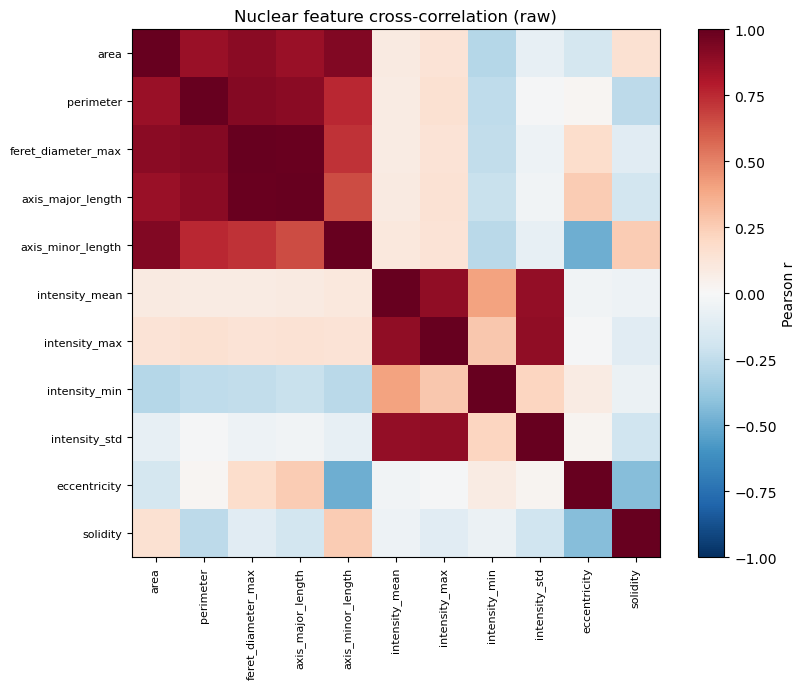

Highly correlated pairs (|r| > 0.9):
  +0.988  feret_diameter_max     axis_major_length
  +0.926  area                   axis_minor_length
  +0.919  perimeter              feret_diameter_max
  +0.905  area                   feret_diameter_max
  +0.900  perimeter              axis_major_length
[full] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full] dropped 0 rows with NaN/inf; 1036846 remain
[full] EVR: [0.396 0.314 0.159 0.11  0.016 0.005]
[full] cumulative: [0.396 0.709 0.869 0.979 0.995 1.   ]


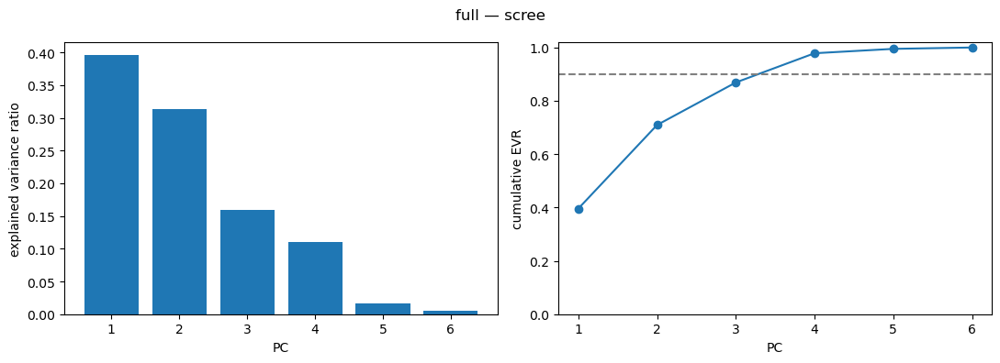

                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.201  0.059  0.961 -0.133  0.118  0.015
intensity_mean -0.082  0.698  0.081  0.152 -0.691 -0.010
intensity_std  -0.165  0.683 -0.090  0.026  0.705  0.016
eccentricity   -0.594 -0.152  0.170  0.341  0.002  0.692
solidity        0.451 -0.034  0.018  0.883  0.109 -0.060
aspect_ratio    0.608  0.137 -0.179 -0.250 -0.020  0.719


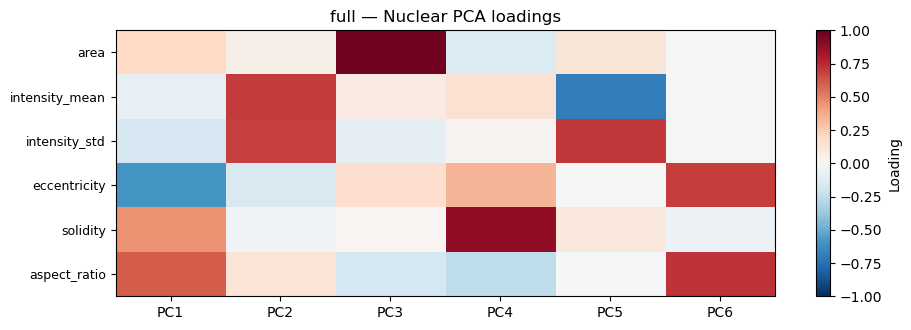

In [8]:
feature_correlation(df)
df, pca, FEATURES = fit_pca(df, label="full")

### PCA plots
Assessment of ROI level data for nucleus features

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import ListedColormap
import seaborn as sns
import glasbey


# ===========================================================================
# Palettes
# ===========================================================================
def make_palette(values, hue_bounds=(60, 500.0), chroma_bounds=(40, 130)):
    """Stable {value: color} mapping for a categorical column, derived from
    the data (not a hardcoded set). Sorted so colors are reproducible."""
    vals = sorted(pd.Series(values).dropna().unique())
    raw = glasbey.create_palette(palette_size=max(len(vals), 1),
                                 hue_bounds=hue_bounds, chroma_bounds=chroma_bounds)
    cmap = ListedColormap(raw)
    pal = {v: cmap(i) for i, v in enumerate(vals)}
    return pal


# high-cardinality fallback for genotype-like columns with no fixed mapping
_GENO_RAW = glasbey.create_palette(palette_size=64, hue_bounds=(0.0, 360.0),
                                   chroma_bounds=(40, 90))
GENO_COLORS = [ListedColormap(_GENO_RAW)(i) for i in range(64)]


def check_palette_coverage(data, col, palette):
    """Warn about values present in the data but missing from the palette."""
    present = set(data[col].dropna().unique())
    missing = present - set(palette)
    print(f"[warning] {col} values with no color: {sorted(missing)}" if missing
          else f"All {len(present)} {col} values have a color.")


# ===========================================================================
# Scatter: one PCA panel colored by a categorical column
# ===========================================================================
def pca_scatter(data, color_col, pcx="PC1", pcy="PC2", palette=None,
                s=2, alpha=0.15, figsize=(10, 7), legend_ncol=1,
                title=None, show_legend=True, shuffle=True, random_state=0):
    """PCA scatter colored by `color_col`.

    palette : optional {value: color} dict. If None, Gene_Var_Type uses the
              glasbey genotype colors and everything else falls back to husl.
    shuffle : plot rows in random order so no single group sits on top.
    """
    if shuffle:
        data = data.sample(frac=1, random_state=random_state).reset_index(drop=True)

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    vals = data[color_col].astype("object")
    cats = vals.value_counts().index.tolist()

    if palette is not None:
        colors = [palette.get(c, "#808080") for c in cats]
    elif color_col == "Gene_Var_Type":
        colors = [GENO_COLORS[i % len(GENO_COLORS)] for i in range(len(cats))]
    else:
        colors = sns.color_palette("husl", n_colors=len(cats))

    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(data.loc[m, pcx], data.loc[m, pcy], s=s, alpha=alpha,
                   color=col, linewidths=0, rasterized=True)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"PCA of {color_col}", pad=10)
    if show_legend:
        handles = [Line2D([0], [0], marker="o", linestyle="", markersize=5,
                   markerfacecolor=col, markeredgecolor=col, label=str(c))
                   for c, col in zip(cats, colors)]
        ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
                  frameon=False, fontsize=7, ncol=legend_ncol,
                  borderaxespad=0.0, handletextpad=0.4, columnspacing=0.8)
    plt.show()
    return ax


# ===========================================================================
# Centroid overlay: per-group centroids over a faint background cloud
# ===========================================================================
def centroid_overlay(data, color_col, group_keys, pcx="PC1", pcy="PC2",
                     palette=None, stat="median", bg_frac=1.0, s_centroid=60,
                     figsize=(10, 7), legend_ncol=1, title=None,
                     bg_s=1, bg_alpha=0.03):
    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.78)
    bg = data.sample(frac=bg_frac, random_state=0) if bg_frac < 1.0 else data
    ax.scatter(bg[pcx], bg[pcy], s=bg_s, alpha=bg_alpha, color="lightgray",
               linewidths=0, rasterized=True)
    agg_spec = {pcx: stat, pcy: stat}
    if color_col not in group_keys:
        agg_spec[color_col] = "first"
    cent = data.groupby(group_keys).agg(agg_spec).reset_index()
    vals = cent[color_col].astype("object")
    cats = vals.value_counts().index.tolist()
    colors = ([palette.get(c, "#808080") for c in cats] if palette
              else sns.color_palette("husl", n_colors=len(cats)))
    for c, col in zip(cats, colors):
        m = vals == c
        ax.scatter(cent.loc[m, pcx], cent.loc[m, pcy], s=s_centroid, color=col,
                   edgecolor="k", linewidths=0.5, alpha=0.9)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)
    ax.set_title(title or f"Per-group {stat} centroids ({color_col})", pad=10)
    handles = [Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=col, markeredgecolor="k", label=str(c))
               for c, col in zip(cats, colors)]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=7, ncol=legend_ncol)
    plt.show()
    return cent


# ===========================================================================
# Convenience: a standard panel set for one scored frame
# ===========================================================================
def scatter_panels(data, specs, label="Nuclei", s=2, alpha=0.15, figsize=(12, 7)):
    """Run pca_scatter for several columns in one call.

    specs : list of (column, palette_or_None). Pass a palette dict for columns
            you want stable colors on (plate, batch); None lets the function
            pick (glasbey for Gene_Var_Type, husl otherwise).
    """
    for col, pal in specs:
        pca_scatter(data, col, palette=pal, s=s, alpha=alpha, figsize=figsize,
                    legend_ncol=2 if col in ("Gene_Var_Type", "Genotype_Name") else 1,
                    title=f"{label} — {col}")


# --- usage -----------------------------------------------------------------
# build palettes once from whatever frame you're plotting:
# plate_pal = make_palette(df["iNDI_Plate_ID"])
# batch_pal = make_palette(df["Batch"])
# check_palette_coverage(df, "iNDI_Plate_ID", plate_pal)
#
# # single calls, anywhere later in the script -- no global dependencies:
# pca_scatter(df, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7),
#             title="Nuclei — iNDI_Plate_ID")
# pca_scatter(df, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2,
#             title="Nuclei — Gene_Var_Type")
#
# # or the whole standard set at once:
# scatter_panels(df, [
#     ("iNDI_Plate_ID", plate_pal),
#     ("Source",        None),
#     ("Batch",         batch_pal),
#     ("Asp PosID",     None),
#     ("Gene_Var_Type", None),
# ])
#
# centroid_overlay(df, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal,
#                  figsize=(12, 7), title="Per-experiment medians (by plate)")
# cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
# print("Std of per-experiment centroids (batch magnitude):")
# print(cent.std().round(3))

All 21 iNDI_Plate_ID values have a color.


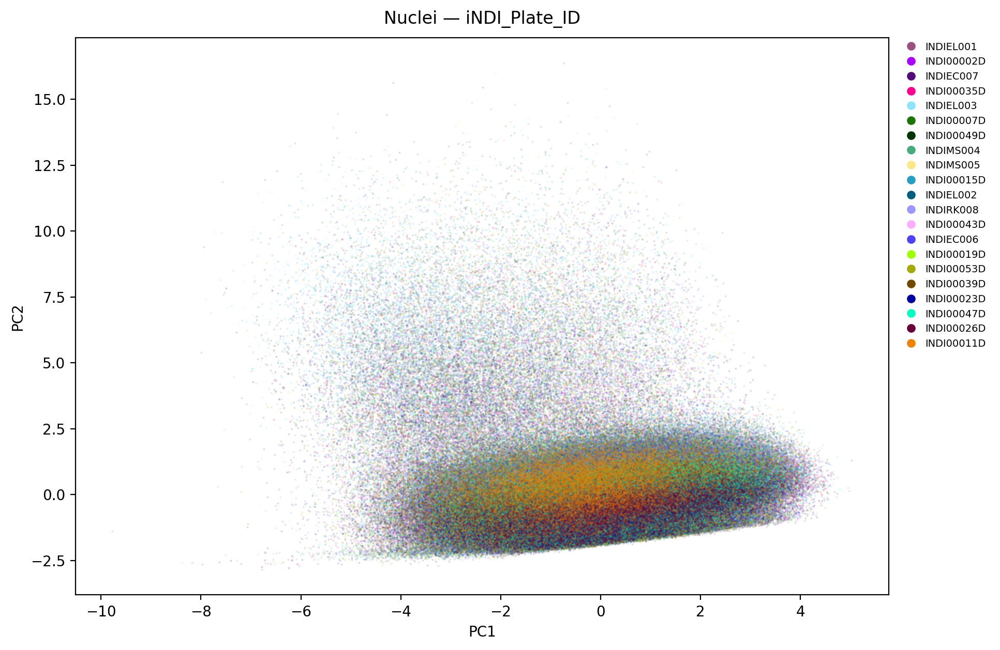

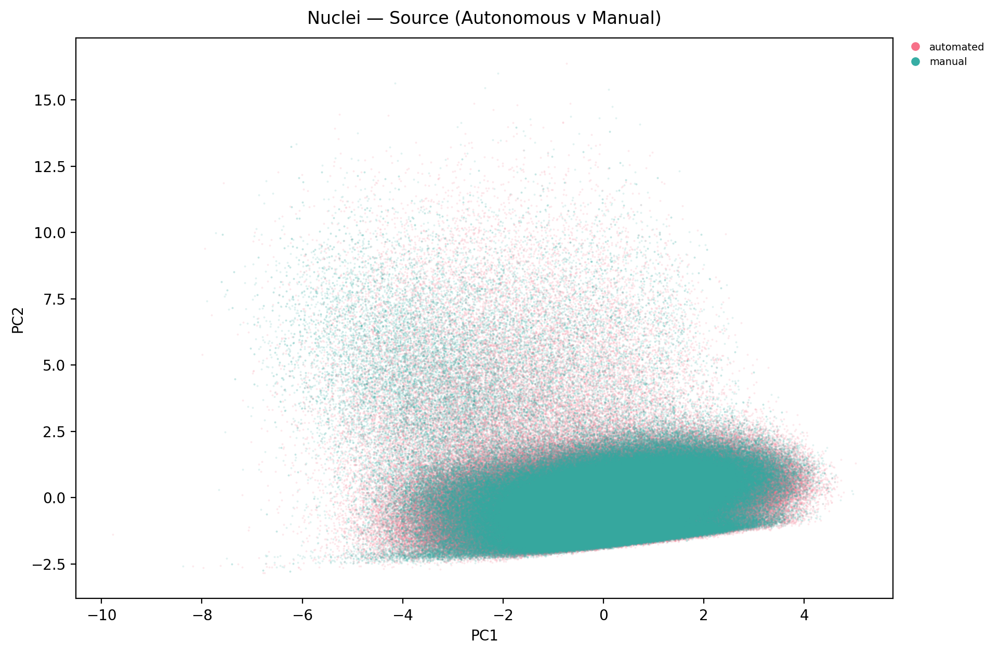

All 5 Batch values have a color.


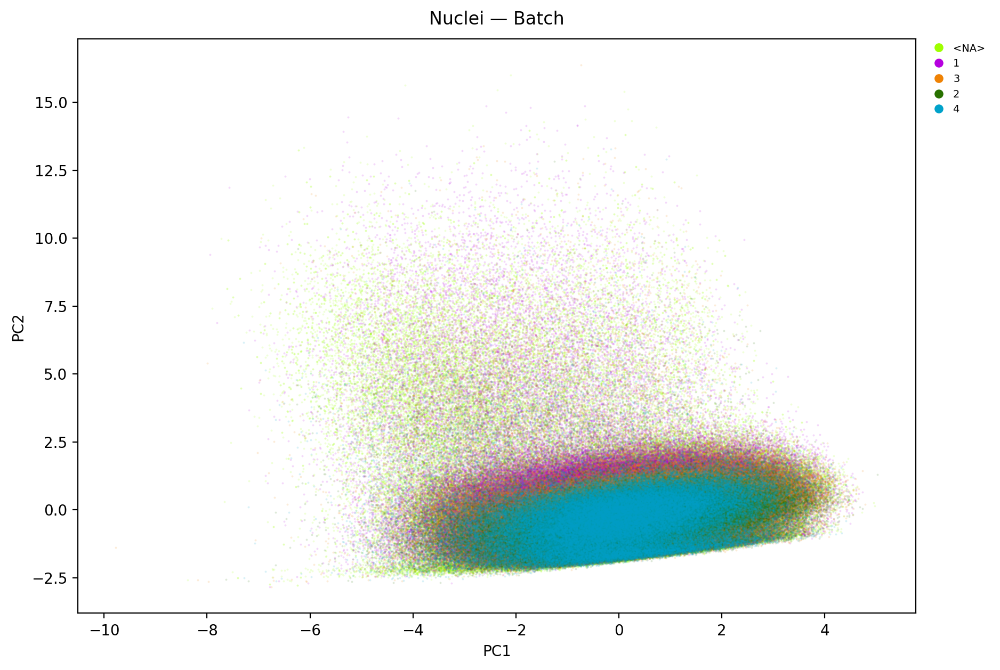

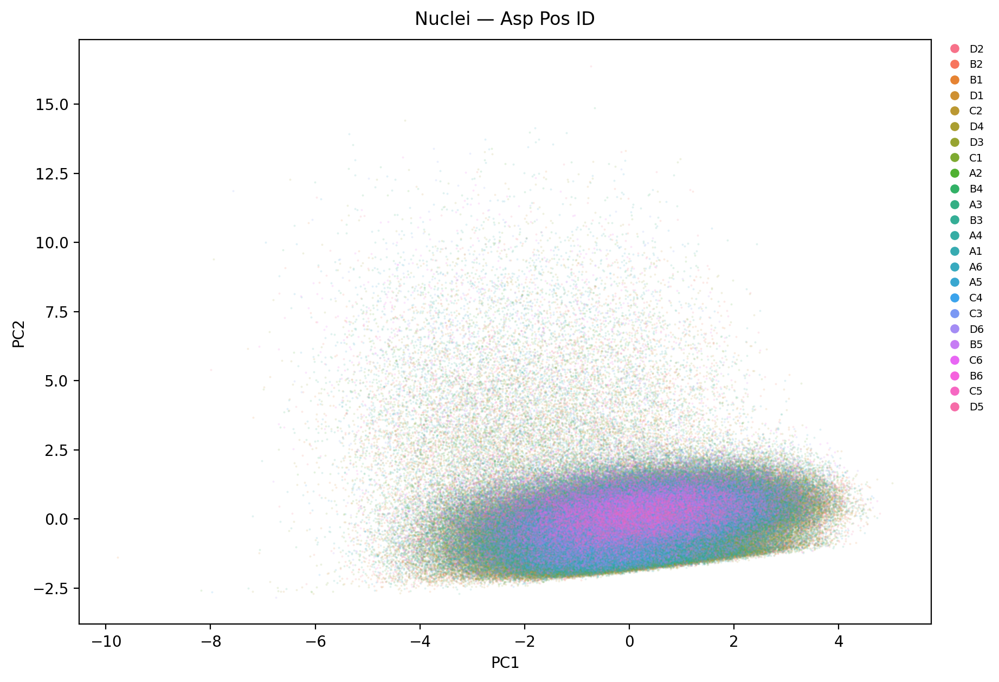

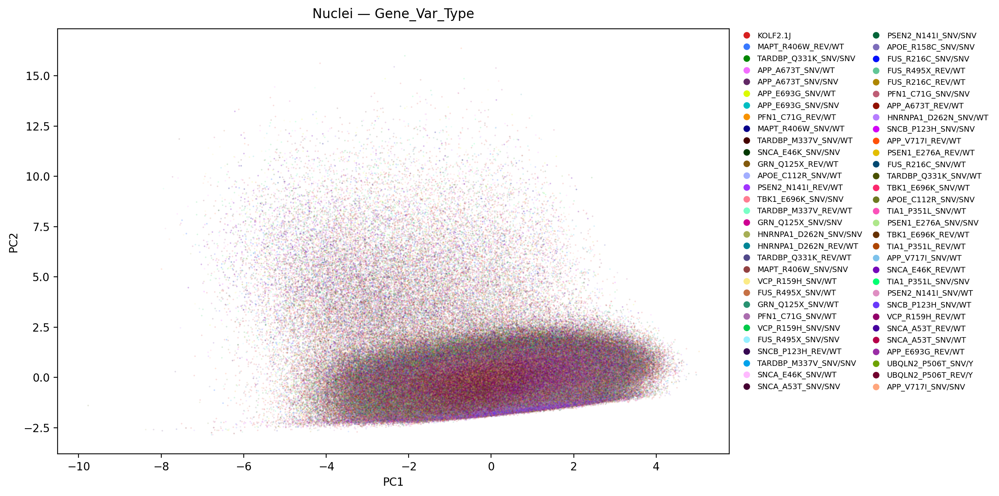

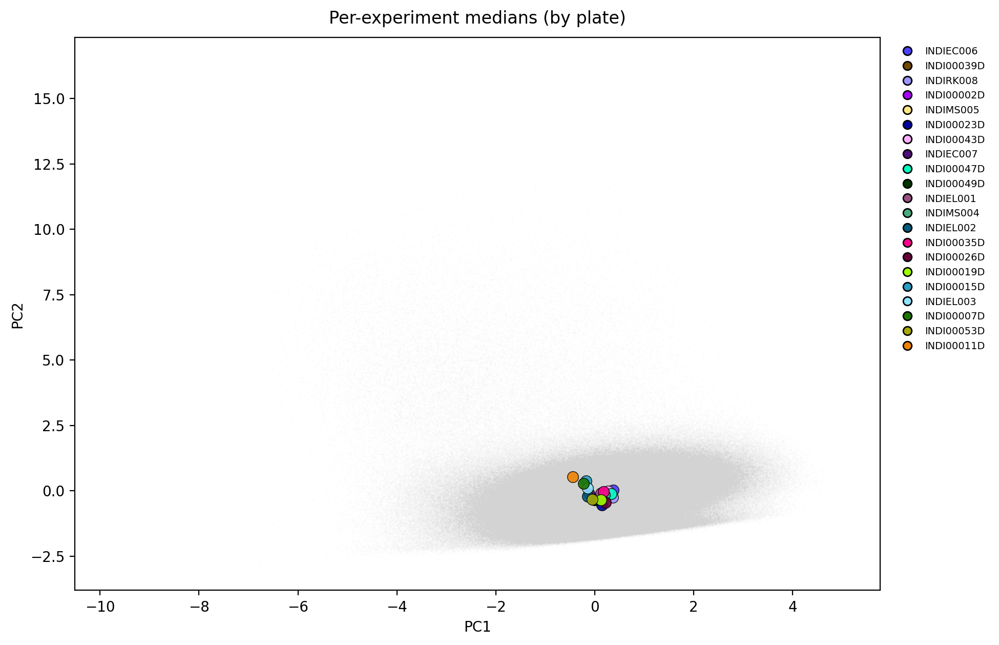

Std of per-experiment centroids (batch magnitude):
PC1    0.218
PC2    0.272
PC3    0.206
dtype: float64


In [10]:
plate_pal = make_palette(df["iNDI_Plate_ID"])
check_palette_coverage(df, "iNDI_Plate_ID", plate_pal)
pca_scatter(df, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID")

pca_scatter(df, "Source", figsize=(12, 7),title="Nuclei — Source (Autonomous v Manual)")

batch_palette = make_palette(df["Batch"])
check_palette_coverage(df, "Batch", batch_palette)
pca_scatter(df, "Batch", palette=batch_palette, figsize=(12, 7),title="Nuclei — Batch")

pca_scatter(df, "Asp PosID", figsize=(12, 7),title="Nuclei — Asp Pos ID")

pca_scatter(df, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Nuclei — Gene_Var_Type")

centroid_overlay(df, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = df.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### Variance-component analysis

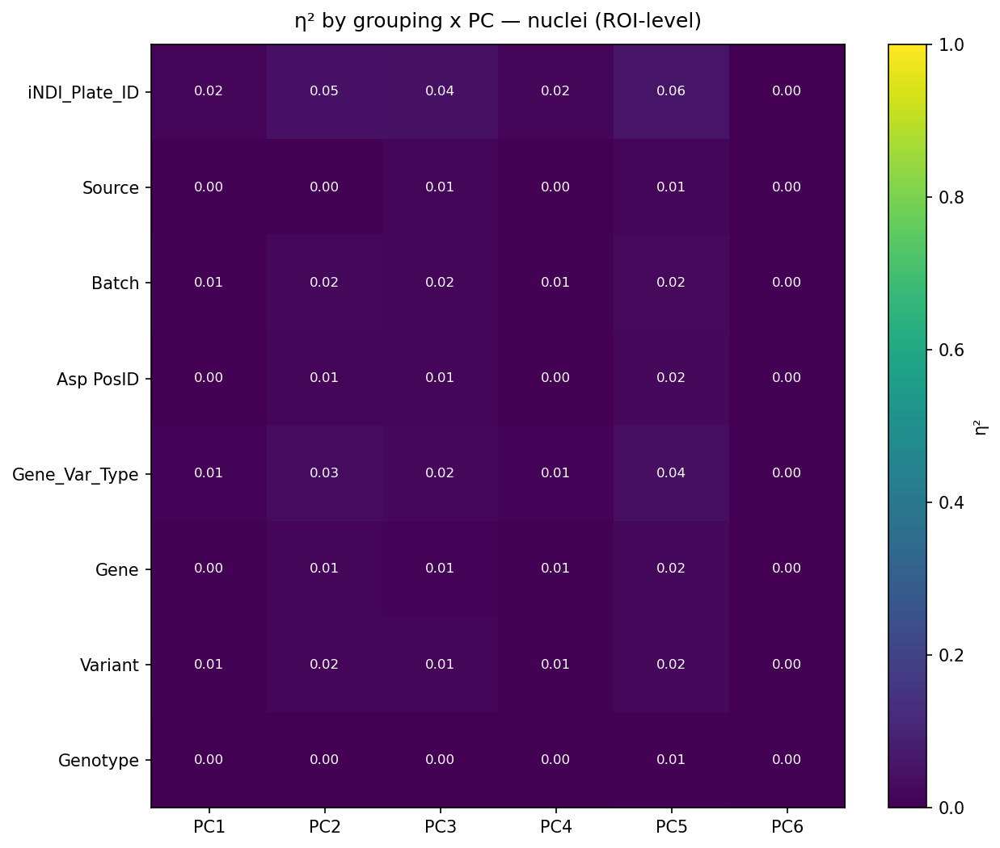

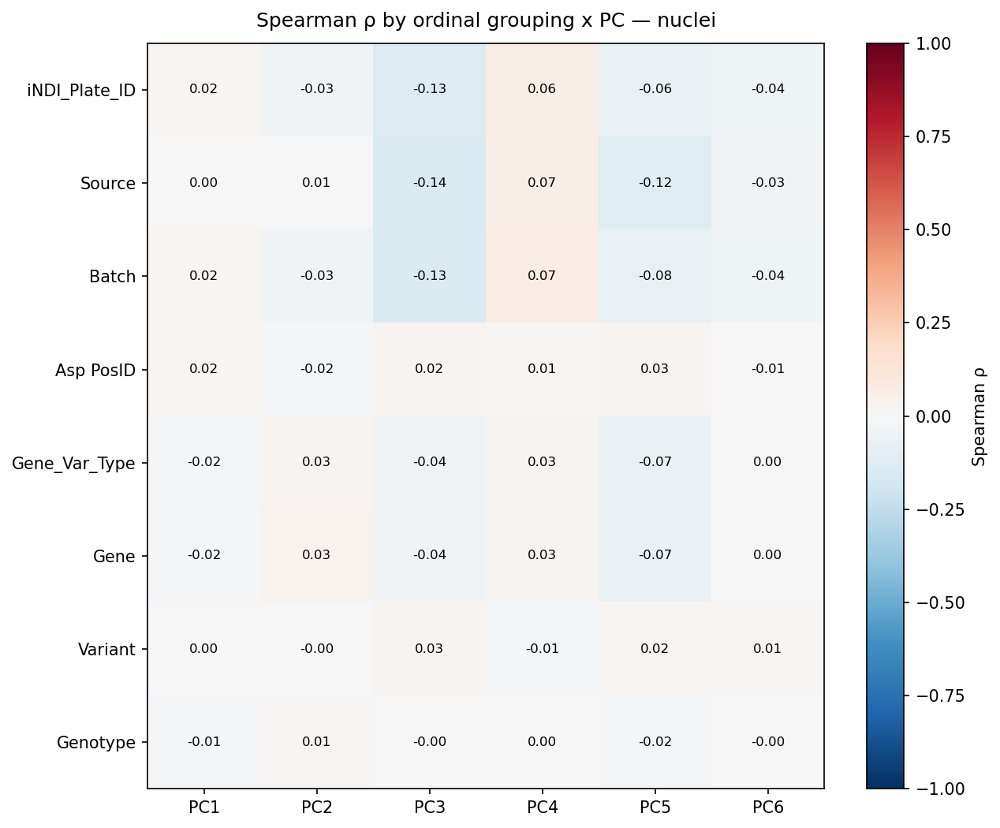

In [11]:
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:            # guard: skip empty groups
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


def eta_heatmap(data, group_cols, n_pcs=None, title="η² by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    fig, ax = plt.subplots(figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="η²")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

# Structure dropped (single channel). Batch drivers that matter for nuclei:
GROUP_COLS = ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"]
eta_full = eta_heatmap(df, GROUP_COLS, n_pcs=10, title="η² by grouping x PC — nuclei (ROI-level)")

from scipy.stats import spearmanr

def spearman_heatmap(data, group_cols, n_pcs=None,
                     title="Spearman ρ by grouping x PC", annot=True):
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))
    if n_pcs is not None:
        pc_cols = pc_cols[:n_pcs]
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)

    for gc in group_cols:
        # ordinal code: use numeric directly if numeric, else factorize
        col = data[gc]
        if pd.api.types.is_numeric_dtype(col):
            codes = col.to_numpy(dtype=float)
        else:
            codes = pd.factorize(col, sort=True)[0].astype(float)
            codes[codes < 0] = np.nan  # NaNs come back as -1
        for pc in pc_cols:
            x = data[pc].to_numpy(dtype=float)
            m = np.isfinite(x) & np.isfinite(codes)
            if m.sum() < 3:
                mat.loc[gc, pc] = np.nan
                continue
            rho, _ = spearmanr(x[m], codes[m])
            mat.loc[gc, pc] = rho

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(group_cols) + 1.5), dpi=150)
    # diverging map + symmetric limits since ρ ∈ [-1, 1]
    im = ax.imshow(mat.values.astype(float), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(group_cols))); ax.set_yticklabels(group_cols)
    plt.colorbar(im, ax=ax, label="Spearman ρ")
    ax.set_title(title, pad=10)
    if annot:
        for i in range(len(group_cols)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if abs(v) > 0.5 else "black", fontsize=8)
    plt.tight_layout(); plt.show()
    return mat

ORDINAL_COLS = ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"]
spear = spearman_heatmap(df, ORDINAL_COLS, n_pcs=10,
                         title="Spearman ρ by ordinal grouping x PC — nuclei")

[facet] 22 (gene, variant) pairs; 236480 total KOLF2.1J rows (all folded into each facet)
  APOE / C112R: 25969 variant + 236480 parental rows


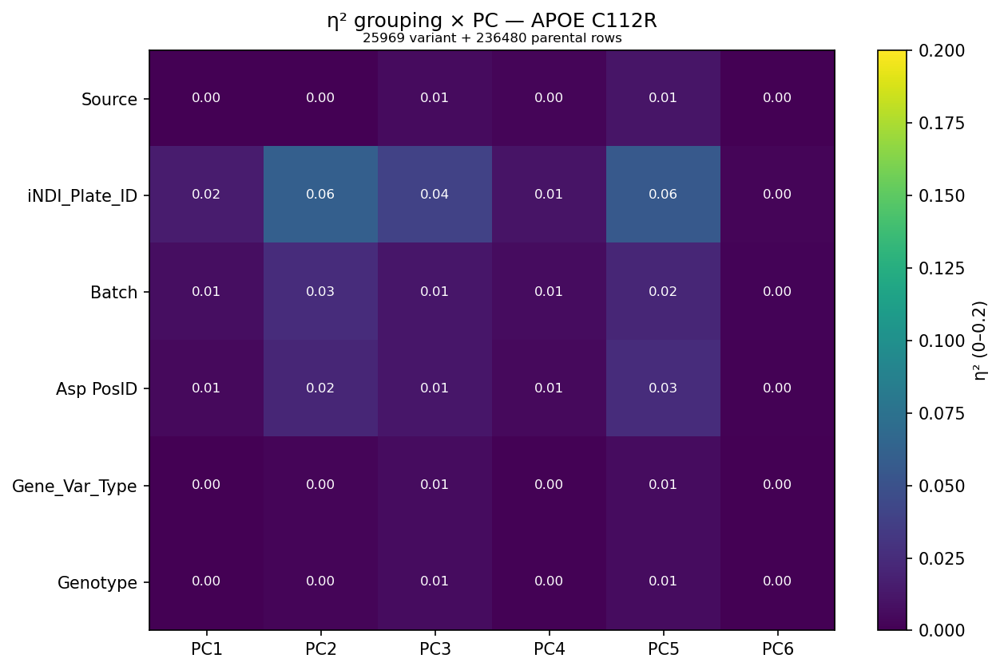

  APOE / R158C: 12704 variant + 236480 parental rows


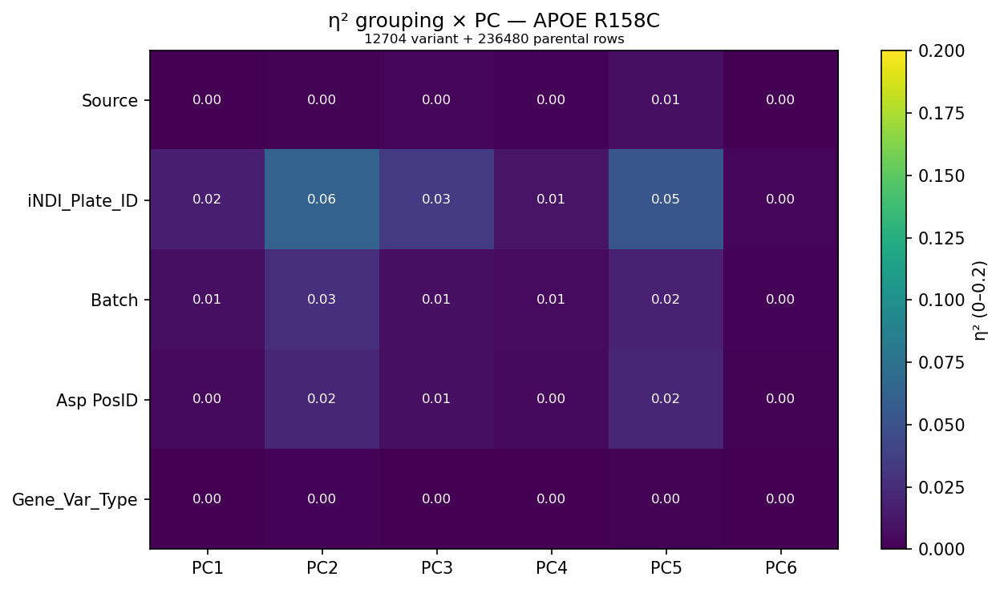

  APP / A673T: 51426 variant + 236480 parental rows


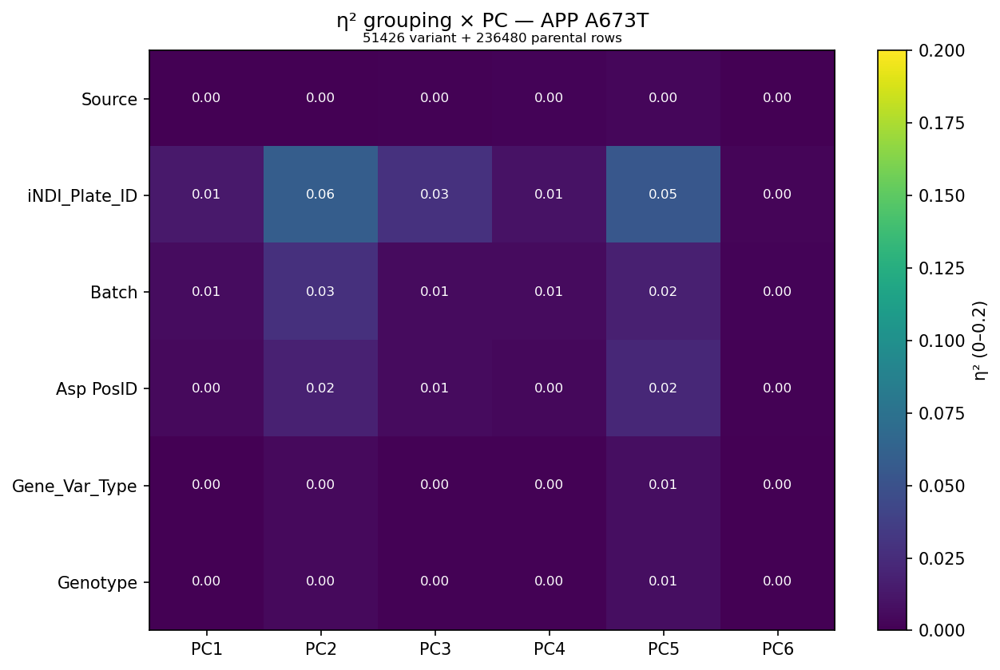

  APP / E693G: 44303 variant + 236480 parental rows


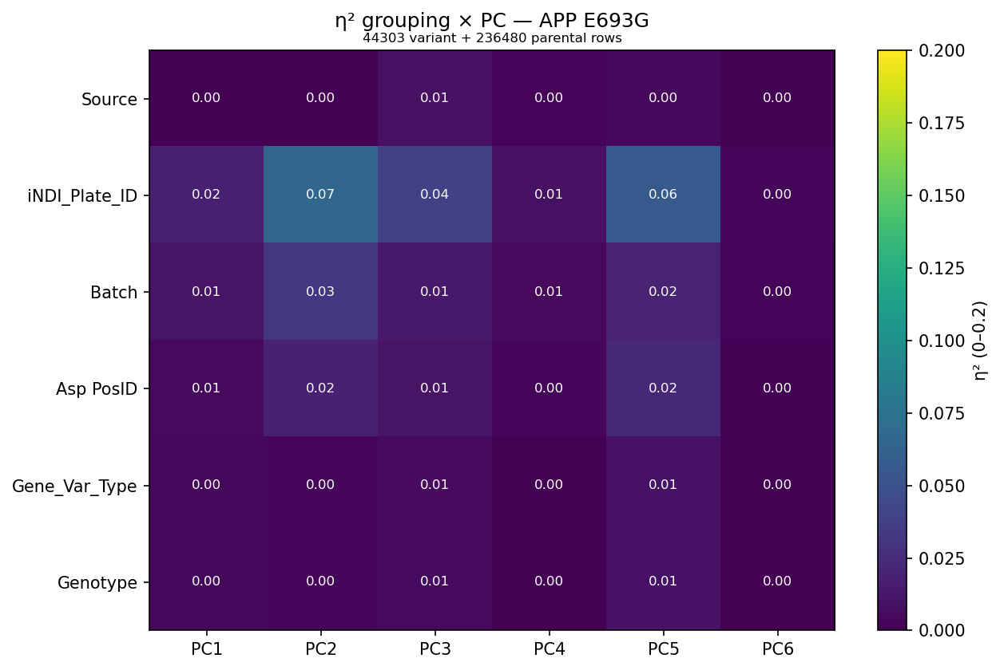

  APP / V717I: 23766 variant + 236480 parental rows


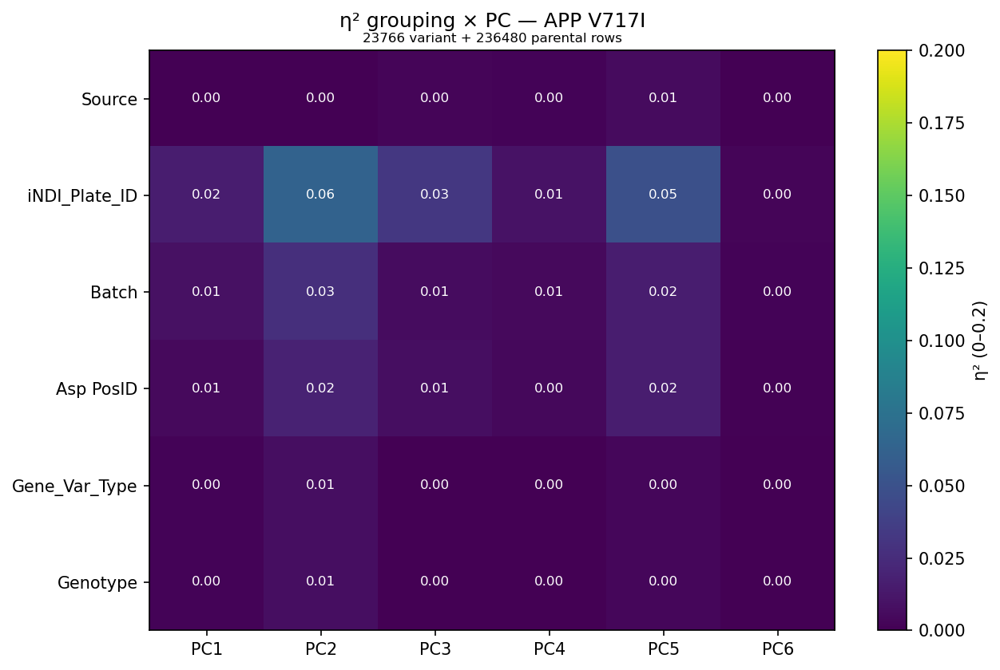

  FUS / R216C: 34615 variant + 236480 parental rows


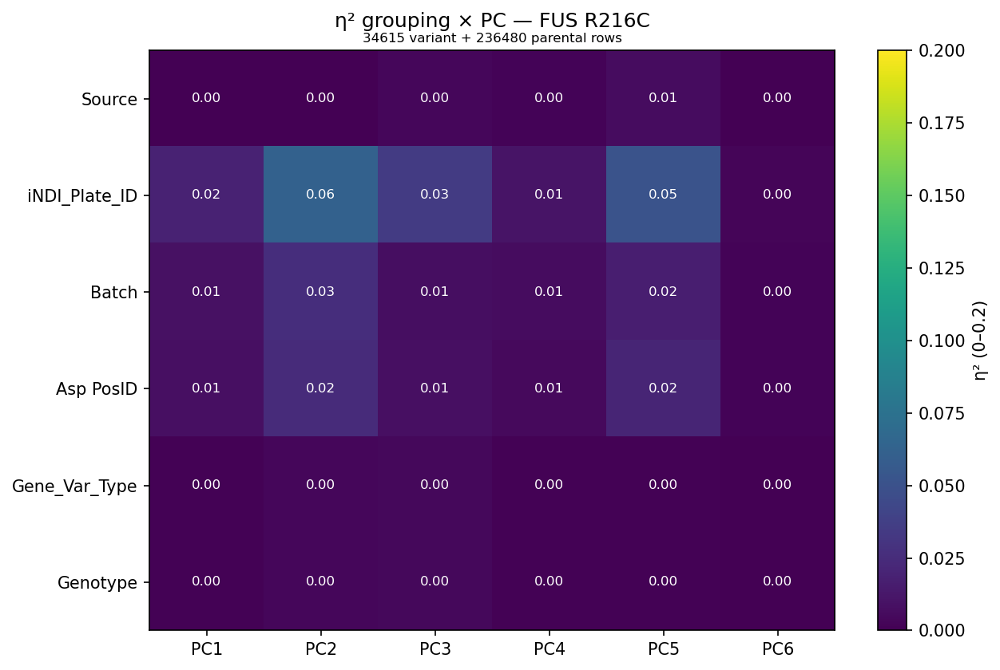

  FUS / R495X: 40673 variant + 236480 parental rows


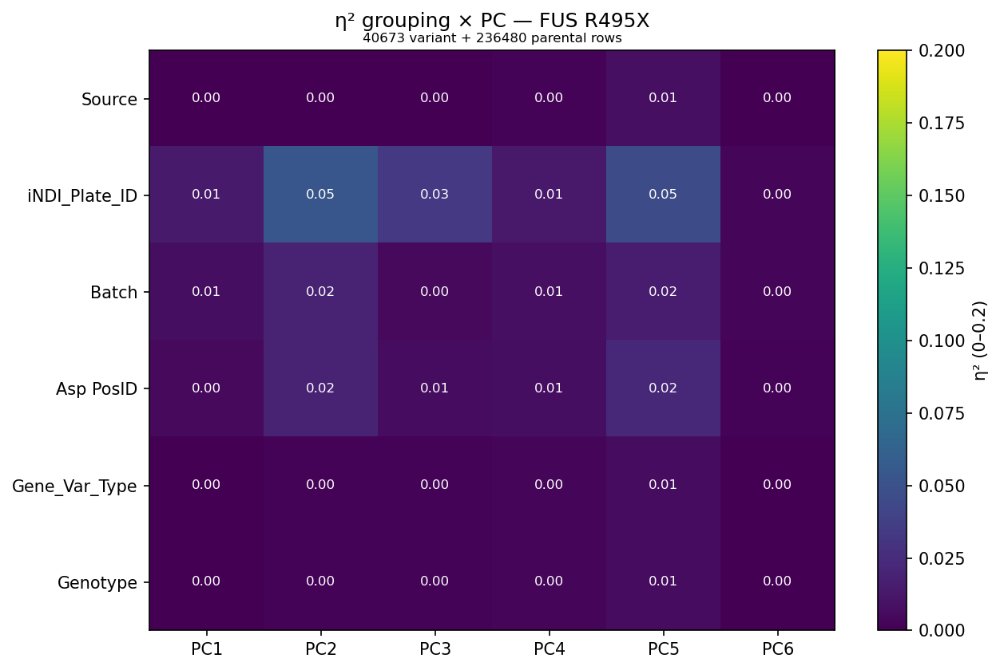

  GRN / Q125X: 47223 variant + 236480 parental rows


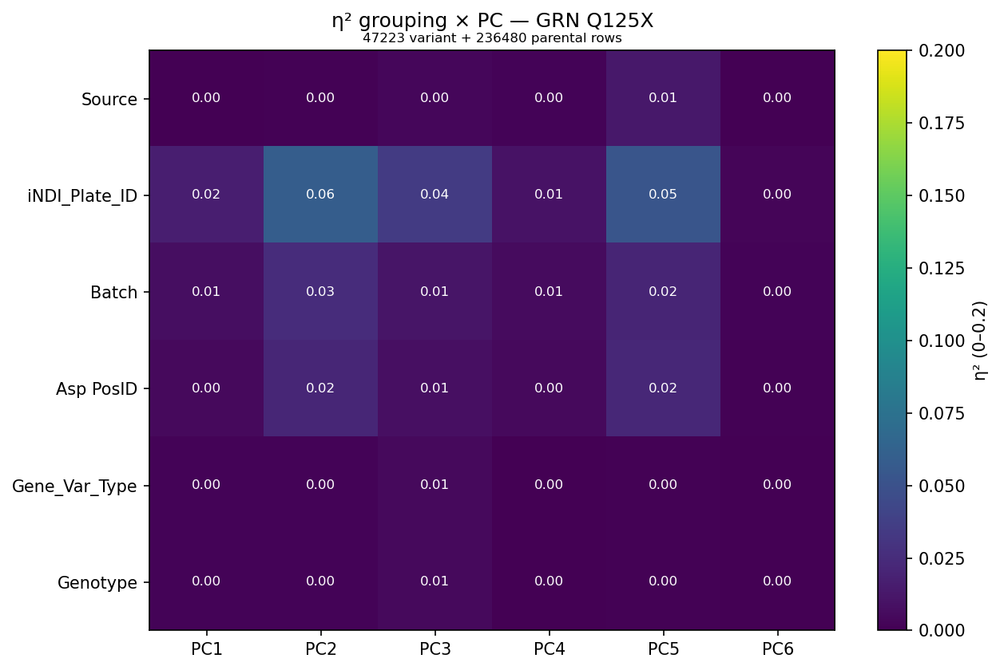

  HNRNPA1 / D262N: 42571 variant + 236480 parental rows


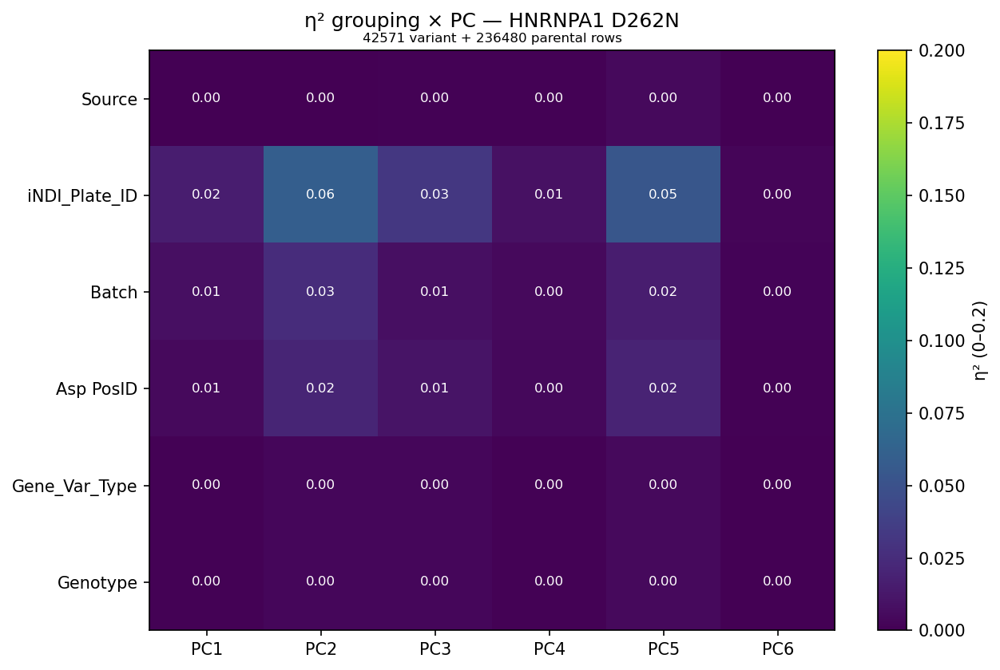

  MAPT / R406W: 59873 variant + 236480 parental rows


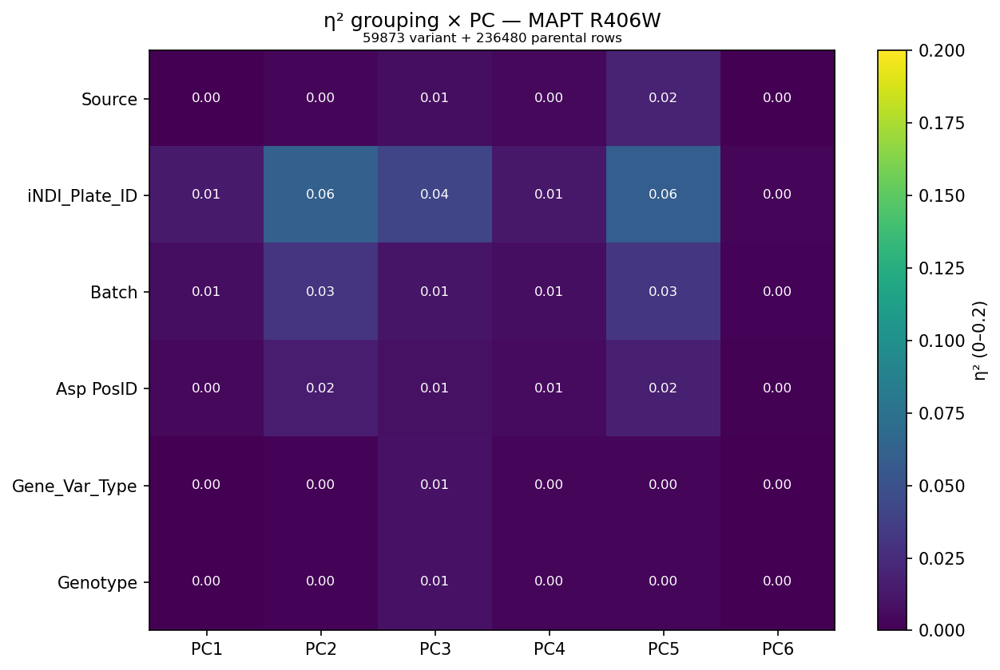

  PFN1 / C71G: 44388 variant + 236480 parental rows


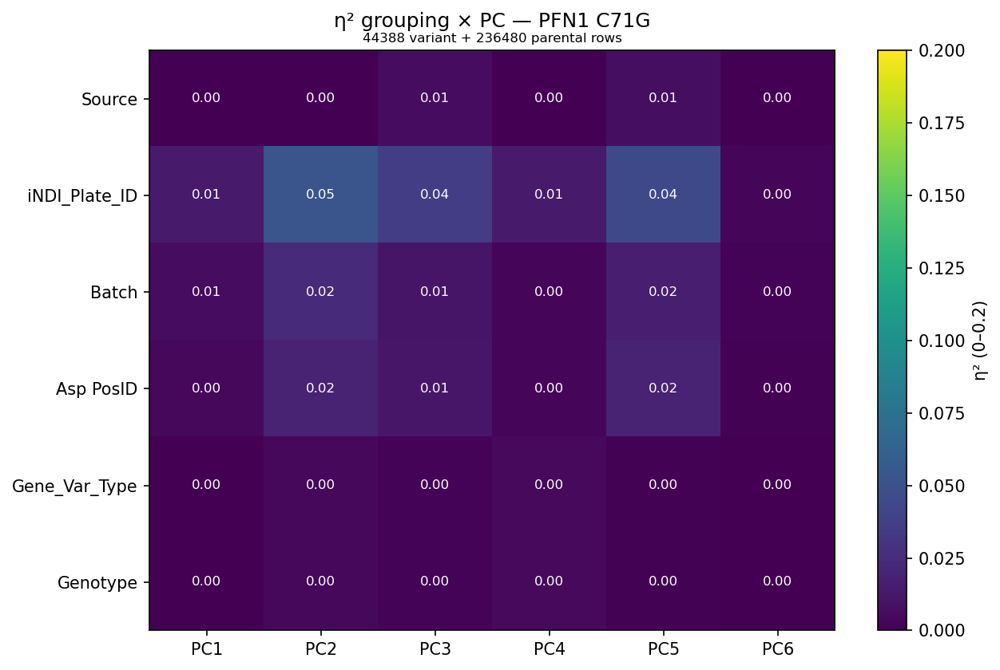

  PSEN1 / E276A: 19414 variant + 236480 parental rows


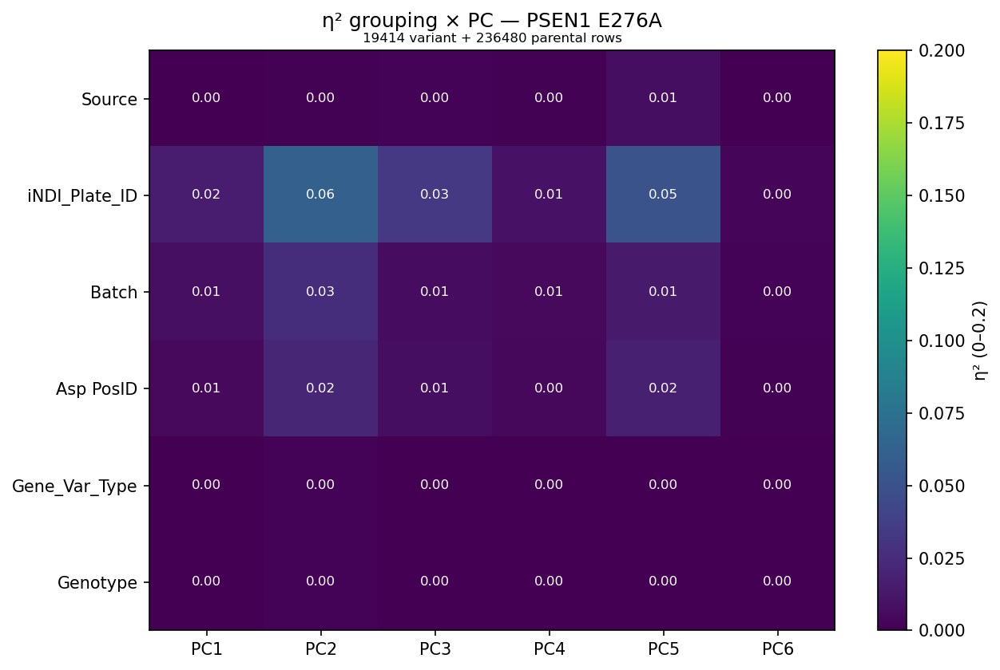

  PSEN2 / N141I: 37153 variant + 236480 parental rows


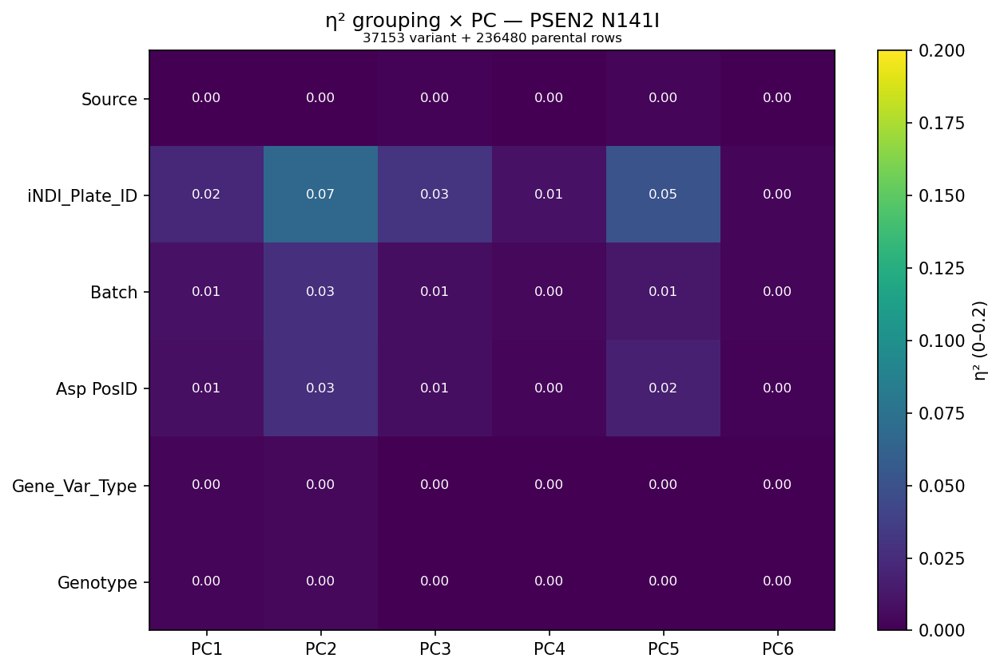

  SNCA / A53T: 27792 variant + 236480 parental rows


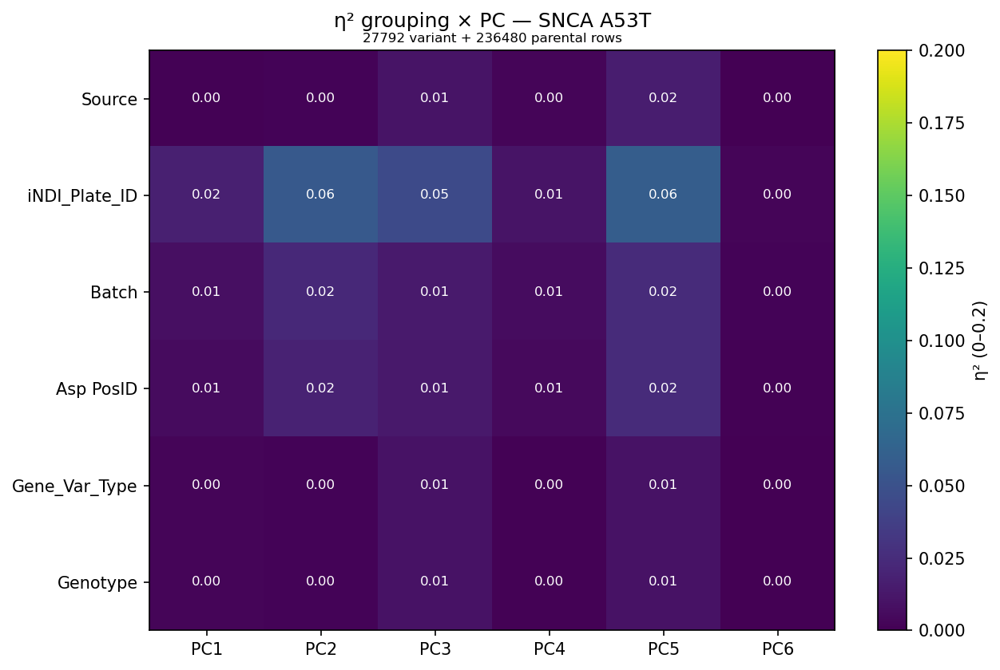

  SNCA / E46K: 39005 variant + 236480 parental rows


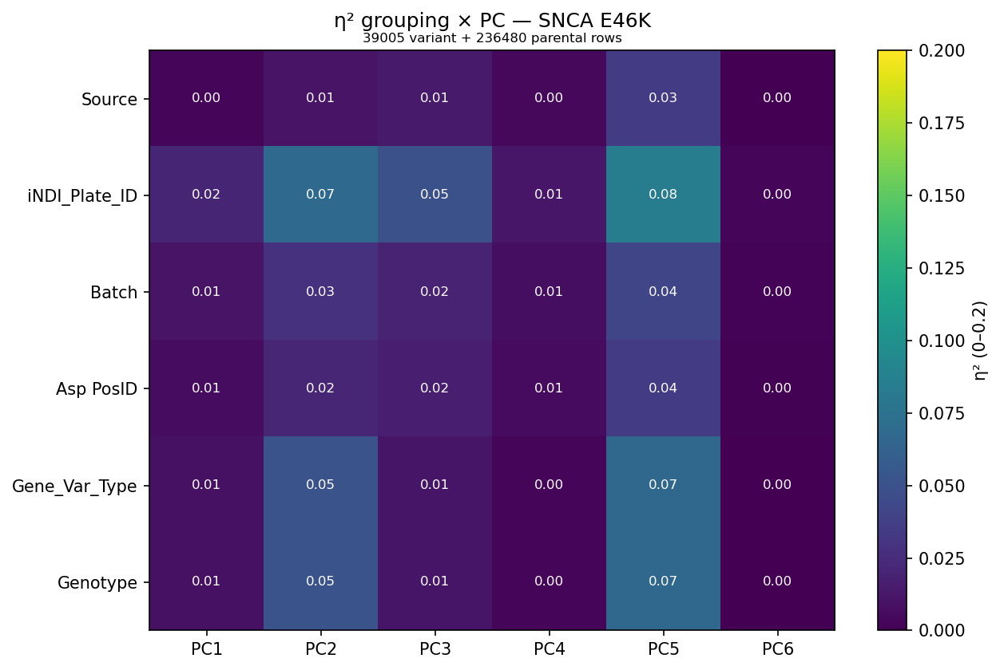

  SNCB / P123H: 32087 variant + 236480 parental rows


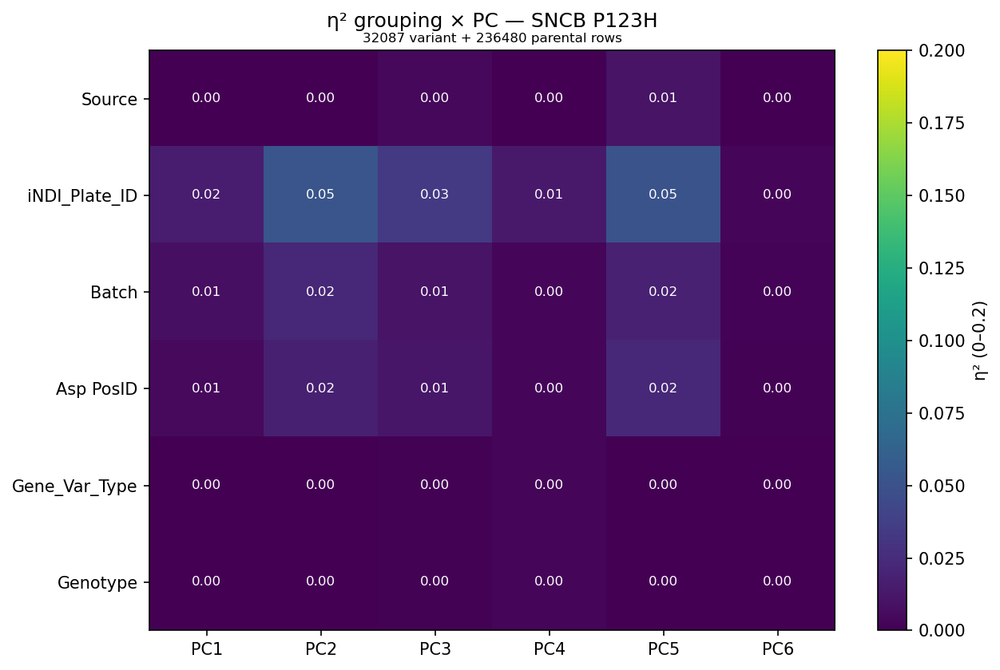

  TARDBP / M337V: 47465 variant + 236480 parental rows


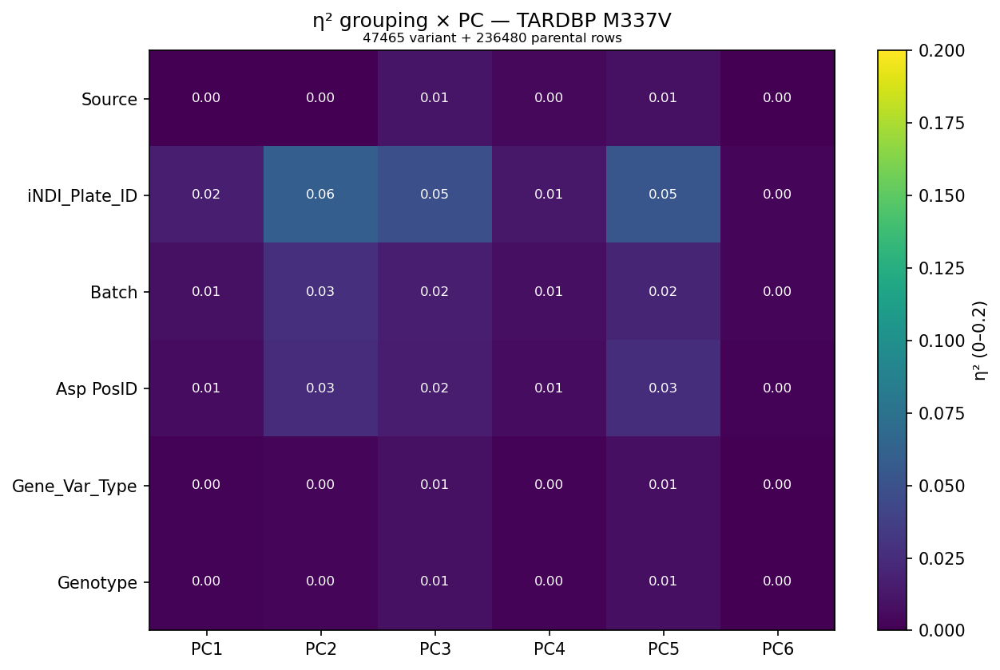

  TARDBP / Q331K: 50965 variant + 236480 parental rows


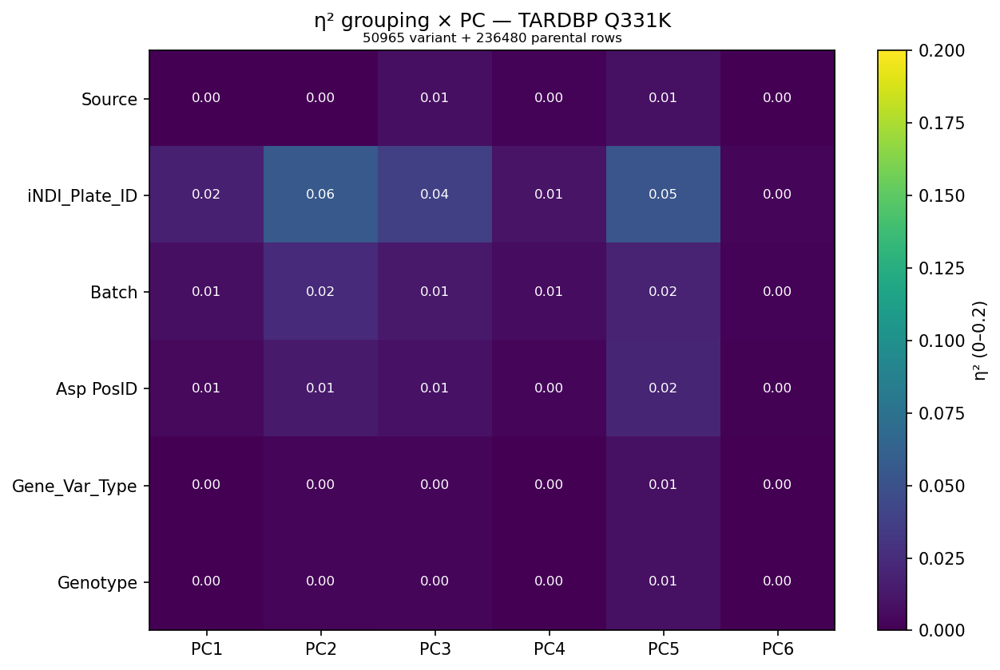

  TBK1 / E696K: 35114 variant + 236480 parental rows


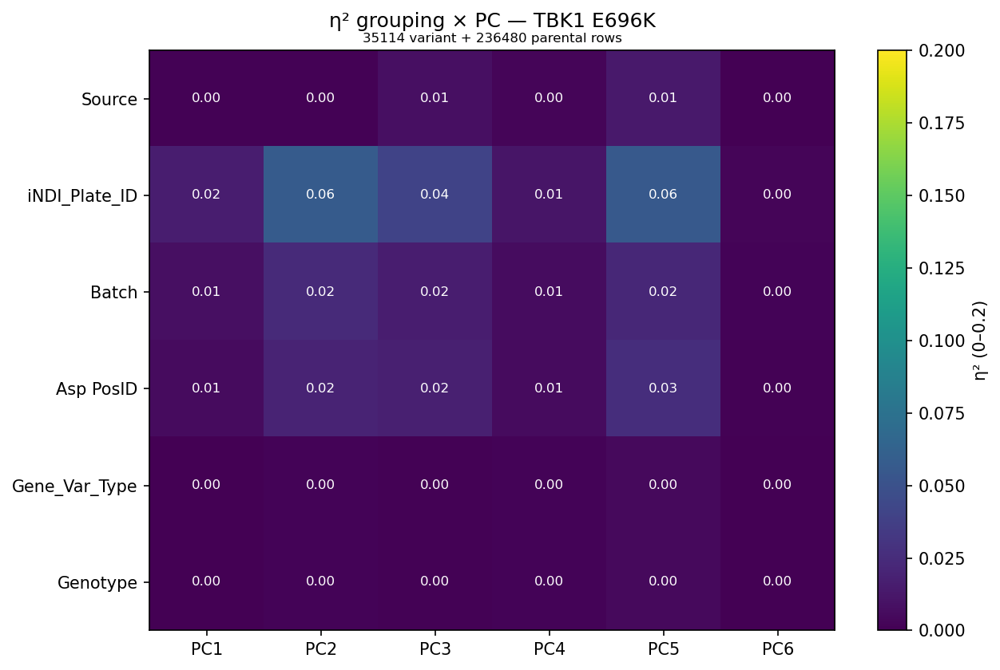

  TIA1 / P351L: 26064 variant + 236480 parental rows


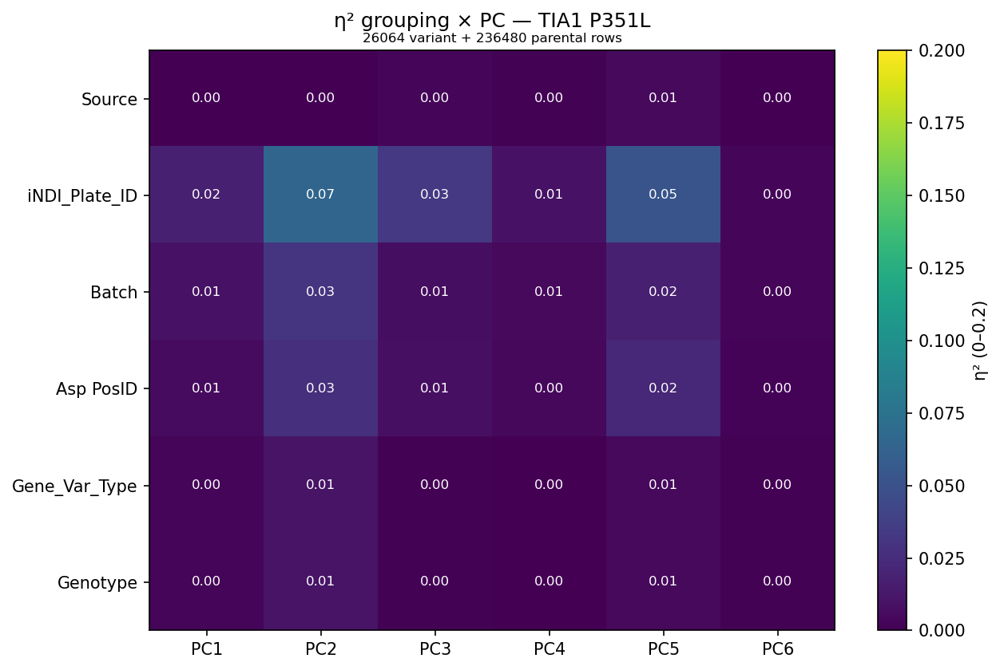

  UBQLN2 / P506T: 12836 variant + 236480 parental rows


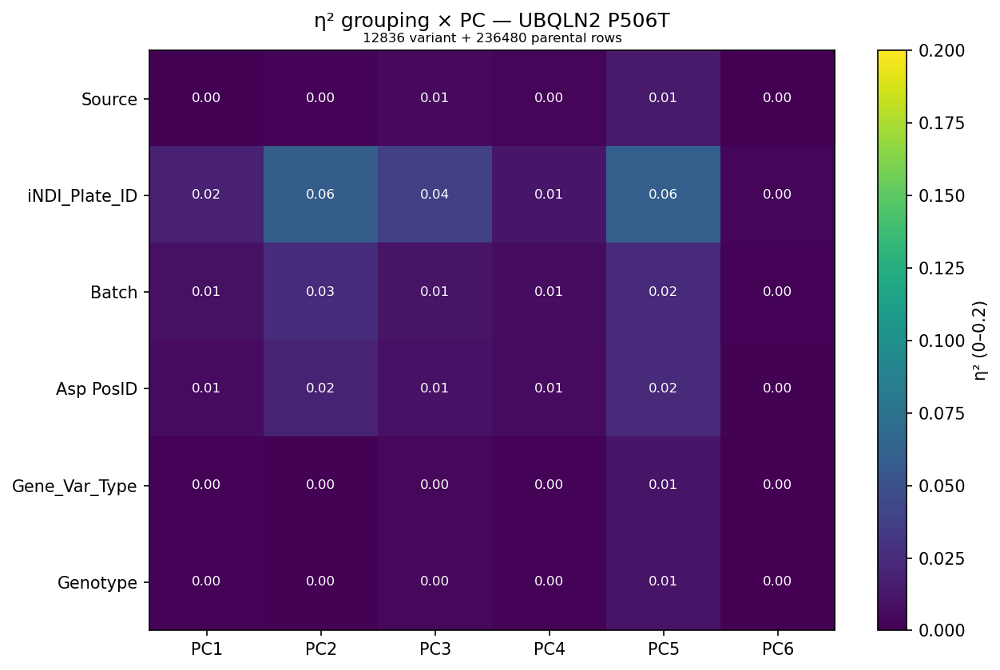

  VCP / R159H: 36670 variant + 236480 parental rows


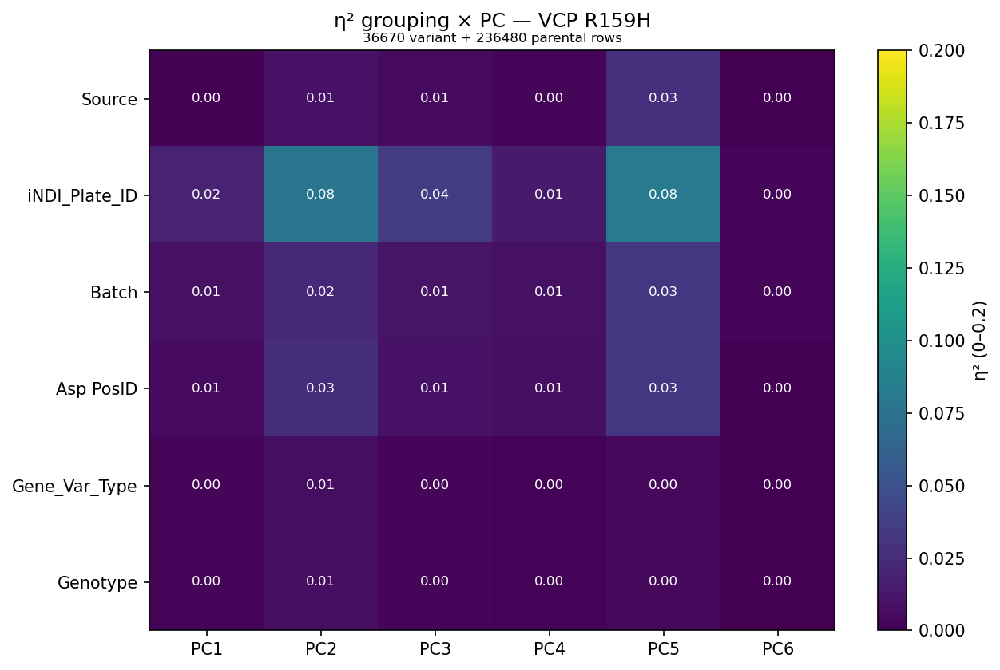

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- eta_squared ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene-variant: ONE SEPARATE FIGURE per facet -----------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, variant, vmax=0.2,
                      annot=True, drop_constant=True, subtitle=None):
    """Draw a single grouping x PC η² heatmap for one facet's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} {variant}", pad=14)
    if subtitle:
        ax.text(0.5, 1.01, subtitle, transform=ax.transAxes,
                ha="center", va="bottom", fontsize=8)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene_variant(data, group_cols, n_pcs=10,
                          gene_col="Gene", variant_col="Variant", vmax=0.2,
                          annot=True, include_wt=True, drop_constant=True,
                          plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per (gene, variant) pair. Each facet's
    subset is that single variant's rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that variant actually occupies, removing the plate confound.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]

    # unique (gene, variant) pairs among edited rows
    pairs = (edited[[gene_col, variant_col]]
             .dropna()
             .drop_duplicates()
             .sort_values([gene_col, variant_col])
             .itertuples(index=False, name=None))
    pairs = list(pairs)

    print(f"[facet] {len(pairs)} (gene, variant) pairs; "
          f"{len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    # gene and variant are constant within a facet, so never use them as rows
    facet_groups = [g for g in group_cols
                    if g not in (gene_col, variant_col)]

    mats = {}
    for gene, variant in pairs:
        var_rows = edited[(edited[gene_col] == gene)
                          & (edited[variant_col] == variant)]
        if var_rows.empty:
            continue

        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                var_plates = set(var_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(var_plates)]
            plate_note = (f" on {len(set(var_rows[plate_col].dropna().unique()))} plate(s)"
                          if plate_match else "")
            subtitle = (f"{len(var_rows)} variant + {len(wt_use)} parental rows"
                        f"{plate_note}")
            sub = pd.concat([var_rows, wt_use], ignore_index=True)
            print(f"  {gene} / {variant}: {subtitle}")
        else:
            subtitle = f"{len(var_rows)} variant rows"
            sub = var_rows
            print(f"  {gene} / {variant}: {subtitle}")

        mats[(gene, variant)] = plot_gene_heatmap(
            sub, facet_groups, pc_cols, gene, variant,
            vmax=vmax, annot=annot, drop_constant=drop_constant,
            subtitle=subtitle)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

# recommended: aggregate to wells first (adjust well_keys to your schema)
# pc_cols = sorted([c for c in df.columns if c.startswith("PC")], key=lambda s: int(s[2:]))[:10]
# well_df = aggregate_to_wells(
#     df,
#     well_keys=["iNDI_Plate_ID", "Row", "Column"],
#     carry_cols=GROUP_COLS + ["Gene"],
#     pc_cols=pc_cols,
# )
# facet_by_gene_variant(well_df, GROUP_COLS, n_pcs=10, vmax=0.2)

# or straight on ROI-level df (noisier):
mats = facet_by_gene_variant(df, GROUP_COLS, n_pcs=10, vmax=0.2)

## Well-level aggregation
### PCA plots

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 194186 rows (13440 images)
[full] well-level: 5937 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 5937 remain
[full well] EVR: [0.46  0.278 0.136 0.093 0.031 0.003]
[full well] cumulative: [0.46  0.737 0.873 0.966 0.997 1.   ]


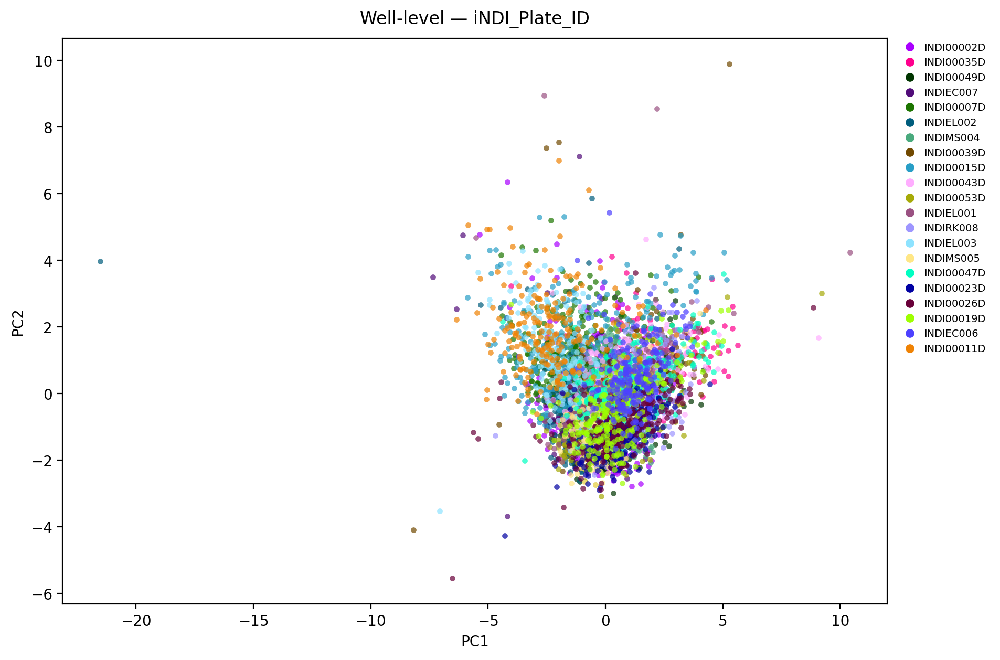

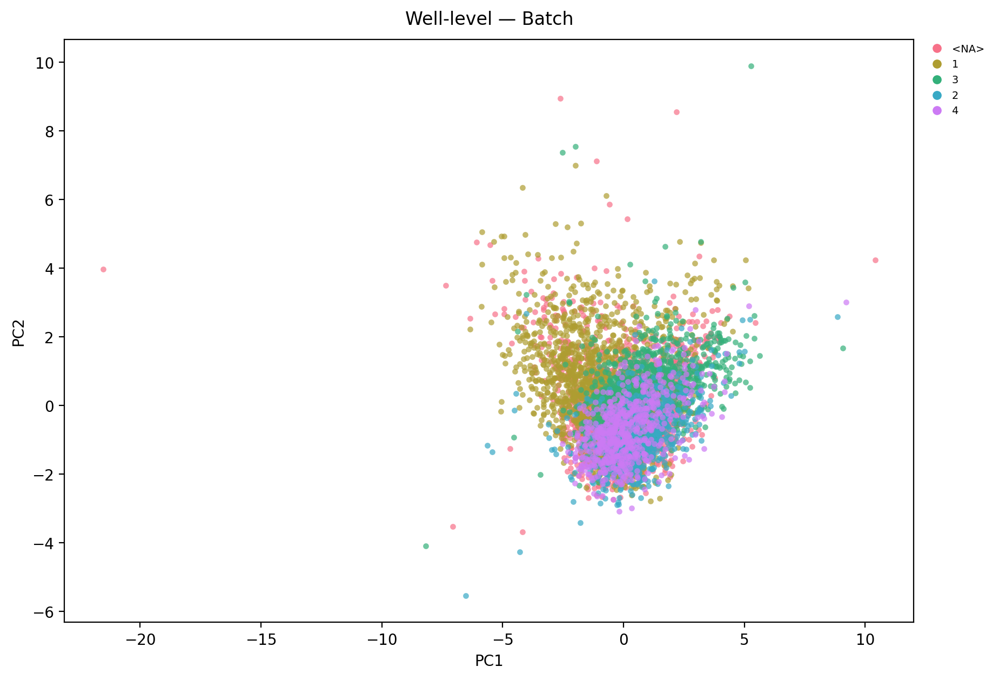

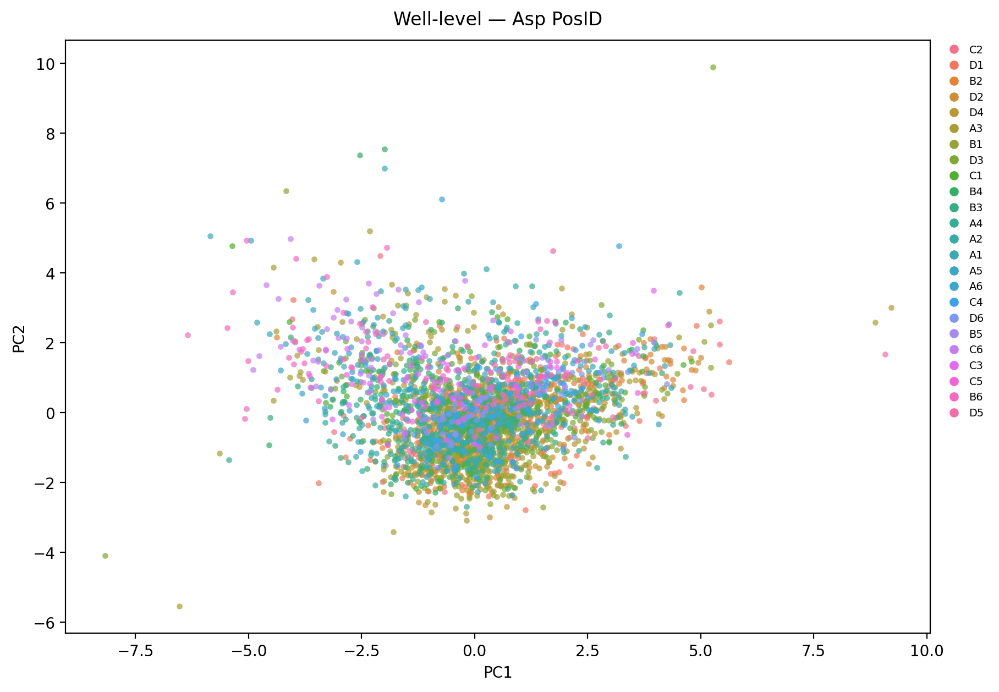

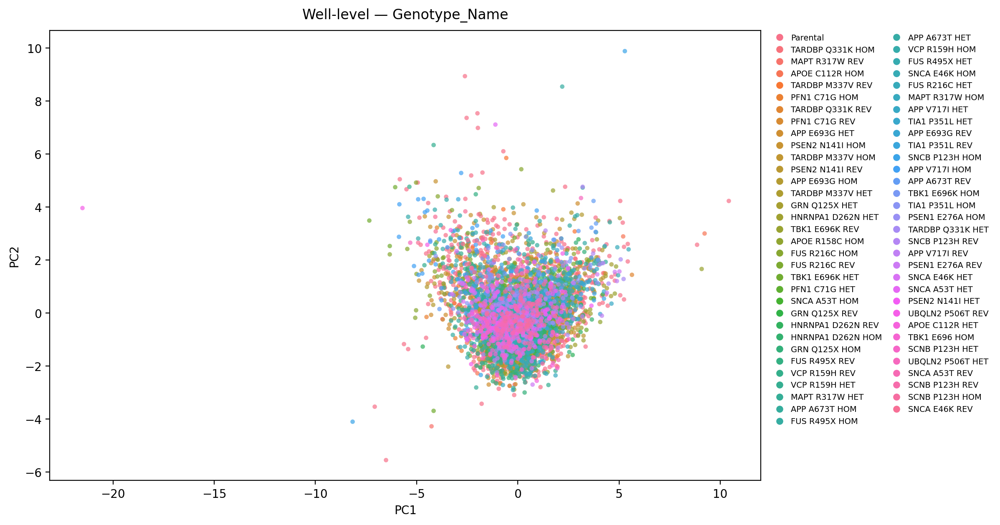

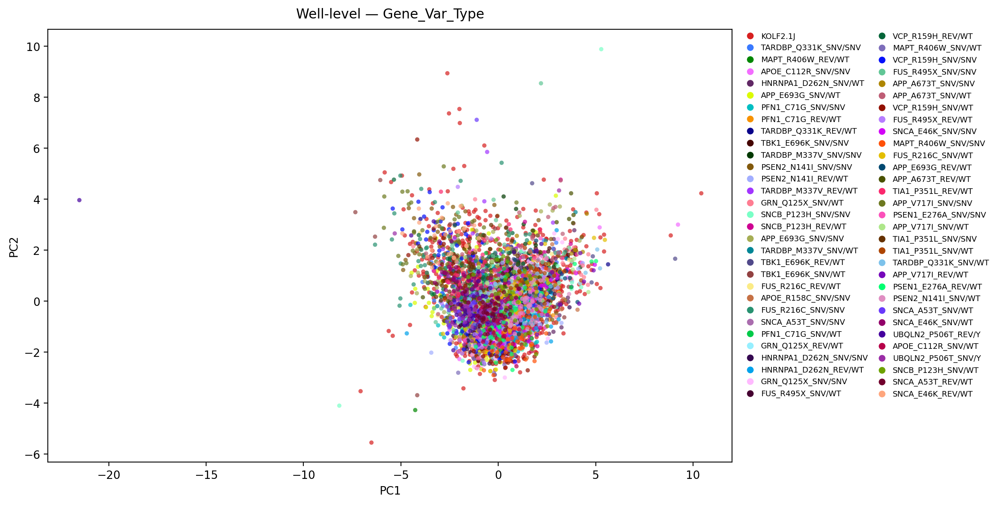

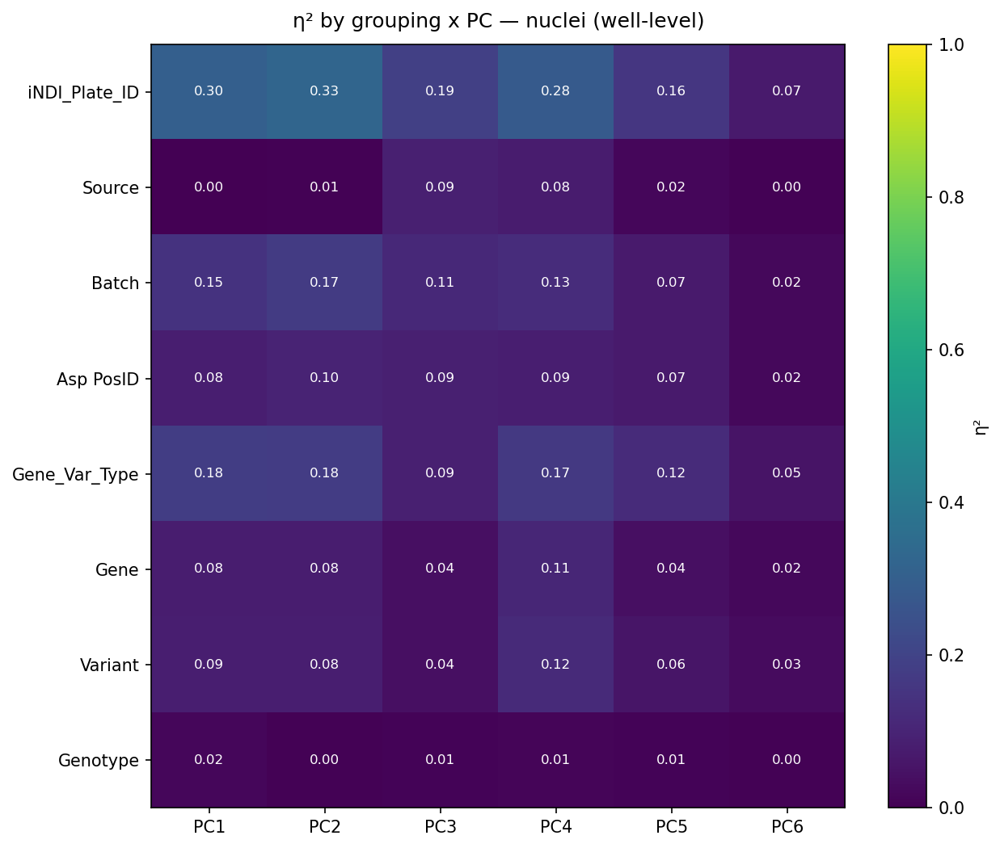

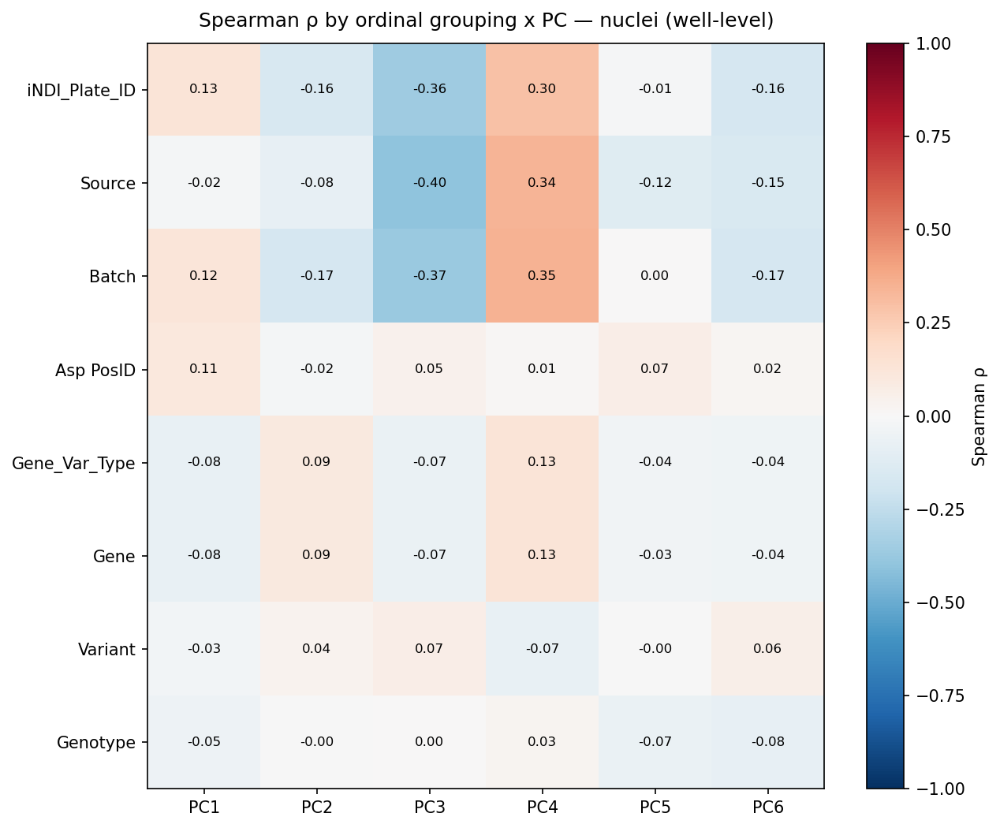

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.129659,-0.156485,-0.358248,0.296217,-0.009522,-0.164868
Source,-0.017663,-0.082604,-0.400103,0.341433,-0.121091,-0.149000
Batch,0.117922,-0.168380,-0.372288,0.346281,0.003917,-0.166944
Asp PosID,0.106401,-0.020317,0.046243,0.011984,0.067609,0.018748
Gene_Var_Type,-0.077884,0.094482,-0.065219,0.128238,-0.038657,-0.040013
Gene,-0.076768,0.094046,-0.066904,0.132367,-0.033860,-0.040197
Variant,-0.030912,0.037338,0.069464,-0.073822,-0.004240,0.056254
Genotype,-0.054228,-0.001413,0.000171,0.027272,-0.065664,-0.078714


In [13]:
import numpy as np
import pandas as pd

# well = Measurement_ID + subdirectory; image = image_name
WELL_KEYS = ["Measurement_ID", "subdirectory"]
IMAGE_KEY = "image_name"


def aggregate_wells(data, features, well_keys=WELL_KEYS, image_key=IMAGE_KEY,
                    check_cols=("Genotype_Name", "iNDI_Plate_ID", "prep_method"),
                    label="", image_stat="median", well_stat="mean",
                    n_pc_drop=20):
    """Collapse nuclei -> image -> well.

    stage 1: `image_stat` across nuclei within each image
    stage 2: `well_stat` across images within each well

    Metadata columns (everything that isn't a feature, PC, or key) are carried
    through with .first(), after a safety check that they're invariant within a
    well. Returns the well-level dataframe (NOT PCA-scored -- run fit_pca next).
    """
    features = [f for f in features if f in data.columns]
    group_keys = [*well_keys, image_key]
    drop_cols = (set(features) | {f"PC{i+1}" for i in range(n_pc_drop)}
                 | set(group_keys) | {"label", "filename", "filepath"})
    meta_cols = [c for c in data.columns if c not in drop_cols]

    # safety: metadata carried by .first() should be invariant within a well
    for col in check_cols:
        if col in data.columns:
            n_bad = (data.groupby(well_keys)[col].nunique() > 1).sum()
            print(f"[{label}] {col}: {n_bad} well(s) with >1 value"
                  f"{'  <-- CHECK' if n_bad else ''}")

    # stage 1: within-image summary across nuclei
    agg_image = {**{f: image_stat for f in features},
                 **{m: "first" for m in meta_cols}}
    image_level = data.groupby(group_keys, as_index=False).agg(agg_image)
    print(f"[{label}] image-level: {len(image_level)} rows "
          f"({data[image_key].nunique()} images)")

    # stage 2: within-well summary across images
    agg_well = {**{f: well_stat for f in features},
                **{m: "first" for m in meta_cols}}
    well_level = image_level.groupby(well_keys, as_index=False).agg(agg_well)
    print(f"[{label}] well-level: {len(well_level)} rows")

    return well_level


# --- usage -----------------------------------------------------------------
# aggregate, then reuse the SAME fit_pca from the feature section (don't
# re-implement the scale/PCA/score here):
#
# well_level = aggregate_wells(df, FEATURES, label="full")
# well_level, pca_well, _ = fit_pca(
#     well_level, features=FEATURES, add_aspect_ratio=False,
#     show_scree=False, show_loadings=False, label="full well",
# )


well_level = aggregate_wells(df, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)
well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Source", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

### Variance-component analysis
This is built to handle all of the parental data for each genotype, but remember that this is HIGHLY unbalanced.\
"plate_match=True" will correct for this by only pulling parentals from the plates that each genotype is on, which is more accurate, but NOT a proxy for plate correction

[facet] 22 (gene, variant) pairs; 1449 total KOLF2.1J rows (all folded into each facet)
  APOE / C112R: 135 variant + 1449 parental rows


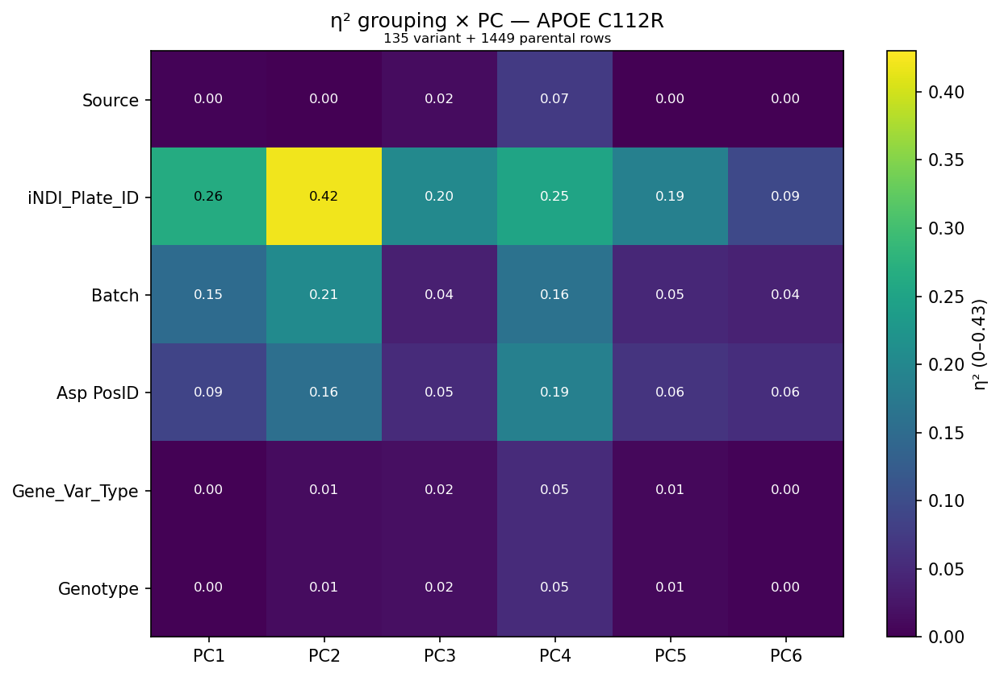

  APOE / R158C: 89 variant + 1449 parental rows


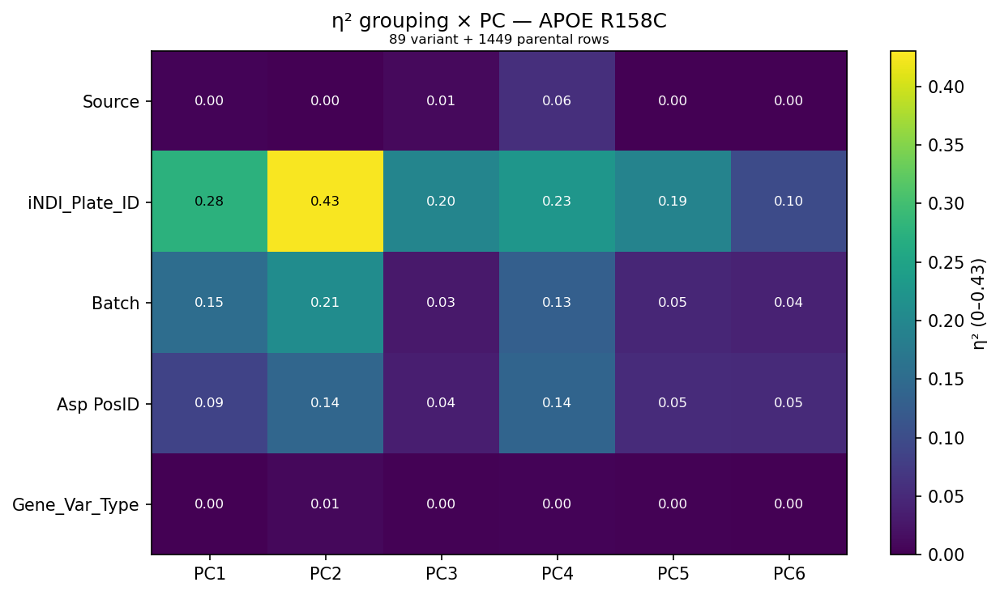

  APP / A673T: 200 variant + 1449 parental rows


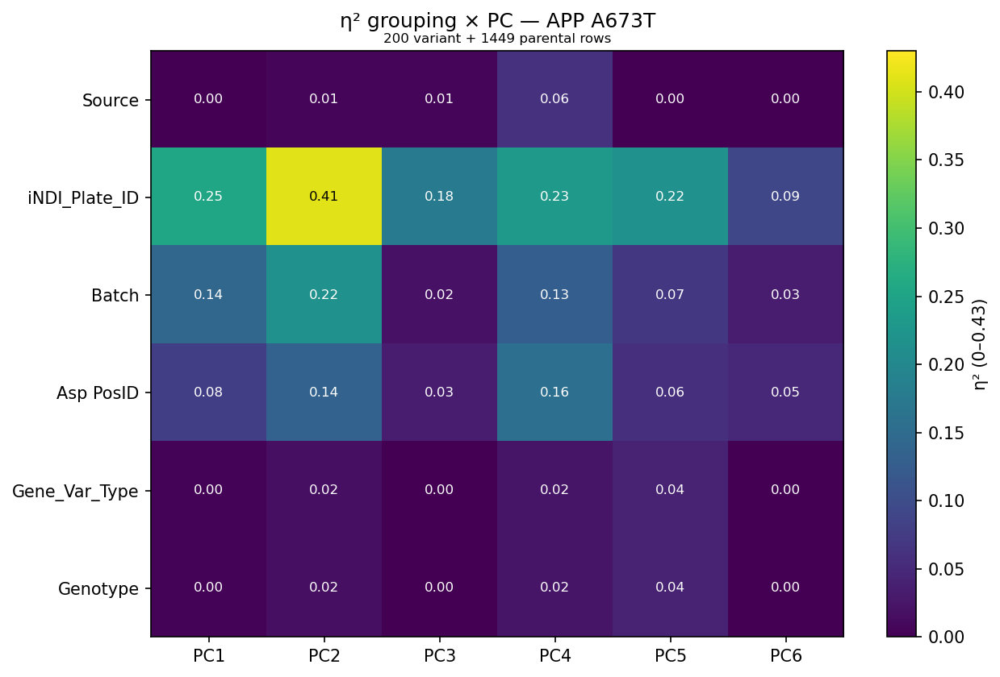

  APP / E693G: 228 variant + 1449 parental rows


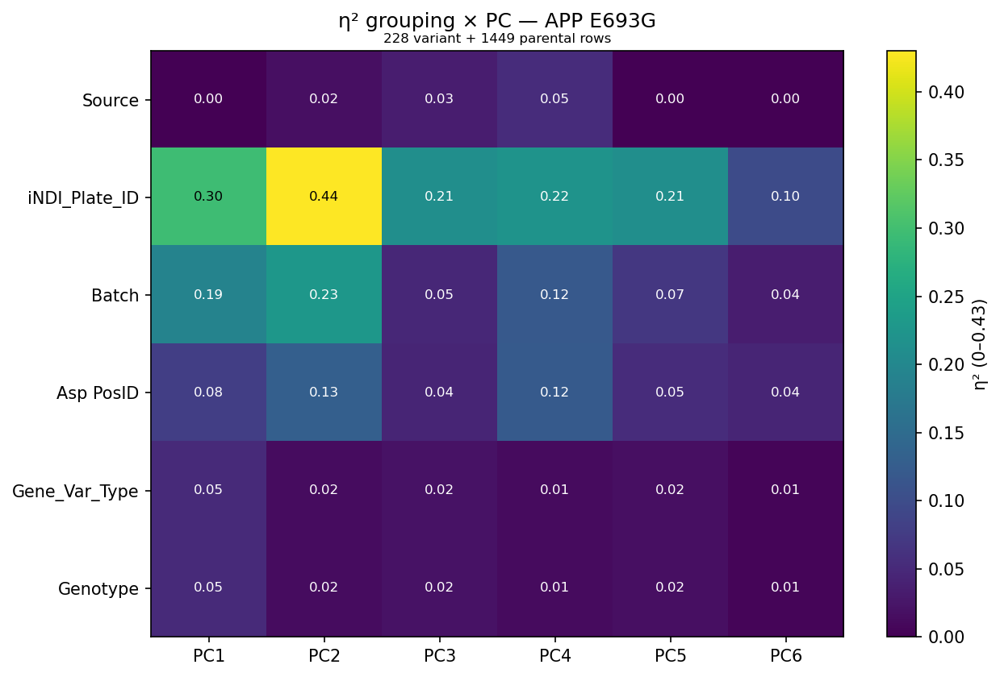

  APP / V717I: 144 variant + 1449 parental rows


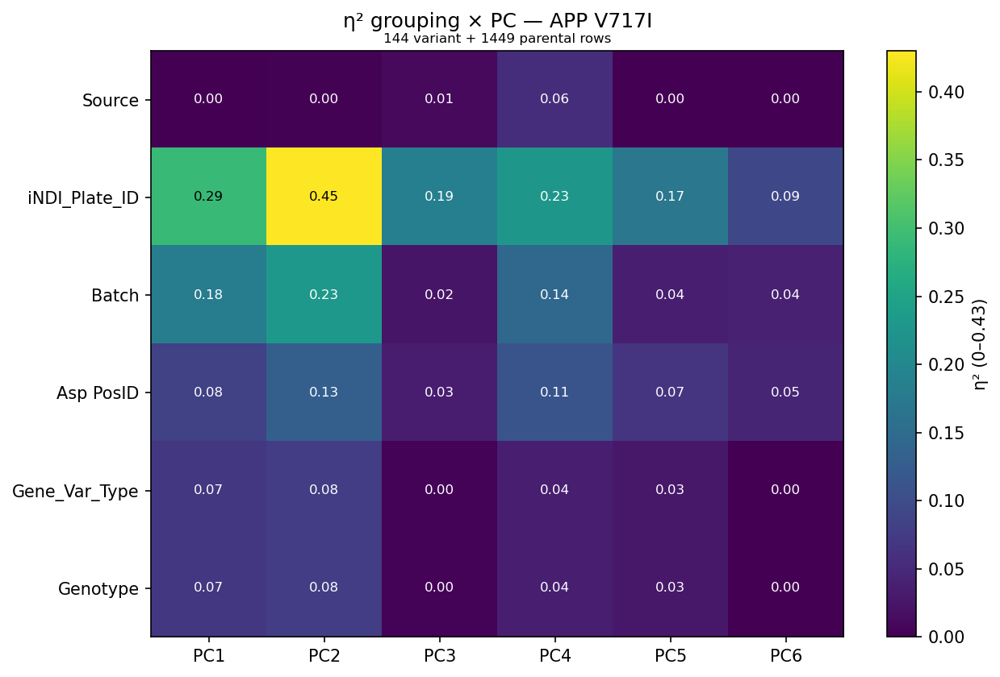

  FUS / R216C: 253 variant + 1449 parental rows


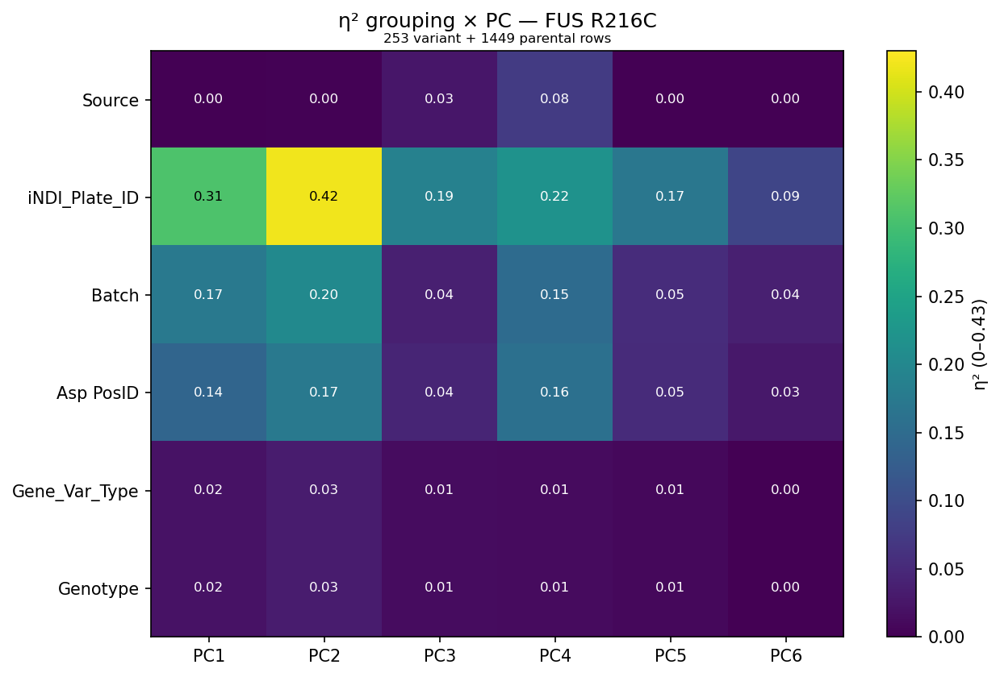

  FUS / R495X: 228 variant + 1449 parental rows


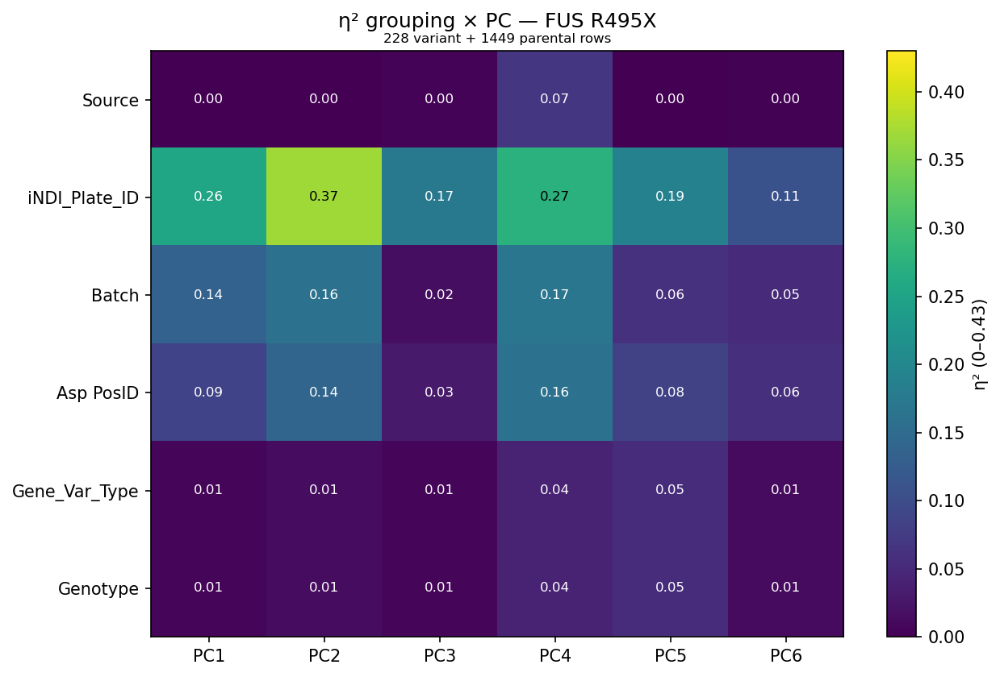

  GRN / Q125X: 260 variant + 1449 parental rows


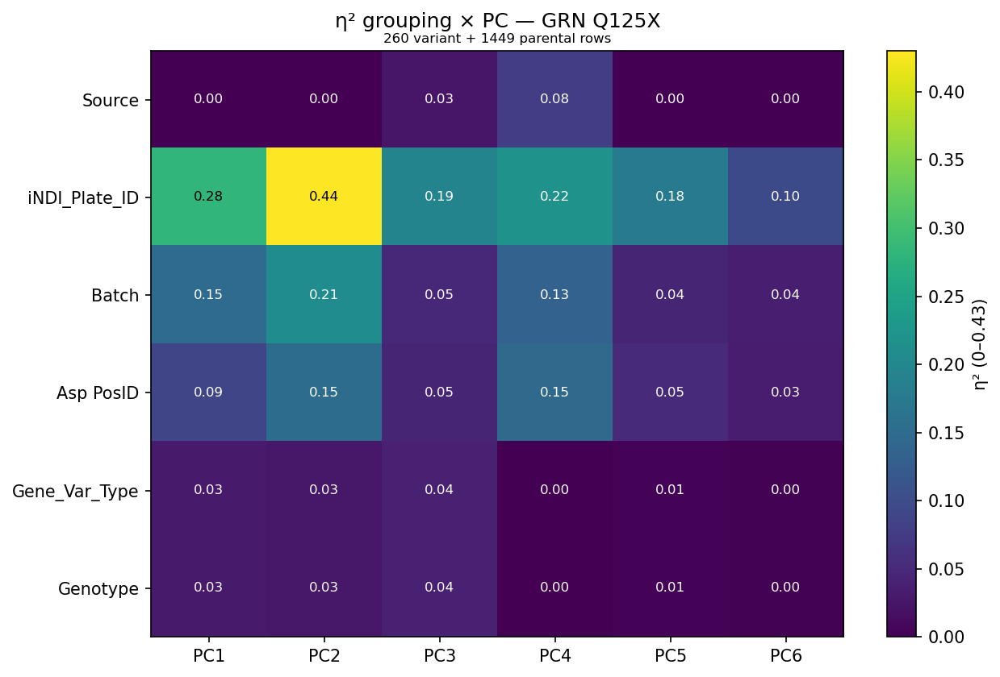

  HNRNPA1 / D262N: 262 variant + 1449 parental rows


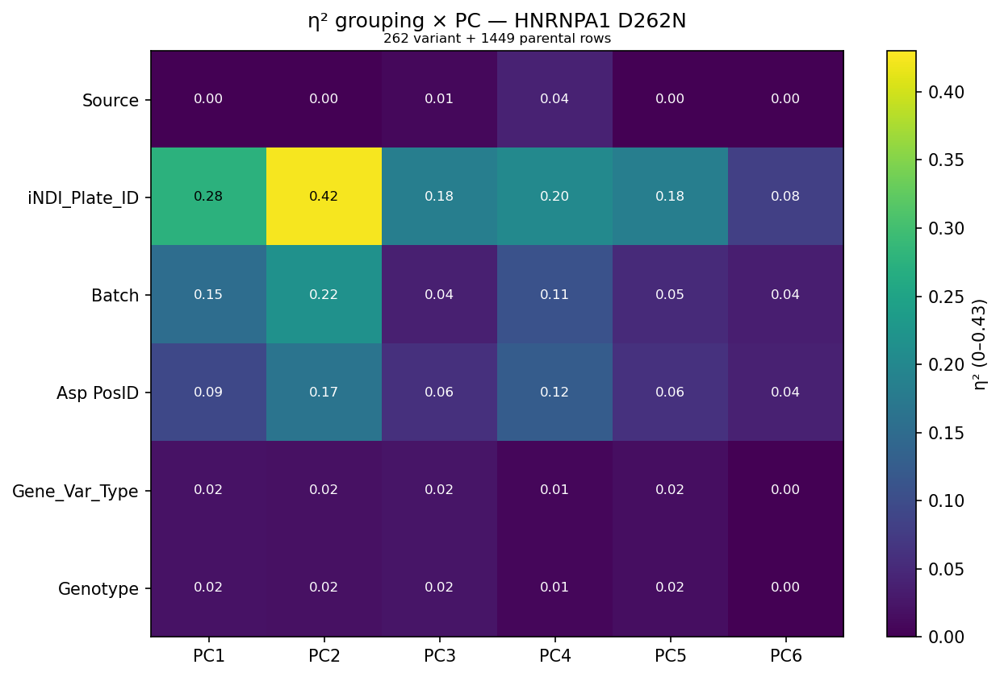

  MAPT / R406W: 255 variant + 1449 parental rows


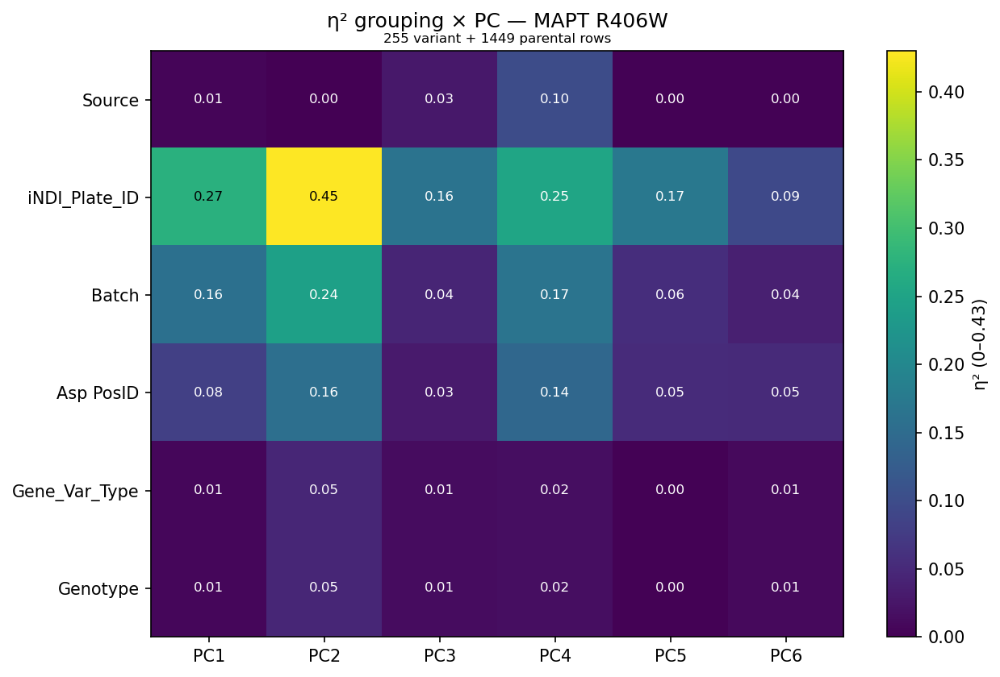

  PFN1 / C71G: 268 variant + 1449 parental rows


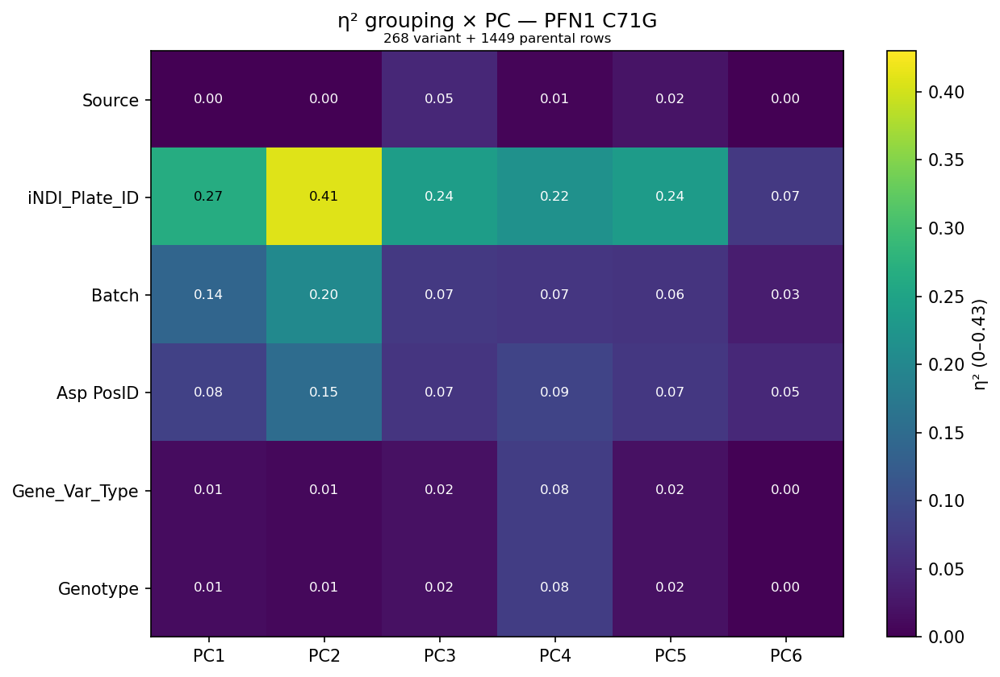

  PSEN1 / E276A: 95 variant + 1449 parental rows


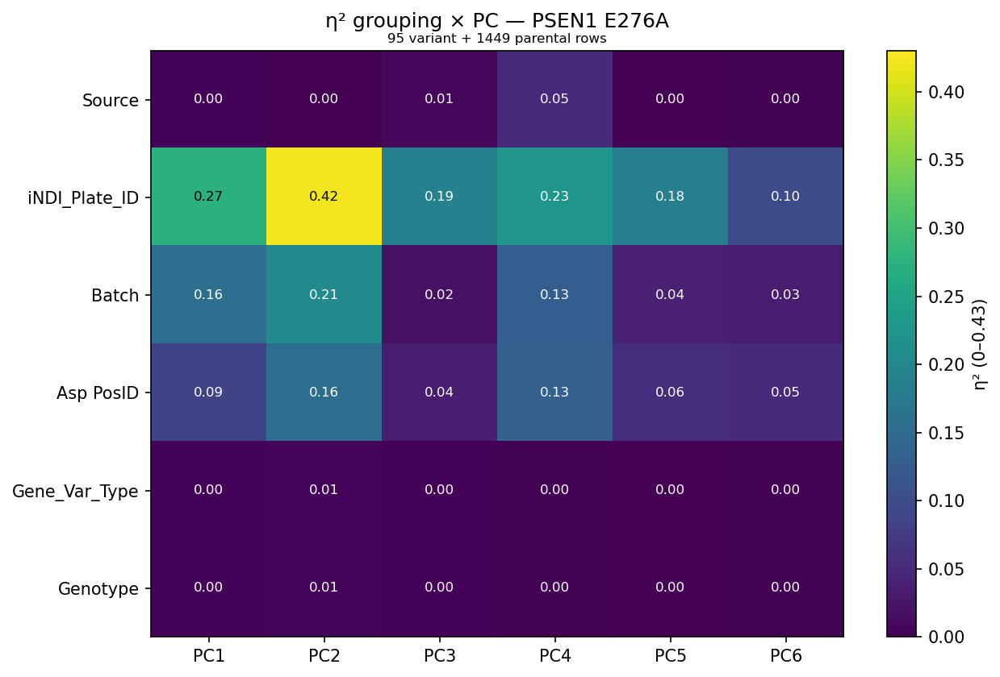

  PSEN2 / N141I: 222 variant + 1449 parental rows


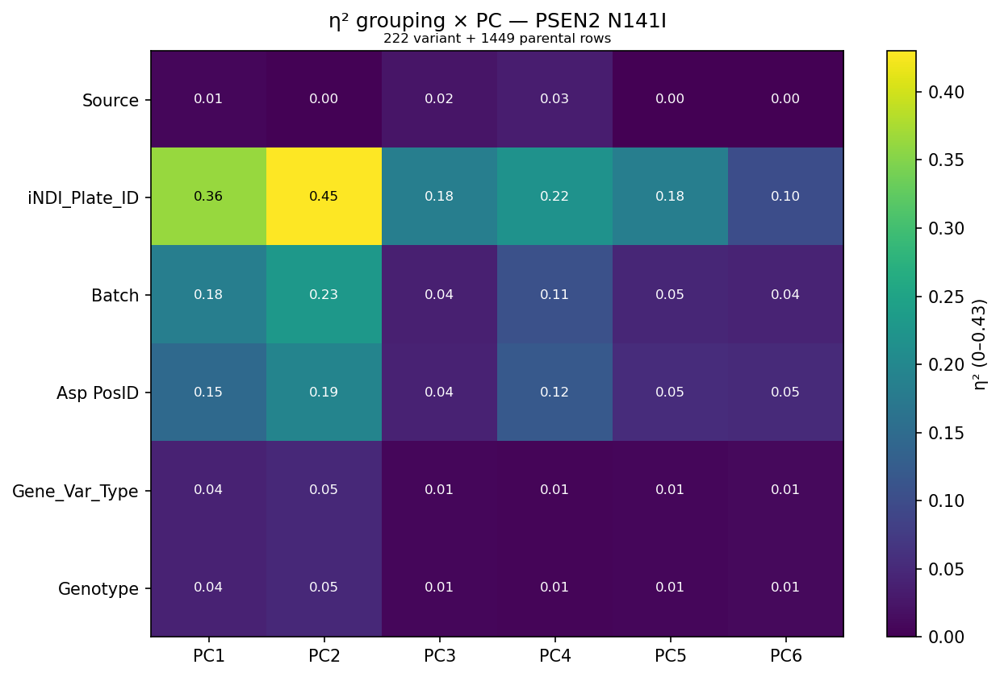

  SNCA / A53T: 172 variant + 1449 parental rows


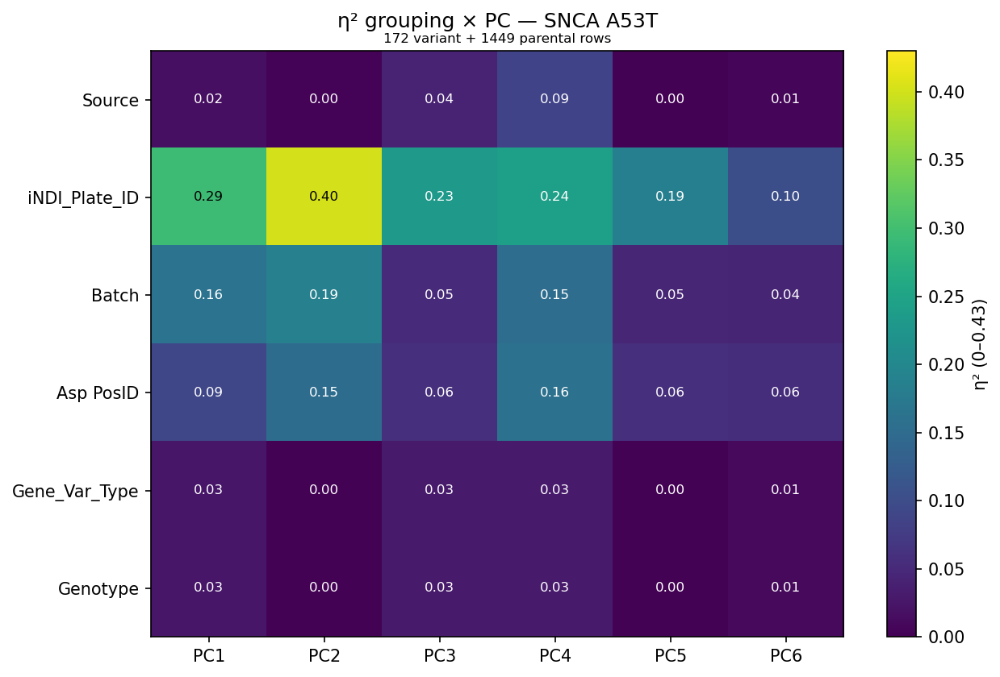

  SNCA / E46K: 146 variant + 1449 parental rows


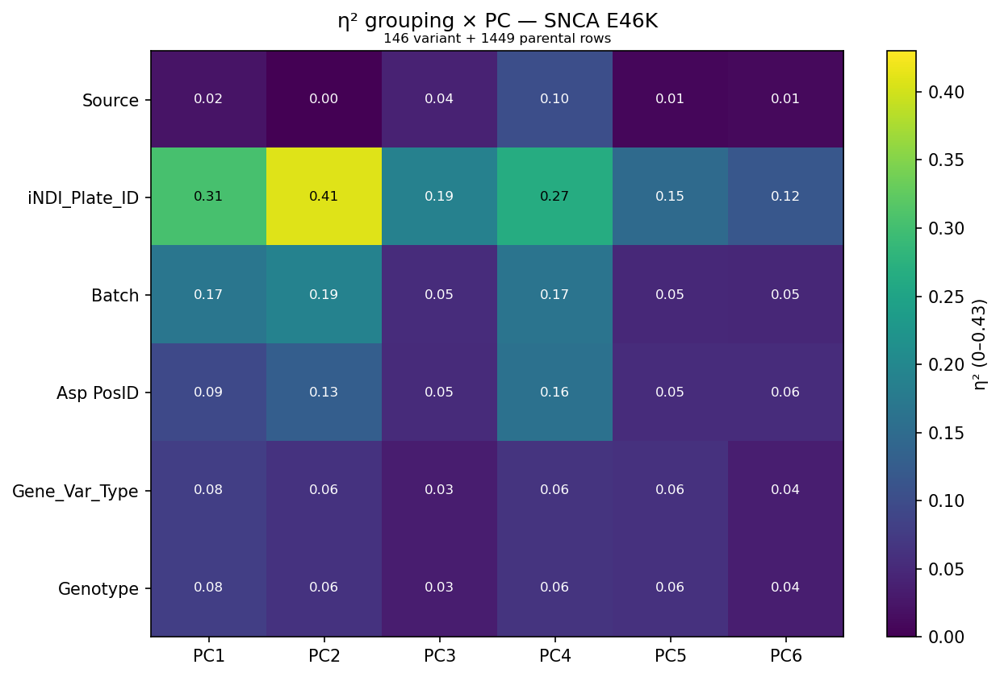

  SNCB / P123H: 222 variant + 1449 parental rows


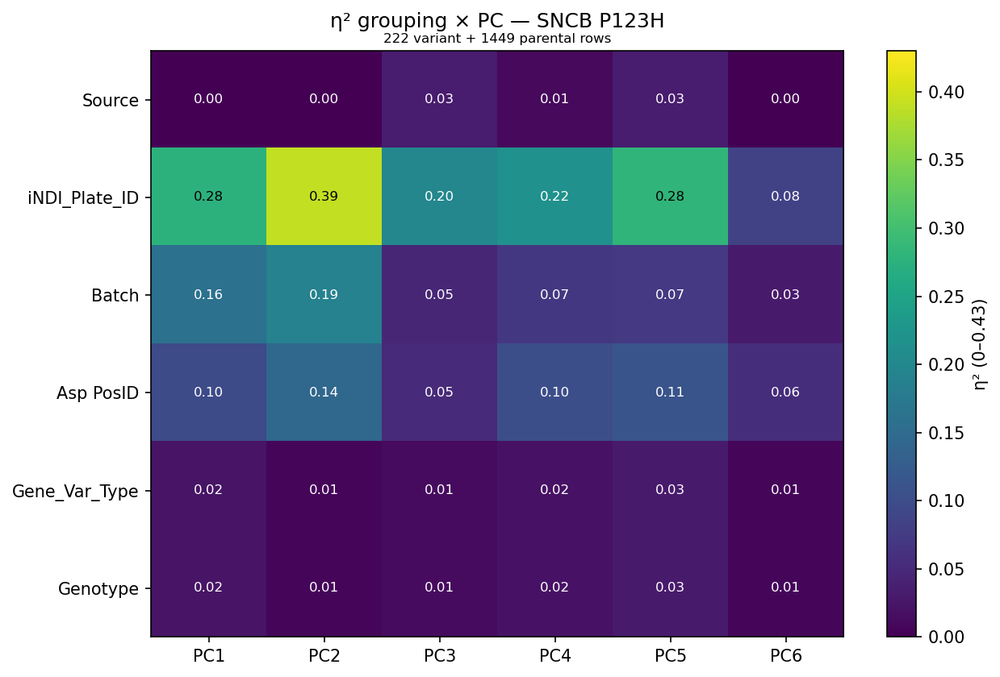

  TARDBP / M337V: 270 variant + 1449 parental rows


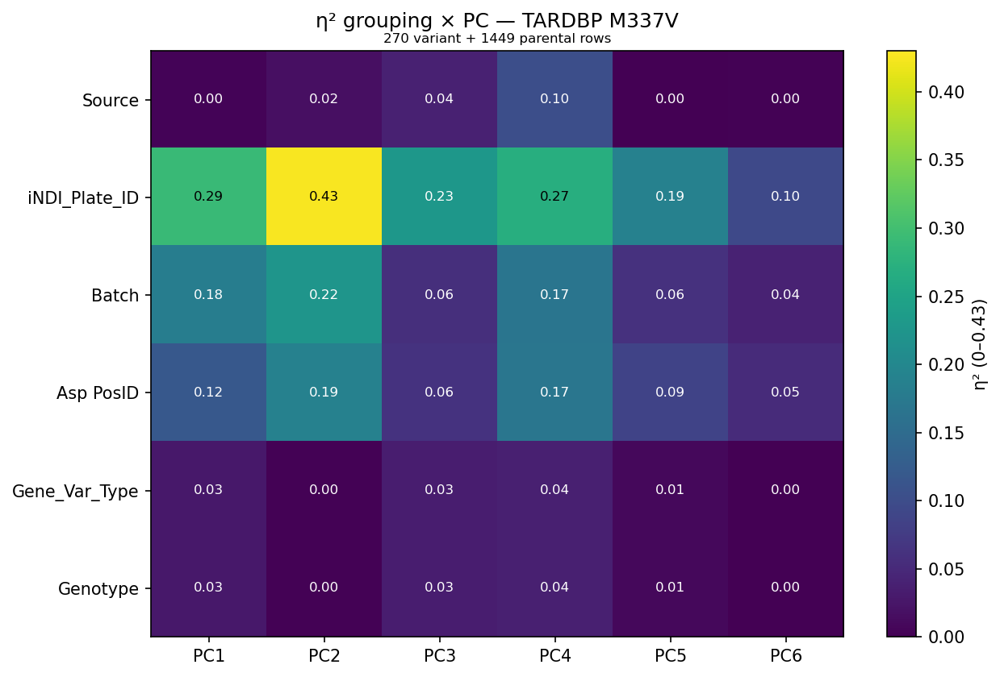

  TARDBP / Q331K: 269 variant + 1449 parental rows


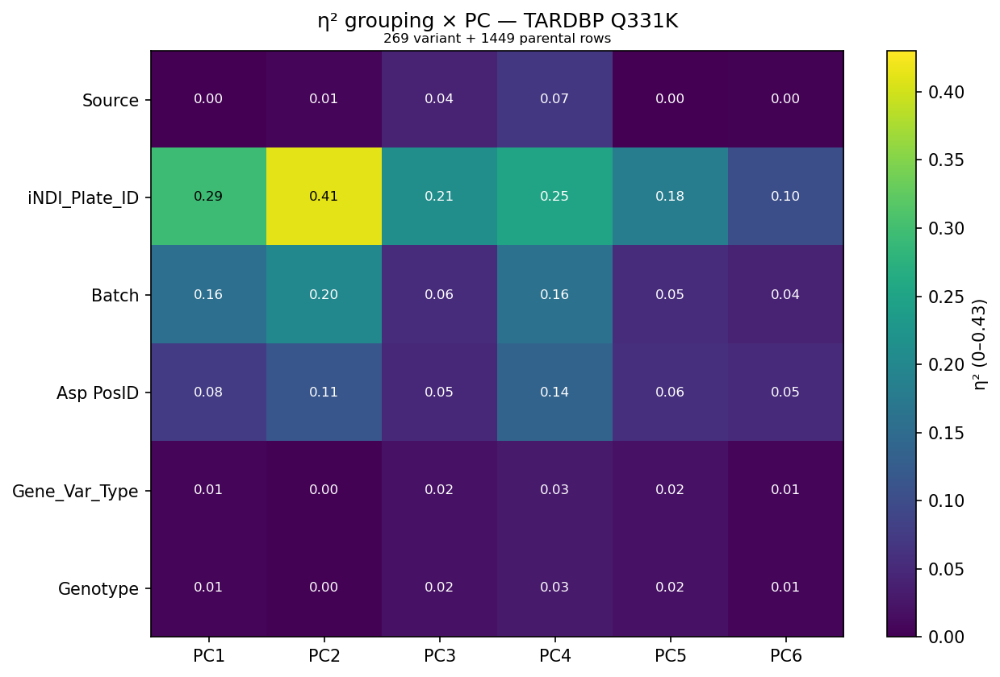

  TBK1 / E696K: 268 variant + 1449 parental rows


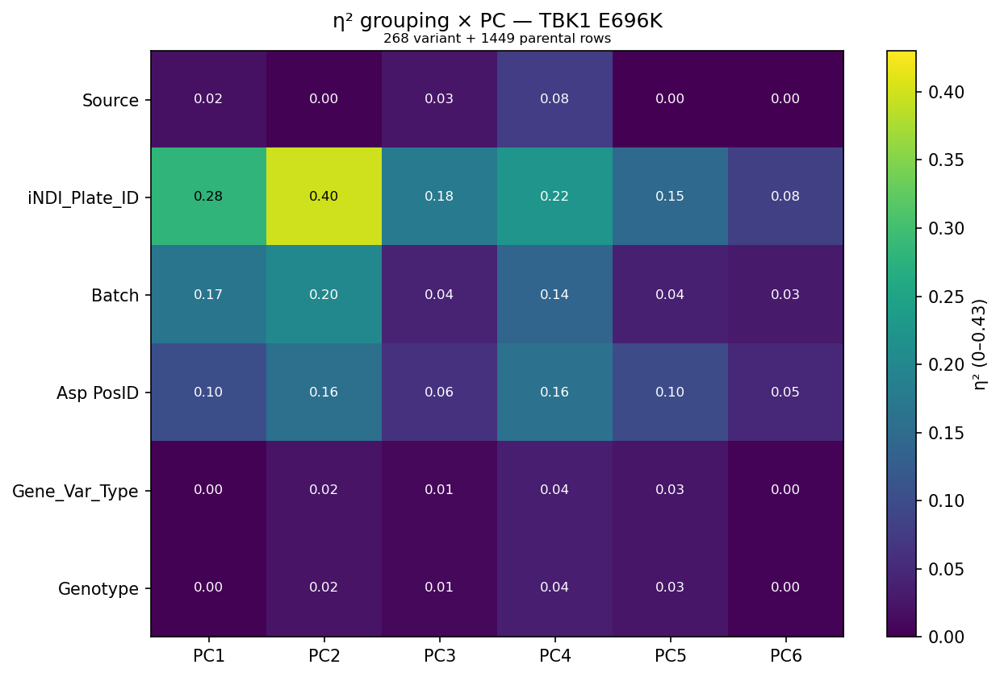

  TIA1 / P351L: 144 variant + 1449 parental rows


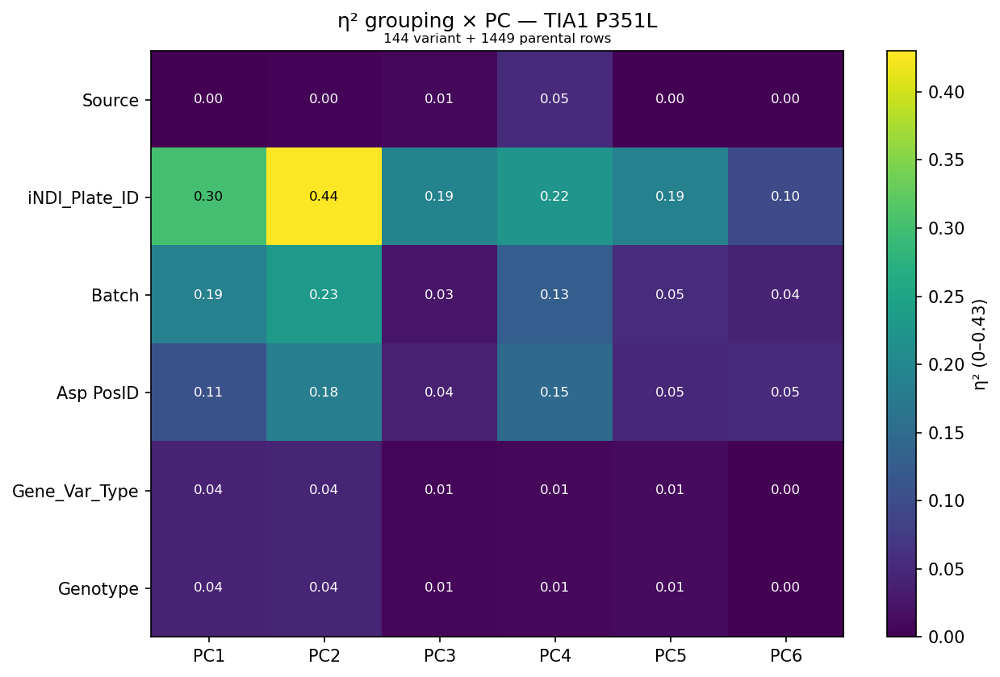

  UBQLN2 / P506T: 84 variant + 1449 parental rows


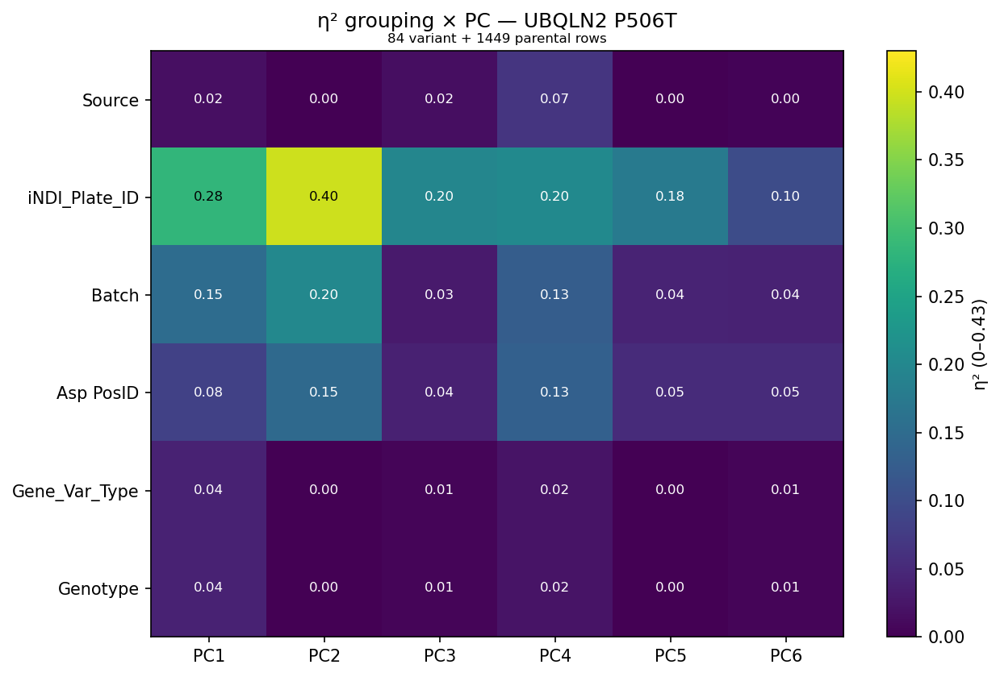

  VCP / R159H: 228 variant + 1449 parental rows


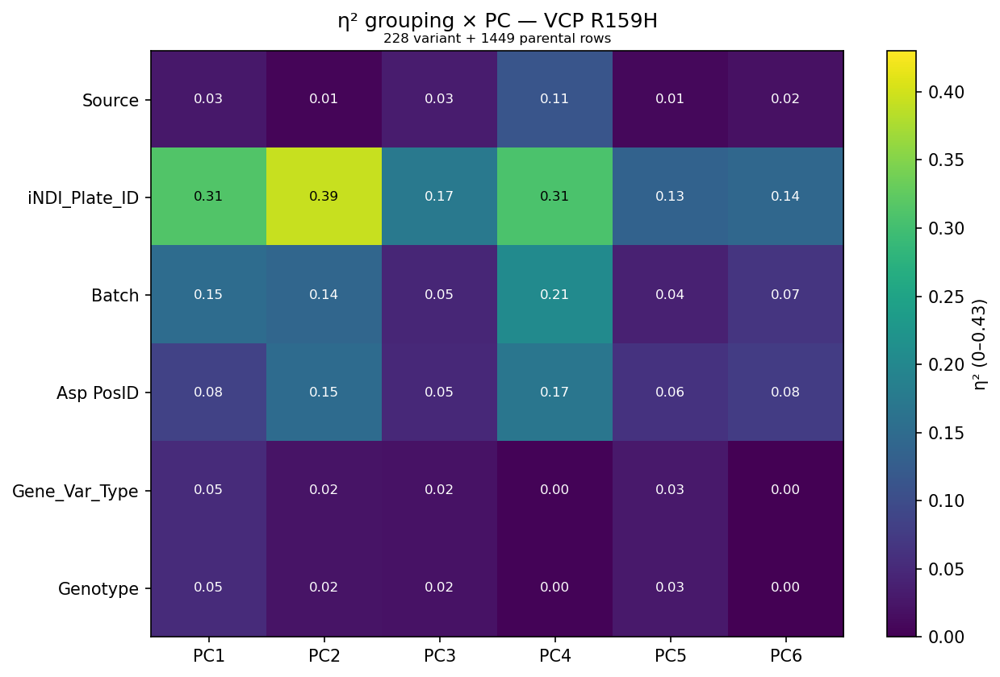

[facet] 22 (gene, variant) pairs; 1449 total KOLF2.1J rows (plate-matched per facet)
  APOE / C112R: 135 variant + 136 parental rows on 2 plate(s)


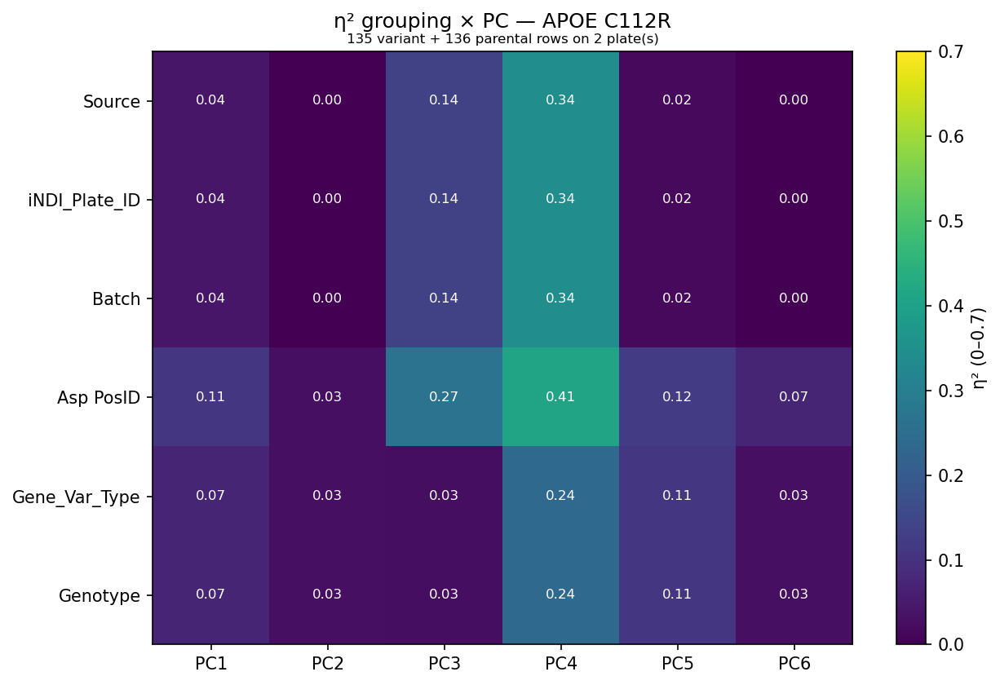

  APOE / R158C: 89 variant + 139 parental rows on 2 plate(s)


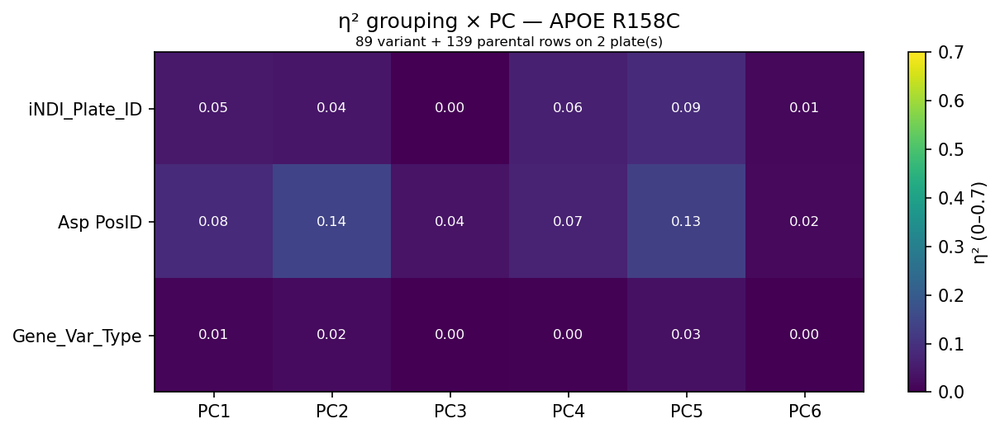

  APP / A673T: 200 variant + 200 parental rows on 3 plate(s)


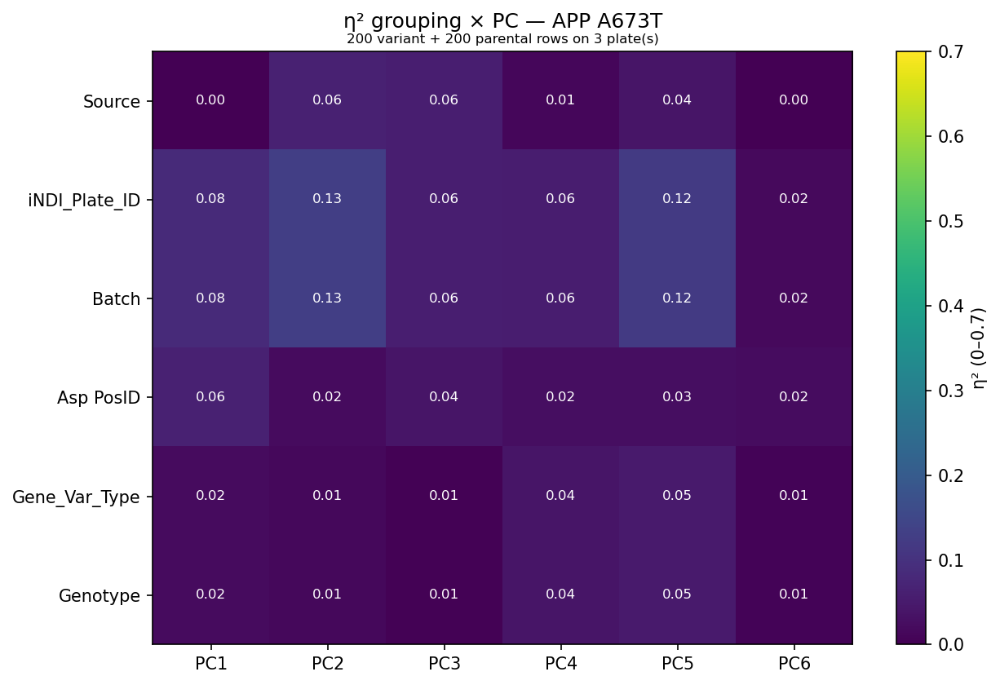

  APP / E693G: 228 variant + 186 parental rows on 3 plate(s)


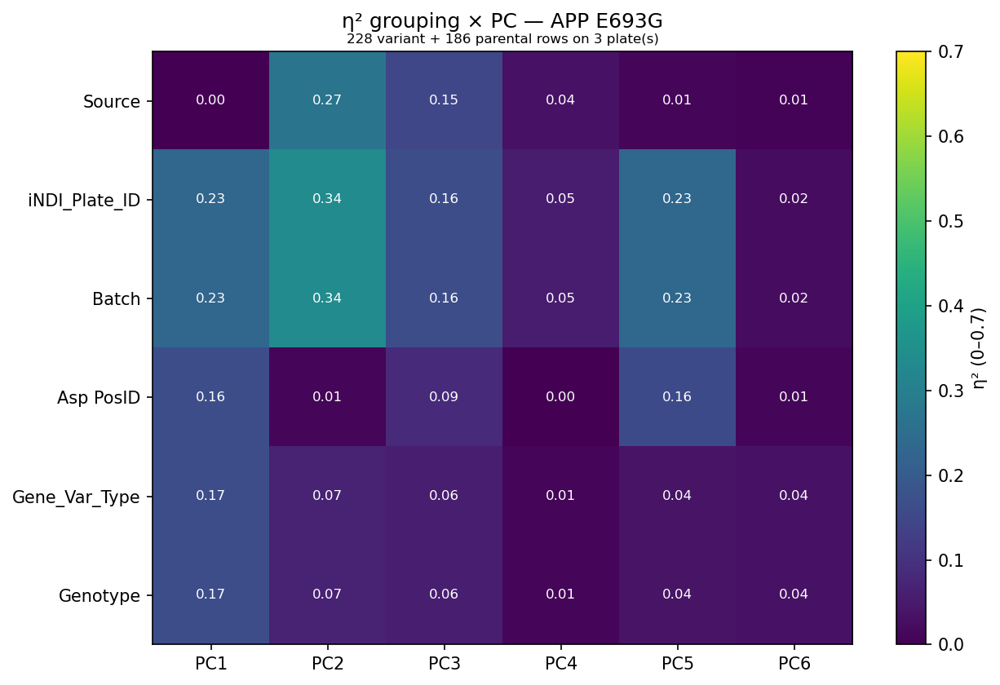

  APP / V717I: 144 variant + 144 parental rows on 2 plate(s)


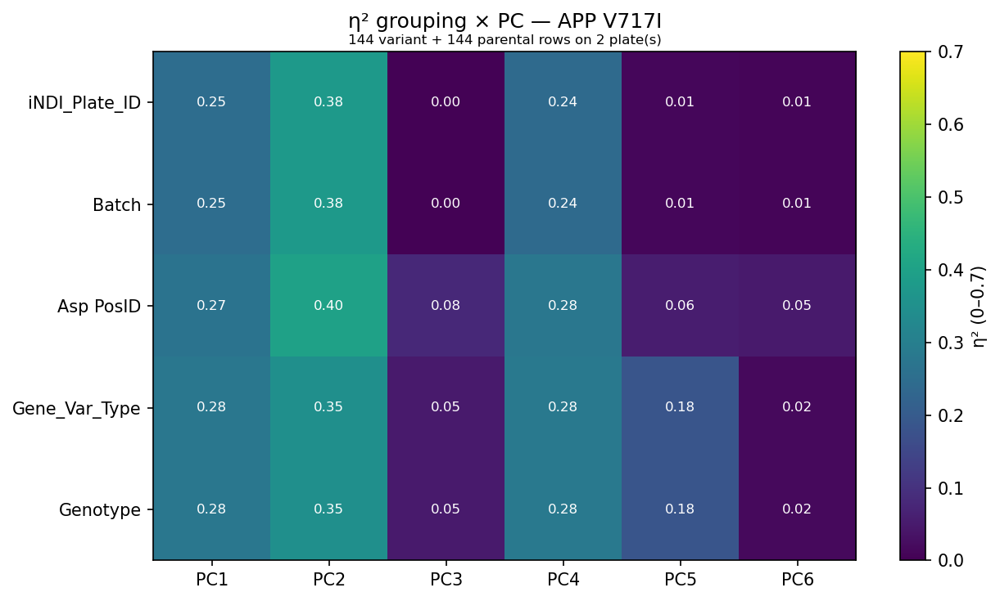

  FUS / R216C: 253 variant + 331 parental rows on 5 plate(s)


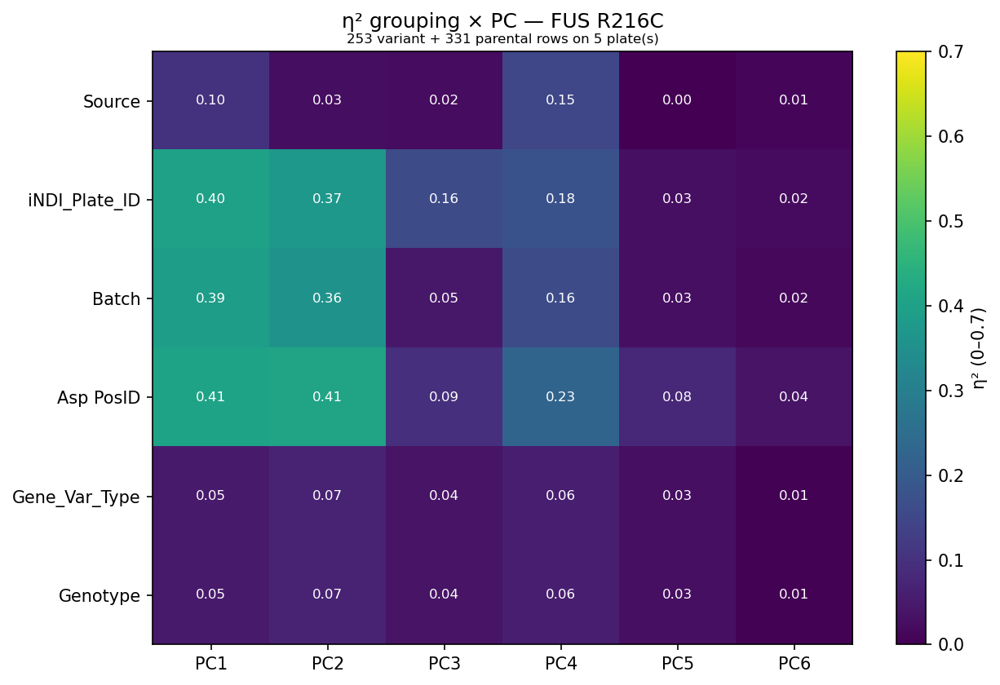

  FUS / R495X: 228 variant + 152 parental rows on 2 plate(s)


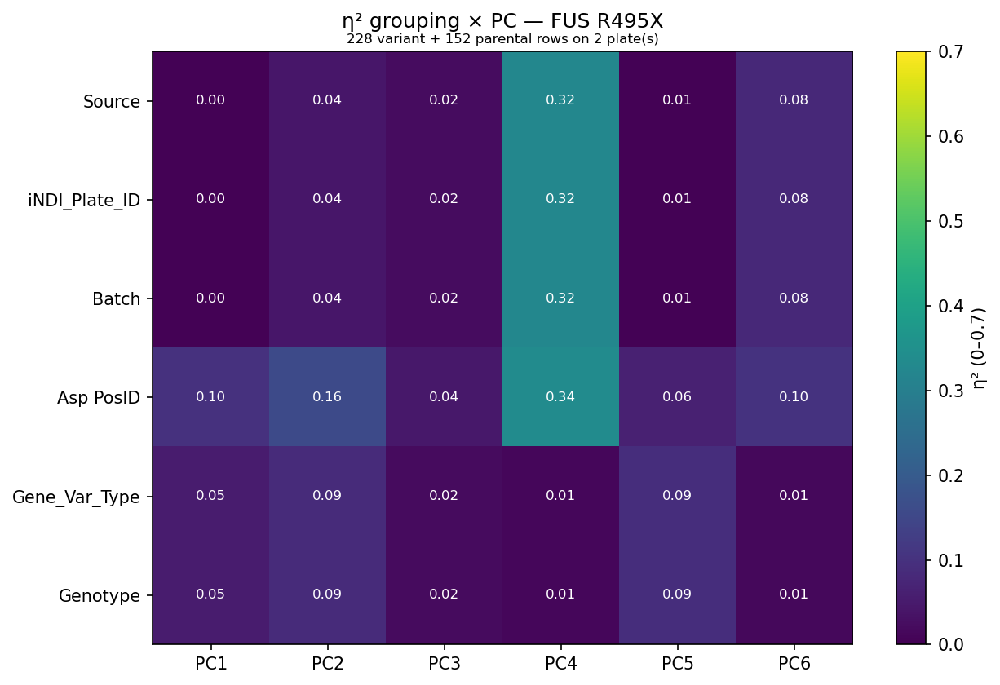

  GRN / Q125X: 260 variant + 224 parental rows on 4 plate(s)


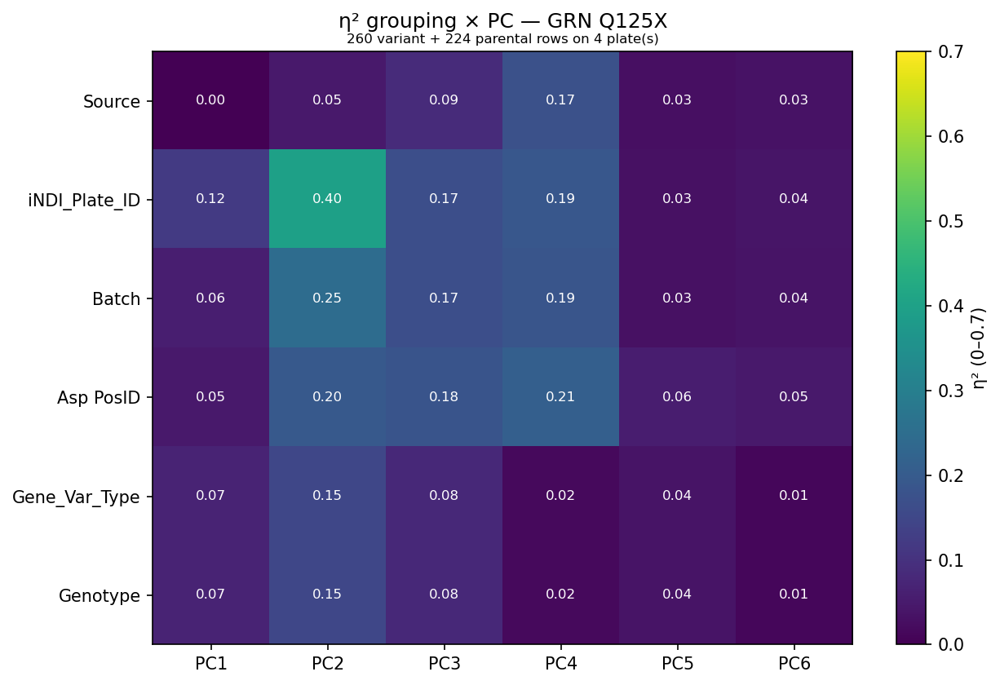

  HNRNPA1 / D262N: 262 variant + 152 parental rows on 3 plate(s)


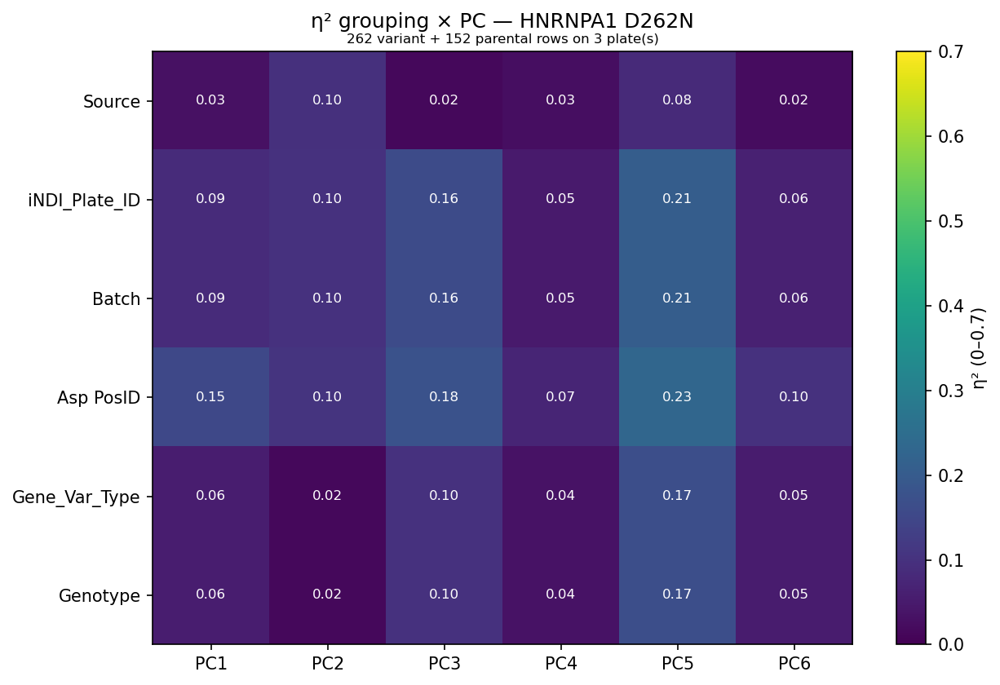

  MAPT / R406W: 255 variant + 179 parental rows on 3 plate(s)


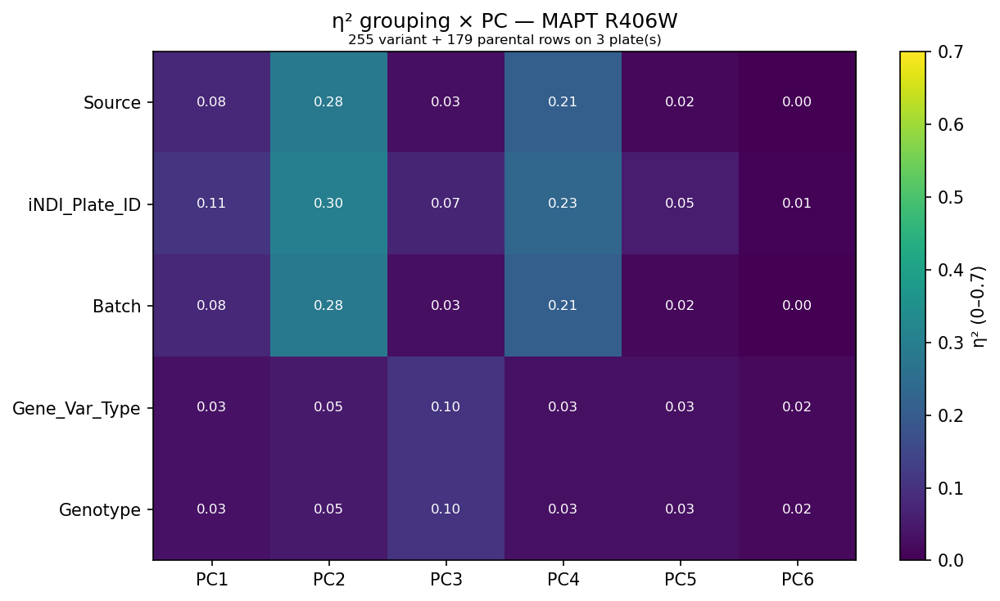

  PFN1 / C71G: 268 variant + 180 parental rows on 3 plate(s)


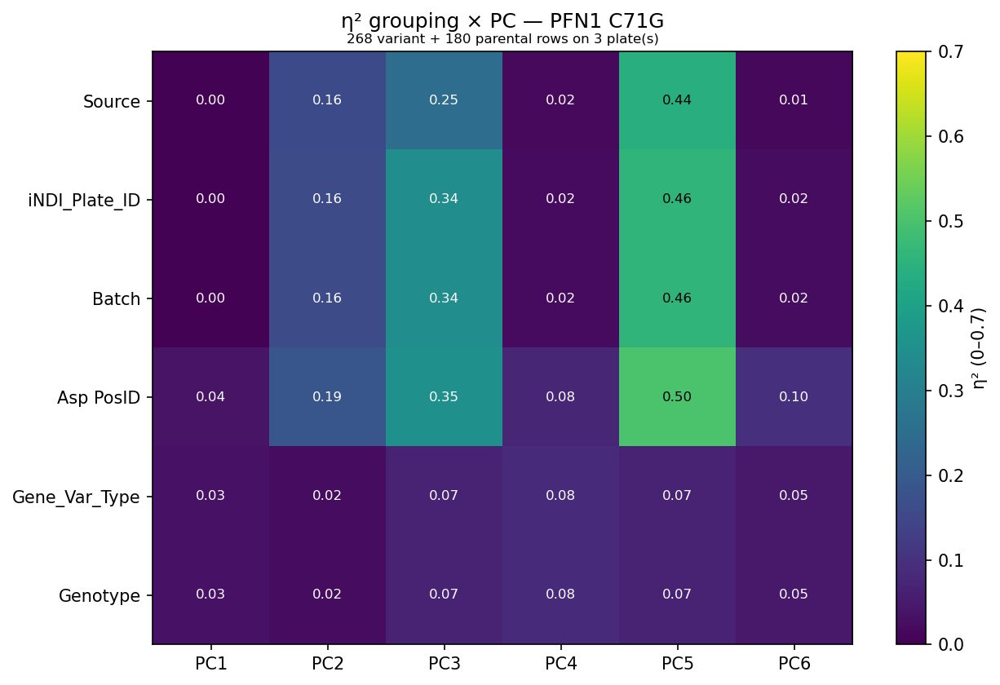

  PSEN1 / E276A: 95 variant + 191 parental rows on 2 plate(s)


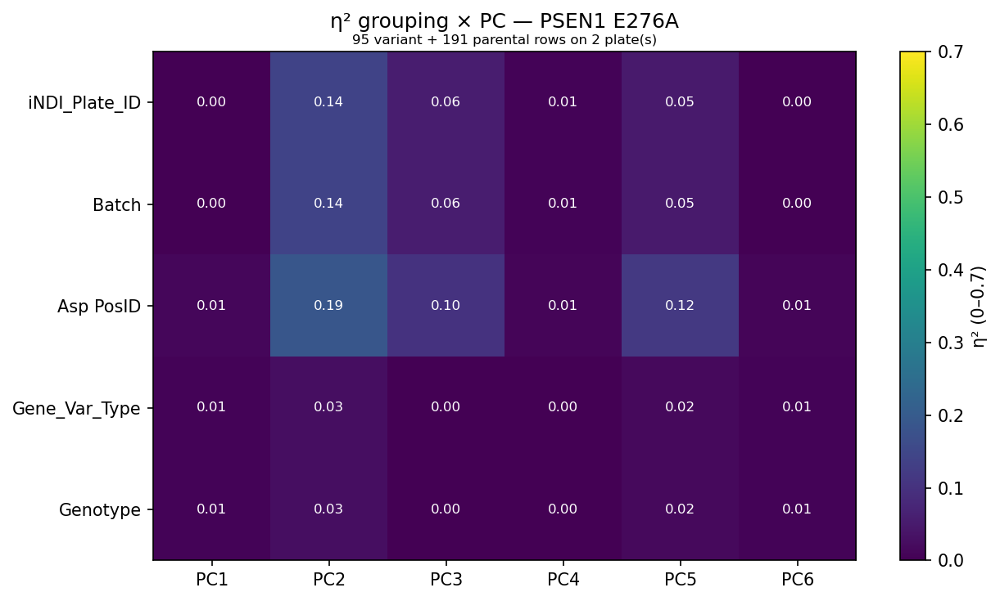

  PSEN2 / N141I: 222 variant + 205 parental rows on 3 plate(s)


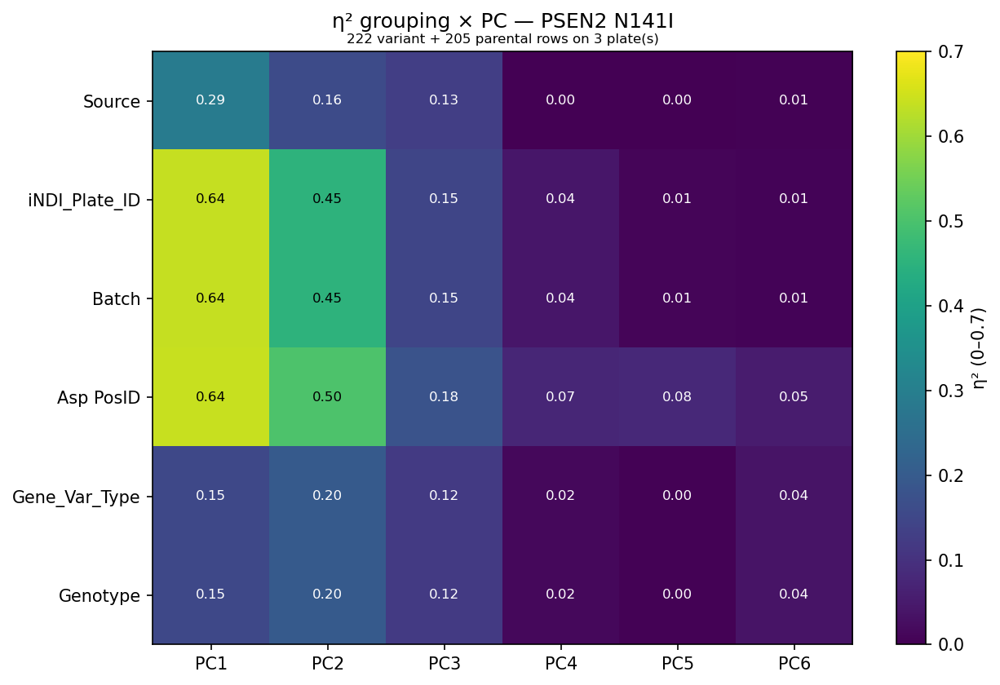

  SNCA / A53T: 172 variant + 136 parental rows on 2 plate(s)


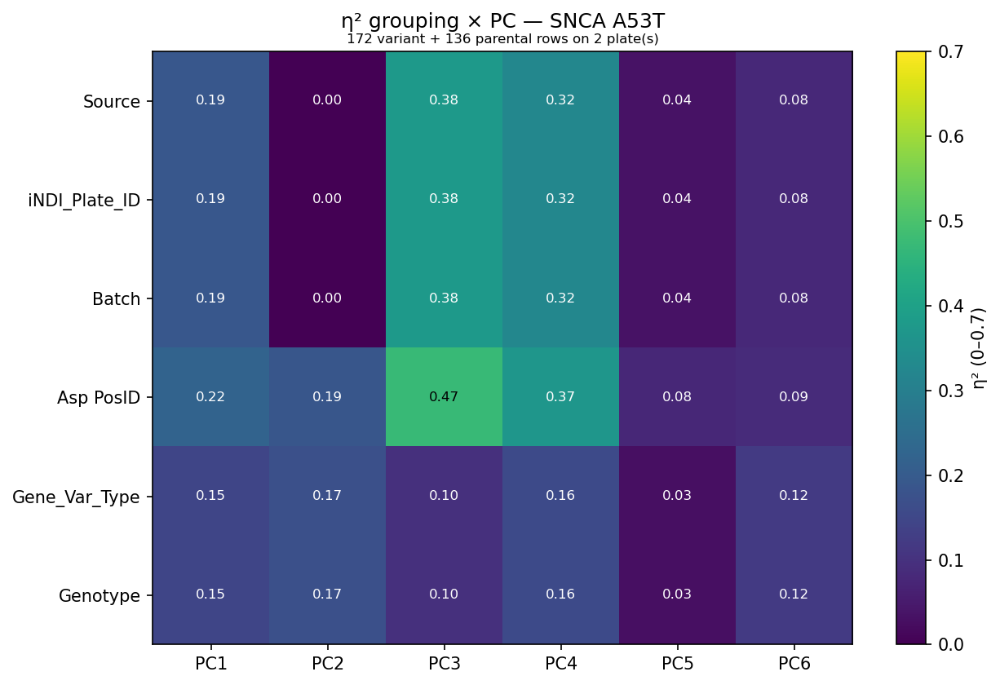

  SNCA / E46K: 146 variant + 122 parental rows on 2 plate(s)


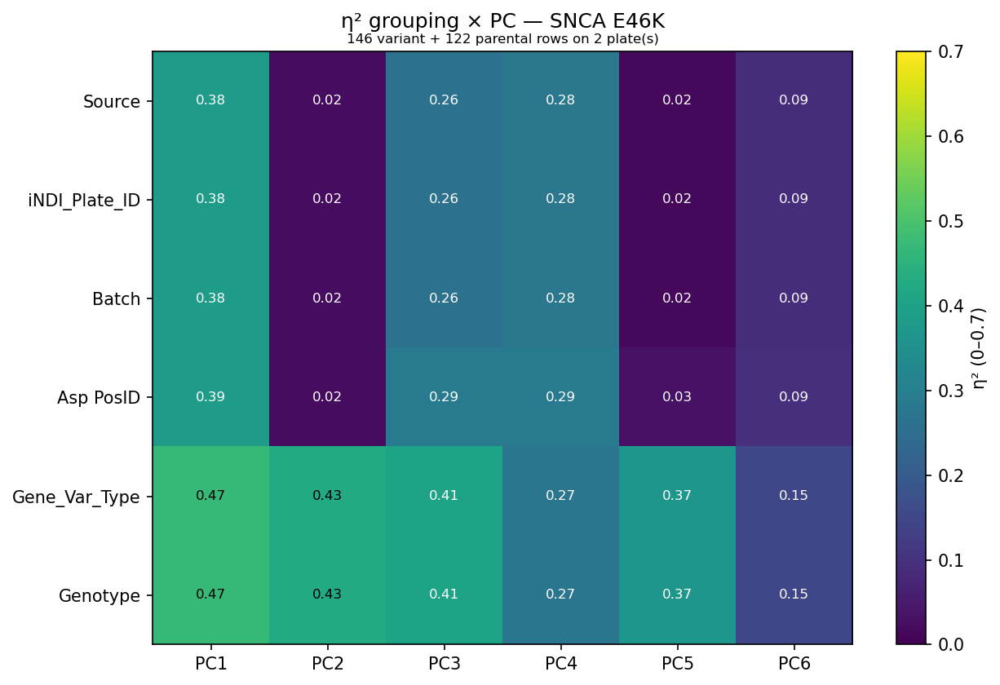

  SNCB / P123H: 222 variant + 138 parental rows on 2 plate(s)


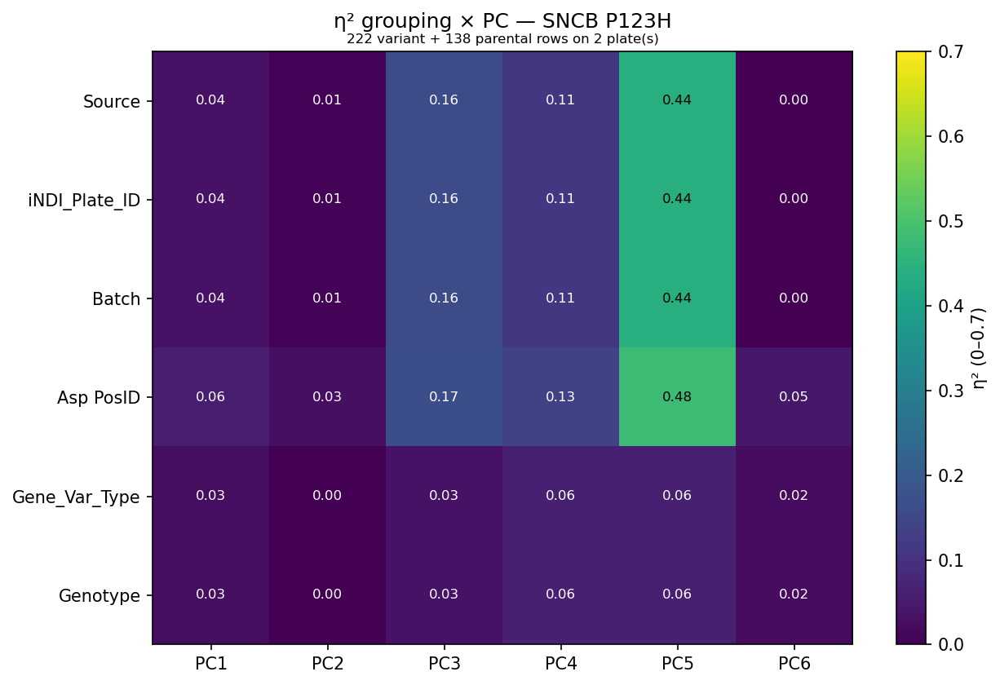

  TARDBP / M337V: 270 variant + 234 parental rows on 3 plate(s)


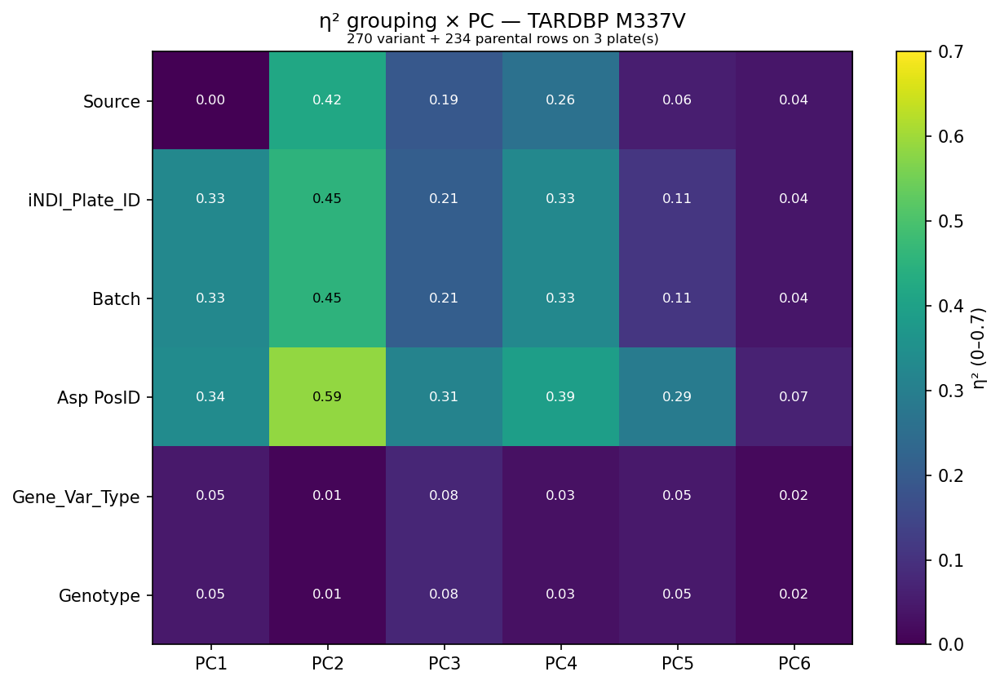

  TARDBP / Q331K: 269 variant + 318 parental rows on 5 plate(s)


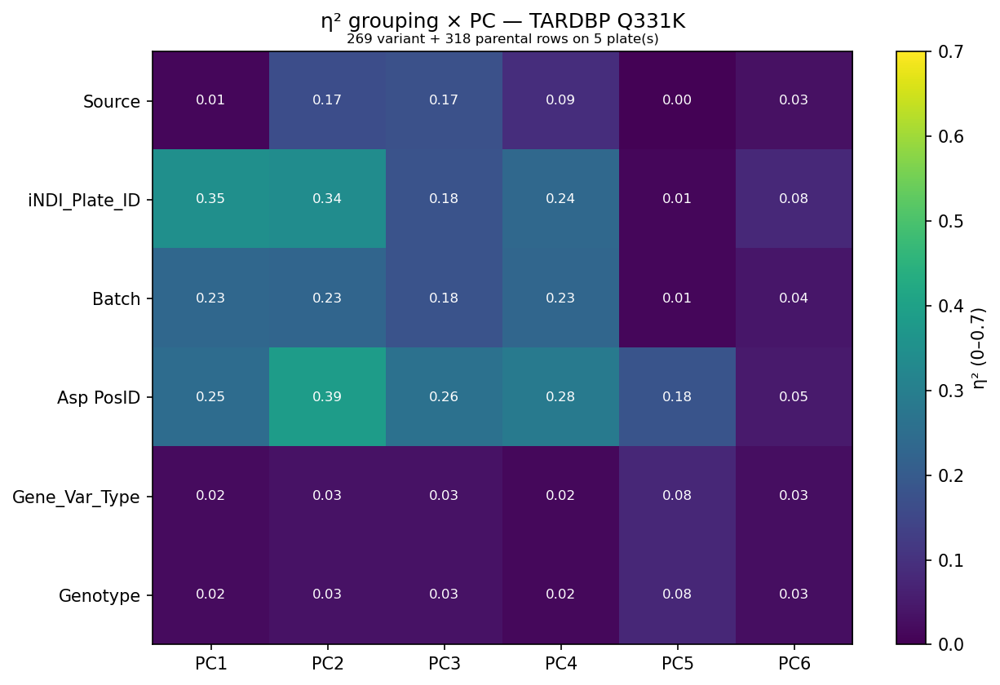

  TBK1 / E696K: 268 variant + 180 parental rows on 3 plate(s)


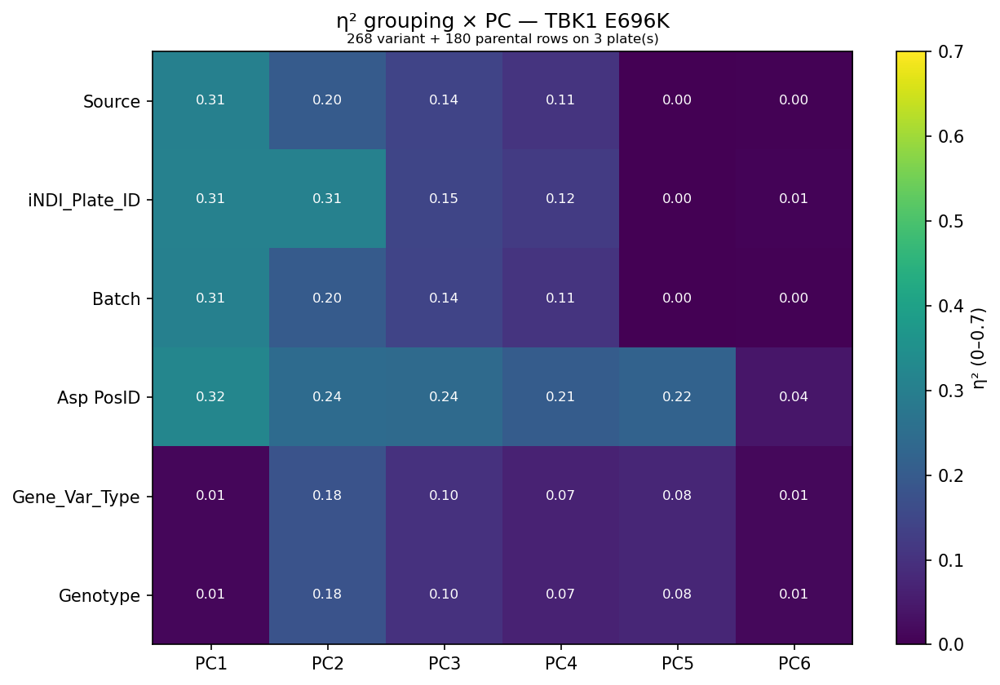

  TIA1 / P351L: 144 variant + 192 parental rows on 2 plate(s)


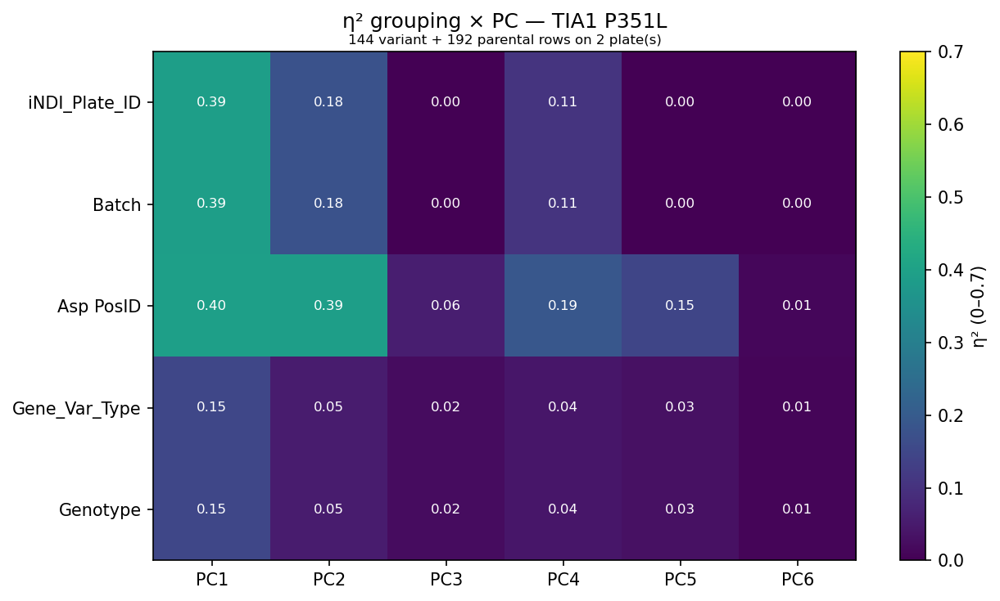

  UBQLN2 / P506T: 84 variant + 42 parental rows on 1 plate(s)


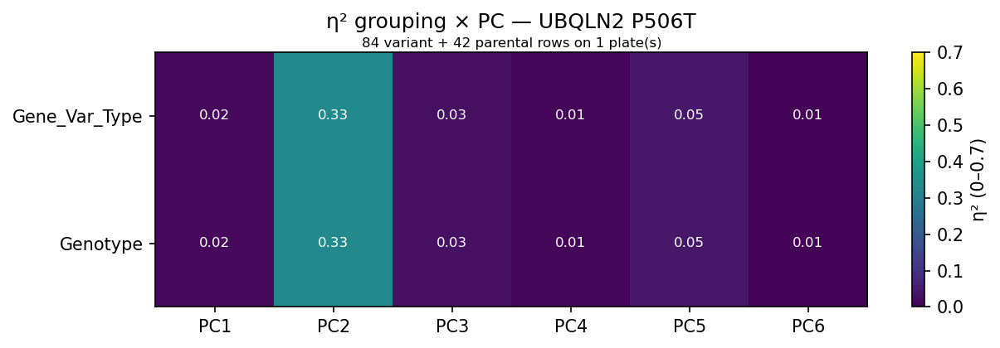

  VCP / R159H: 228 variant + 123 parental rows on 2 plate(s)


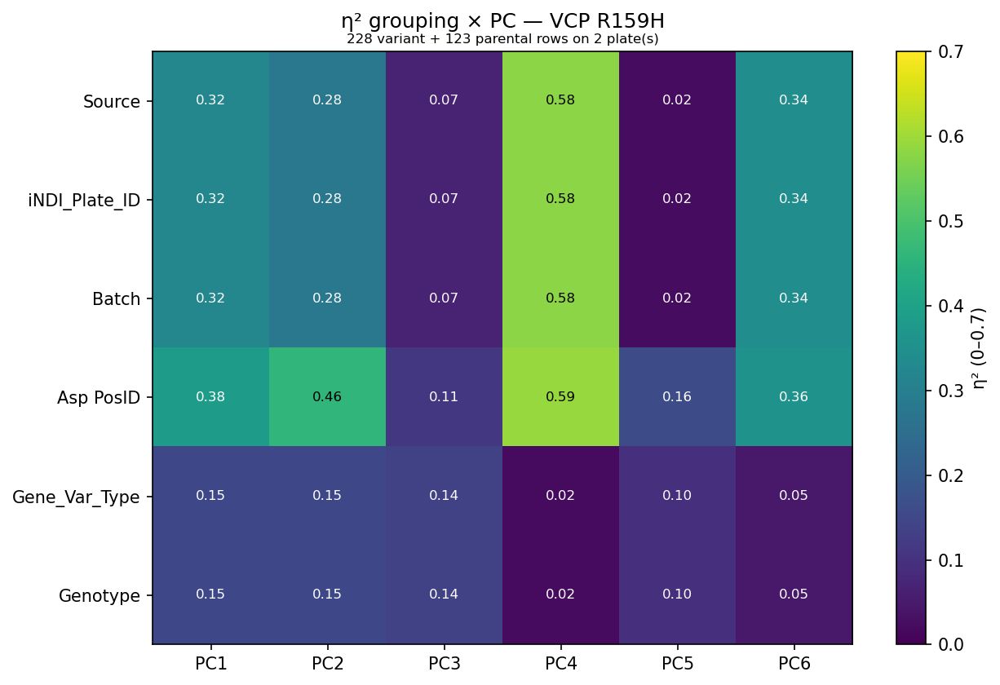

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- your original eta_squared, unchanged ----------------------------------
def eta_squared(values, groups):
    values = np.asarray(values, dtype=float)
    mask = np.isfinite(values)
    values, groups = values[mask], np.asarray(groups)[mask]
    if values.size == 0:
        return np.nan
    grand = values.mean()
    ss_total = ((values - grand) ** 2).sum()
    ss_between = 0.0
    for g in pd.unique(groups):
        v = values[groups == g]
        if v.size == 0:
            continue
        ss_between += len(v) * (v.mean() - grand) ** 2
    return ss_between / ss_total if ss_total > 0 else np.nan


# --- optional well-level aggregation (strongly recommended) ----------------
# A per-gene variant effect on a mean is invisible at single-nucleus level.
# Collapse ROI rows to one row per well before faceting.
def aggregate_to_wells(data, well_keys, carry_cols, pc_cols):
    agg = {pc: "median" for pc in pc_cols}
    for c in carry_cols:
        agg[c] = "first"
    return data.groupby(list(well_keys), as_index=False).agg(agg)


# --- shared WT/control predicate -------------------------------------------
def is_wt(data, gene_col="Gene"):
    """True for the shared KOLF2.1J parental-control rows (they live in Gene)."""
    return data[gene_col].astype(str).str.strip() == "KOLF2.1J"


# --- the original single-matrix eta computation, as a reusable helper -------
def eta_matrix(data, group_cols, pc_cols):
    """grouping x PC matrix of η² for one data subset (e.g. one gene facet)."""
    group_cols = [g for g in group_cols if g in data.columns]
    mat = pd.DataFrame(index=group_cols, columns=pc_cols, dtype=float)
    for gc in group_cols:
        groups = data[gc].to_numpy()
        for pc in pc_cols:
            mat.loc[gc, pc] = eta_squared(data[pc].to_numpy(), groups)
    return mat


# --- per-gene-variant: ONE SEPARATE FIGURE per facet -----------------------
def plot_gene_heatmap(sub, group_cols, pc_cols, gene, variant, vmax=0.2,
                      annot=True, drop_constant=True, subtitle=None):
    """Draw a single grouping x PC η² heatmap for one facet's subset."""
    rows = list(group_cols)
    if drop_constant:  # hide grouping rows with <2 levels in this facet
        rows = [g for g in rows if g in sub.columns and sub[g].nunique() > 1]
    mat = eta_matrix(sub, rows, pc_cols)

    fig, ax = plt.subplots(
        figsize=(1.1 * len(pc_cols) + 2, 0.7 * len(mat.index) + 1.5), dpi=150)
    im = ax.imshow(mat.values.astype(float), cmap="viridis",
                   vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(pc_cols))); ax.set_xticklabels(pc_cols)
    ax.set_yticks(range(len(mat.index))); ax.set_yticklabels(mat.index)
    plt.colorbar(im, ax=ax, label=f"η² (0–{vmax})")
    ax.set_title(f"η² grouping × PC — {gene} {variant}", pad=14)
    if subtitle:
        ax.text(0.5, 1.01, subtitle, transform=ax.transAxes,
                ha="center", va="bottom", fontsize=8)
    if annot:
        for i in range(len(mat.index)):
            for j in range(len(pc_cols)):
                v = mat.iloc[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                            color="white" if v < 0.6 * vmax else "black",
                            fontsize=8)
    plt.tight_layout(); plt.show()
    return mat


def facet_by_gene_variant(data, group_cols, n_pcs=10,
                          gene_col="Gene", variant_col="Variant", vmax=0.2,
                          annot=True, include_wt=True, drop_constant=True,
                          plate_match=False, plate_col="iNDI_Plate_ID"):
    """One separate η² heatmap figure per (gene, variant) pair. Each facet's
    subset is that single variant's rows plus the shared KOLF2.1J control rows.

    plate_match=True restricts the KOLF2.1J rows folded into each facet to the
    plates that variant actually occupies, removing the plate confound.
    """
    pc_cols = sorted([c for c in data.columns if c.startswith("PC")],
                     key=lambda s: int(s[2:]))[:n_pcs]

    wt_mask = is_wt(data, gene_col)
    wt_rows = data[wt_mask]
    edited = data[~wt_mask]

    # unique (gene, variant) pairs among edited rows
    pairs = (edited[[gene_col, variant_col]]
             .dropna()
             .drop_duplicates()
             .sort_values([gene_col, variant_col])
             .itertuples(index=False, name=None))
    pairs = list(pairs)

    print(f"[facet] {len(pairs)} (gene, variant) pairs; "
          f"{len(wt_rows)} total KOLF2.1J rows "
          f"{'(plate-matched per facet)' if plate_match else '(all folded into each facet)'}")

    # gene and variant are constant within a facet, so never use them as rows
    facet_groups = [g for g in group_cols
                    if g not in (gene_col, variant_col)]

    mats = {}
    for gene, variant in pairs:
        var_rows = edited[(edited[gene_col] == gene)
                          & (edited[variant_col] == variant)]
        if var_rows.empty:
            continue

        if include_wt:
            wt_use = wt_rows
            if plate_match and plate_col in data.columns:
                var_plates = set(var_rows[plate_col].dropna().unique())
                wt_use = wt_rows[wt_rows[plate_col].isin(var_plates)]
            plate_note = (f" on {len(set(var_rows[plate_col].dropna().unique()))} plate(s)"
                          if plate_match else "")
            subtitle = (f"{len(var_rows)} variant + {len(wt_use)} parental rows"
                        f"{plate_note}")
            sub = pd.concat([var_rows, wt_use], ignore_index=True)
            print(f"  {gene} / {variant}: {subtitle}")
        else:
            subtitle = f"{len(var_rows)} variant rows"
            sub = var_rows
            print(f"  {gene} / {variant}: {subtitle}")

        mats[(gene, variant)] = plot_gene_heatmap(
            sub, facet_groups, pc_cols, gene, variant,
            vmax=vmax, annot=annot, drop_constant=drop_constant,
            subtitle=subtitle)
    return mats


# --- usage -----------------------------------------------------------------
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.43, plate_match=False)
mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.7, plate_match=True)

### Genotype faceted PCAs


MANUAL (2197 wells)


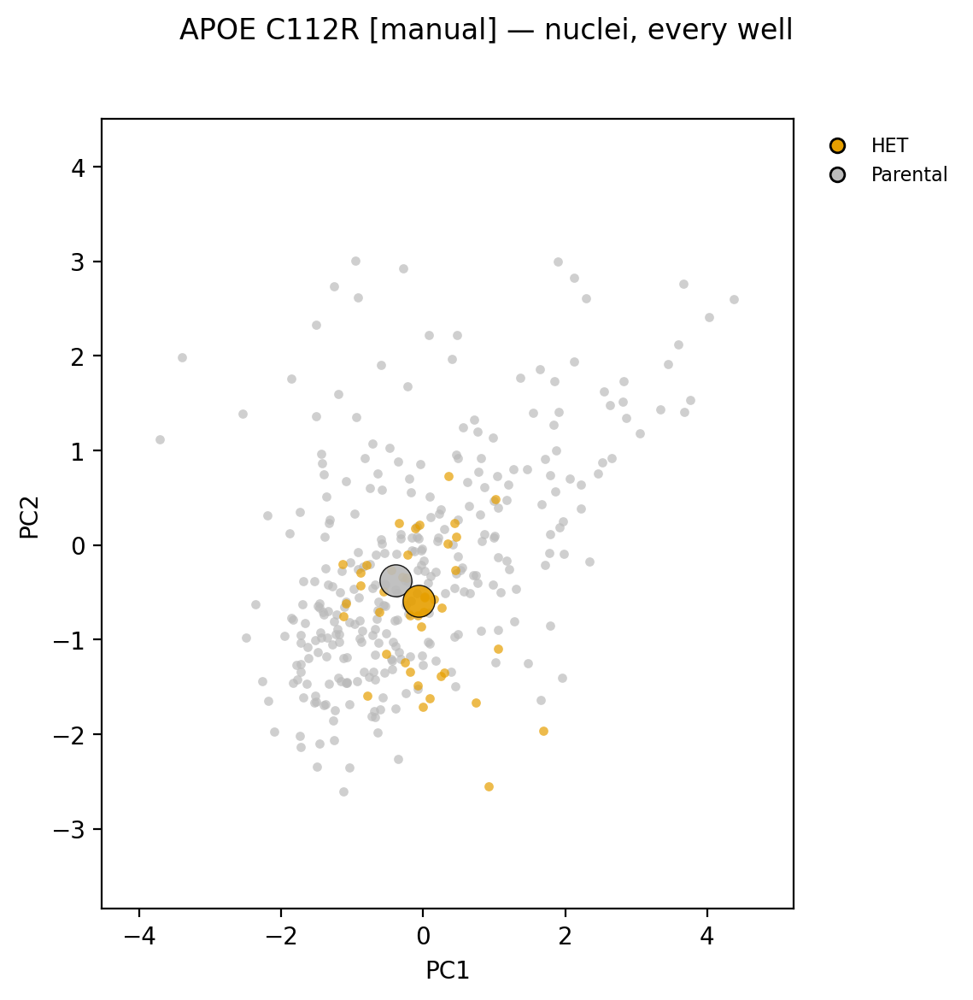

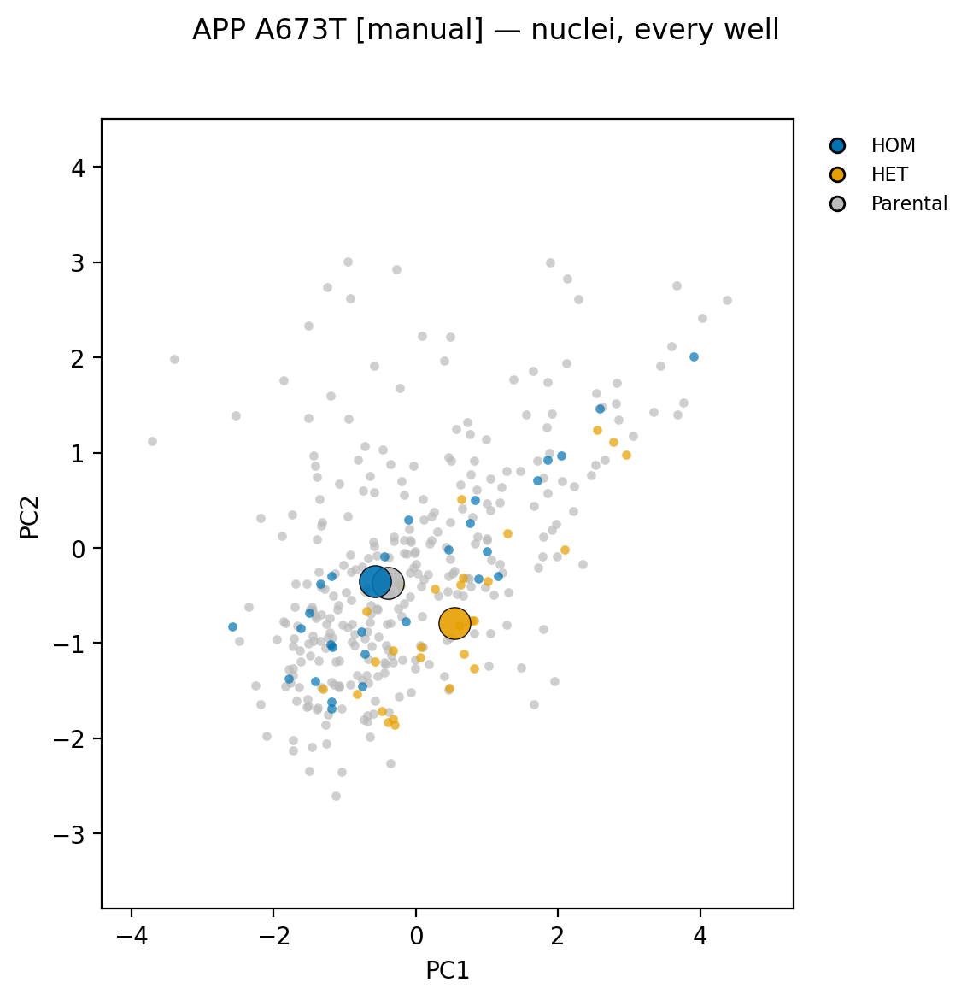

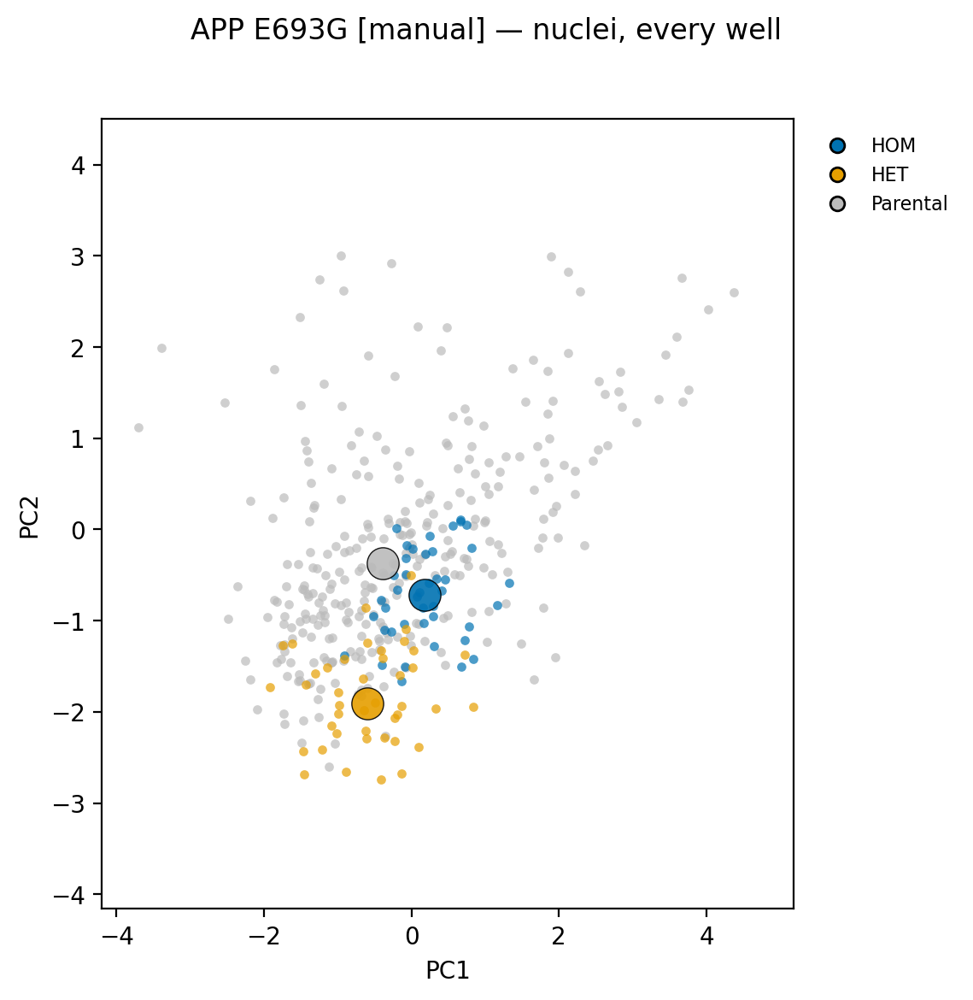

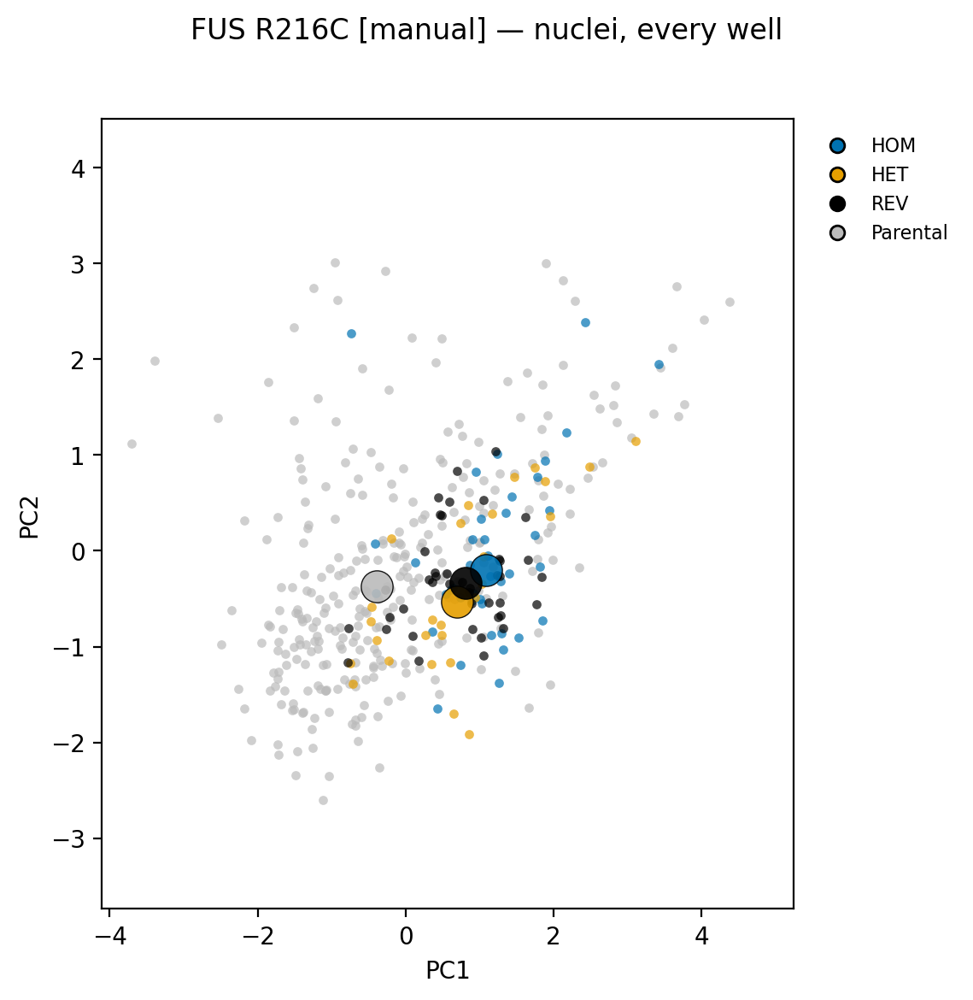

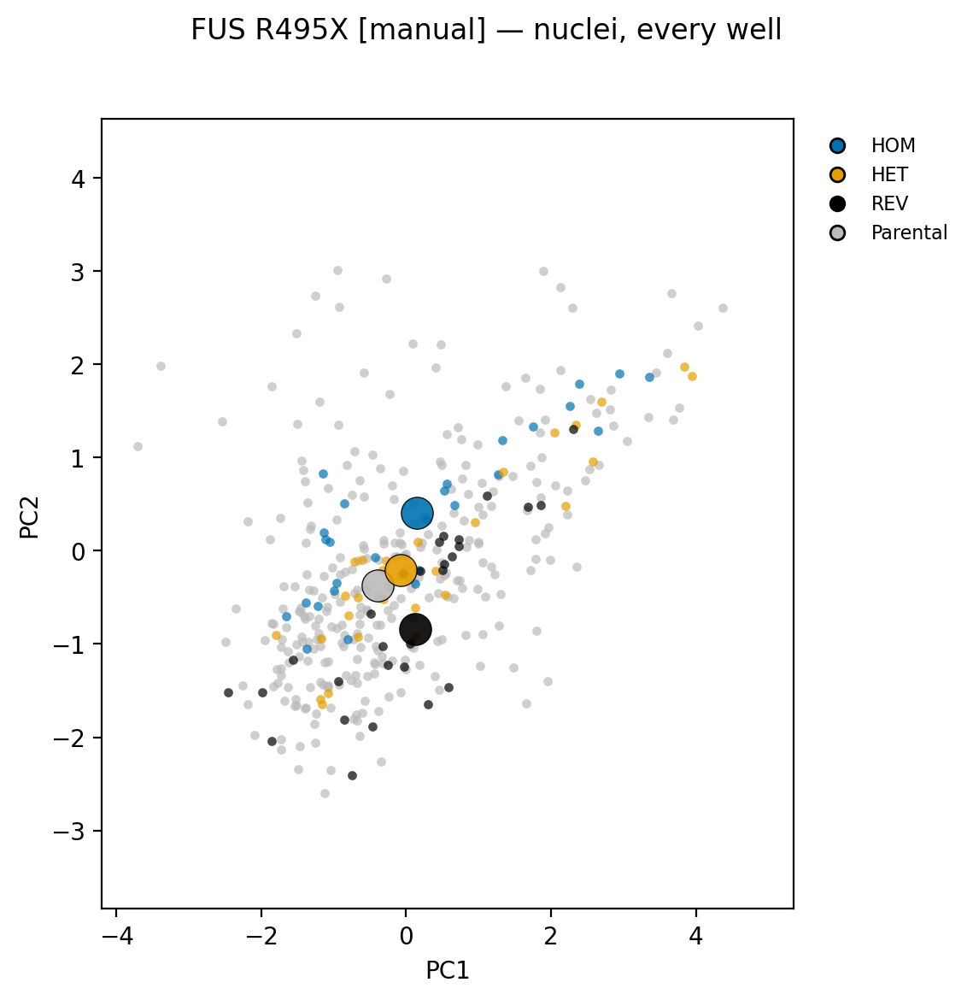

...

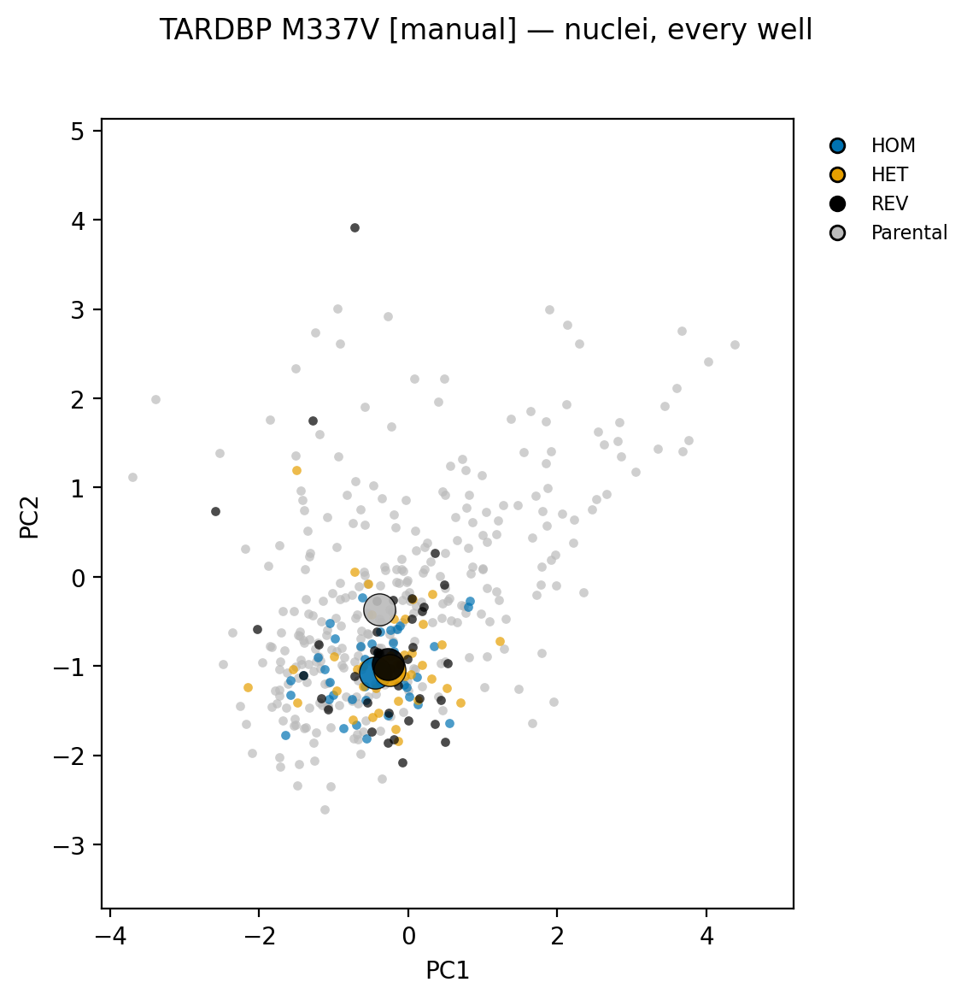

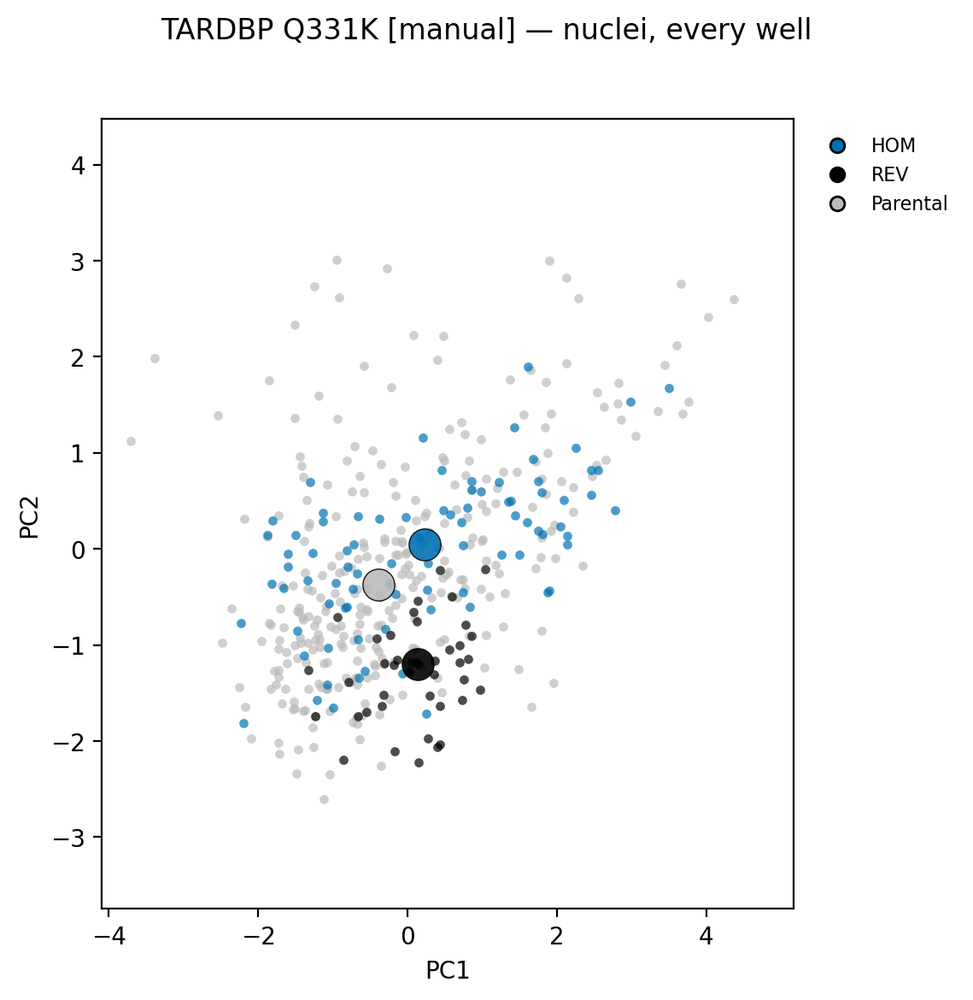

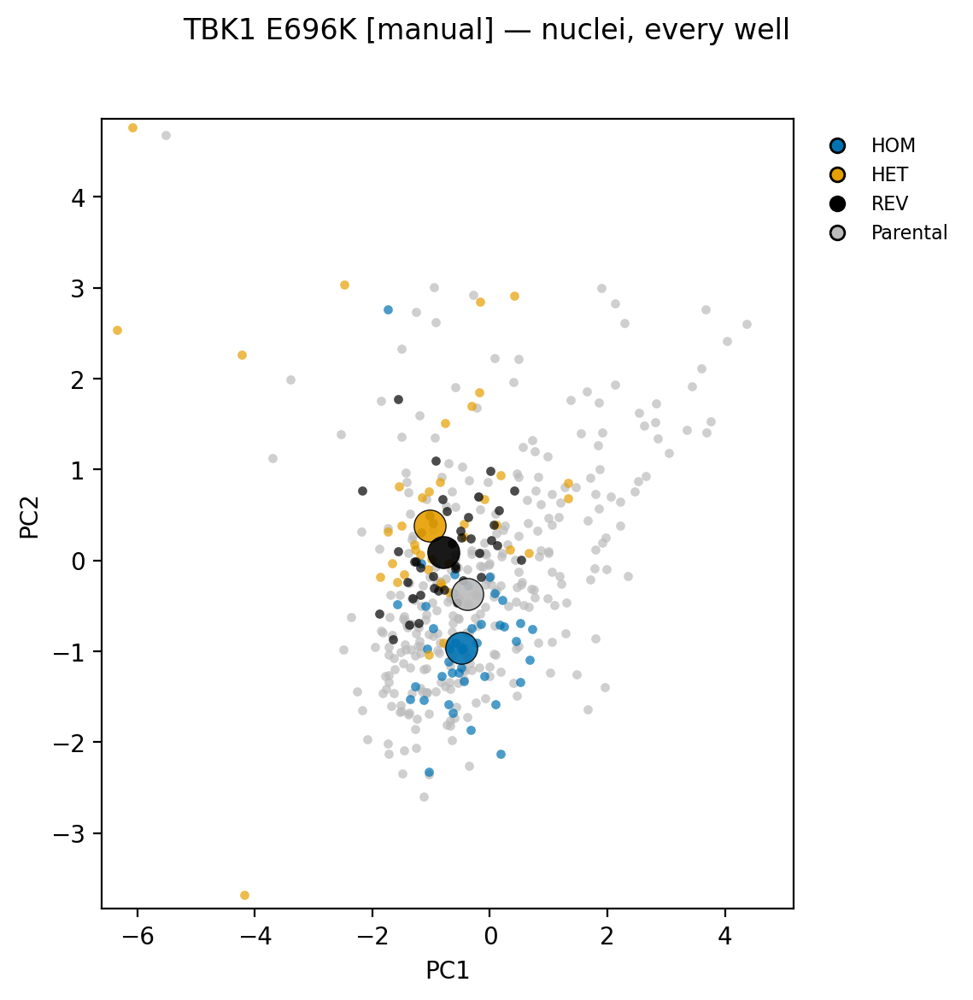

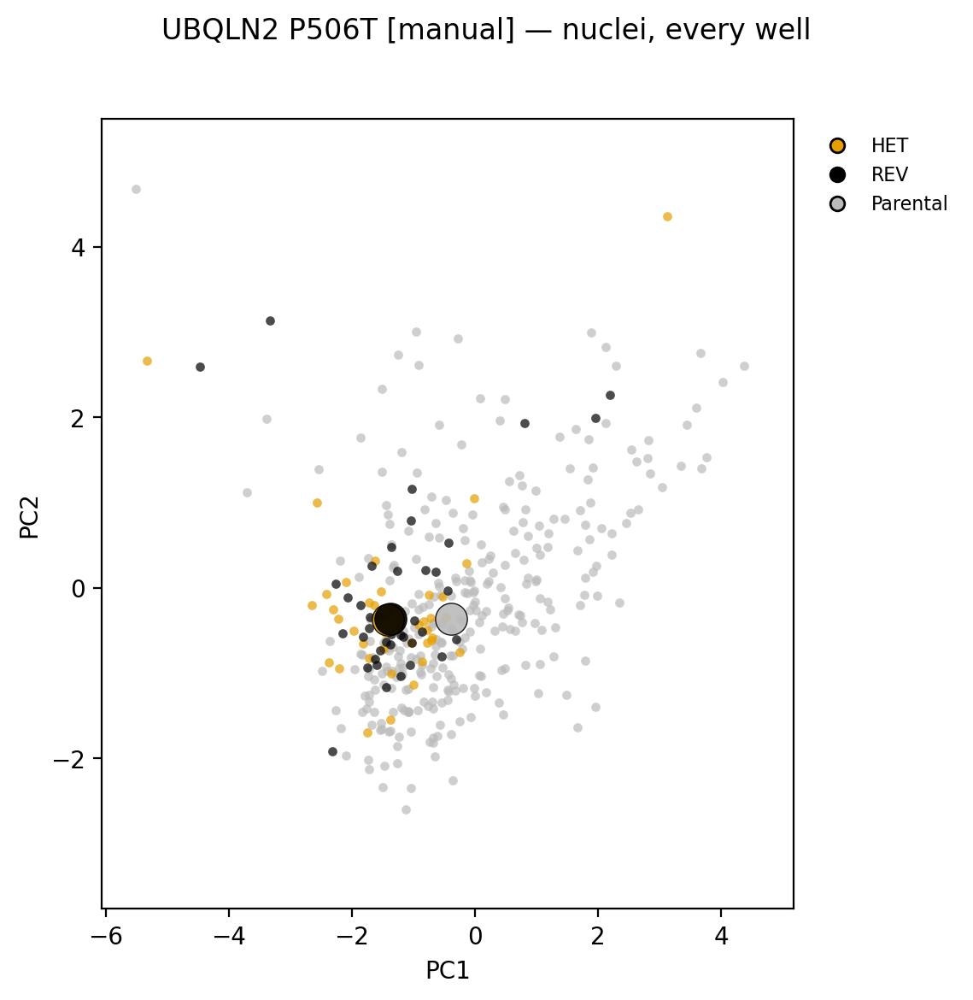

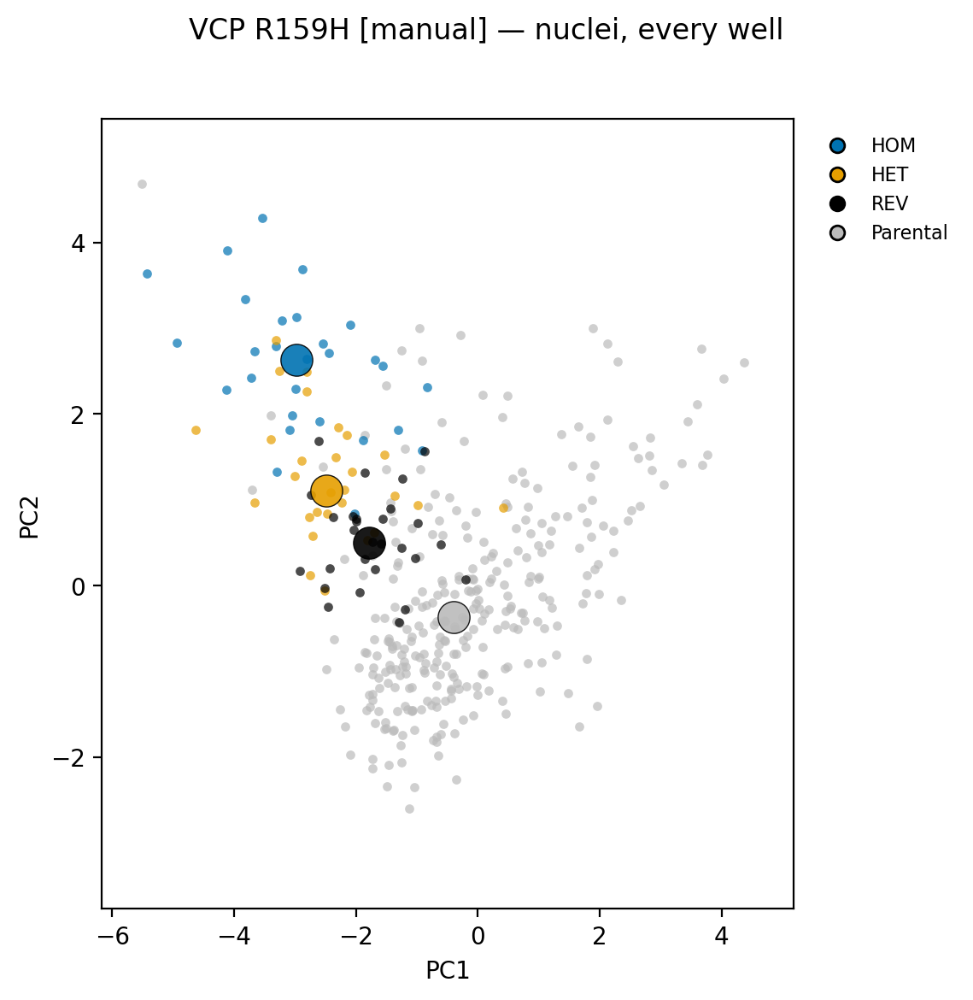


AUTOMATED (3740 wells)


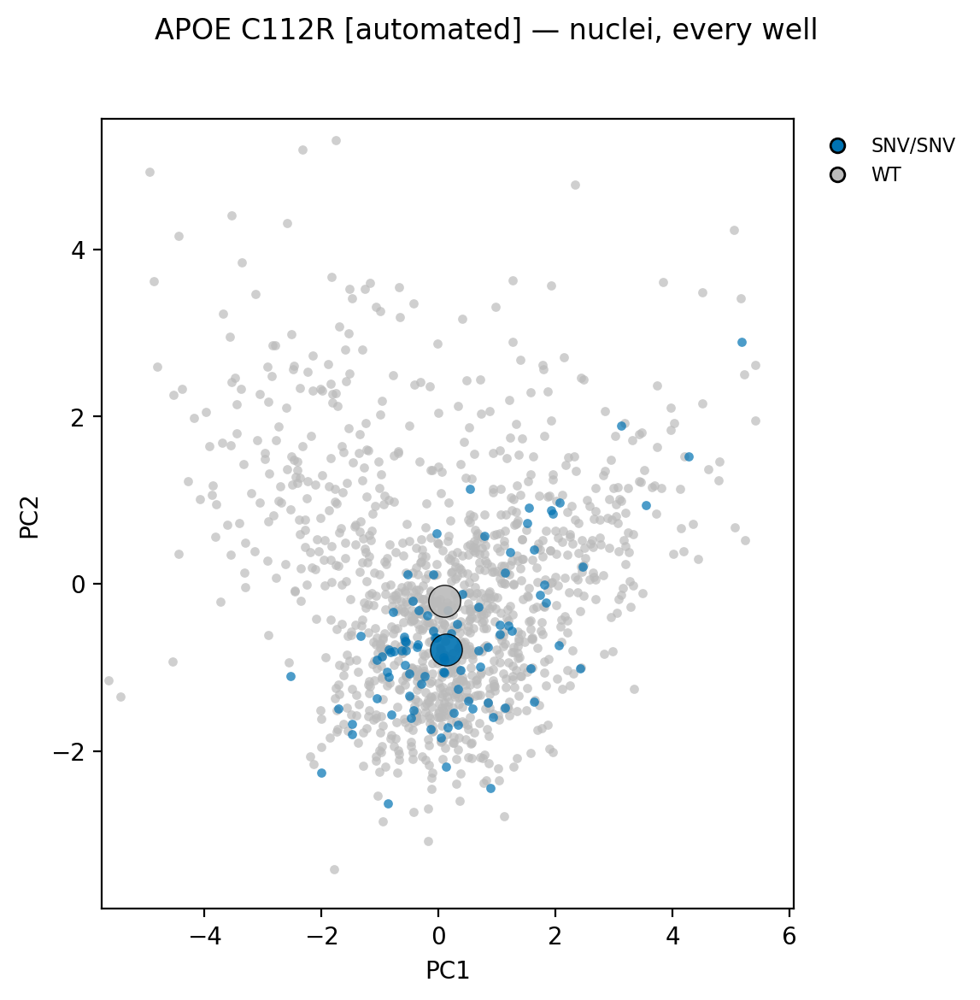

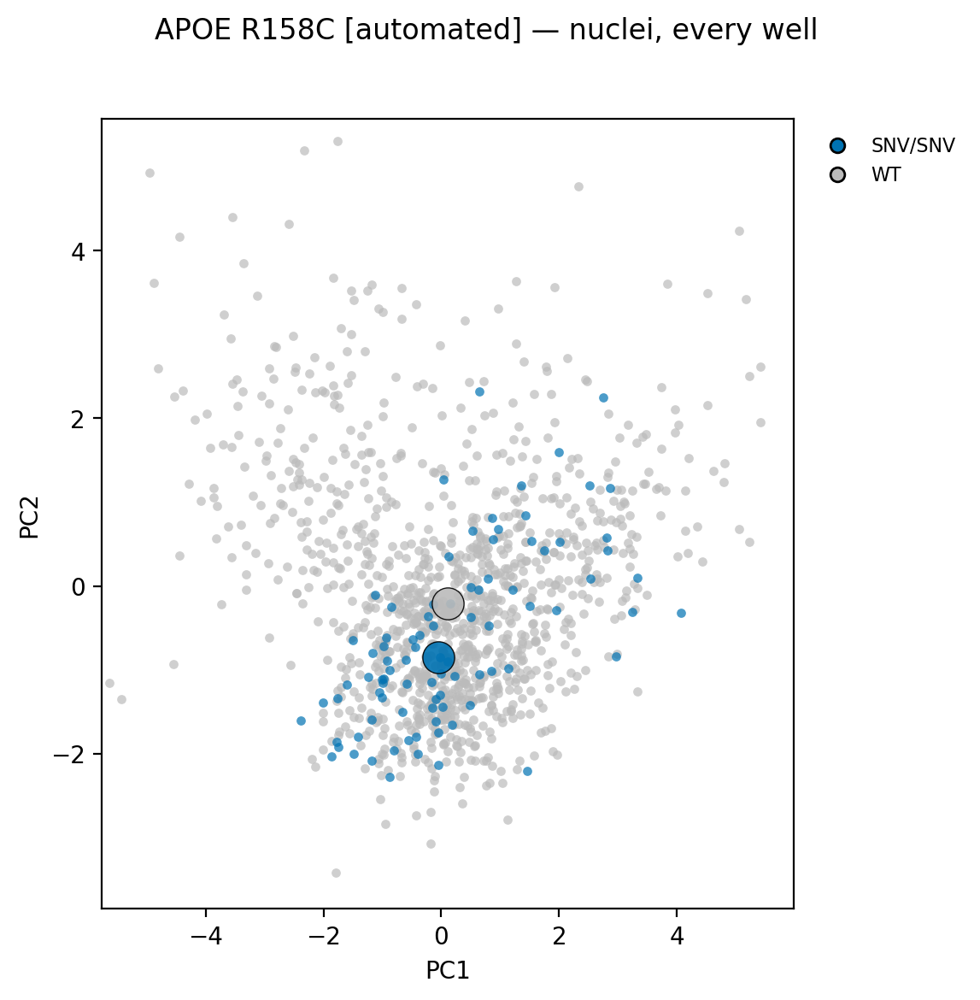

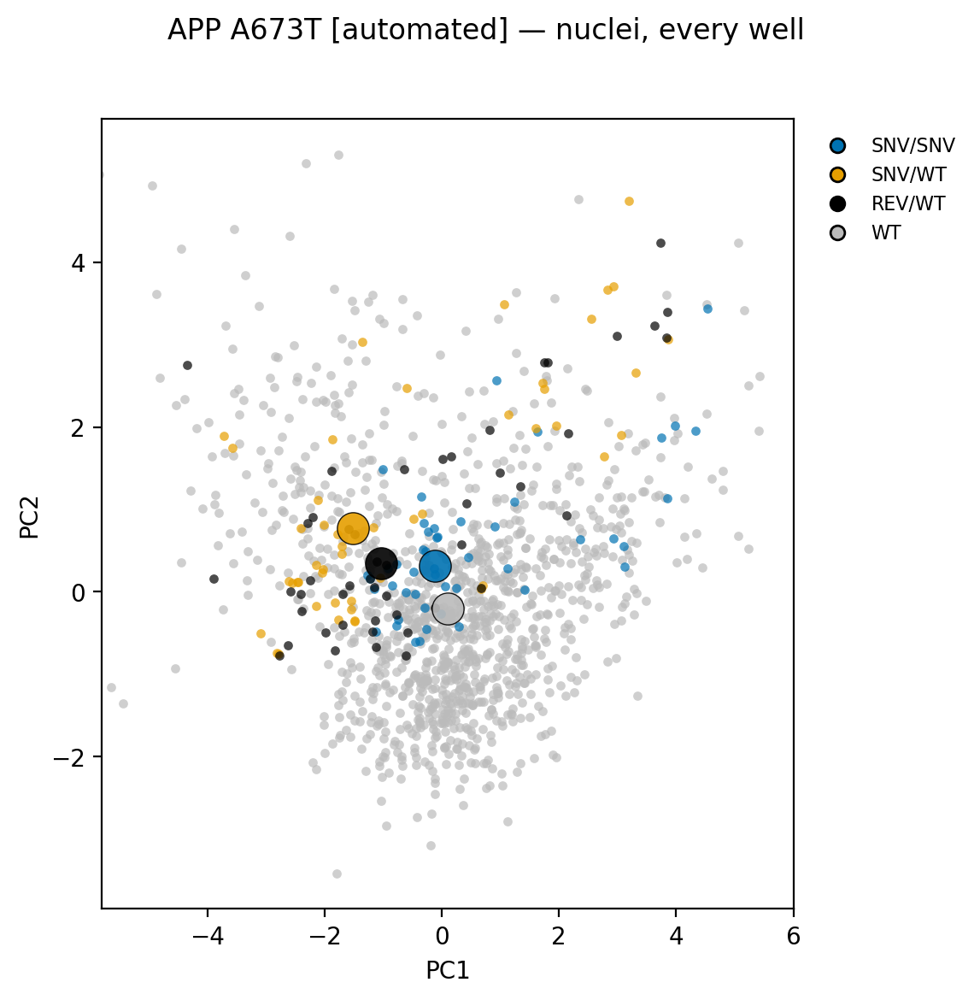

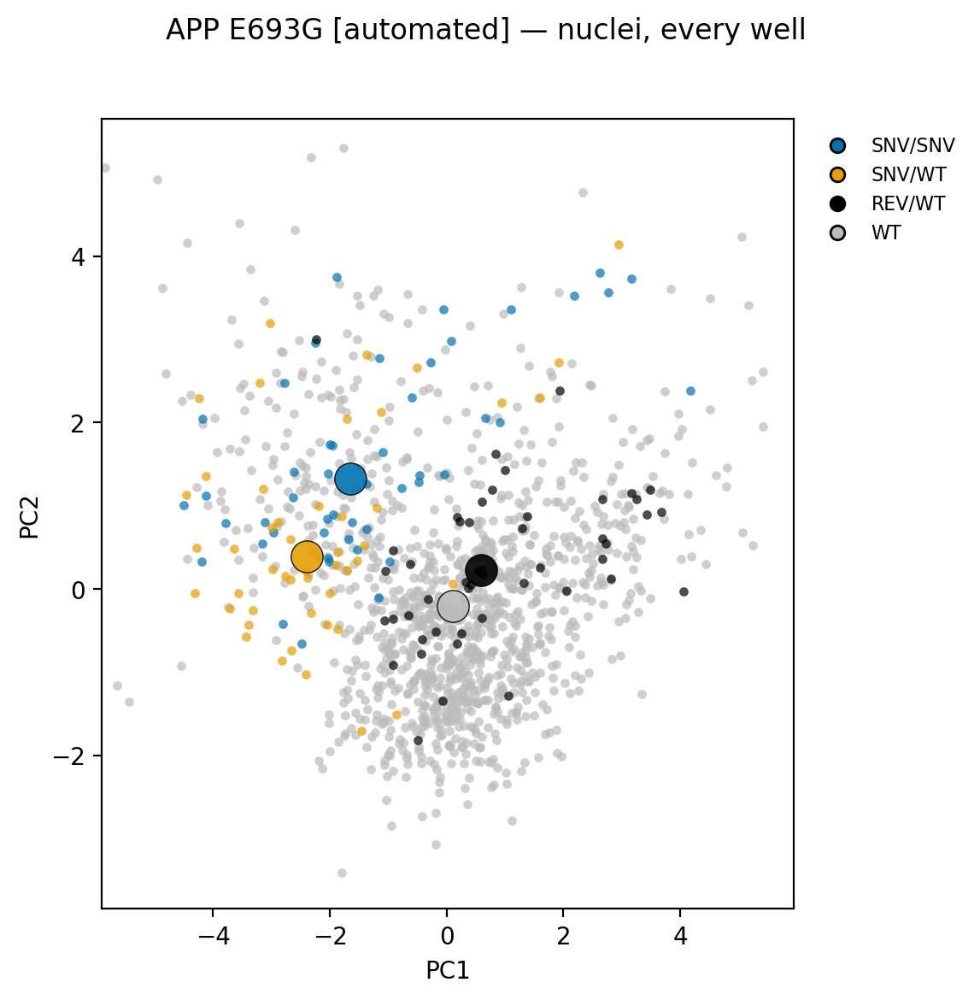

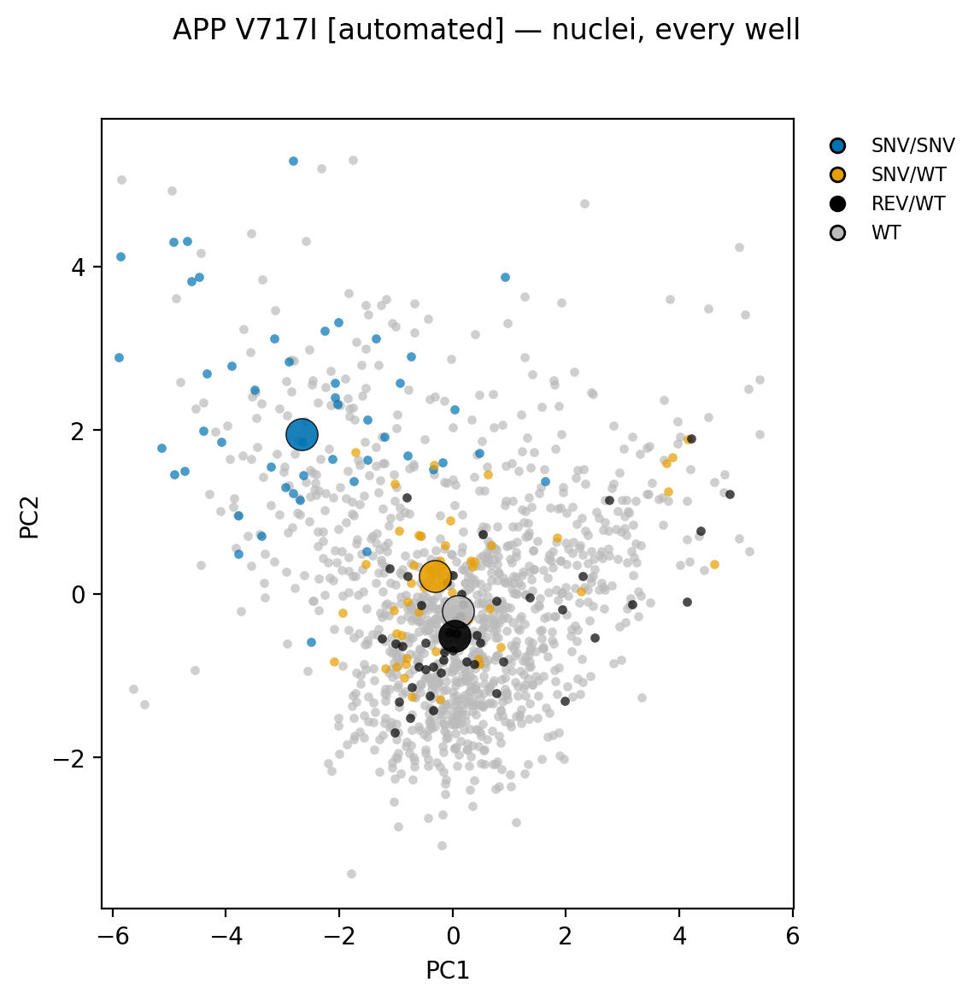

...

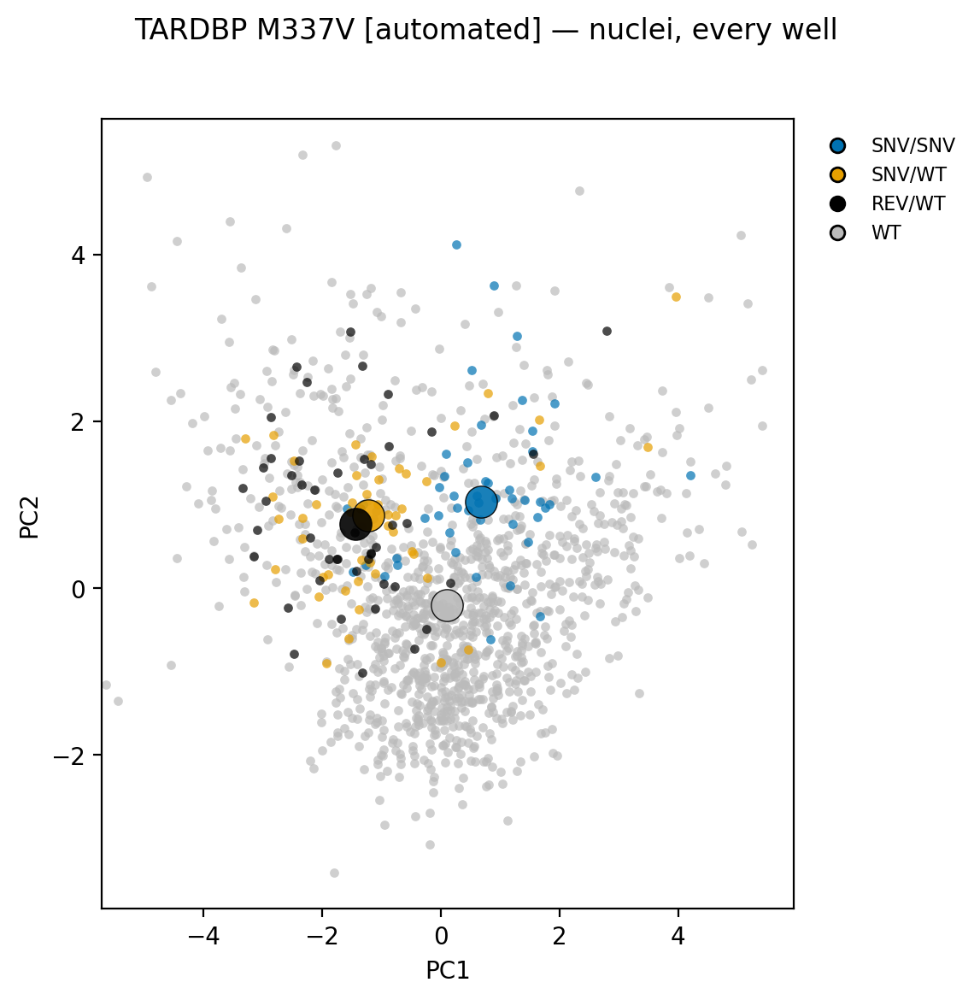

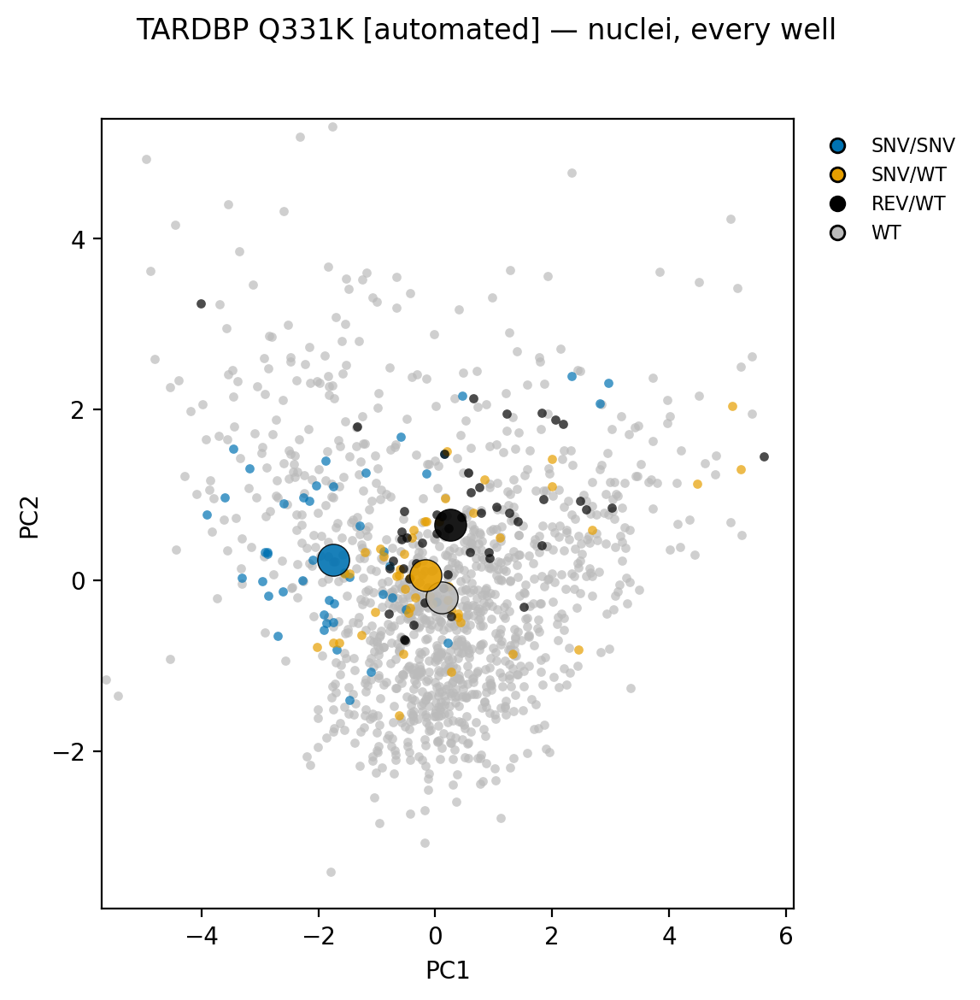

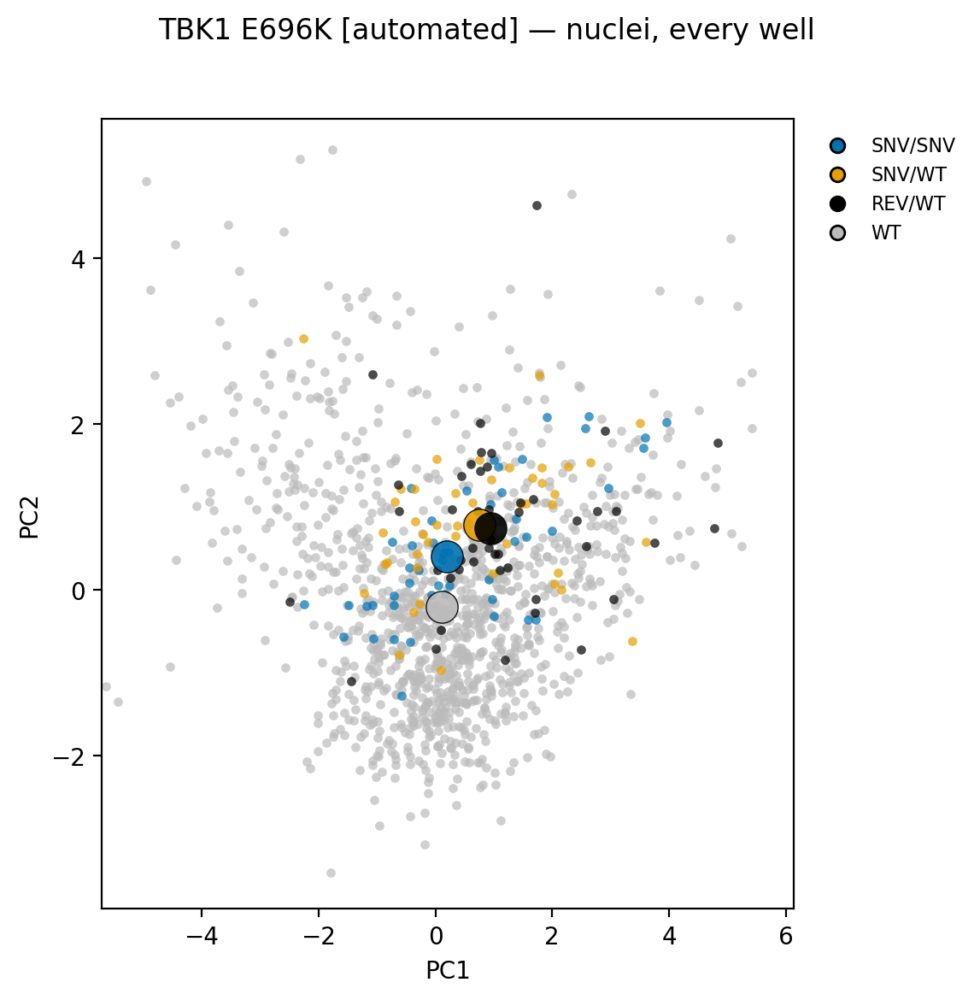

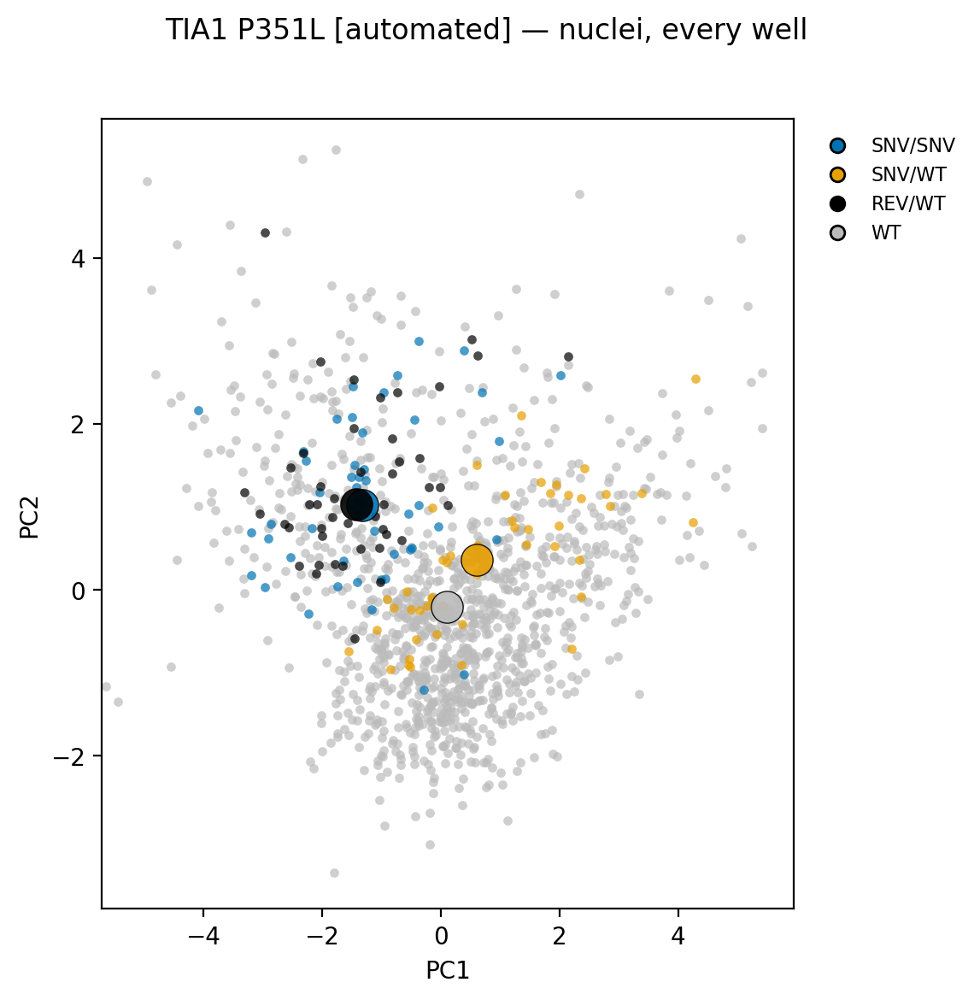

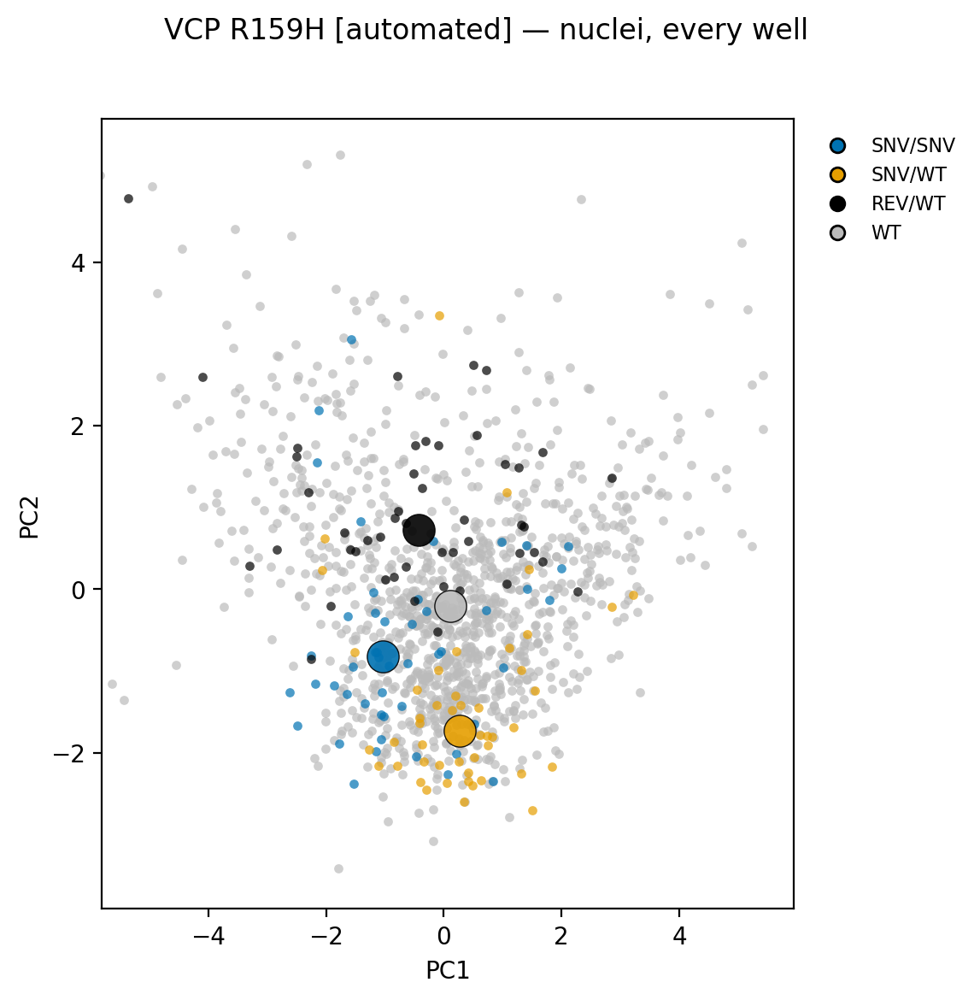

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==========================================================================
# Prep split
# ==========================================================================
PREP_COL = "Source"          # column tagging each well's prep
AUTOMATED_VAL = "automated"
MANUAL_VAL = "manual"

# ==========================================================================
# Group-specific schemes
# ==========================================================================
# --- Manual: parental by Genotype_Name == "Parental"; genotype is the trailing
#     token of Genotype_Name (HOM / HET / REV). -----------------------------
MANUAL_PARENTAL_NAME = "Parental"
MANUAL_COLORS = {
    "Parental": "#BBBBBB", "HET": "#E69F00", "HOM": "#0072B2",
    "REV": "#000000", "OTHER": "#F0E442",
}
MANUAL_ORDER = ["HOM", "HET", "REV", "Parental"]
MANUAL_PARENTAL_KEY = "Parental"

def _manual_is_parental(df):
    return (df["Genotype_Name"].astype(str).str.strip().str.upper()
            == MANUAL_PARENTAL_NAME.upper())

def _manual_color_key(df):
    name = df["Genotype_Name"].astype(str).str.strip()
    zyg = name.str.split().str[-1].str.upper()        # HOM / HET / REV
    return np.where(_manual_is_parental(df), MANUAL_PARENTAL_KEY, zyg)

def _manual_has_mutant(nonpar_keys):
    return nonpar_keys.isin(["HOM", "HET"]).any()

# --- Automated: parental by Gene == "KOLF2.1J"; genotype from the Genotype
#     column (SNV/SNV, SNV/WT, SNV/Y, ...). ---------------------------------
AUTO_WT_GENE = "KOLF2.1J"
AUTO_COLORS = {
    "WT": "#BBBBBB", "SNV/WT": "#E69F00", "SNV/SNV": "#0072B2",
    "REV/WT": "#000000", "SNV/Y": "#009E73", "REV/Y": "#CC79A7",
    "OTHER": "#F0E442",
}
AUTO_ORDER = ["SNV/SNV", "SNV/WT", "SNV/Y", "REV/WT", "REV/Y", "WT"]
AUTO_PARENTAL_KEY = "WT"

def _auto_is_parental(df):
    return (df["Gene"].astype(str).str.strip().str.upper()
            == AUTO_WT_GENE.upper())

def _auto_color_key(df):
    return np.where(_auto_is_parental(df), AUTO_PARENTAL_KEY,
                    df["Genotype"].astype(str).str.strip())

def _auto_has_mutant(nonwt_keys):
    return nonwt_keys.str.startswith("SNV").any()

SCHEMES = {
    "manual": {
        "label": "manual", "is_parental": _manual_is_parental,
        "color_key": _manual_color_key, "colors": MANUAL_COLORS,
        "order": MANUAL_ORDER, "parental_key": MANUAL_PARENTAL_KEY,
        "has_mutant": _manual_has_mutant,
    },
    "automated": {
        "label": "automated", "is_parental": _auto_is_parental,
        "color_key": _auto_color_key, "colors": AUTO_COLORS,
        "order": AUTO_ORDER, "parental_key": AUTO_PARENTAL_KEY,
        "has_mutant": _auto_has_mutant,
    },
}


# ==========================================================================
# Figure: single-panel PCA for one allele (nucleus-level, no faceting)
# ==========================================================================
def variant_pca(
    df, gene, variant, scheme, pcx="PC1", pcy="PC2", title=None, pad=1.5,
    parental=None, s=15, alpha=0.7, s_centroid=180, figsize=(6, 6),
):
    """Single PCA panel for one (gene, variant), using `scheme` for color keys,
    palette, and ordering. `parental` is the pooled parental reference."""
    colors = scheme["colors"]
    order = scheme["order"]
    par_key = scheme["parental_key"]

    src = df[(df["Gene"] == gene) & (df["Variant"] == variant)].copy()
    if parental is not None and not parental.empty:
        src = pd.concat([src, parental], ignore_index=True)
    if src.empty:
        print(f"[skip] ({scheme['label']}) no rows for {gene} {variant}")
        return None

    src["_ckey"] = scheme["color_key"](src)

    nonpar = src.loc[src["_ckey"] != par_key, "_ckey"]
    has_mutant = scheme["has_mutant"](nonpar)
    mutant_note = "" if has_mutant else "  [no mutant genotype — revertant only]"

    px, py = src[pcx].dropna(), src[pcy].dropna()
    if px.empty or py.empty:
        print(f"[skip] ({scheme['label']}) no finite PC values for {gene} {variant}")
        return None
    x_lo, x_hi = px.quantile(.01) - pad, px.quantile(.99) + pad
    y_lo, y_hi = py.quantile(.01) - pad, py.quantile(.99) + pad

    all_keys = list(pd.unique(src["_ckey"]))
    unknown = [k for k in all_keys if k not in colors]
    if unknown:
        print(f"[warning] ({scheme['label']}) {gene} {variant}: genotype(s) "
              f"not in palette, drawn as OTHER: {unknown}")
    keys_present = ([k for k in order if k in all_keys]
                    + [k for k in all_keys if k not in order])
    draw_order = ([k for k in keys_present if k == par_key]
                  + [k for k in keys_present if k != par_key])

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    fig.subplots_adjust(right=0.80)

    for k in draw_order:                        # clouds: parental bottom
        gg = src[src["_ckey"] == k]
        ax.scatter(gg[pcx], gg[pcy], s=s, alpha=alpha,
                   color=colors.get(k, colors["OTHER"]),
                   linewidths=0, rasterized=True)
    for k in draw_order:                         # centroids
        gg = src[src["_ckey"] == k]
        if gg.empty:
            continue
        ax.scatter(gg[pcx].median(), gg[pcy].median(), s=s_centroid,
                   color=colors.get(k, colors["OTHER"]),
                   edgecolor="k", linewidths=0.5, alpha=0.9, zorder=5)

    ax.set_xlim(x_lo, x_hi); ax.set_ylim(y_lo, y_hi)
    ax.set_xlabel(pcx); ax.set_ylabel(pcy)

    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=6,
               markerfacecolor=colors.get(k, colors["OTHER"]),
               markeredgecolor="k", label=k)
        for k in keys_present
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0),
              frameon=False, fontsize=8)

    fig.suptitle((title or f"{gene} {variant} [{scheme['label']}] — nuclei, "
                  f"every well") + mutant_note, y=0.98)
    plt.show()
    return fig


# ==========================================================================
# Driver: run each prep group independently with its own scheme.
# ==========================================================================
def run_group(well_df, scheme):
    print(f"\n{'=' * 60}\n{scheme['label'].upper()} ({len(well_df)} wells)\n{'=' * 60}")

    is_par = scheme["is_parental"](well_df)
    parental_all = well_df[is_par].copy()

    variants = (well_df.loc[~is_par, ["Gene", "Variant"]]
                .dropna().drop_duplicates().sort_values(["Gene", "Variant"]))

    for gene, variant in variants.itertuples(index=False):
        variant_pca(well_df, gene, variant, scheme, parental=parental_all)


well_df = well_level

# Manual-only fixup from the previous manual driver.
well_df.loc[
    well_df["Genotype_Name"].astype(str).str.strip() == "TBK1 E696K HOM",
    "Variant",
] = "E696K"

prep = well_df[PREP_COL].astype(str).str.strip().str.lower()

run_group(well_df[prep == MANUAL_VAL.lower()].copy(),    SCHEMES["manual"])
run_group(well_df[prep == AUTOMATED_VAL.lower()].copy(), SCHEMES["automated"])

## Automated analysis
### Feature assessment and loadings

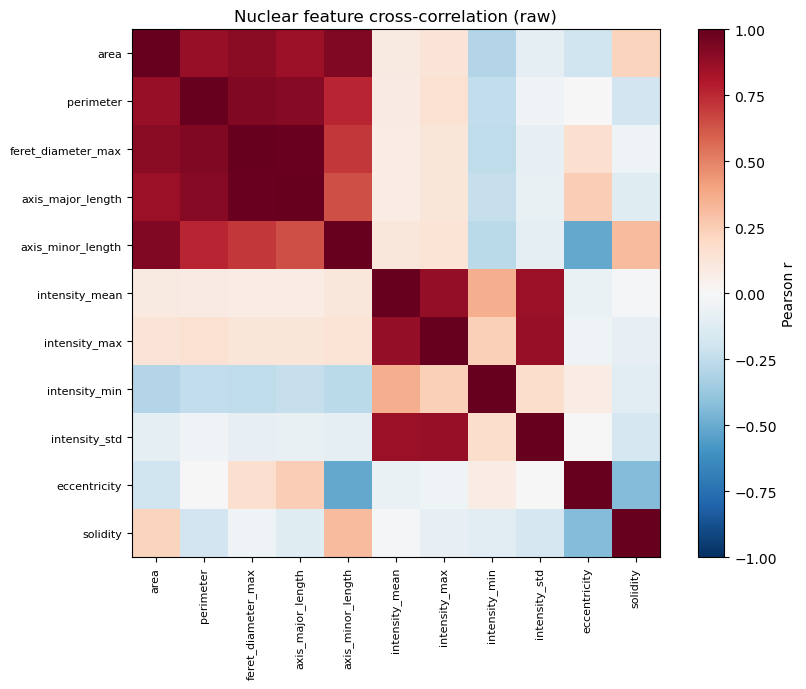

Highly correlated pairs (|r| > 0.9):
  +0.987  feret_diameter_max     axis_major_length
  +0.926  perimeter              feret_diameter_max
  +0.925  area                   axis_minor_length
  +0.909  perimeter              axis_major_length
[full] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full] dropped 0 rows with NaN/inf; 581000 remain
[full] EVR: [0.399 0.314 0.157 0.107 0.018 0.005]
[full] cumulative: [0.399 0.713 0.87  0.977 0.995 1.   ]


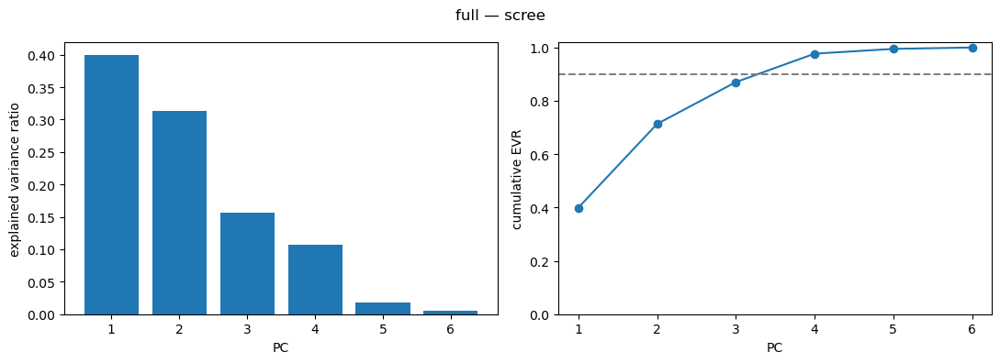

                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.250 -0.005  0.927 -0.248  0.127  0.013
intensity_mean  0.030  0.700  0.124  0.124 -0.692 -0.011
intensity_std  -0.060  0.704 -0.066  0.038  0.704  0.011
eccentricity   -0.600 -0.059  0.235  0.316  0.002  0.694
solidity        0.448 -0.096  0.100  0.876  0.097 -0.054
aspect_ratio    0.610  0.050 -0.234 -0.234 -0.019  0.718


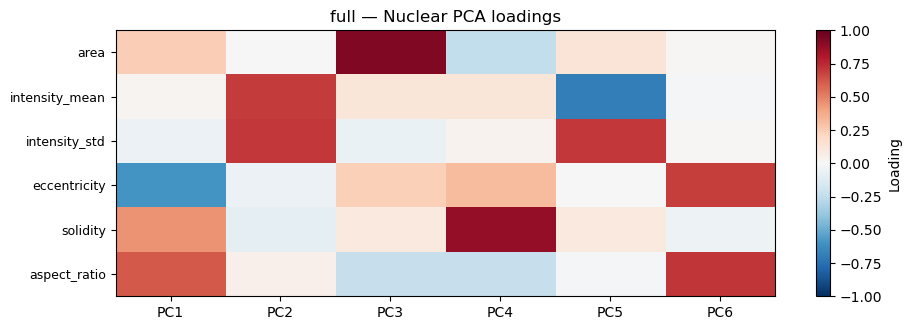

In [31]:
df_auto = df[df["Source"] == "automated"]
feature_correlation(df_auto)
df_auto, pca, FEATURES = fit_pca(df_auto, label="full")

### PCA plots - ROI-level

All 13 iNDI_Plate_ID values have a color.


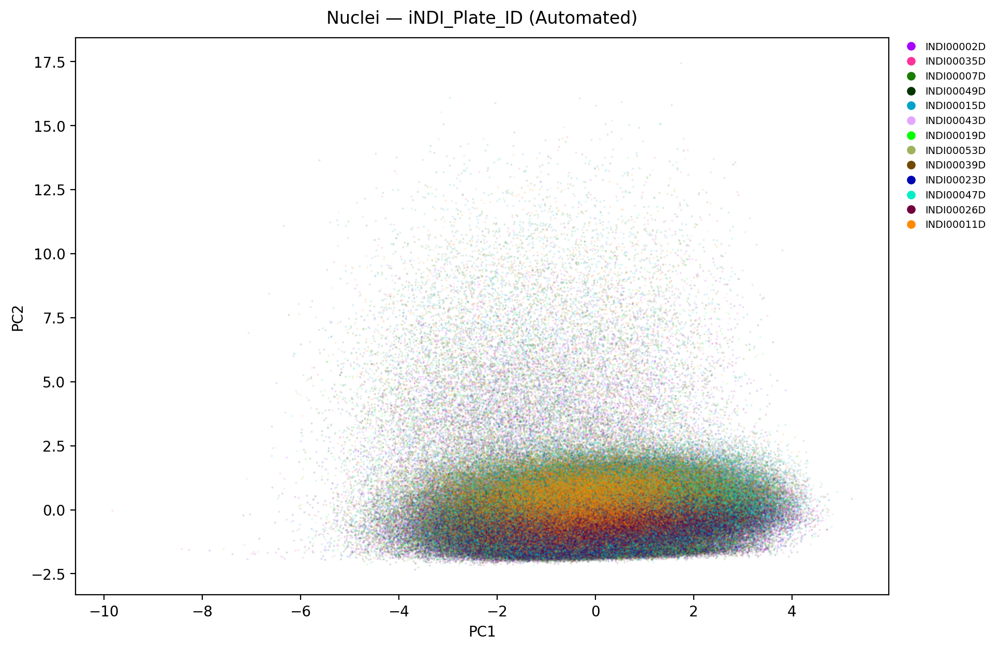

All 4 Batch values have a color.


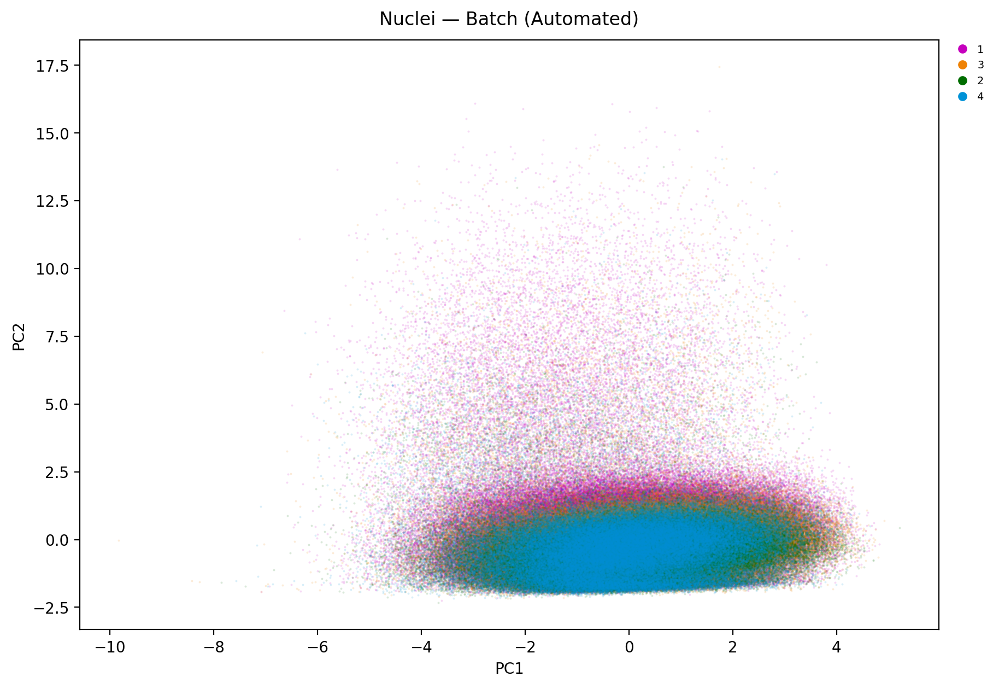

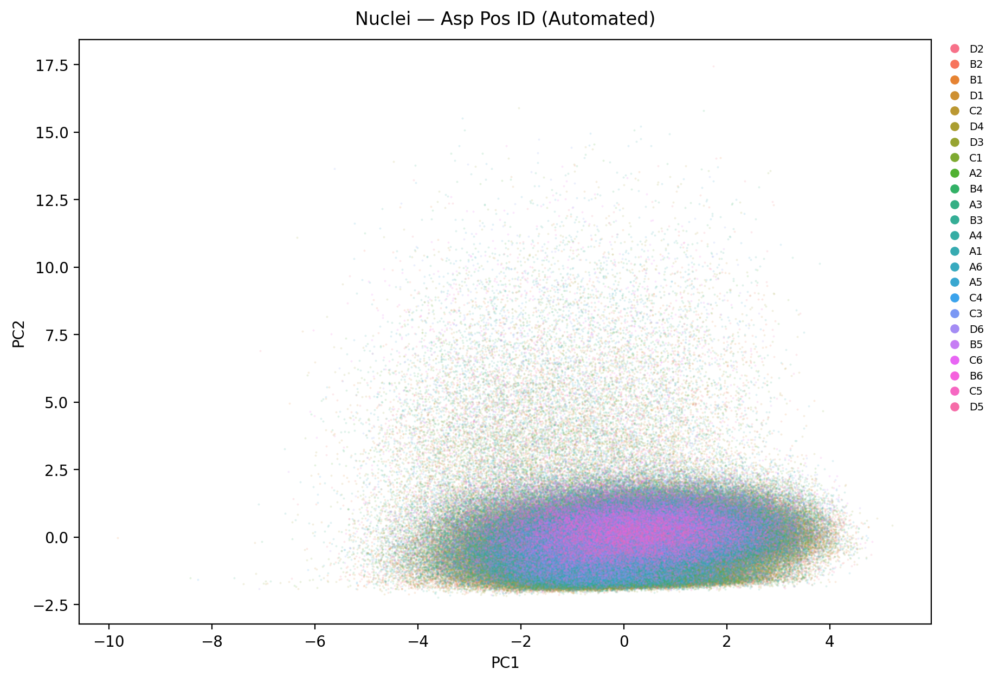

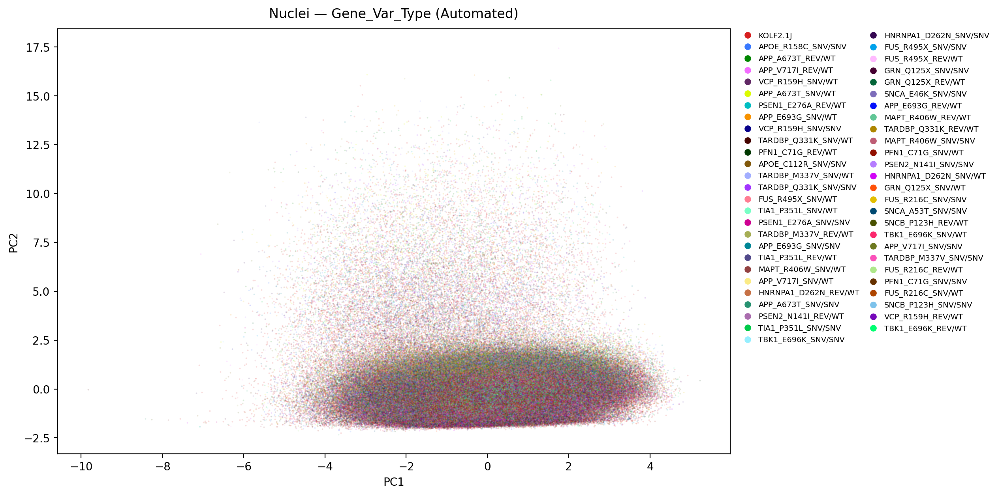

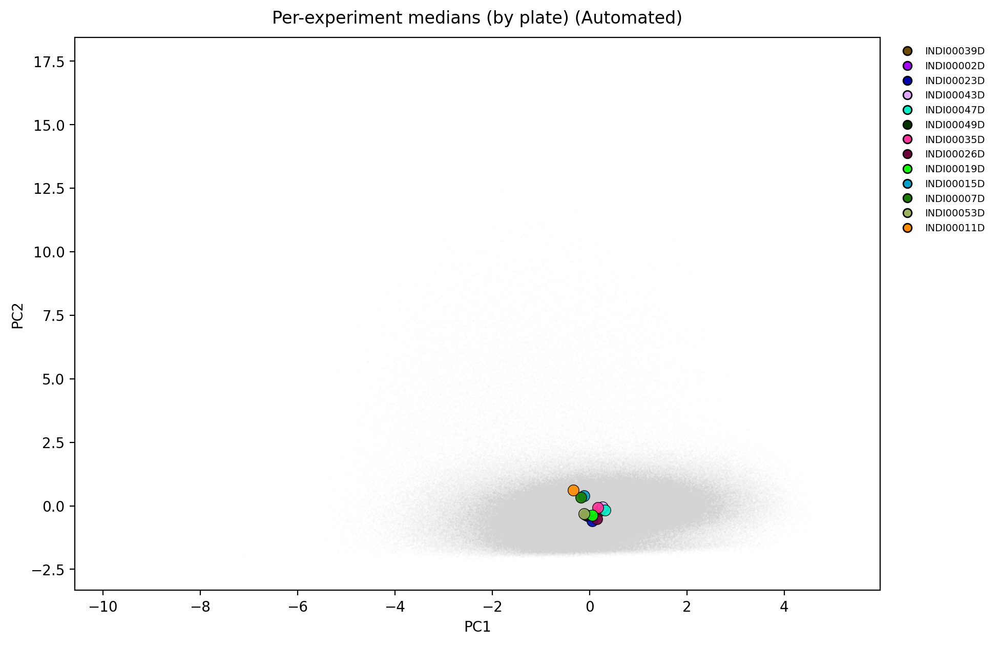

Std of per-experiment centroids (batch magnitude):
PC1    0.193
PC2    0.368
PC3    0.146
dtype: float64


In [32]:
plate_pal = make_palette(df_auto["iNDI_Plate_ID"])
check_palette_coverage(df_auto, "iNDI_Plate_ID", plate_pal)
pca_scatter(df_auto, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID (Automated)")

batch_palette = make_palette(df_auto["Batch"])
check_palette_coverage(df_auto, "Batch", batch_palette)
pca_scatter(df_auto, "Batch", palette=batch_palette, figsize=(12, 7),title="Nuclei — Batch (Automated)")

pca_scatter(df_auto, "Asp PosID", figsize=(12, 7),title="Nuclei — Asp Pos ID (Automated)")

pca_scatter(df_auto, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Nuclei — Gene_Var_Type (Automated)")

centroid_overlay(df_auto, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate) (Automated)")
cent = df_auto.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### PCA plots - well-level

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 119490 rows (13440 images)
[full] well-level: 3740 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 3740 remain
[full well] EVR: [0.472 0.286 0.143 0.068 0.028 0.003]
[full well] cumulative: [0.472 0.758 0.901 0.969 0.997 1.   ]


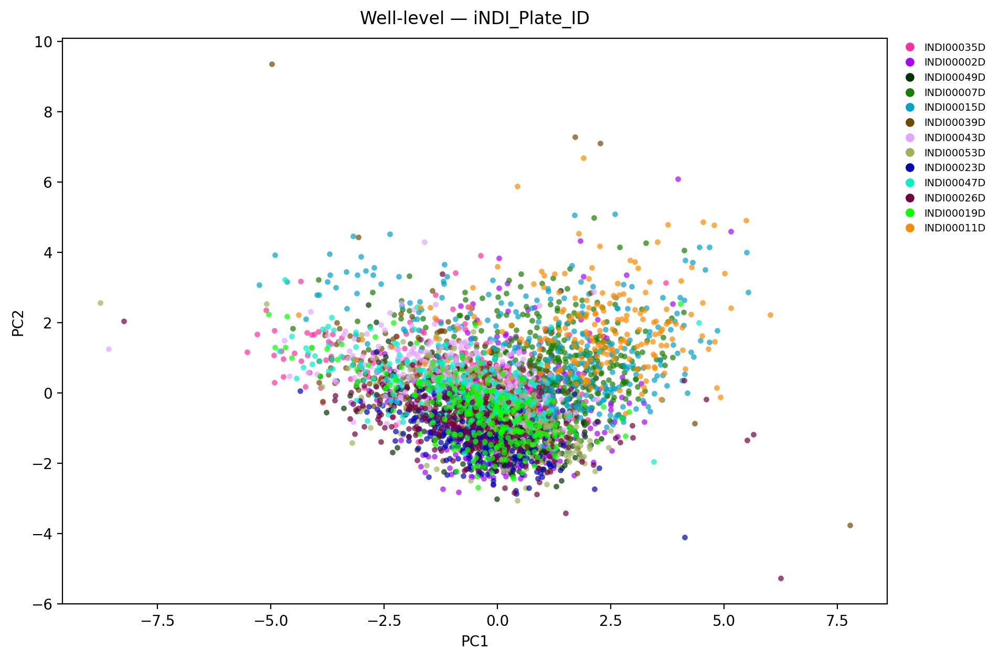

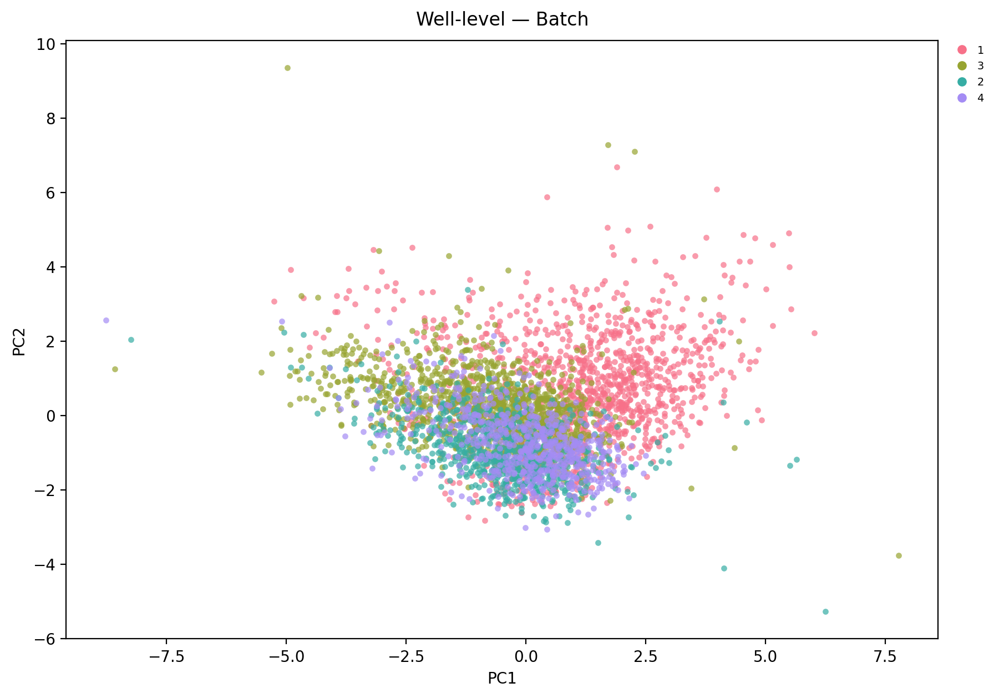

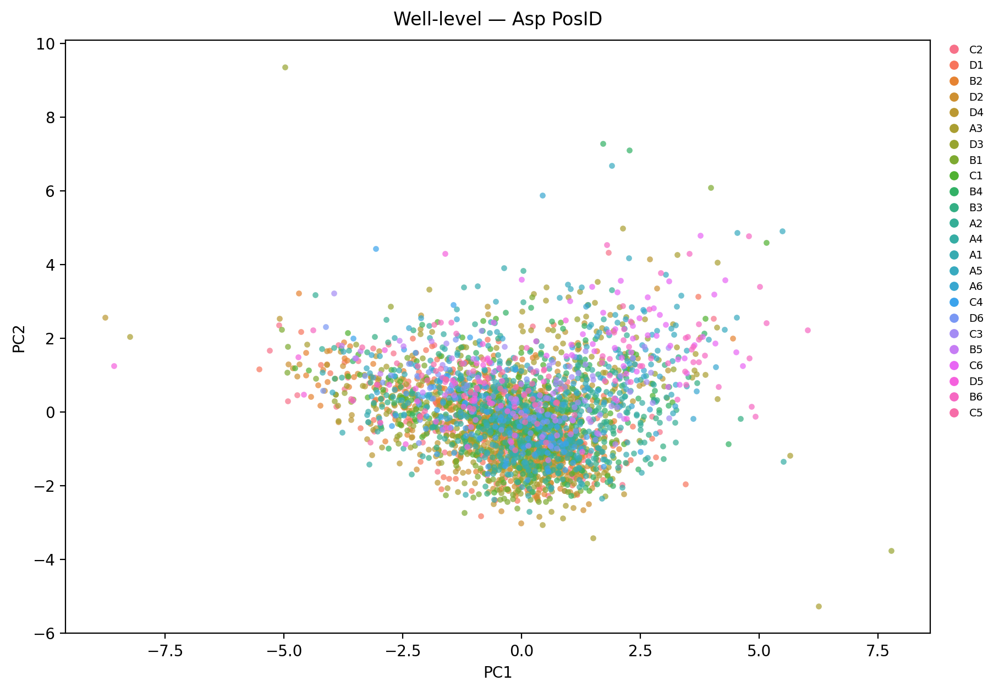

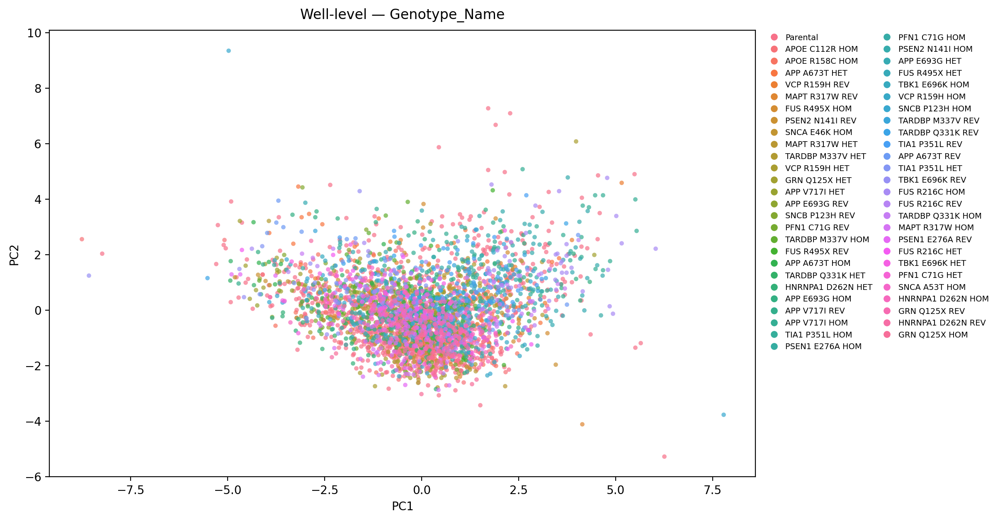

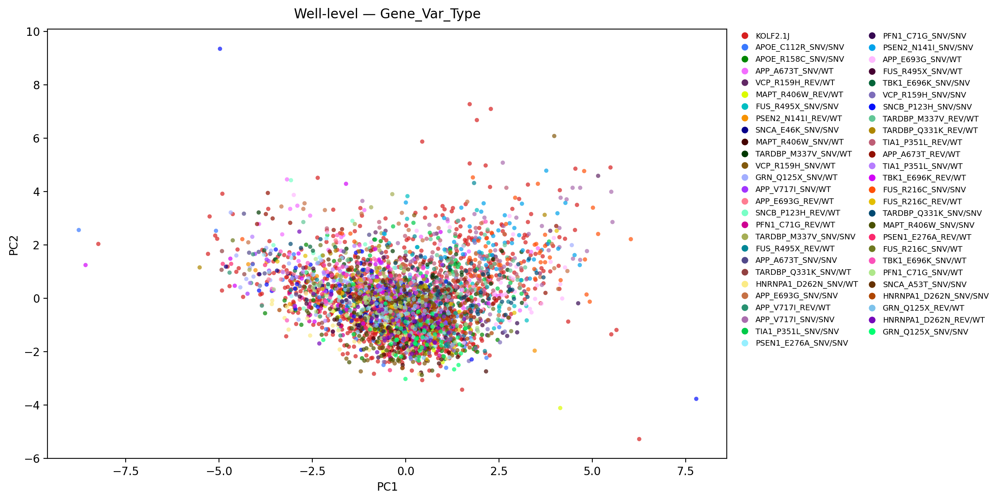

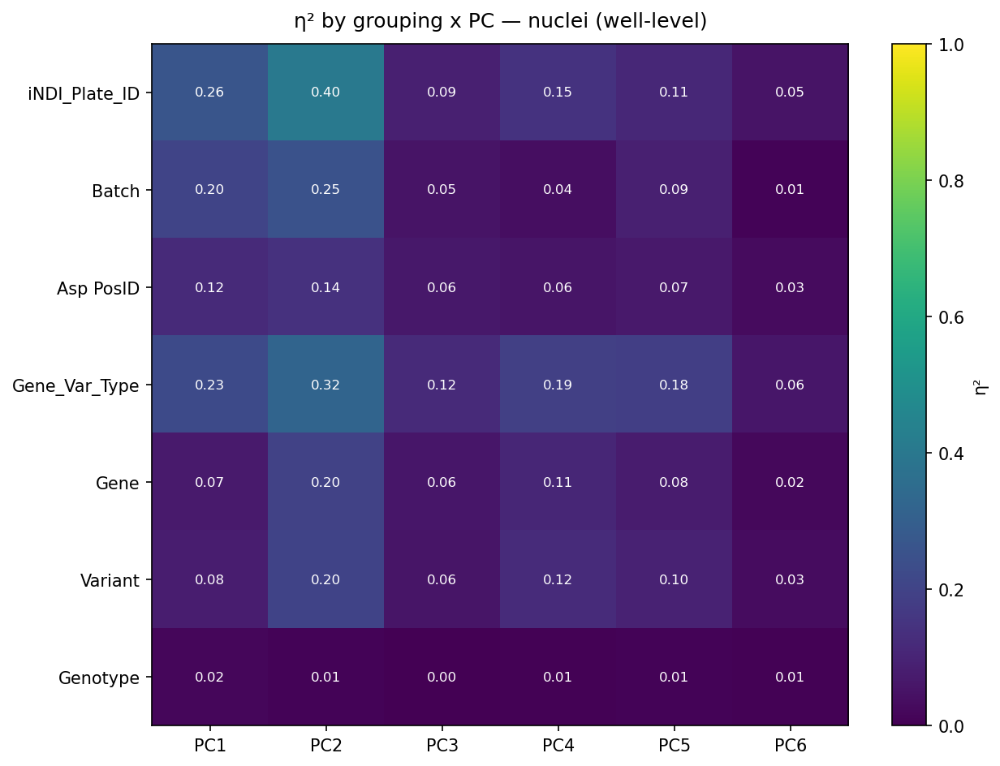

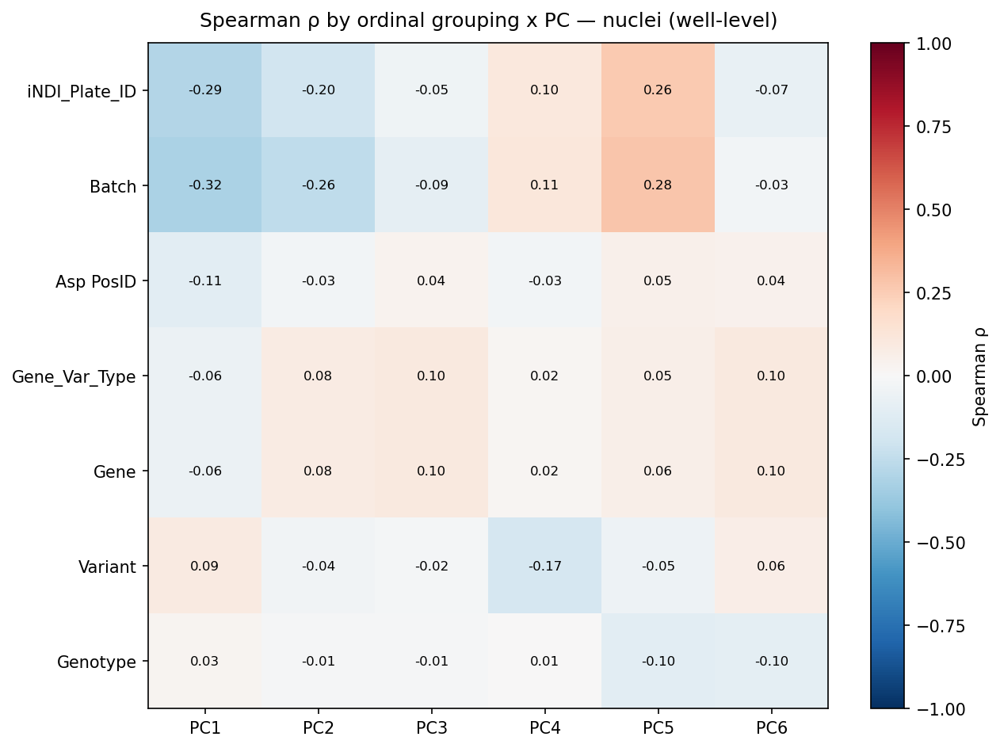

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,-0.289698,-0.195183,-0.045386,0.104723,0.264975,-0.072080
Batch,-0.317660,-0.255937,-0.087968,0.110364,0.277583,-0.029031
Asp PosID,-0.107419,-0.025019,0.037827,-0.025471,0.053395,0.043249
Gene_Var_Type,-0.059928,0.080963,0.097356,0.019031,0.054887,0.100358
Gene,-0.060635,0.084697,0.098733,0.021661,0.057760,0.099591
Variant,0.089678,-0.037123,-0.020367,-0.170499,-0.052999,0.063926
Genotype,0.028757,-0.013016,-0.011624,0.007642,-0.102024,-0.096751


In [33]:
well_level = aggregate_wells(df_auto, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

[facet] 21 (gene, variant) pairs; 1142 total KOLF2.1J rows (all folded into each facet)
  APOE / C112R: 93 variant + 1142 parental rows


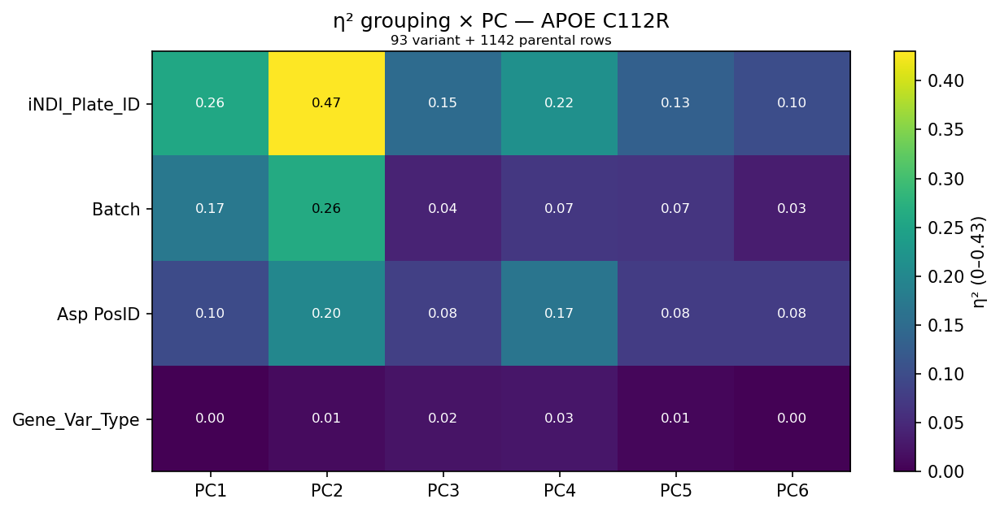

  APOE / R158C: 89 variant + 1142 parental rows


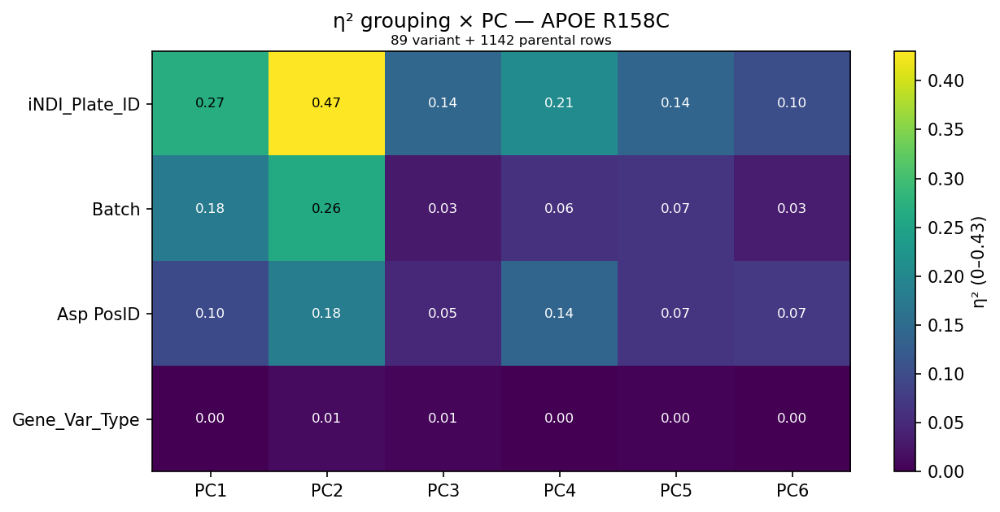

  APP / A673T: 144 variant + 1142 parental rows


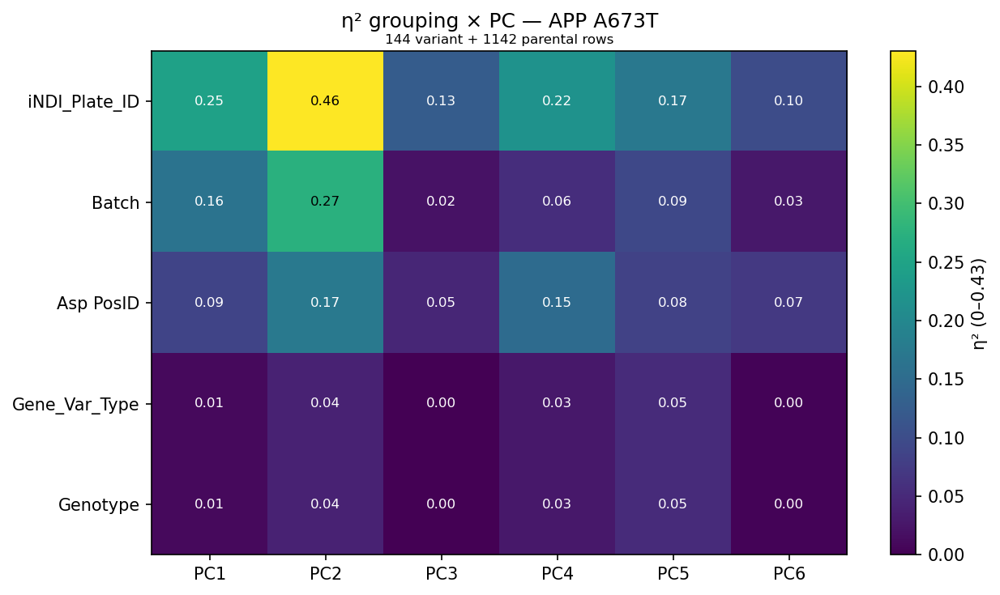

  APP / E693G: 144 variant + 1142 parental rows


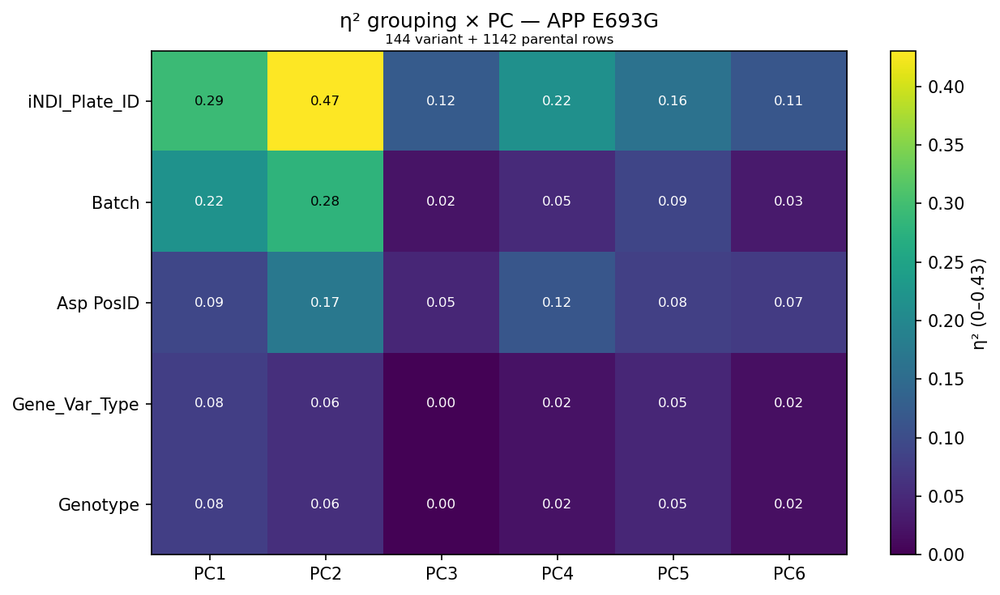

  APP / V717I: 144 variant + 1142 parental rows


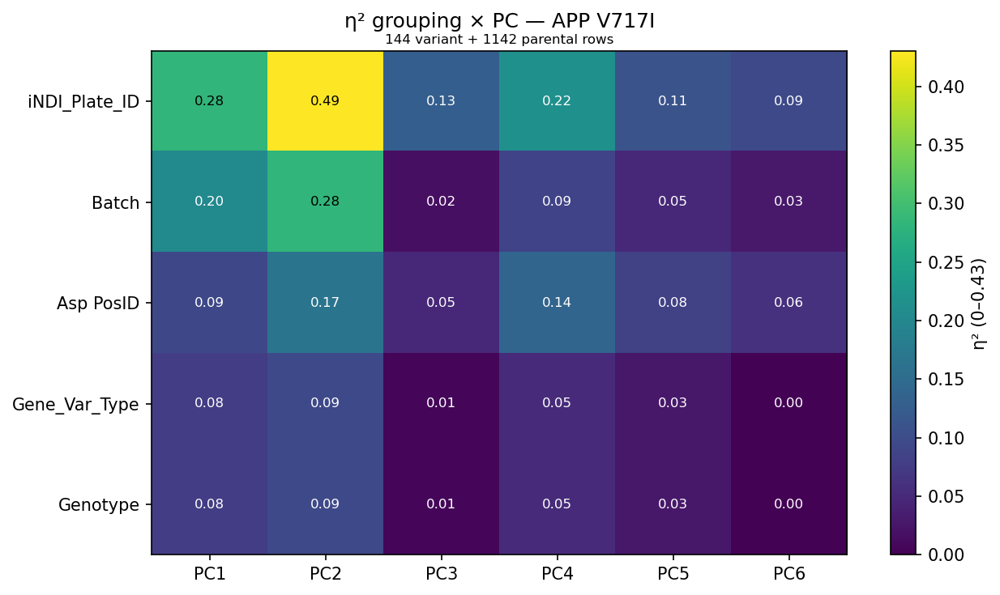

  FUS / R216C: 141 variant + 1142 parental rows


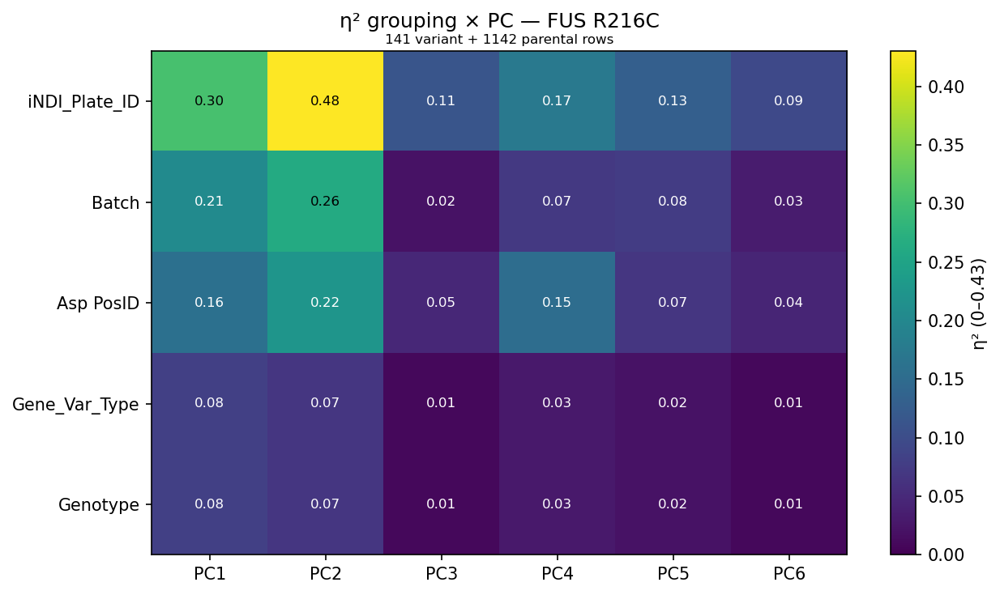

  FUS / R495X: 144 variant + 1142 parental rows


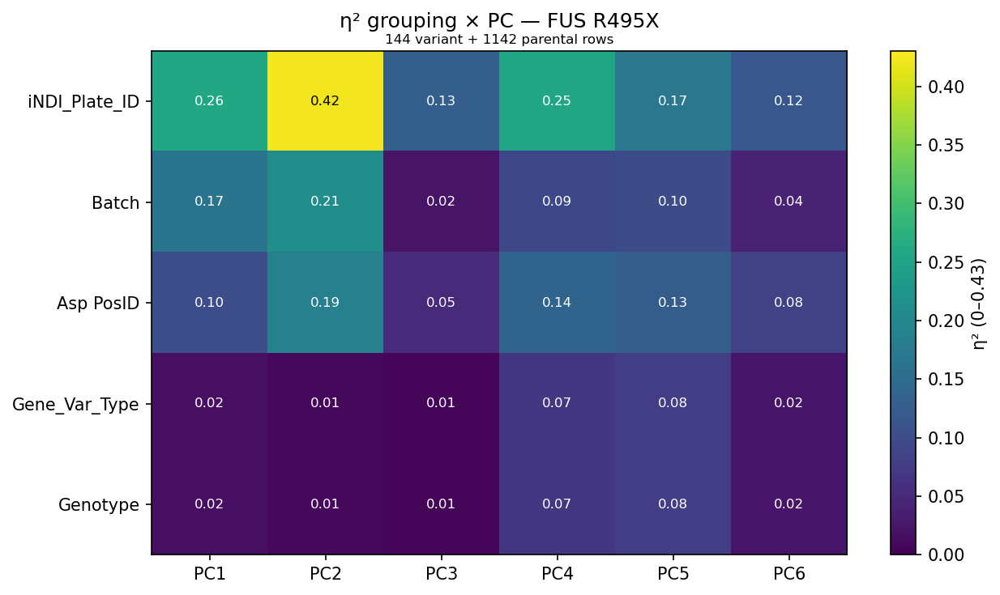

  GRN / Q125X: 134 variant + 1142 parental rows


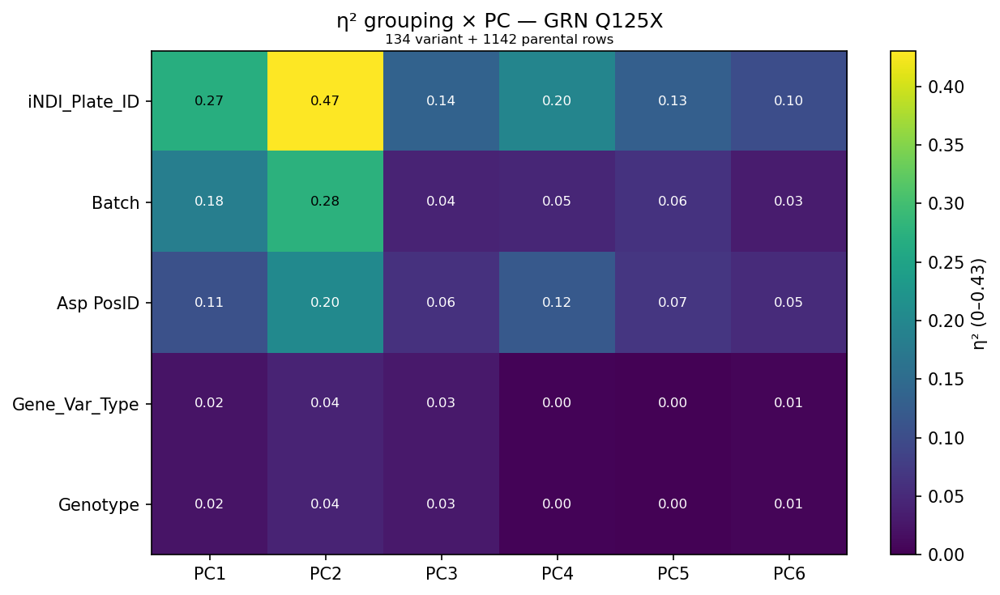

  HNRNPA1 / D262N: 136 variant + 1142 parental rows


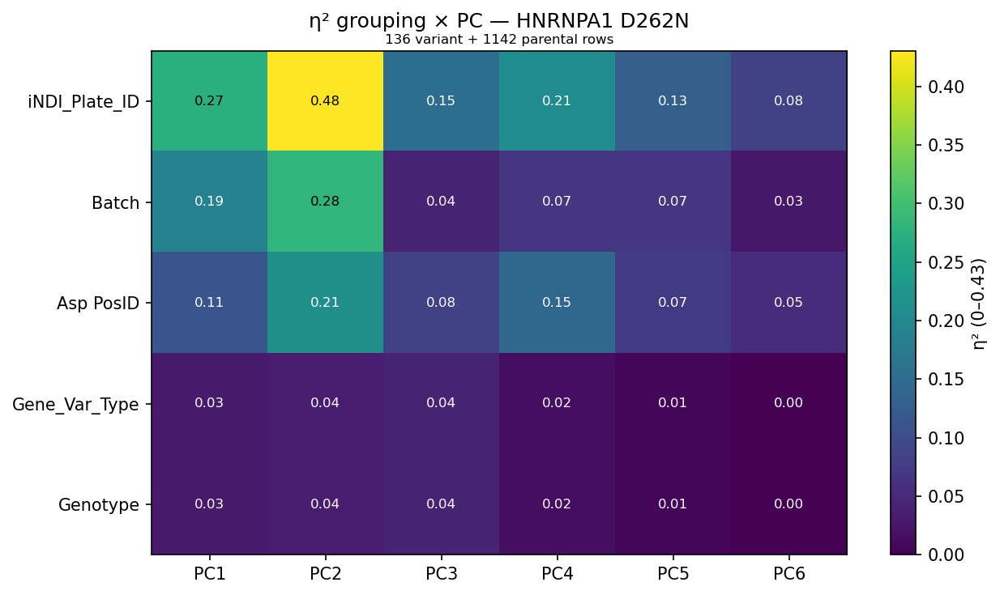

  MAPT / R406W: 143 variant + 1142 parental rows


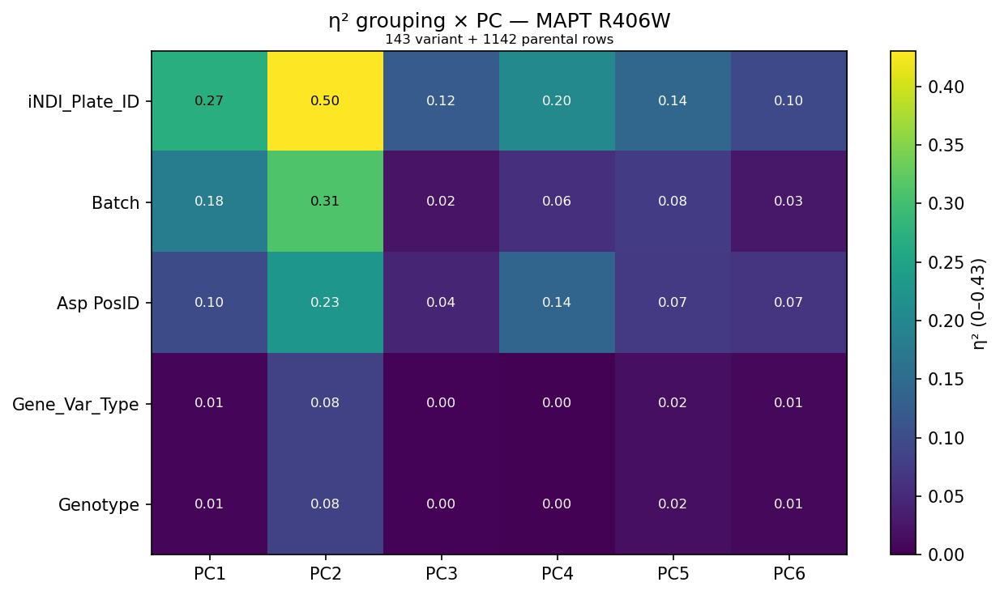

  PFN1 / C71G: 142 variant + 1142 parental rows


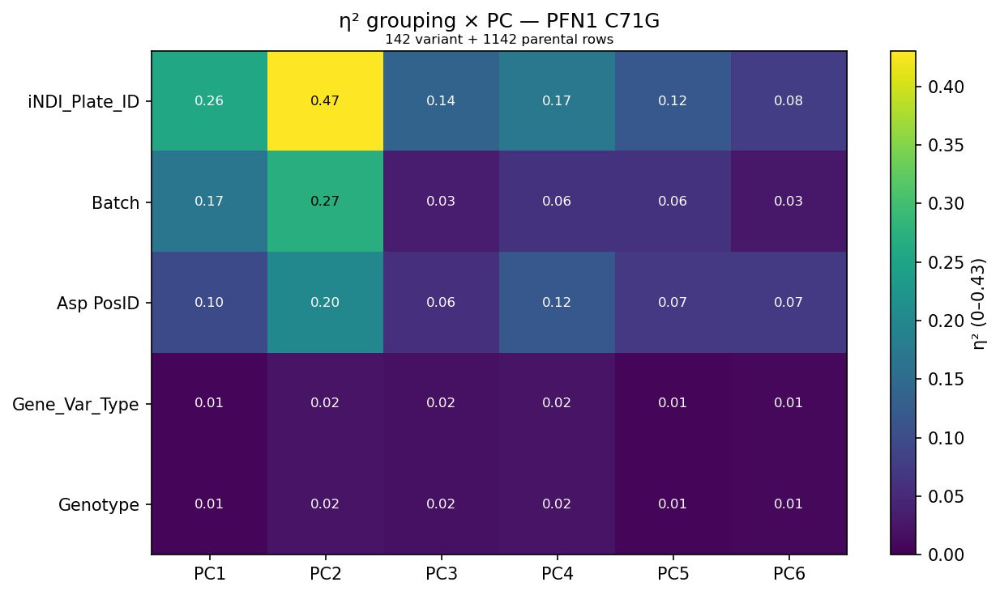

  PSEN1 / E276A: 95 variant + 1142 parental rows


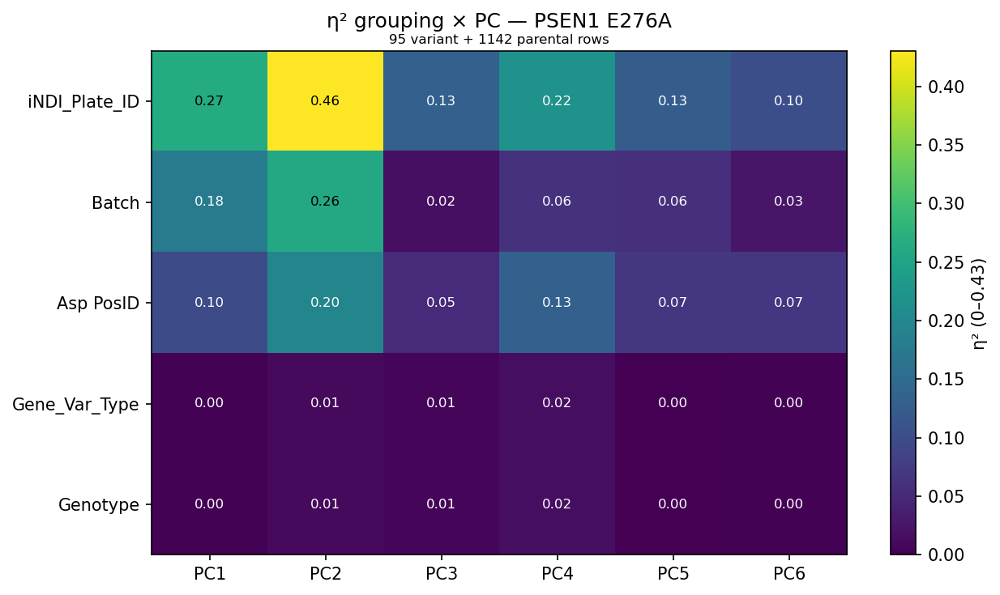

  PSEN2 / N141I: 96 variant + 1142 parental rows


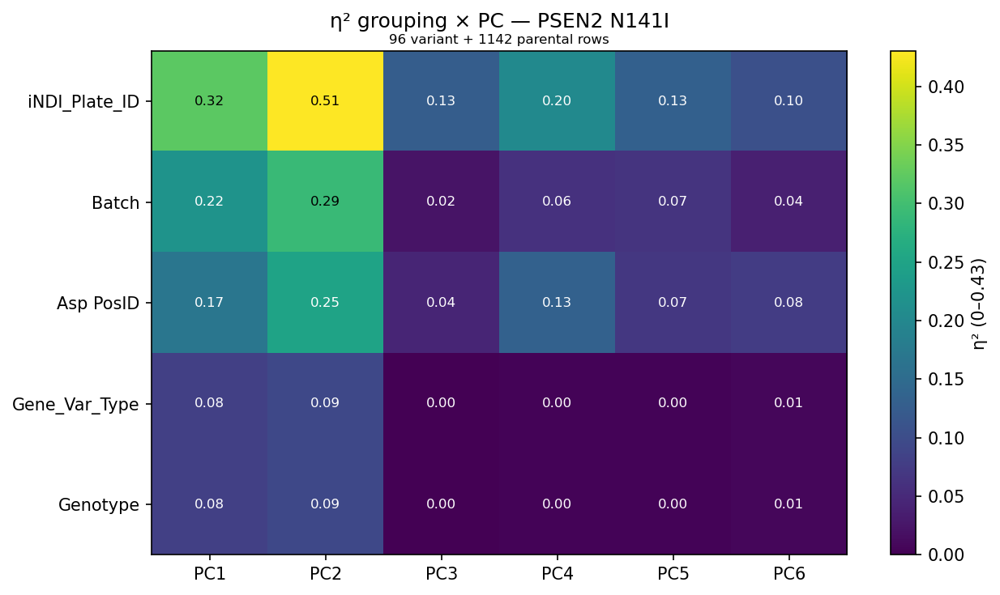

  SNCA / A53T: 46 variant + 1142 parental rows


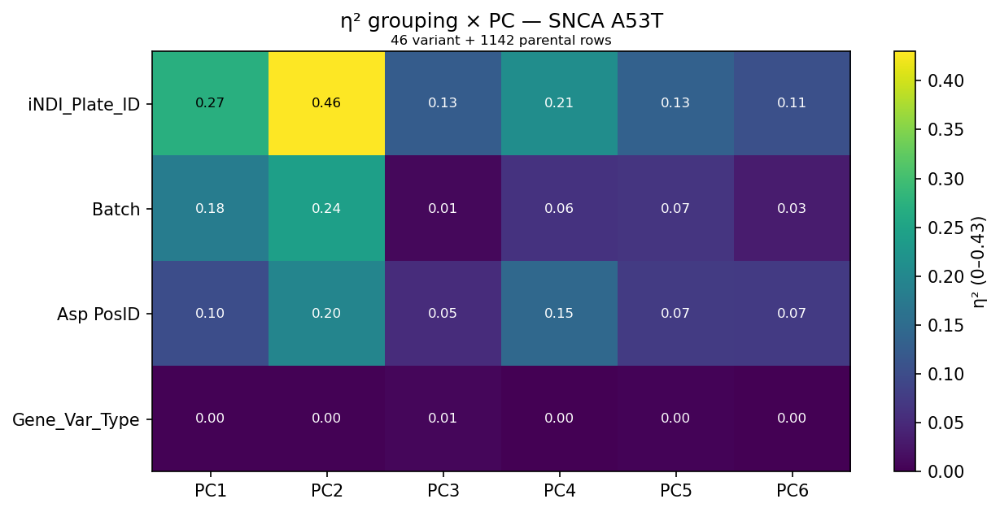

  SNCA / E46K: 48 variant + 1142 parental rows


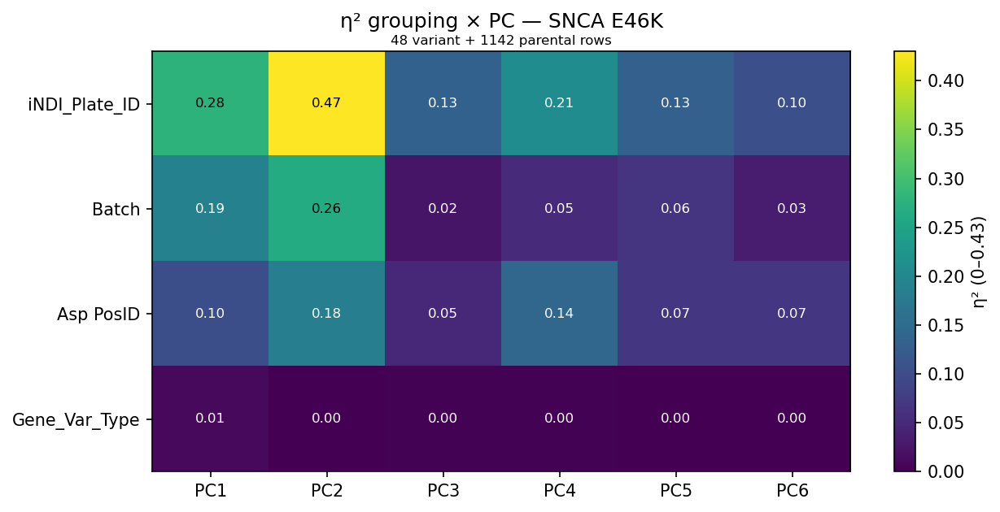

  SNCB / P123H: 96 variant + 1142 parental rows


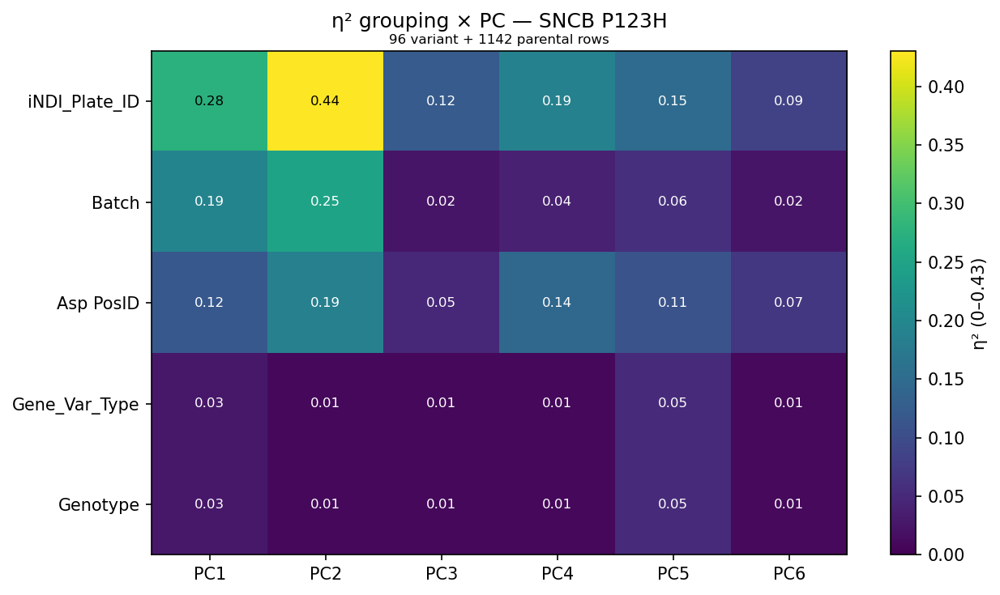

  TARDBP / M337V: 144 variant + 1142 parental rows


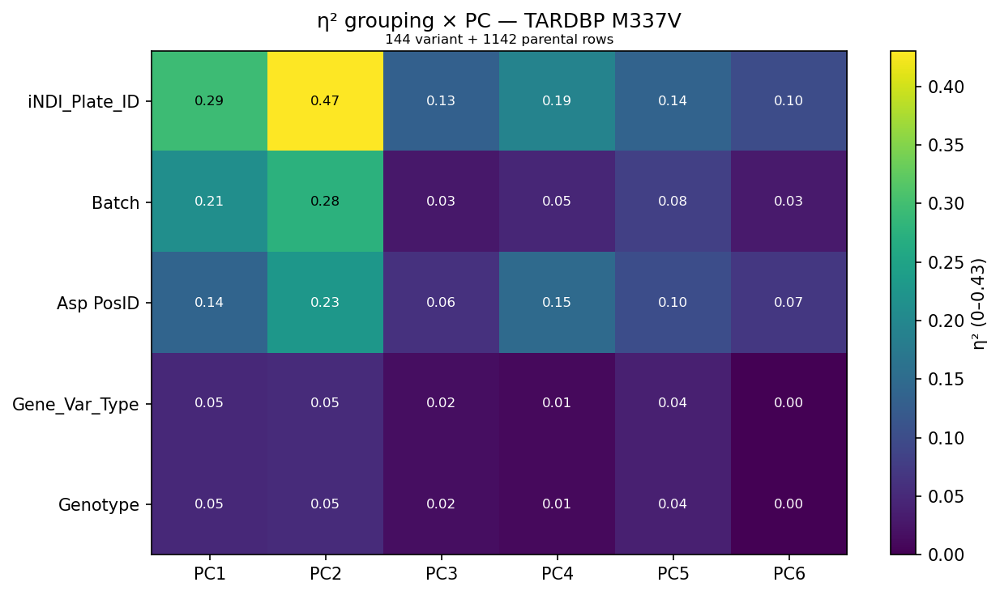

  TARDBP / Q331K: 143 variant + 1142 parental rows


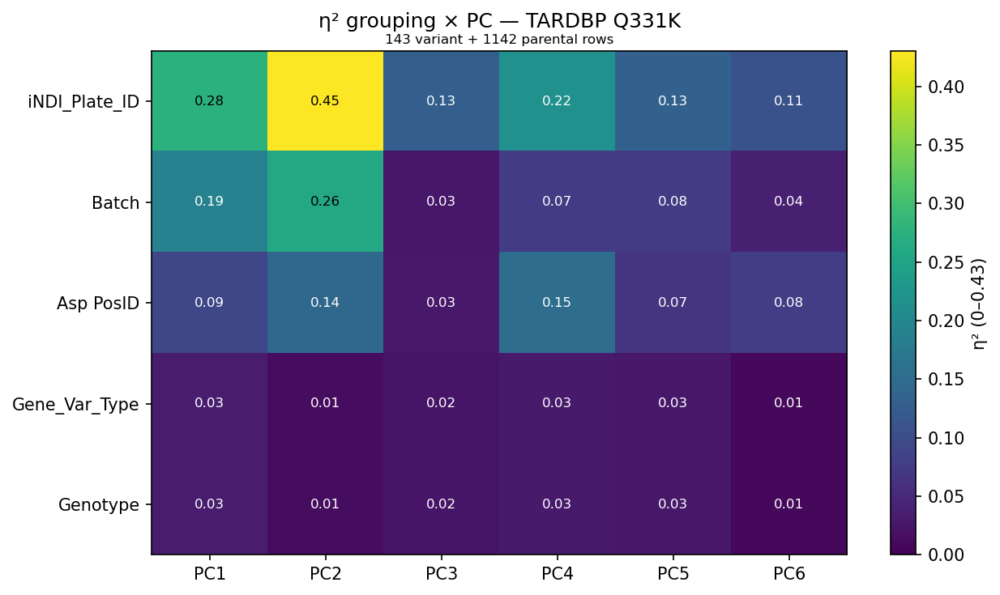

  TBK1 / E696K: 142 variant + 1142 parental rows


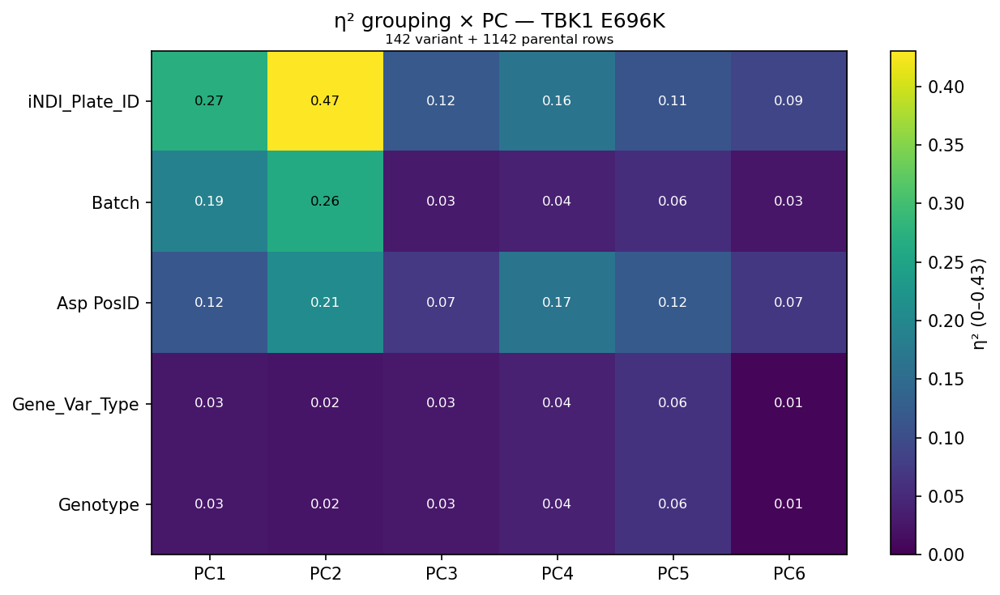

  TIA1 / P351L: 144 variant + 1142 parental rows


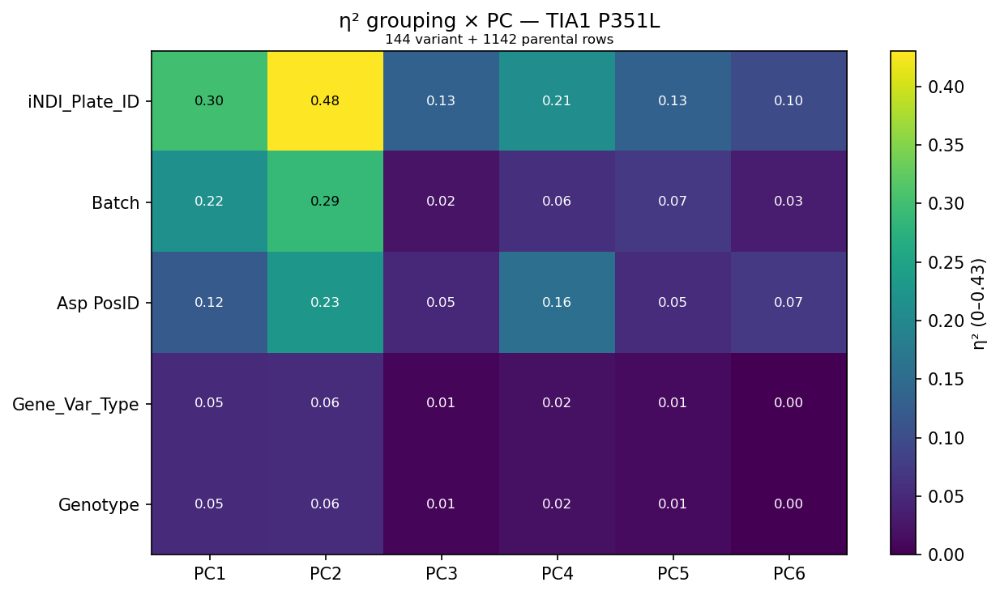

  VCP / R159H: 144 variant + 1142 parental rows


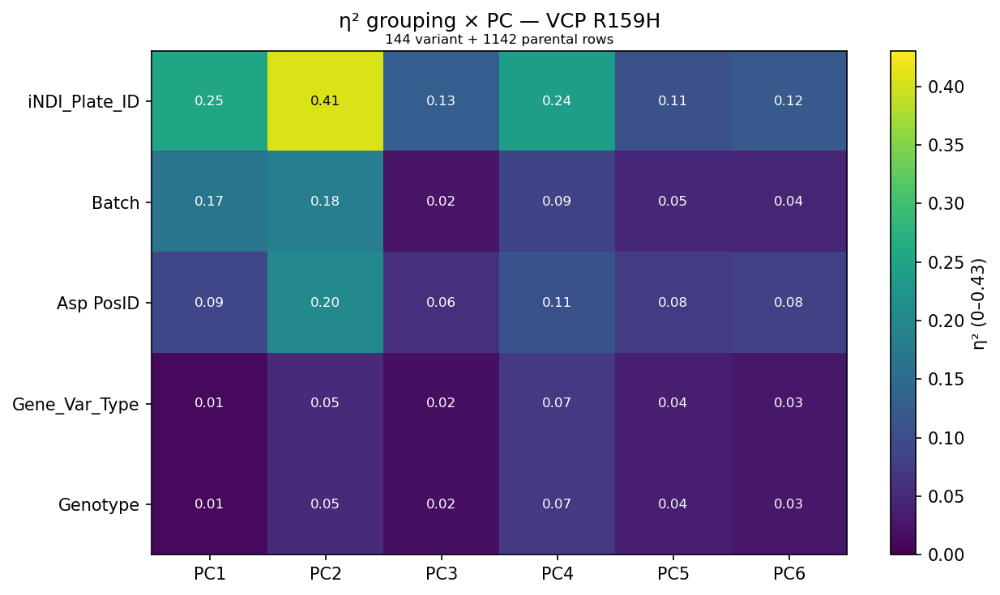

[facet] 21 (gene, variant) pairs; 1142 total KOLF2.1J rows (plate-matched per facet)
  APOE / C112R: 93 variant + 94 parental rows on 1 plate(s)


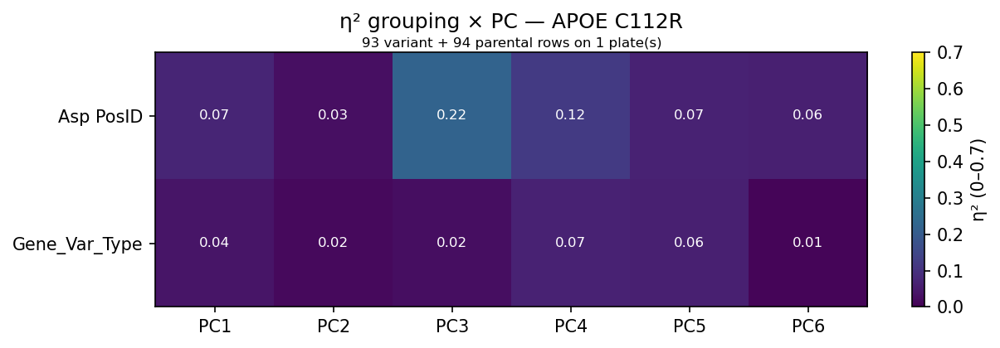

  APOE / R158C: 89 variant + 139 parental rows on 2 plate(s)


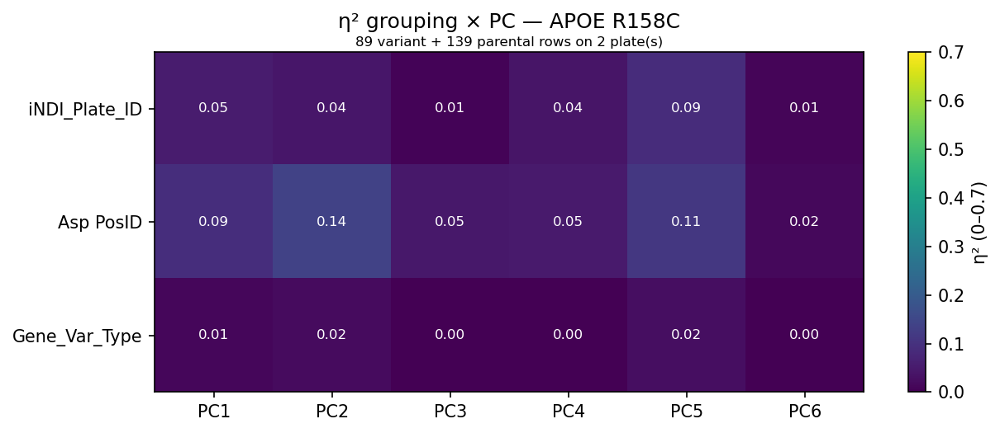

  APP / A673T: 144 variant + 144 parental rows on 2 plate(s)


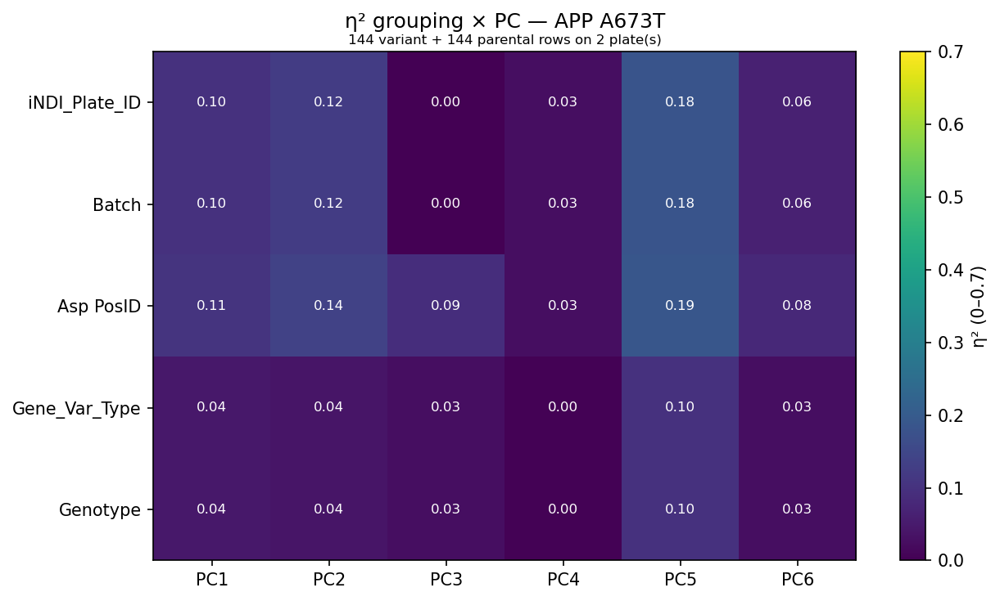

  APP / E693G: 144 variant + 144 parental rows on 2 plate(s)


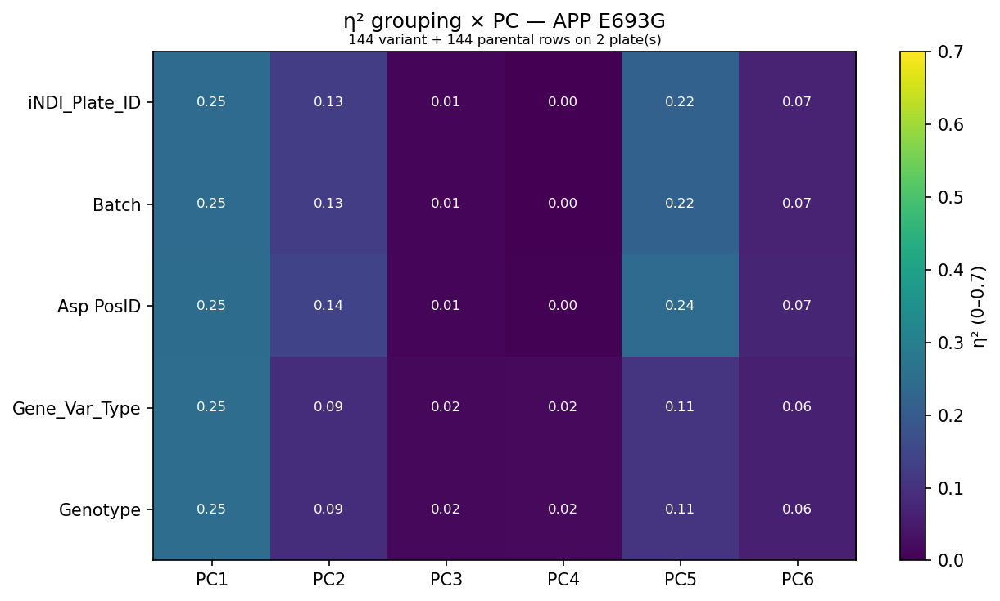

  APP / V717I: 144 variant + 144 parental rows on 2 plate(s)


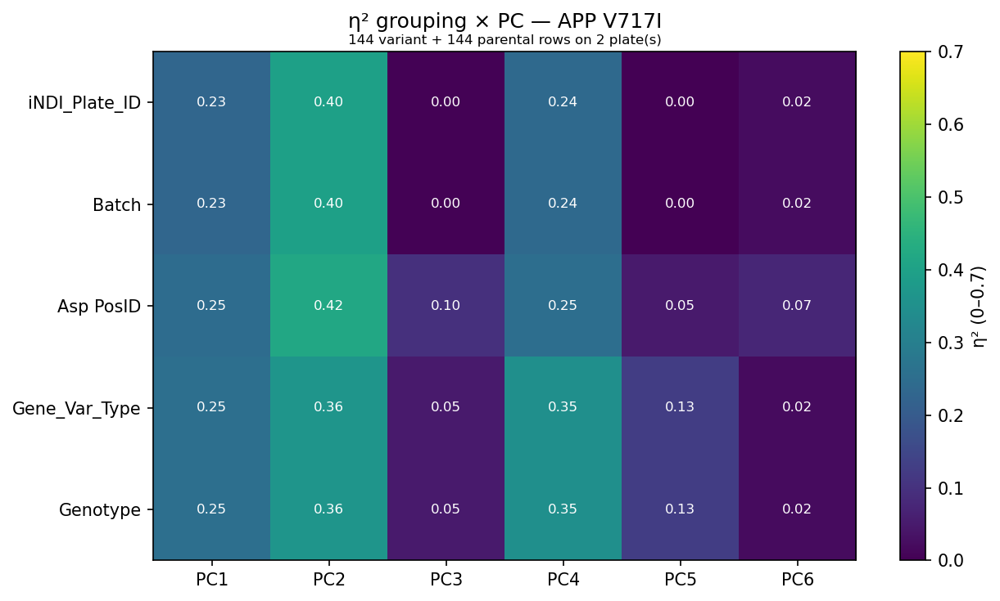

  FUS / R216C: 141 variant + 191 parental rows on 2 plate(s)


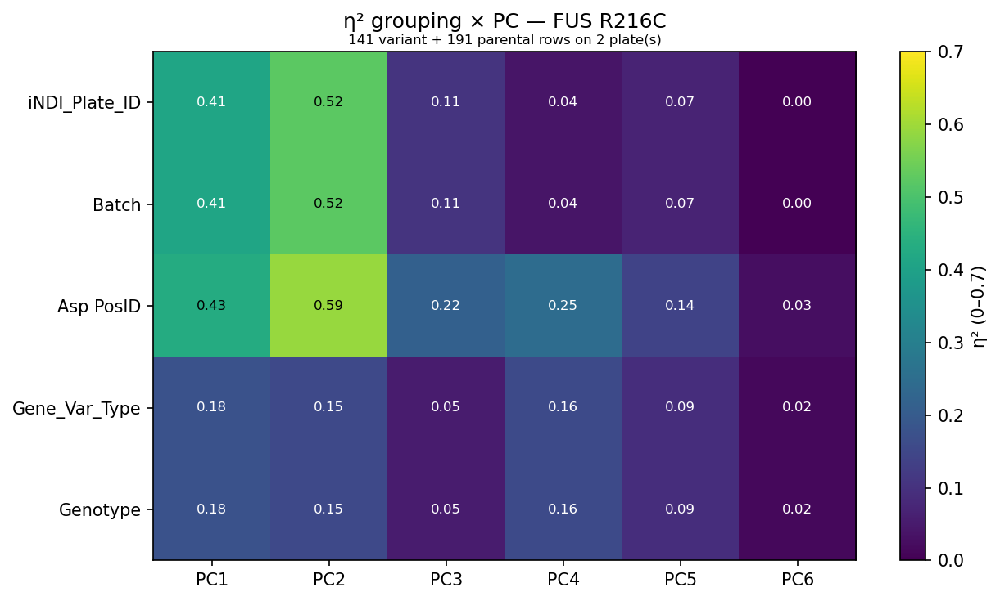

  FUS / R495X: 144 variant + 96 parental rows on 1 plate(s)


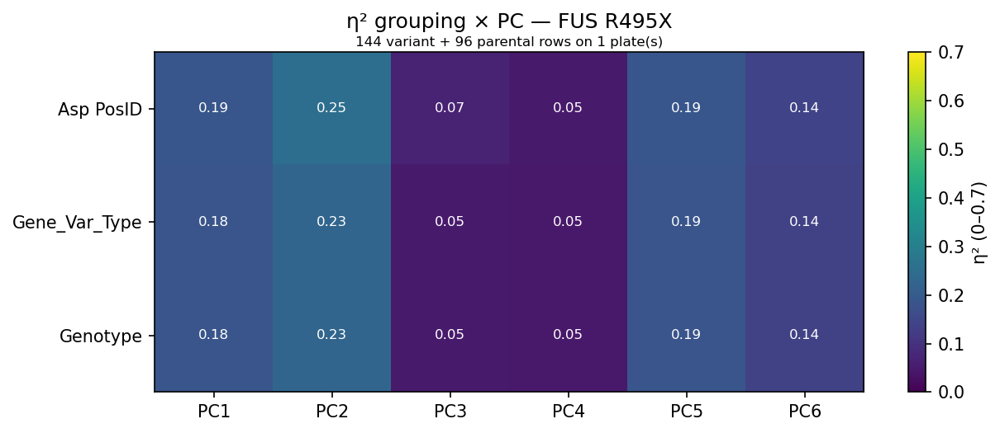

  GRN / Q125X: 134 variant + 140 parental rows on 2 plate(s)


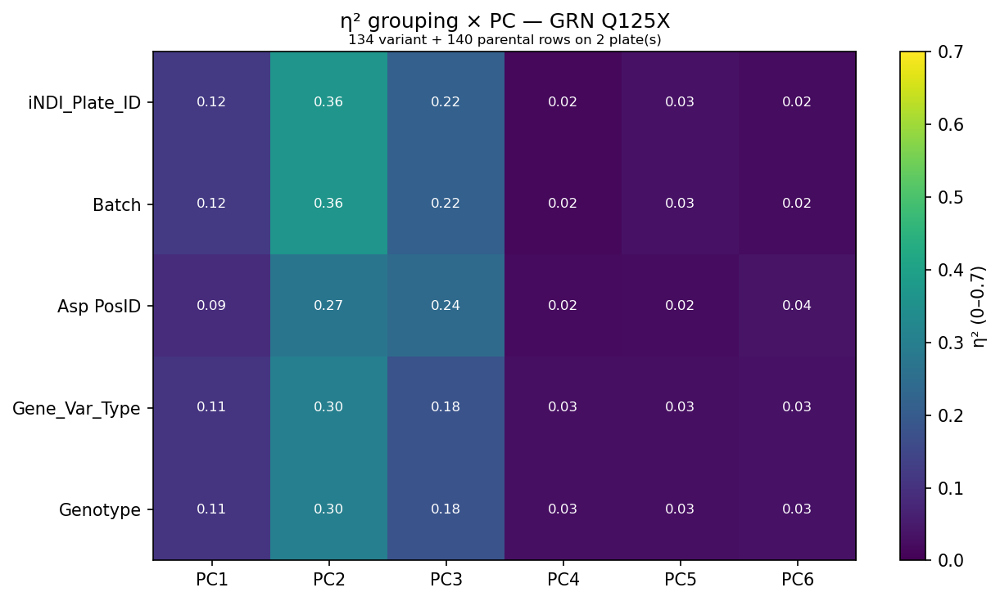

  HNRNPA1 / D262N: 136 variant + 138 parental rows on 2 plate(s)


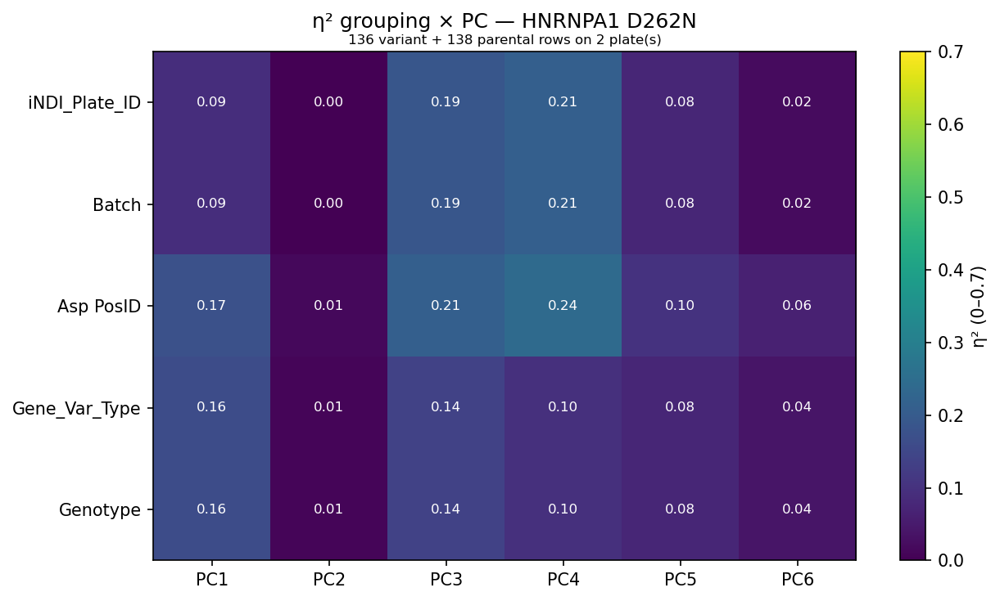

  MAPT / R406W: 143 variant + 96 parental rows on 1 plate(s)


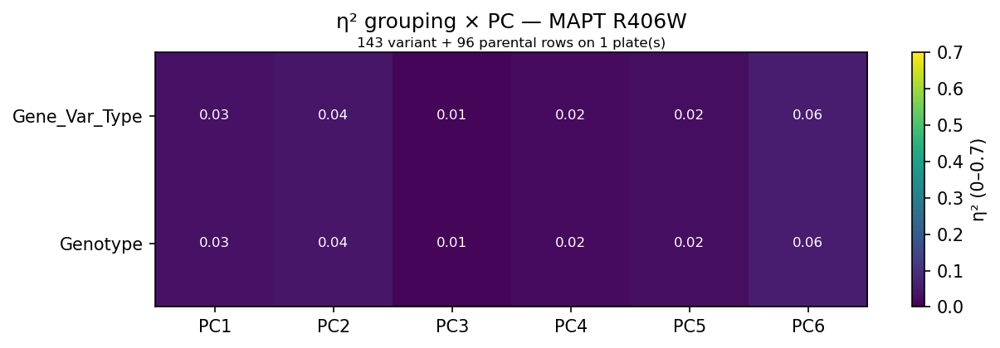

  PFN1 / C71G: 142 variant + 138 parental rows on 2 plate(s)


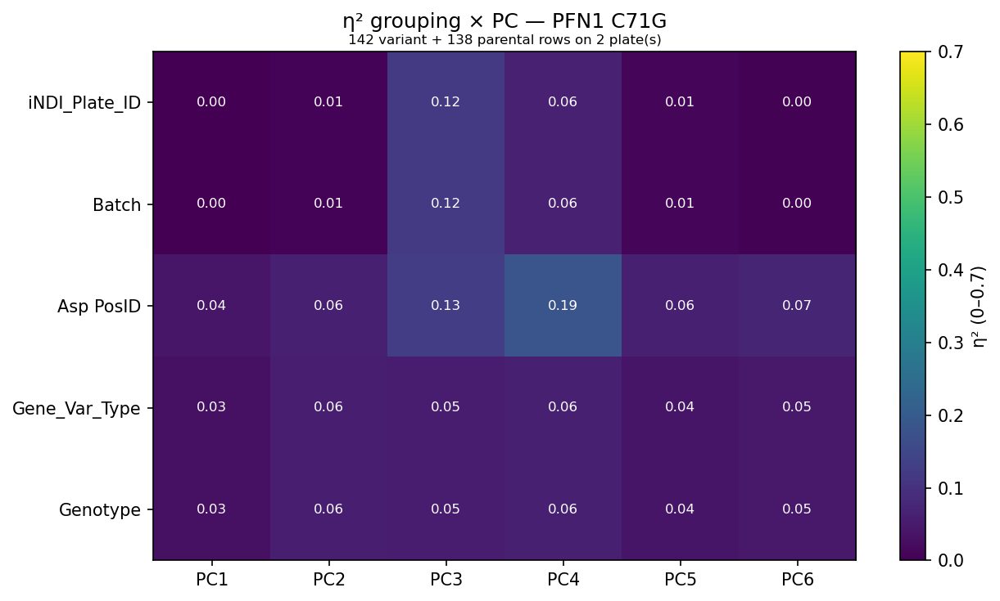

  PSEN1 / E276A: 95 variant + 191 parental rows on 2 plate(s)


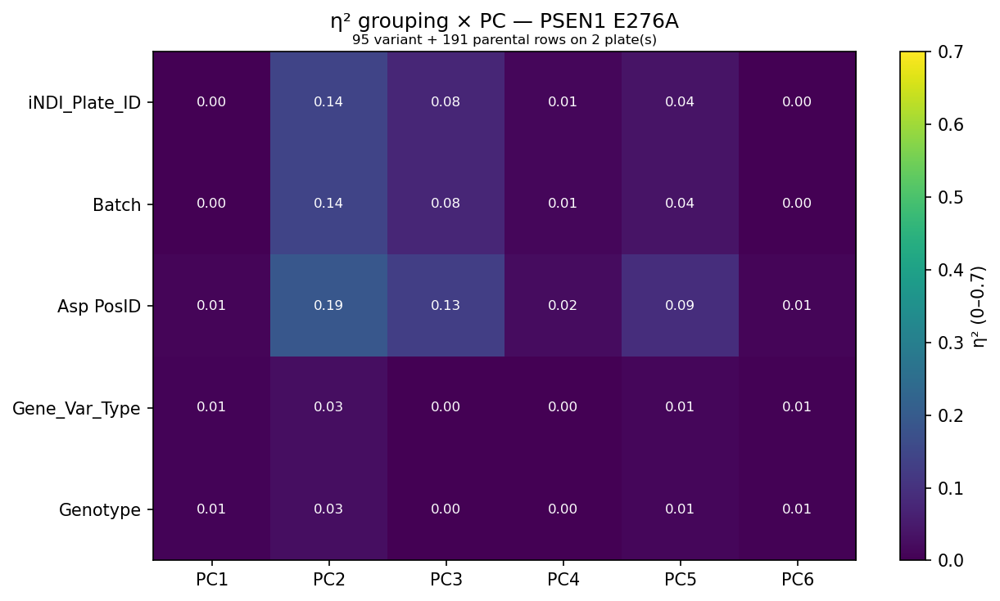

  PSEN2 / N141I: 96 variant + 191 parental rows on 2 plate(s)


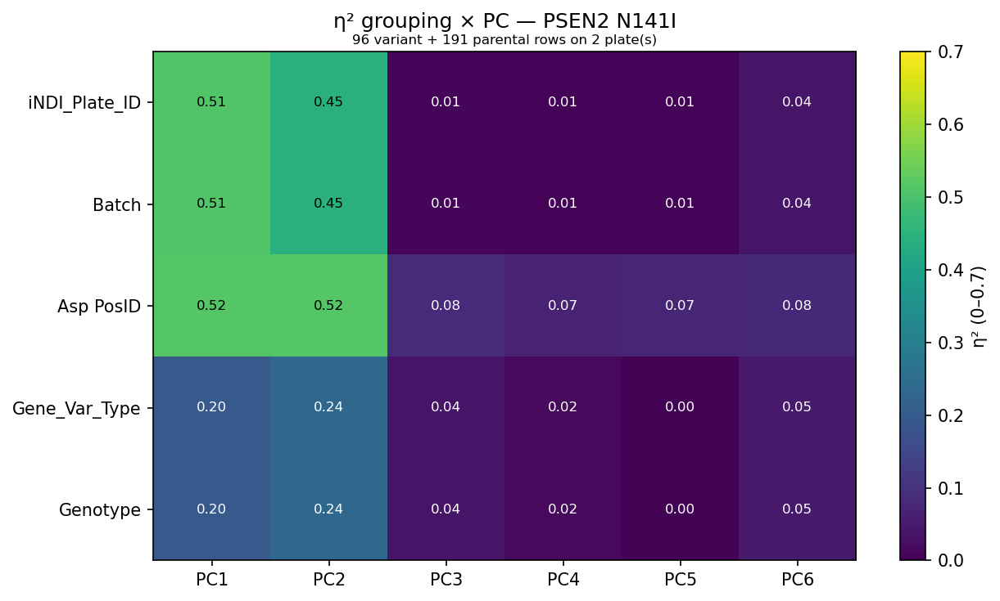

  SNCA / A53T: 46 variant + 94 parental rows on 1 plate(s)


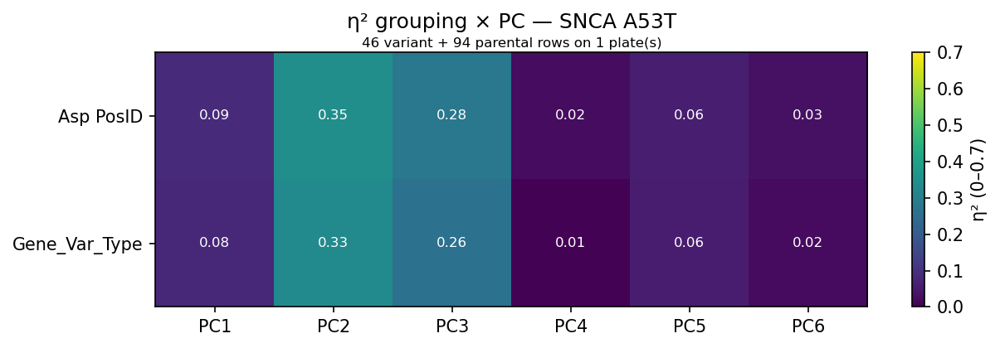

  SNCA / E46K: 48 variant + 95 parental rows on 1 plate(s)


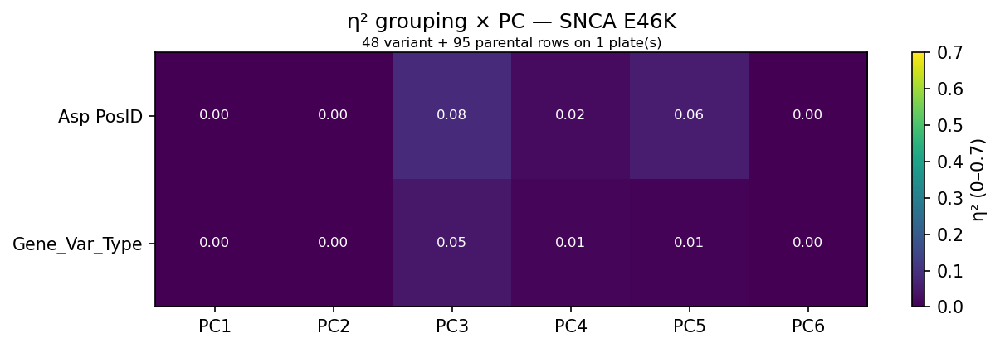

  SNCB / P123H: 96 variant + 96 parental rows on 1 plate(s)


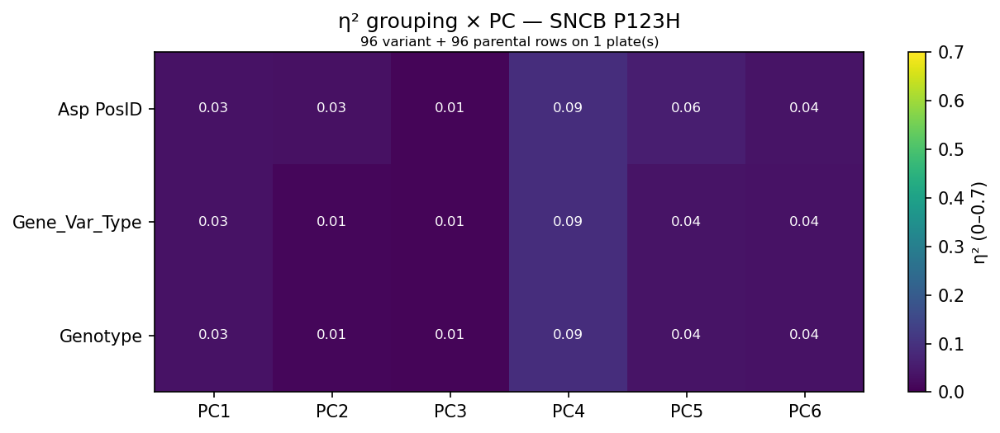

  TARDBP / M337V: 144 variant + 192 parental rows on 2 plate(s)


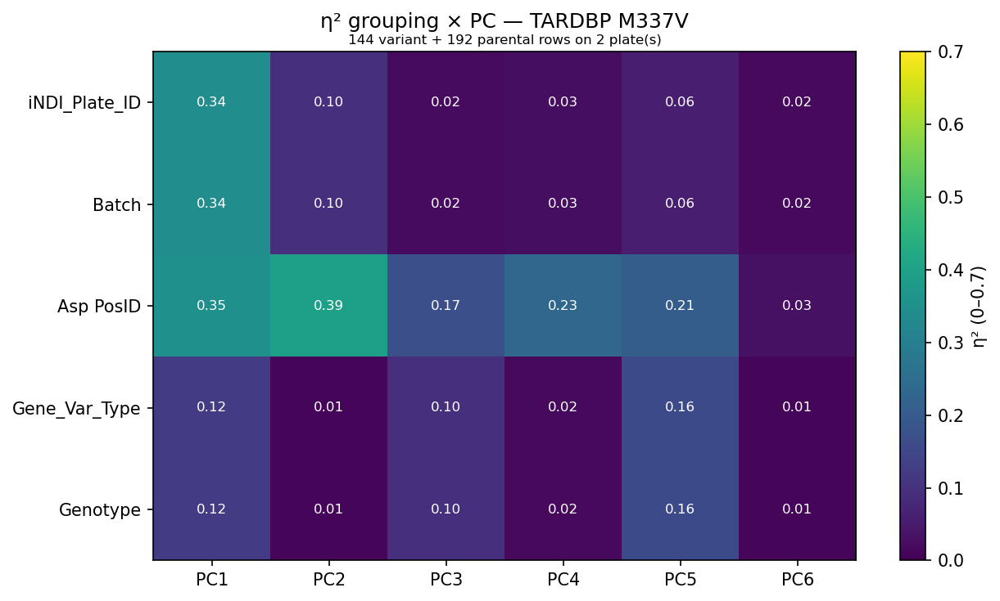

  TARDBP / Q331K: 143 variant + 192 parental rows on 2 plate(s)


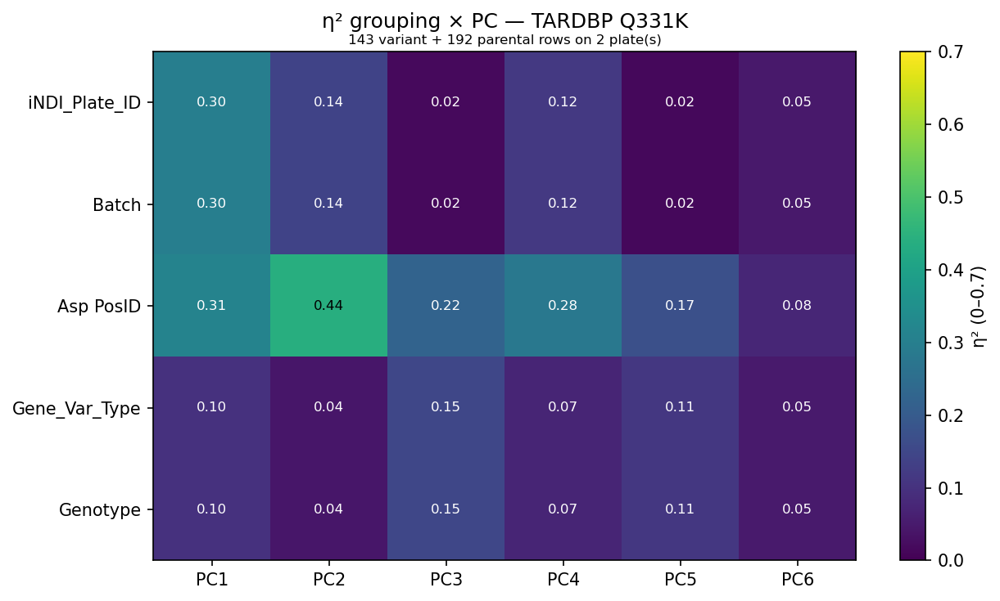

  TBK1 / E696K: 142 variant + 96 parental rows on 1 plate(s)


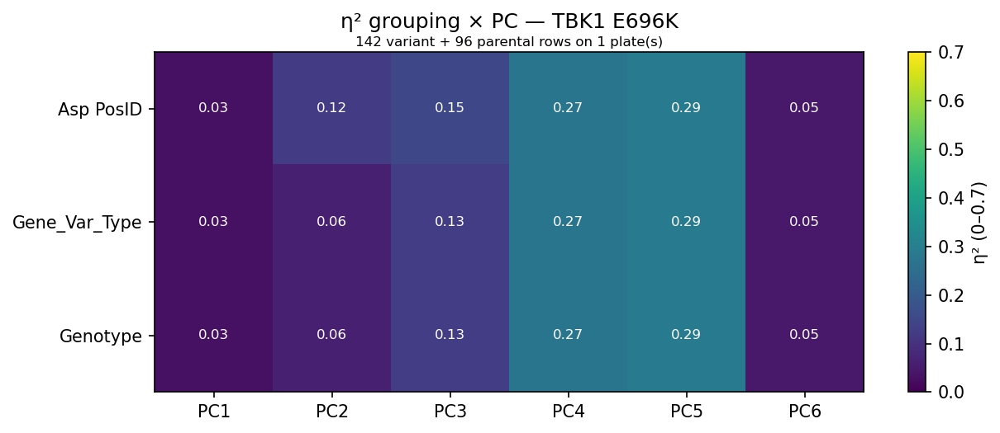

  TIA1 / P351L: 144 variant + 192 parental rows on 2 plate(s)


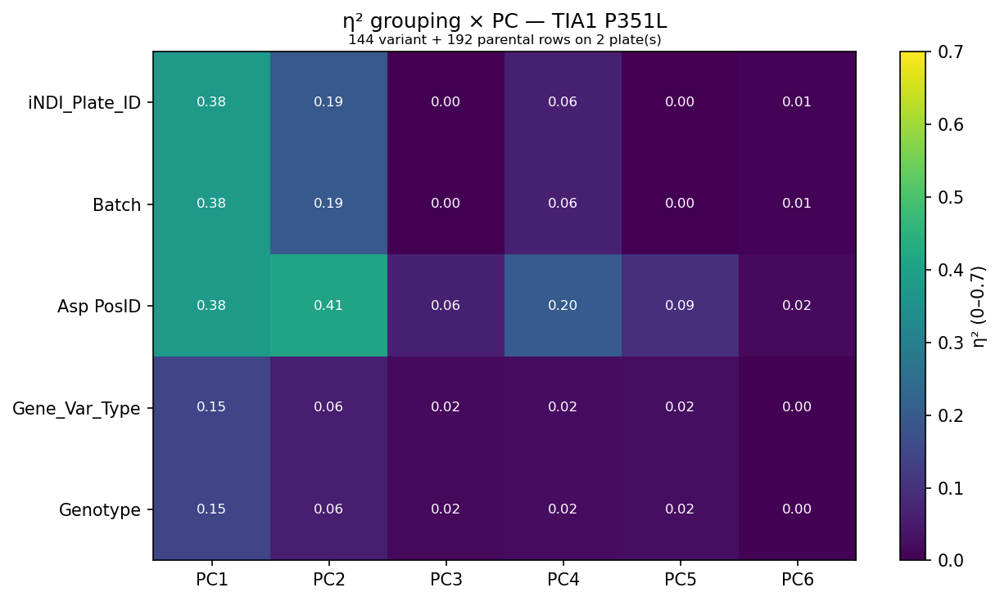

  VCP / R159H: 144 variant + 96 parental rows on 1 plate(s)


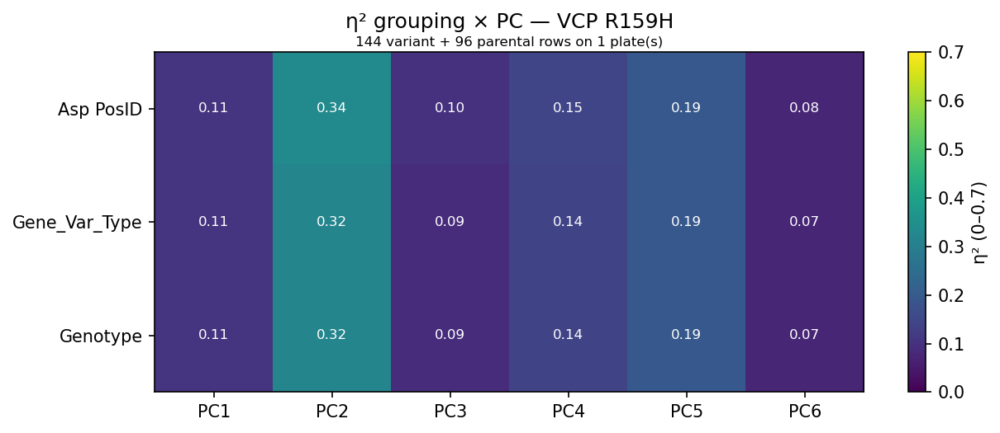

In [34]:
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.43, plate_match=False)
mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.7, plate_match=True)

## Manual analysis
### Feature assessment and loadings

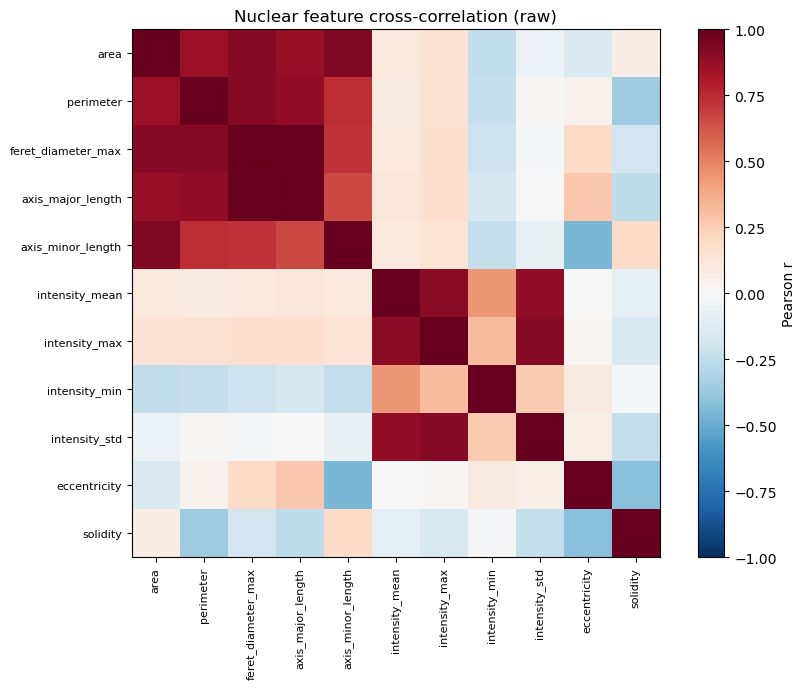

Highly correlated pairs (|r| > 0.9):
  +0.988  feret_diameter_max     axis_major_length
  +0.926  area                   axis_minor_length
  +0.912  perimeter              feret_diameter_max
  +0.909  area                   feret_diameter_max
  +0.907  intensity_max          intensity_std
  +0.901  intensity_mean         intensity_max
[full] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full] dropped 0 rows with NaN/inf; 455846 remain
[full] EVR: [0.398 0.309 0.163 0.111 0.014 0.005]
[full] cumulative: [0.398 0.707 0.87  0.981 0.995 1.   ]


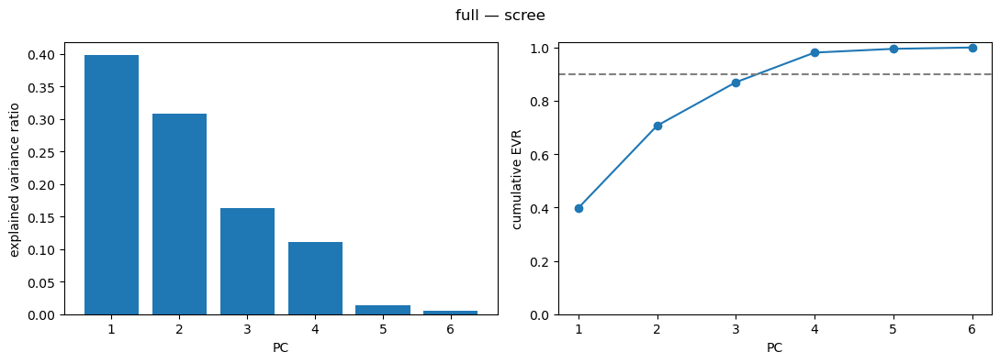

                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.129  0.116  0.977  0.007  0.119  0.016
intensity_mean -0.206  0.672  0.030  0.177 -0.688 -0.013
intensity_std  -0.279  0.639 -0.126  0.013  0.705  0.023
eccentricity   -0.567 -0.260  0.092  0.357 -0.002  0.690
solidity        0.445  0.030 -0.082  0.881  0.120 -0.067
aspect_ratio    0.586  0.240 -0.113 -0.257 -0.025  0.721


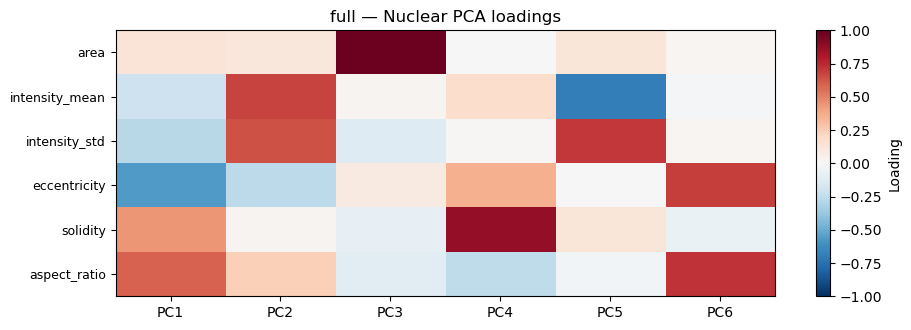

In [35]:
df_manual = df[df["Source"] == "manual"]
feature_correlation(df_manual)
df_manual, pca, FEATURES = fit_pca(df_manual, label="full")

### PCA plots - ROI-level

All 8 iNDI_Plate_ID values have a color.


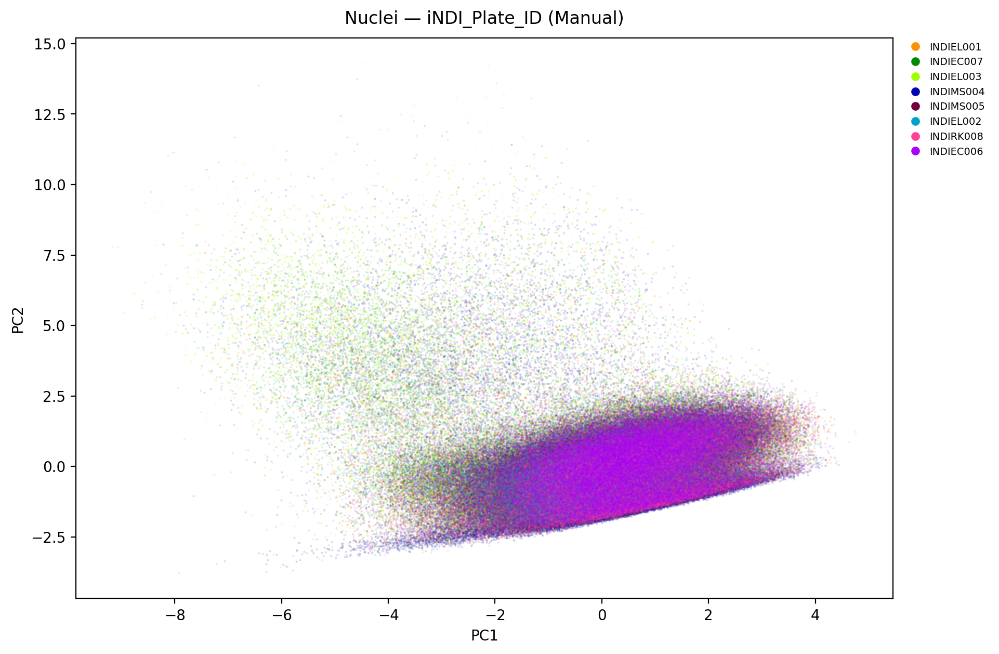

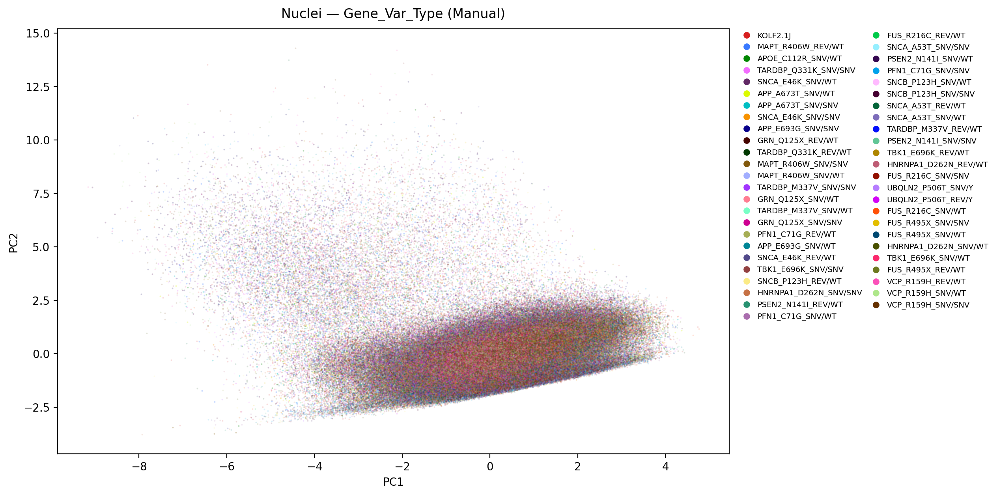

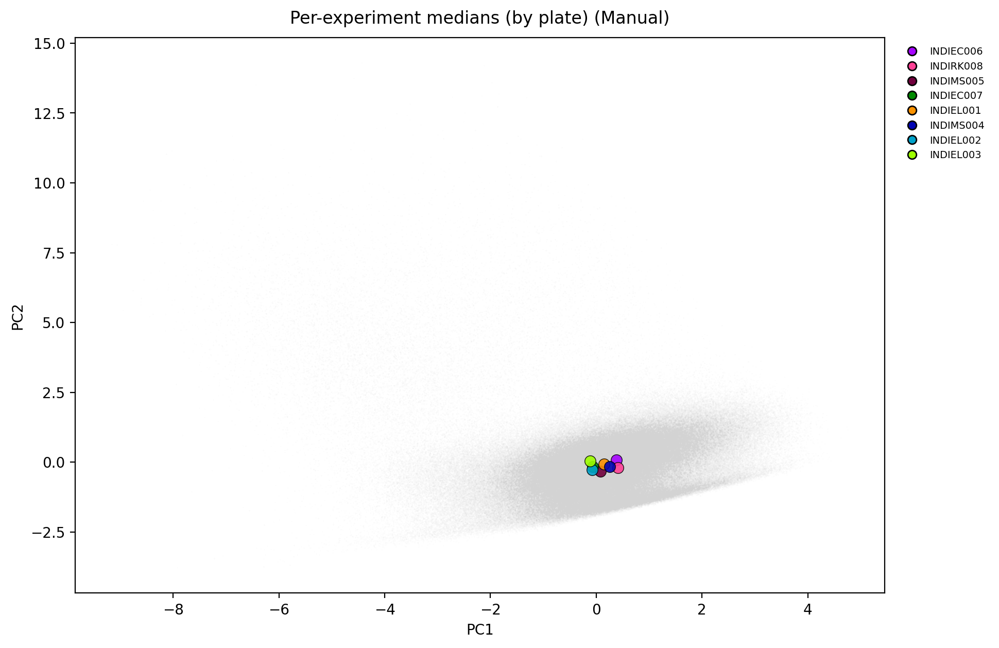

Std of per-experiment centroids (batch magnitude):
PC1    0.205
PC2    0.141
PC3    0.178
dtype: float64


In [36]:
plate_pal = make_palette(df_manual["iNDI_Plate_ID"])
check_palette_coverage(df_manual, "iNDI_Plate_ID", plate_pal)
pca_scatter(df_manual, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID (Manual)")

pca_scatter(df_manual, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Nuclei — Gene_Var_Type (Manual)")

centroid_overlay(df_manual, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate) (Manual)")
cent = df_manual.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

### PCA plots - well-level

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 74696 rows (11755 images)
[full] well-level: 2197 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 2197 remain
[full well] EVR: [0.459 0.268 0.127 0.114 0.031 0.002]
[full well] cumulative: [0.459 0.726 0.853 0.967 0.998 1.   ]


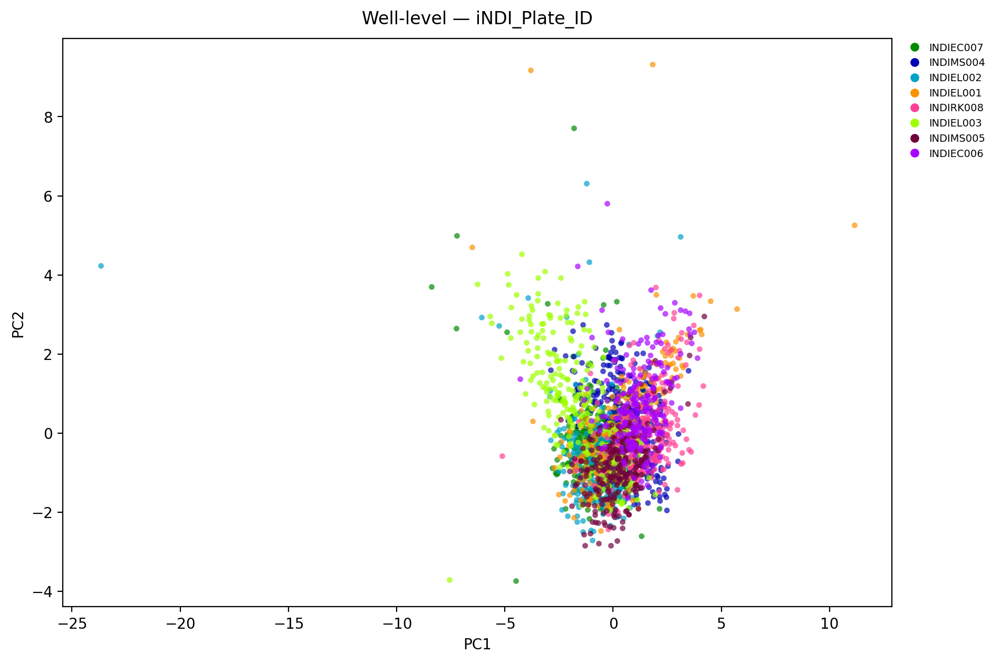

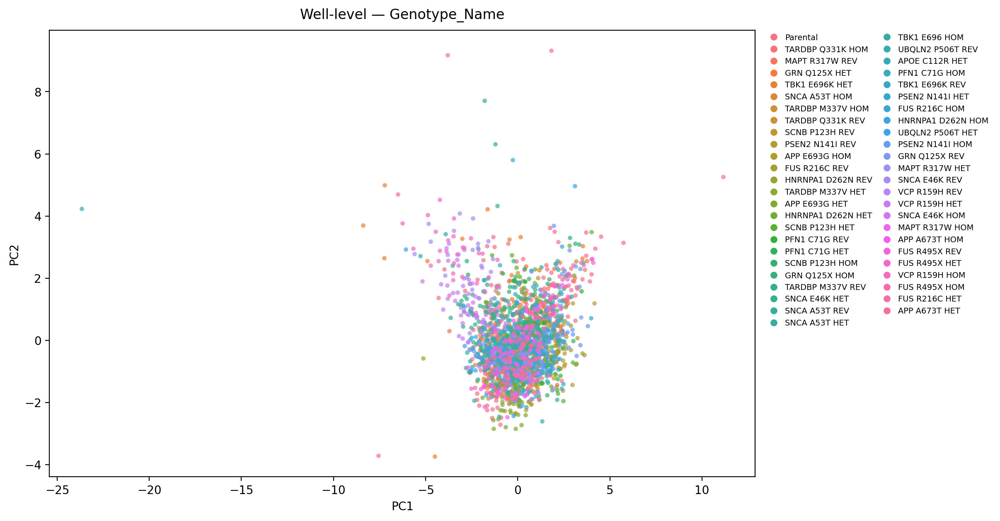

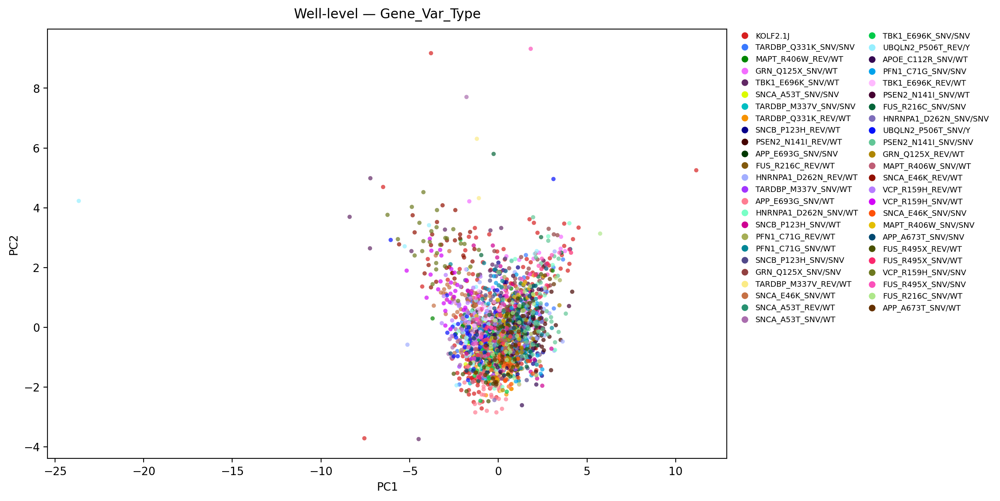

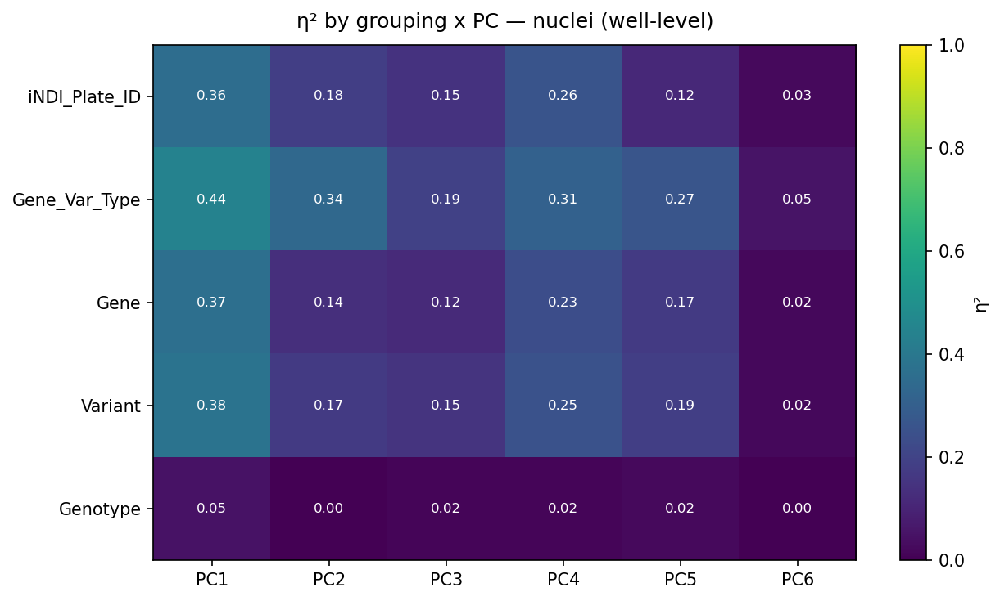

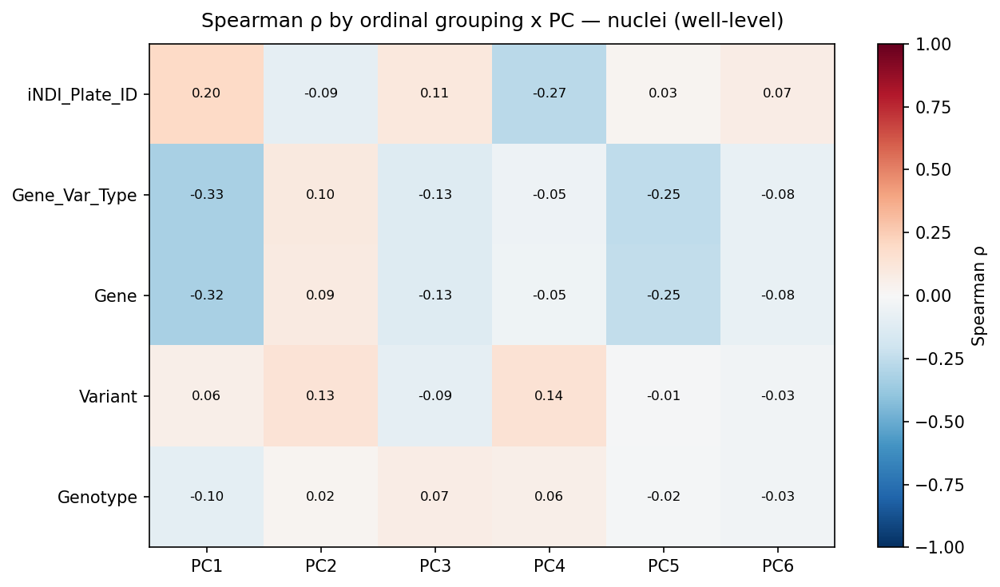

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.197505,-0.086624,0.105440,-0.272840,0.029777,0.070599
Gene_Var_Type,-0.325369,0.099803,-0.126588,-0.047770,-0.252648,-0.077440
Gene,-0.322786,0.090063,-0.130304,-0.046687,-0.247465,-0.075824
Variant,0.056290,0.133972,-0.092574,0.143981,-0.014039,-0.031411
Genotype,-0.100097,0.024430,0.070478,0.058743,-0.015818,-0.031567


In [37]:
well_level = aggregate_wells(df_manual, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_level["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Genotype_Name", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Genotype_Name")
pca_scatter(well_shuf, "Gene_Var_Type", s=15, alpha=0.7, figsize=(13, 7),
            legend_ncol=2, title="Well-level — Gene_Var_Type")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Gene_Var_Type", "Gene", "Variant", "Genotype"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Gene_Var_Type", "Gene", "Variant", "Genotype"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

[facet] 18 (gene, variant) pairs; 307 total KOLF2.1J rows (all folded into each facet)
  APOE / C112R: 42 variant + 307 parental rows


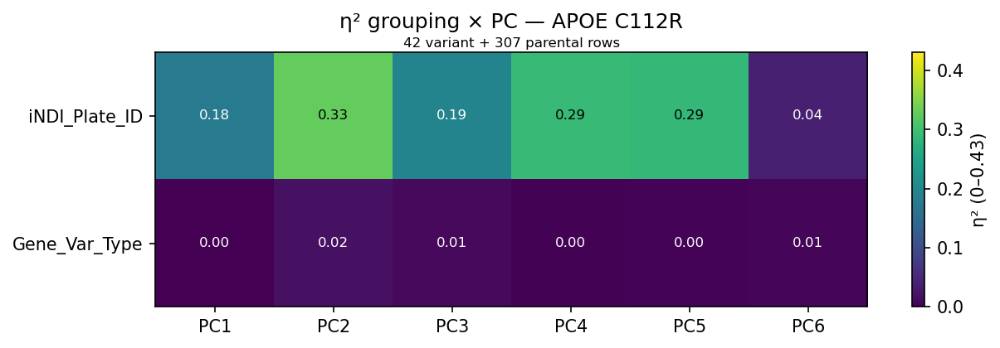

  APP / A673T: 56 variant + 307 parental rows


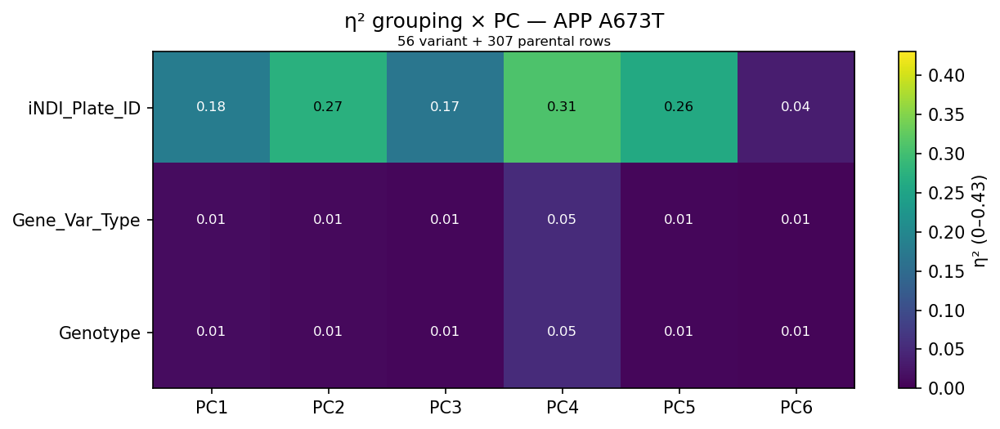

  APP / E693G: 84 variant + 307 parental rows


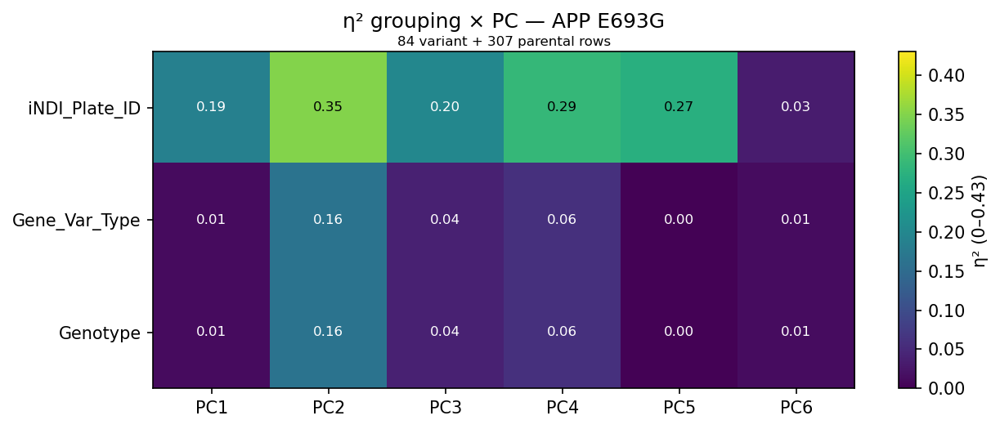

  FUS / R216C: 112 variant + 307 parental rows


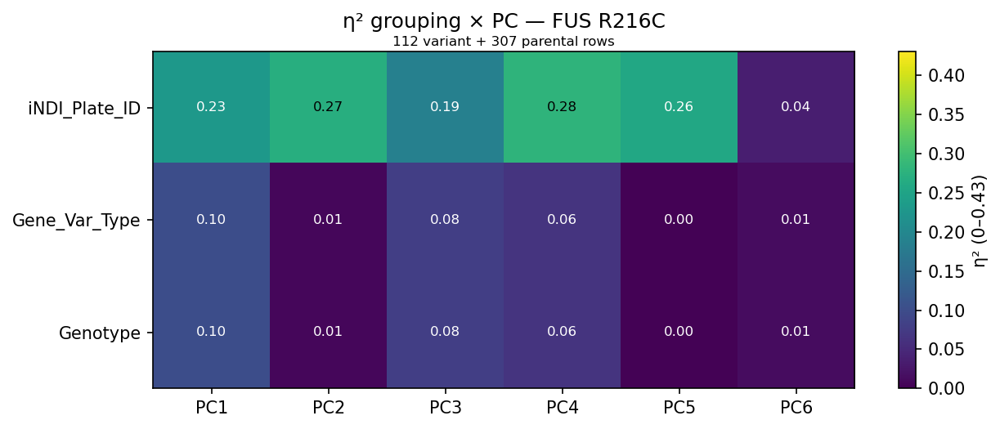

  FUS / R495X: 84 variant + 307 parental rows


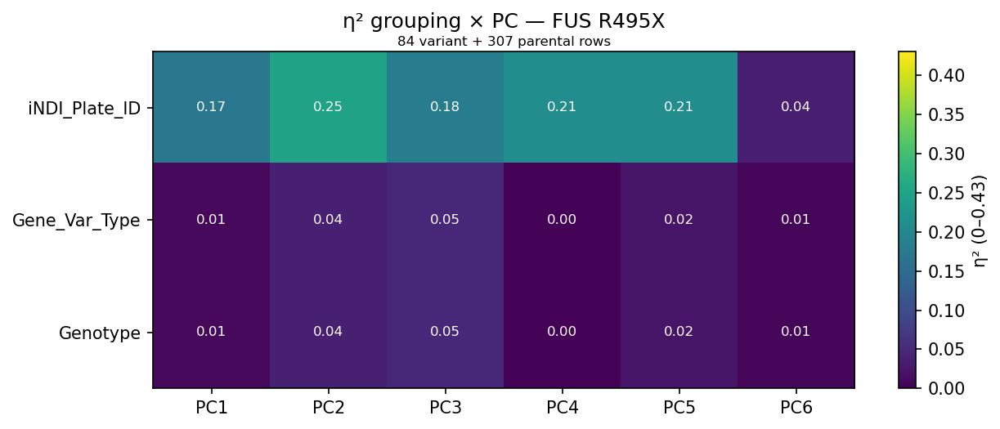

  GRN / Q125X: 126 variant + 307 parental rows


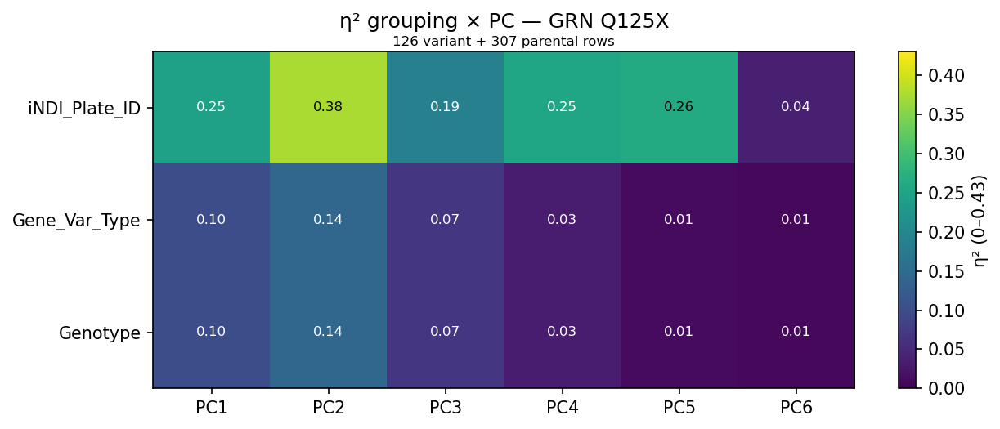

  HNRNPA1 / D262N: 126 variant + 307 parental rows


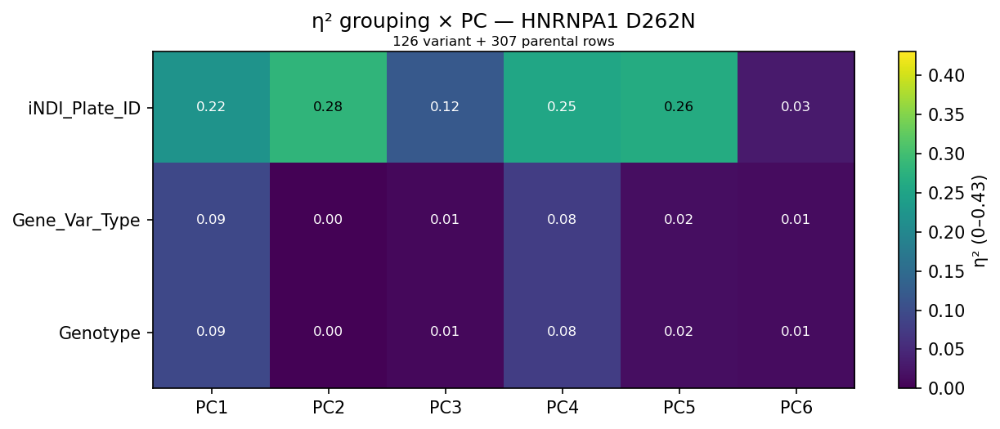

  MAPT / R406W: 112 variant + 307 parental rows


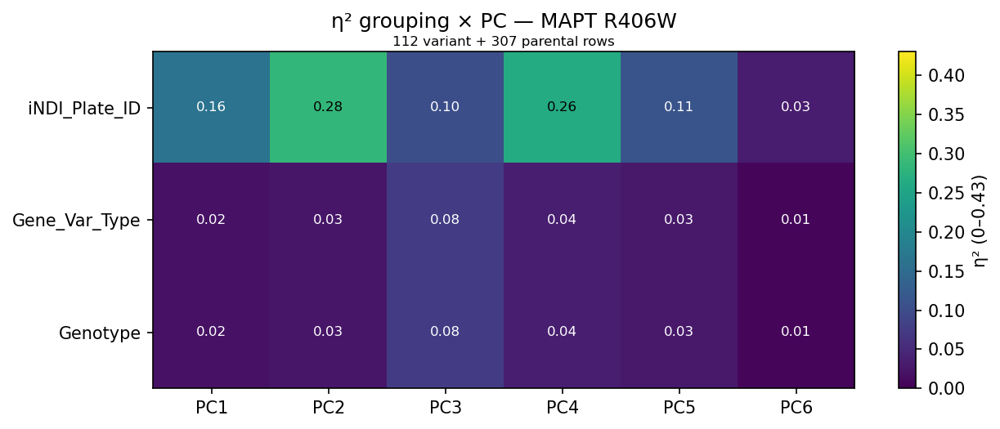

  PFN1 / C71G: 126 variant + 307 parental rows


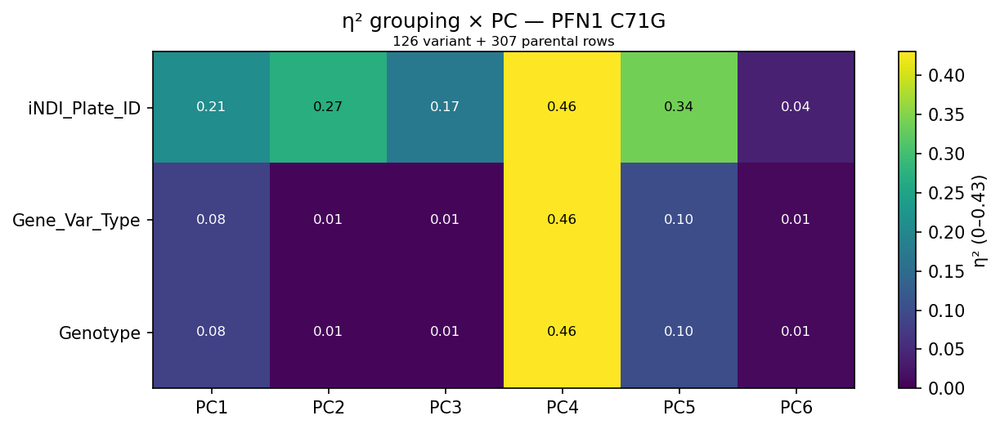

  PSEN2 / N141I: 126 variant + 307 parental rows


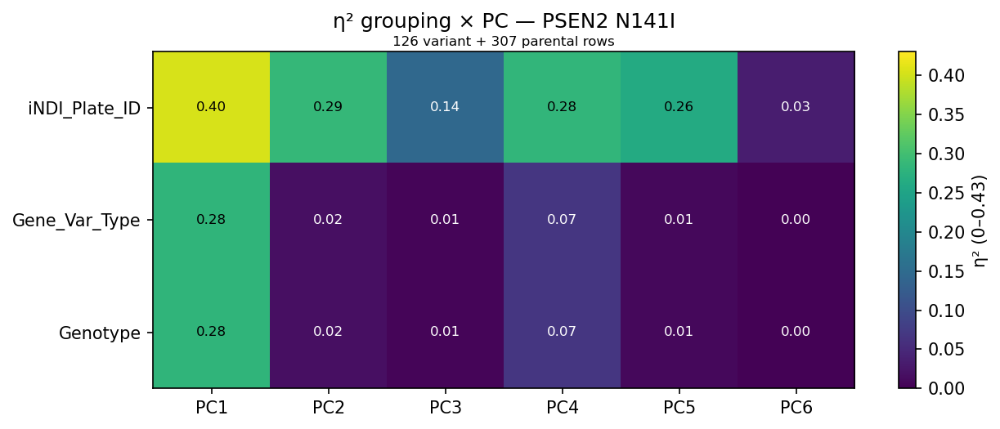

  SNCA / A53T: 126 variant + 307 parental rows


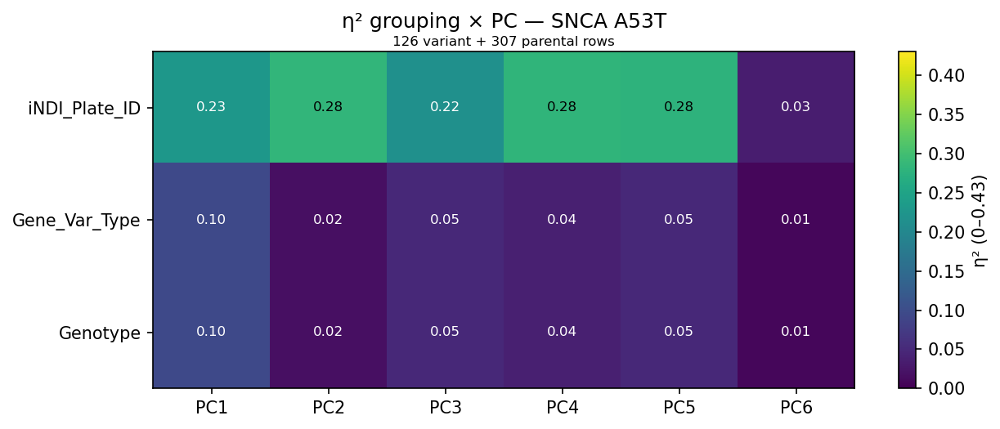

  SNCA / E46K: 98 variant + 307 parental rows


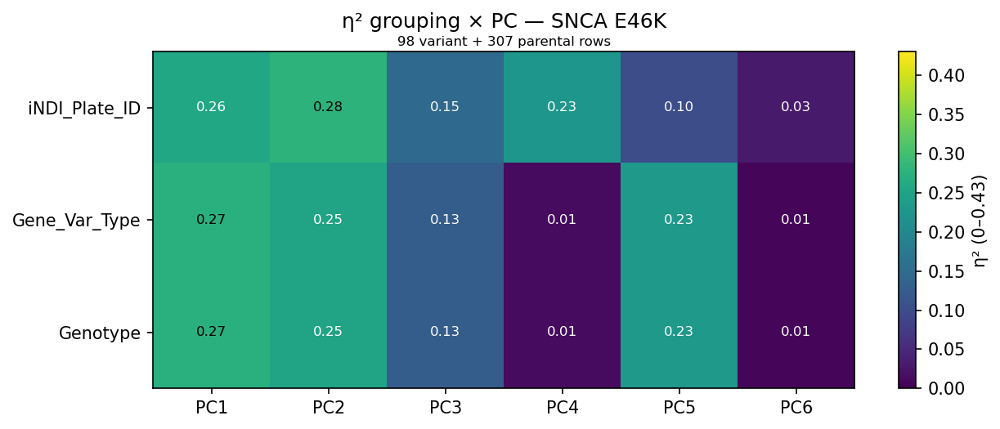

  SNCB / P123H: 126 variant + 307 parental rows


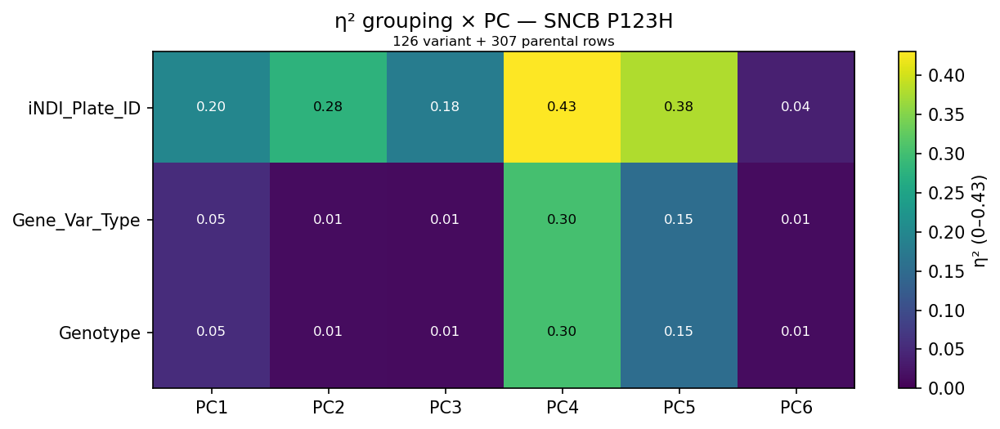

  TARDBP / M337V: 126 variant + 307 parental rows


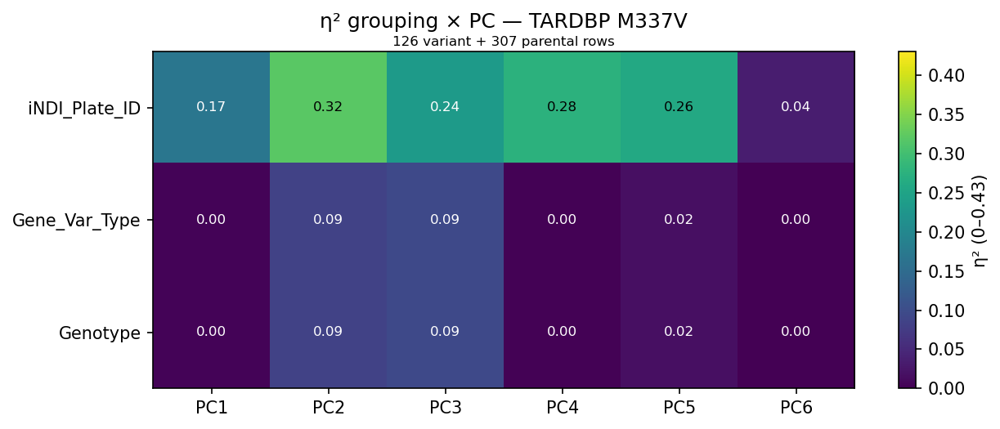

  TARDBP / Q331K: 126 variant + 307 parental rows


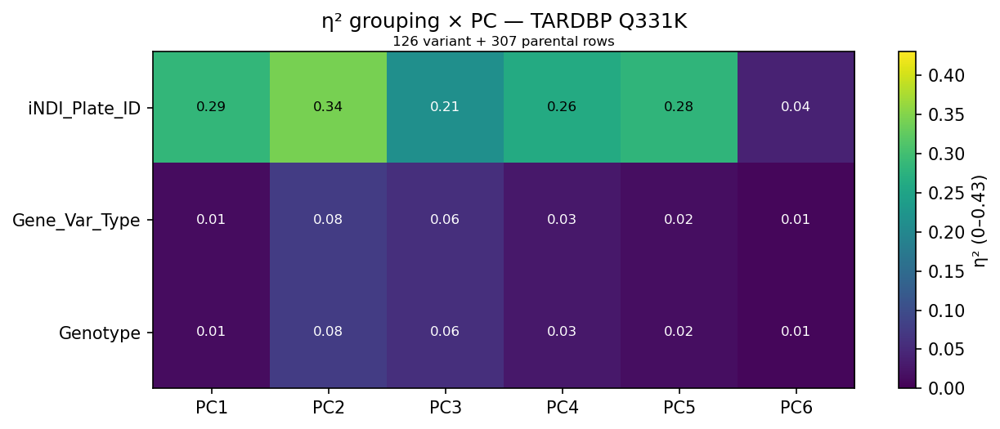

  TBK1 / E696K: 126 variant + 307 parental rows


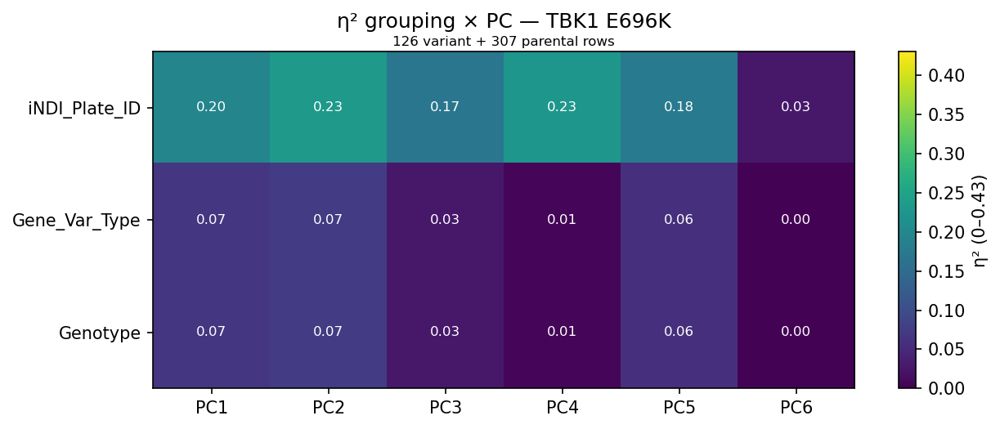

  UBQLN2 / P506T: 84 variant + 307 parental rows


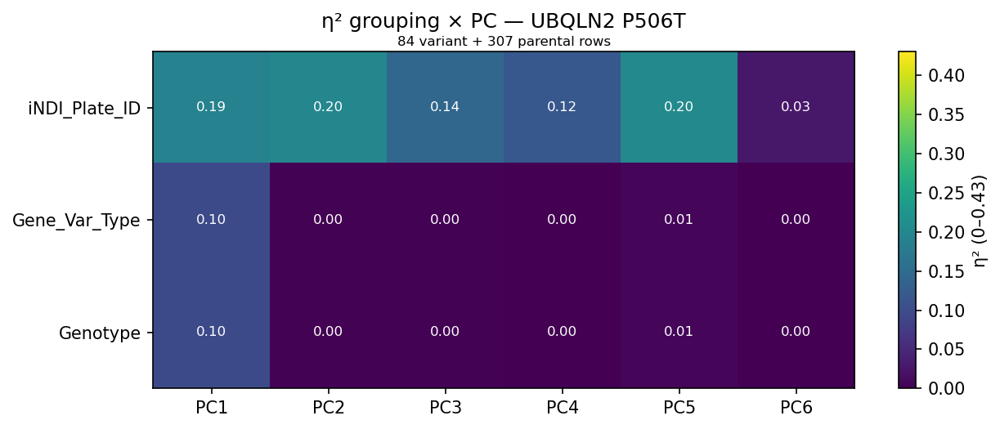

  VCP / R159H: 84 variant + 307 parental rows


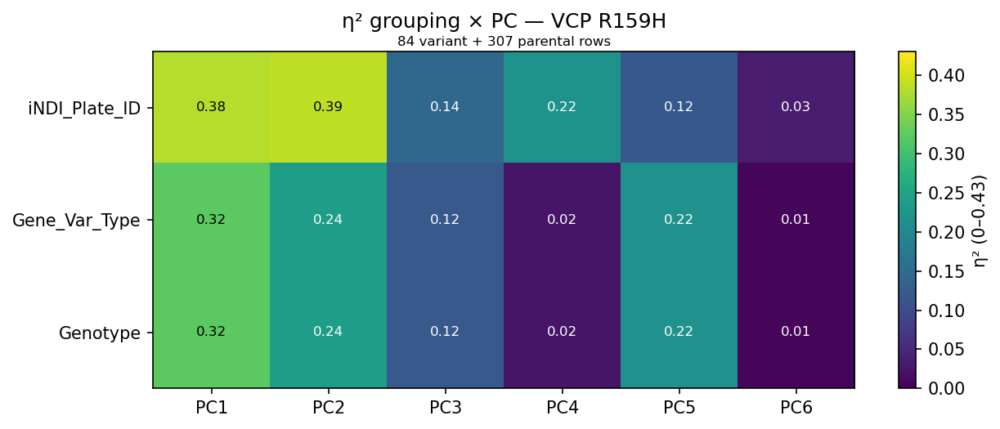

[facet] 18 (gene, variant) pairs; 307 total KOLF2.1J rows (plate-matched per facet)
  APOE / C112R: 42 variant + 42 parental rows on 1 plate(s)


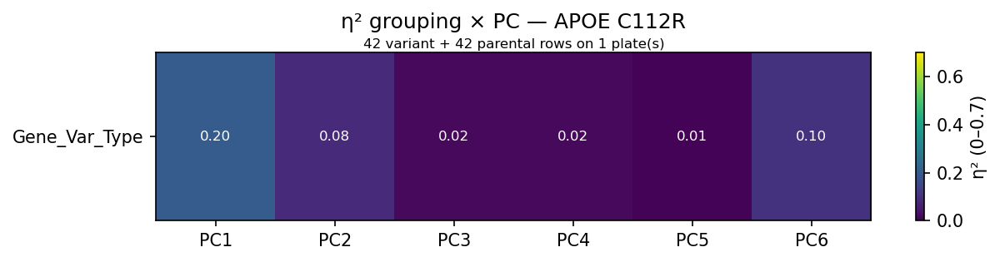

  APP / A673T: 56 variant + 56 parental rows on 1 plate(s)


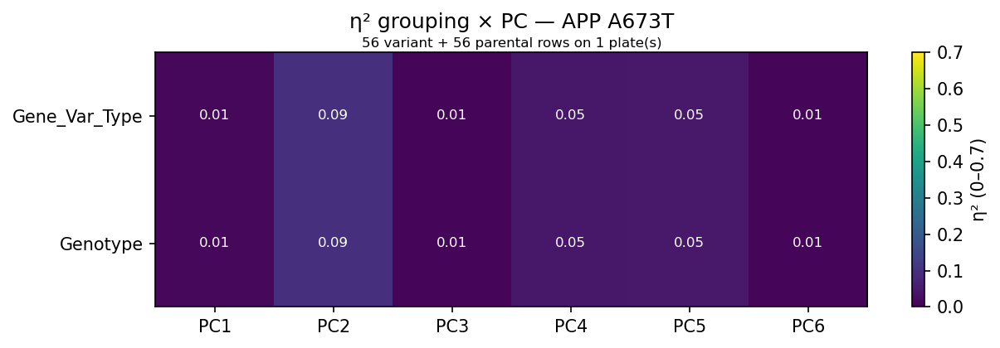

  APP / E693G: 84 variant + 42 parental rows on 1 plate(s)


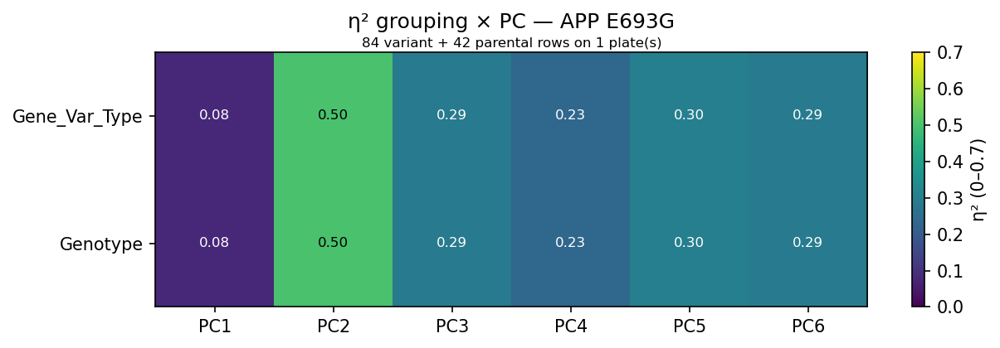

  FUS / R216C: 112 variant + 140 parental rows on 3 plate(s)


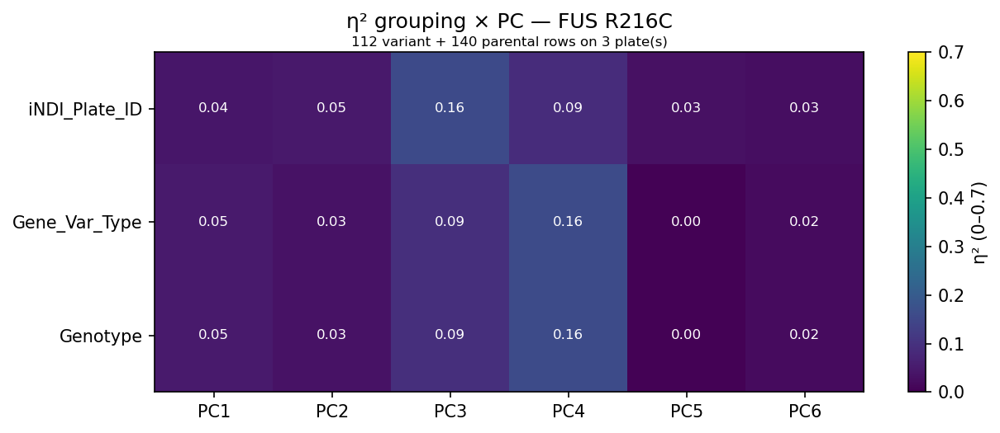

  FUS / R495X: 84 variant + 56 parental rows on 1 plate(s)


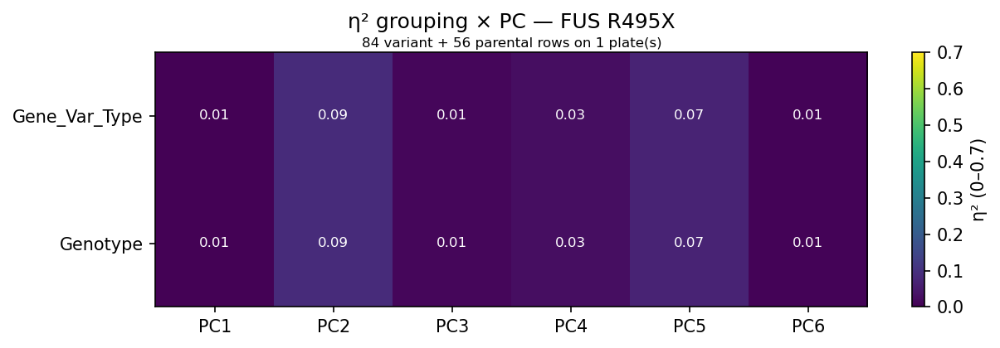

  GRN / Q125X: 126 variant + 84 parental rows on 2 plate(s)


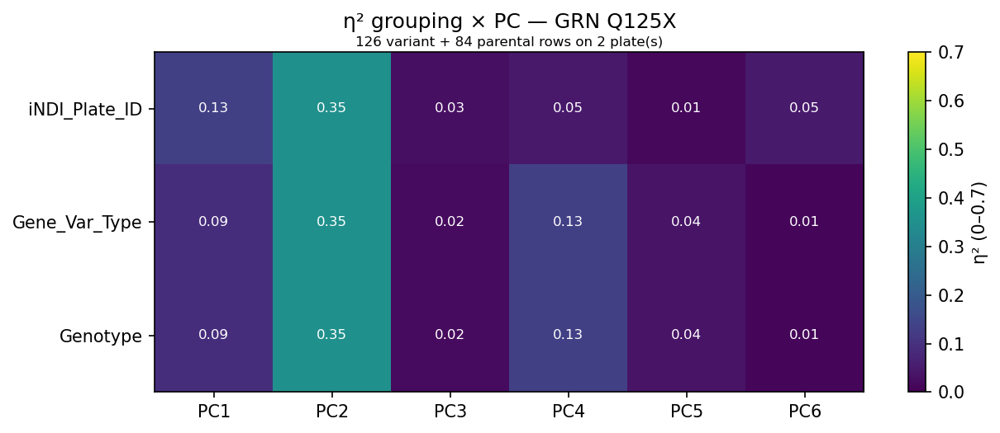

  HNRNPA1 / D262N: 126 variant + 14 parental rows on 1 plate(s)


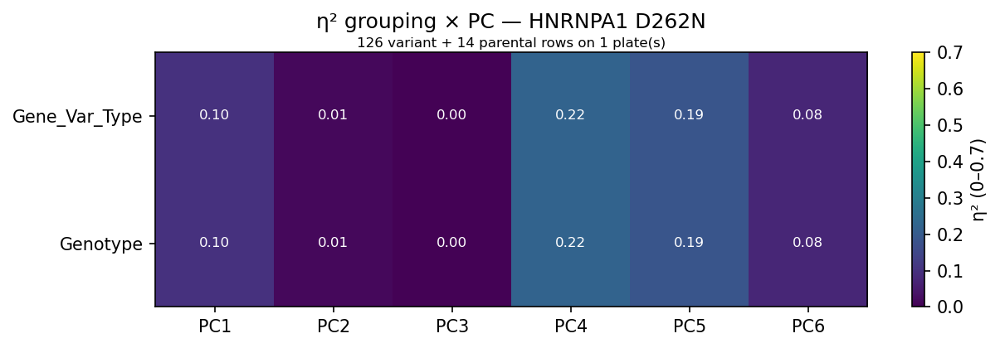

  MAPT / R406W: 112 variant + 83 parental rows on 2 plate(s)


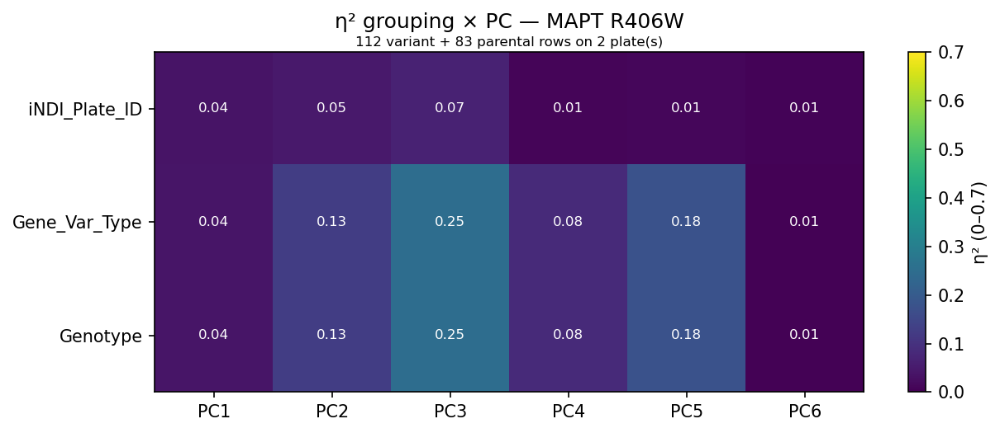

  PFN1 / C71G: 126 variant + 42 parental rows on 1 plate(s)


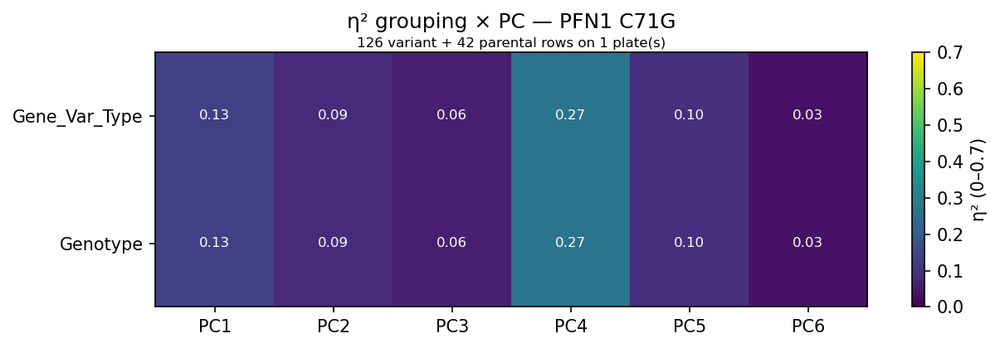

  PSEN2 / N141I: 126 variant + 14 parental rows on 1 plate(s)


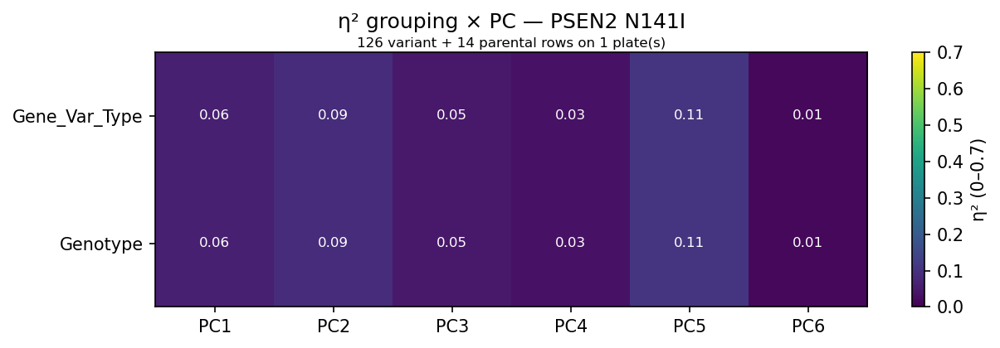

  SNCA / A53T: 126 variant + 42 parental rows on 1 plate(s)


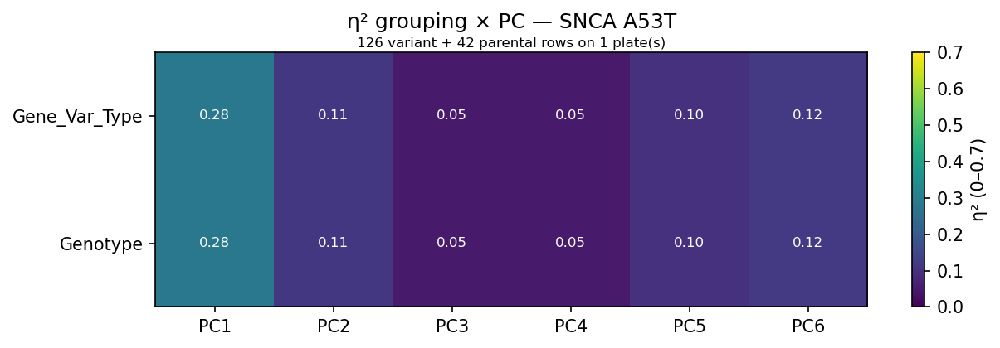

  SNCA / E46K: 98 variant + 27 parental rows on 1 plate(s)


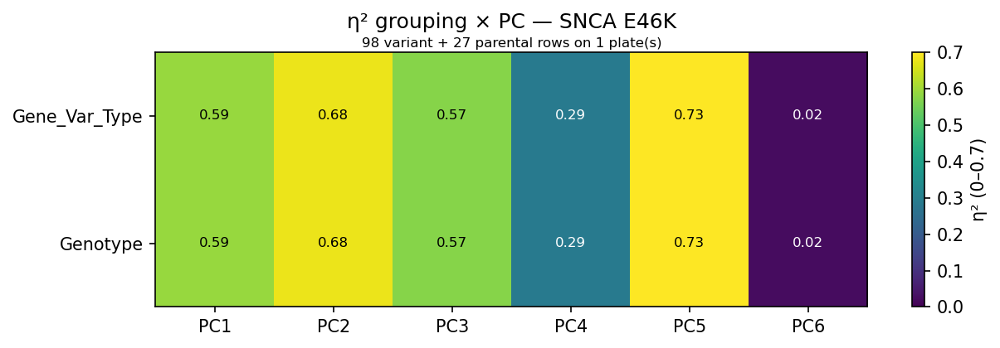

  SNCB / P123H: 126 variant + 42 parental rows on 1 plate(s)


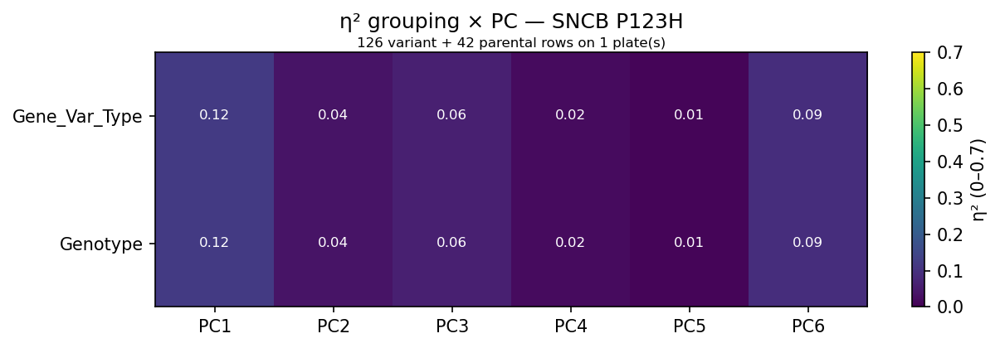

  TARDBP / M337V: 126 variant + 42 parental rows on 1 plate(s)


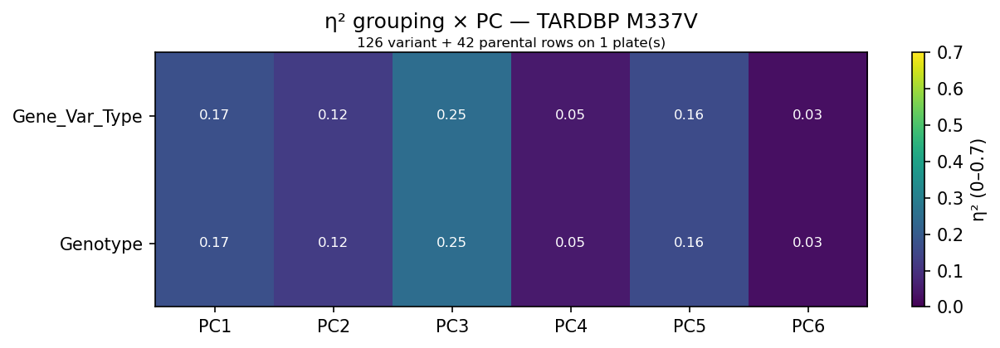

  TARDBP / Q331K: 126 variant + 126 parental rows on 3 plate(s)


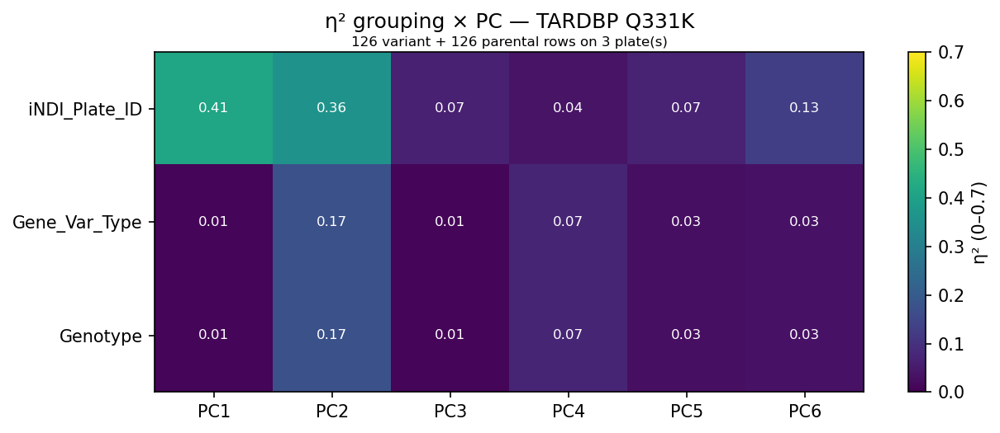

  TBK1 / E696K: 126 variant + 84 parental rows on 2 plate(s)


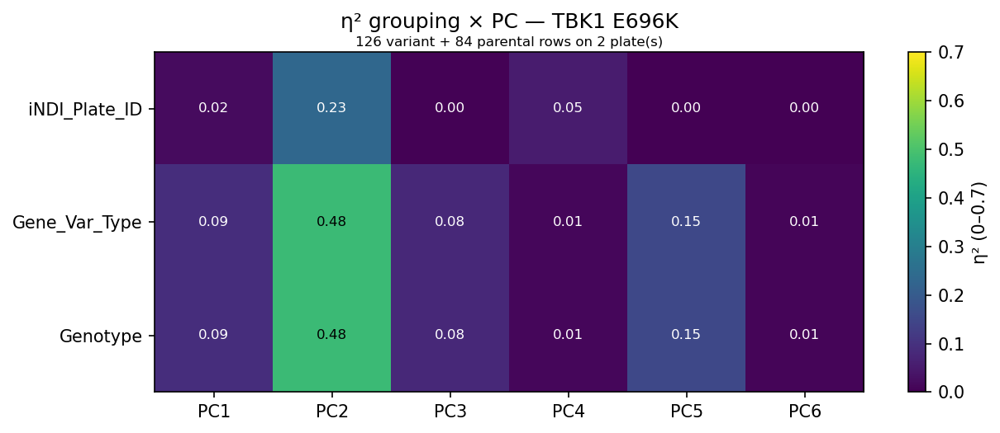

  UBQLN2 / P506T: 84 variant + 42 parental rows on 1 plate(s)


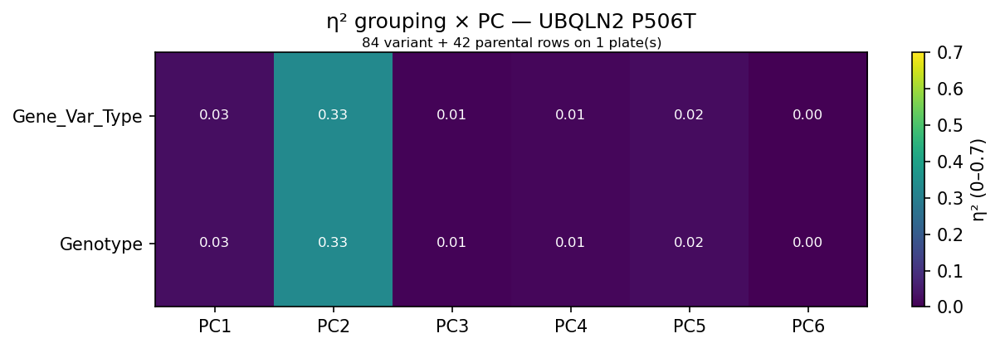

  VCP / R159H: 84 variant + 27 parental rows on 1 plate(s)


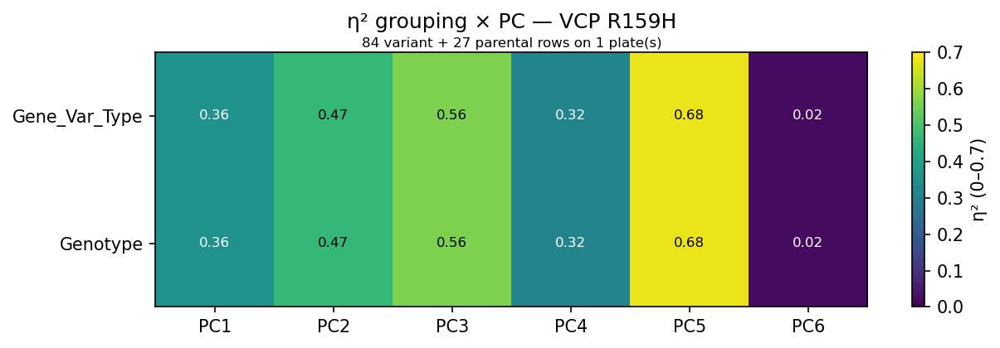

In [38]:
GROUP_COLS = ["Source", "iNDI_Plate_ID", "Batch", "Asp PosID", "Gene_Var_Type", "Variant", "Genotype"]

mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.43, plate_match=False)
mats = facet_by_gene_variant(well_level, GROUP_COLS, n_pcs=10, vmax=0.7, plate_match=True)

# Parental-only analysis

In [22]:
# filter for parentals
parental        = df[df["Gene_Var_Type"] == "KOLF2.1J"]
parental_auto   = df[(df["Gene_Var_Type"] == "KOLF2.1J") & (df["Source"] == "automated")]
parental_manual = df[(df["Gene_Var_Type"] == "KOLF2.1J") & (df["Source"] == "manual")]

## ROI level analysis
### Feature assessment and PCA loadings


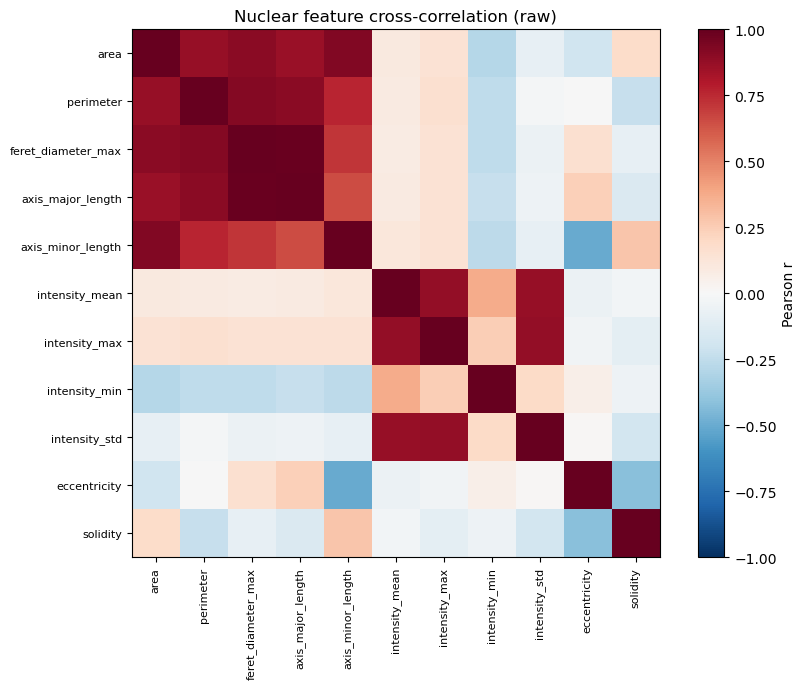

Highly correlated pairs (|r| > 0.9):
  +0.988  feret_diameter_max     axis_major_length
  +0.928  area                   axis_minor_length
  +0.918  perimeter              feret_diameter_max
  +0.902  area                   feret_diameter_max
[full] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full] dropped 0 rows with NaN/inf; 236480 remain
[full] EVR: [0.396 0.315 0.157 0.11  0.017 0.005]
[full] cumulative: [0.396 0.71  0.867 0.978 0.995 1.   ]


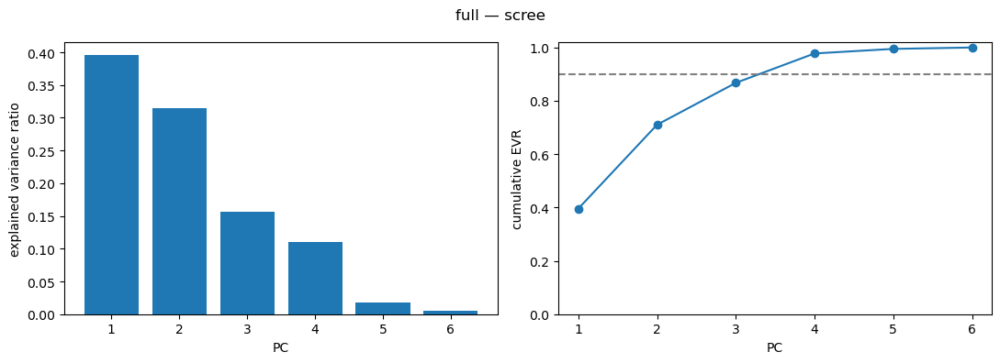

                  PC1    PC2    PC3    PC4    PC5    PC6
area            0.236  0.028  0.945 -0.189  0.124  0.013
intensity_mean  0.003  0.701  0.099  0.148 -0.691 -0.006
intensity_std  -0.089  0.699 -0.084  0.031  0.704  0.008
eccentricity   -0.602 -0.082  0.208  0.326  0.008  0.693
solidity        0.444 -0.087  0.054  0.881  0.111 -0.057
aspect_ratio    0.614  0.070 -0.211 -0.241 -0.015  0.718


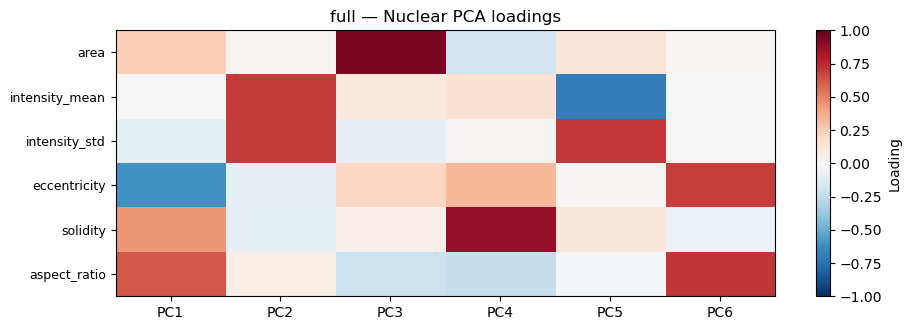

In [23]:
feature_correlation(parental)
parental, pca, FEATURES = fit_pca(parental, label="full")

### PCA plots
#### All parentals


All 21 iNDI_Plate_ID values have a color.


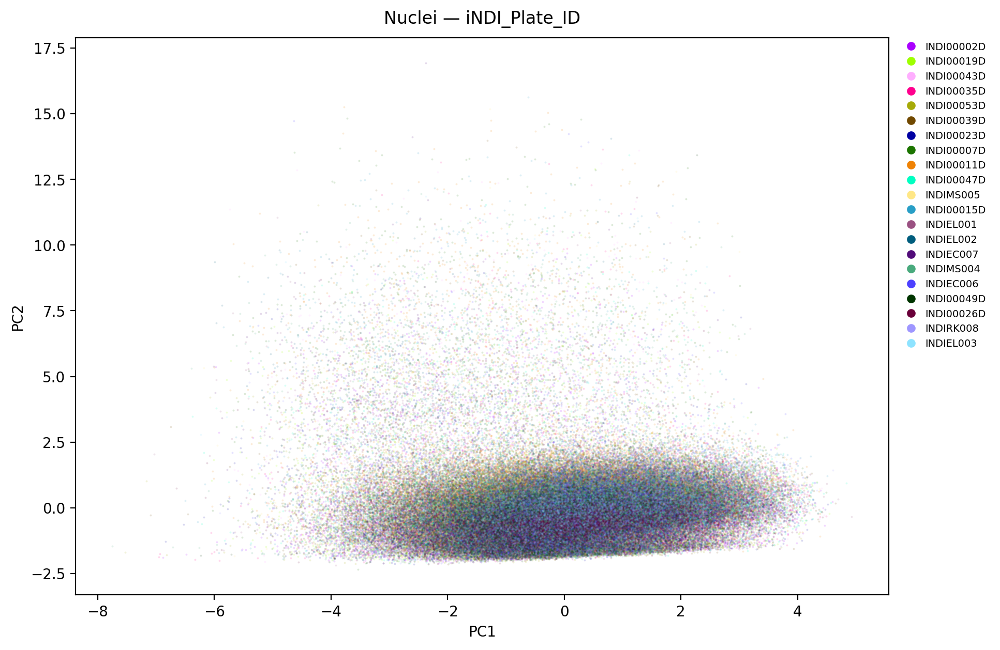

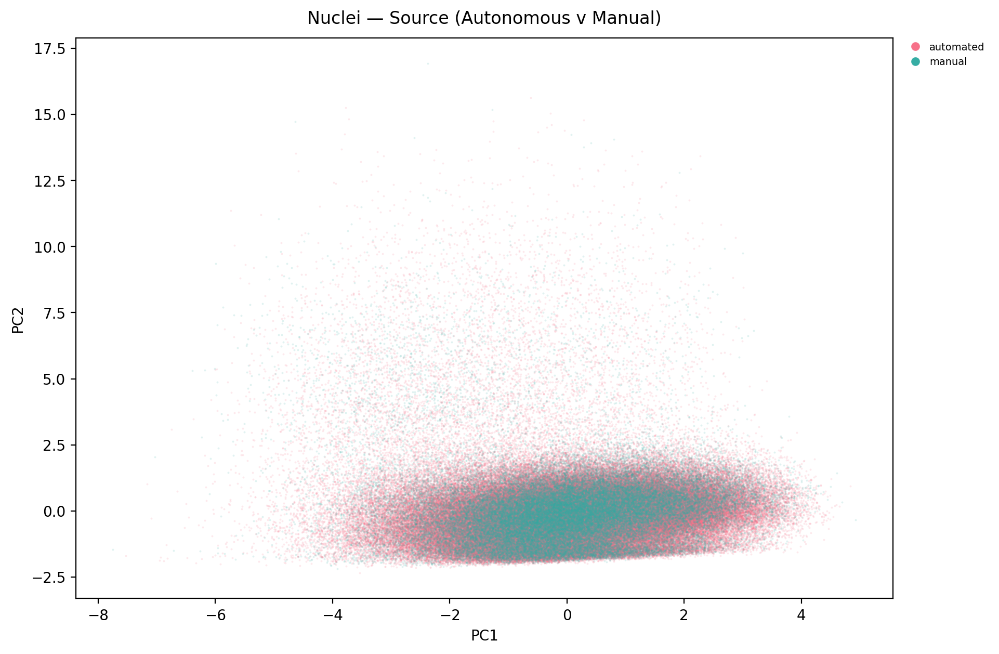

All 5 Batch values have a color.


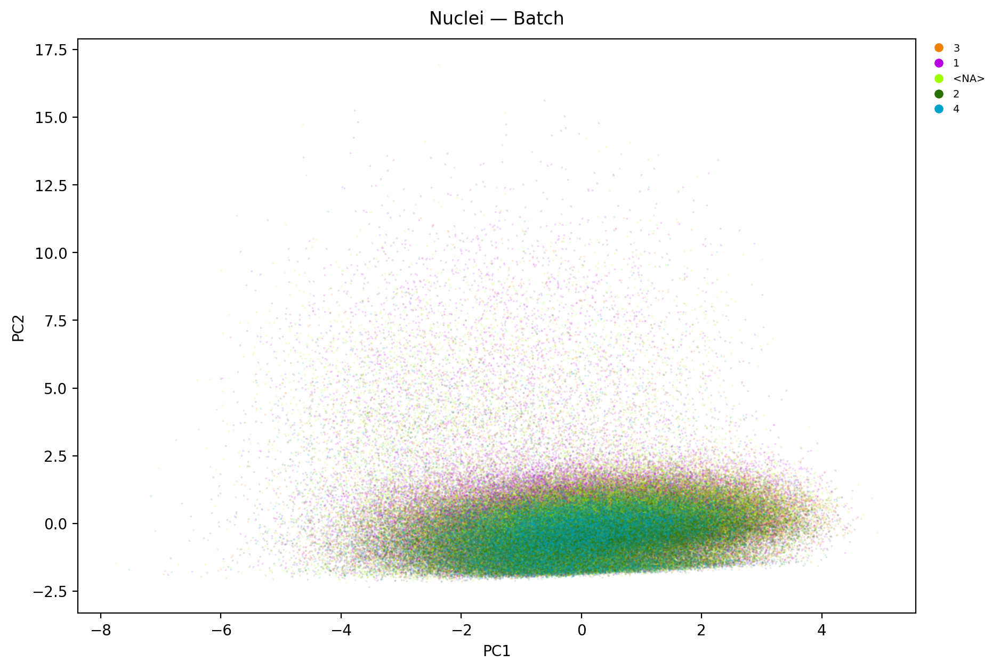

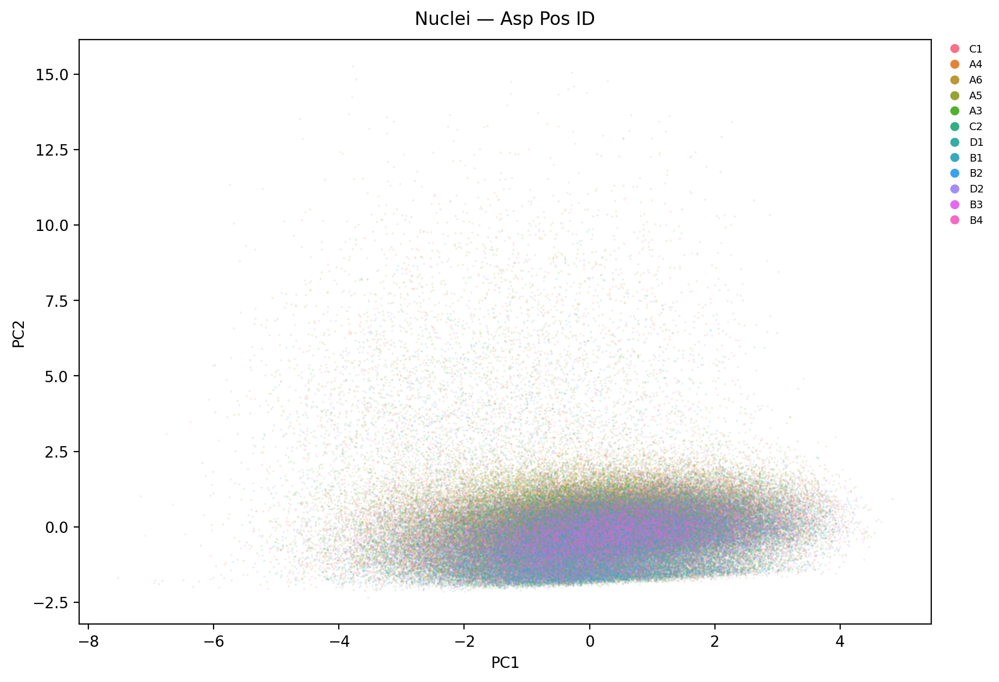

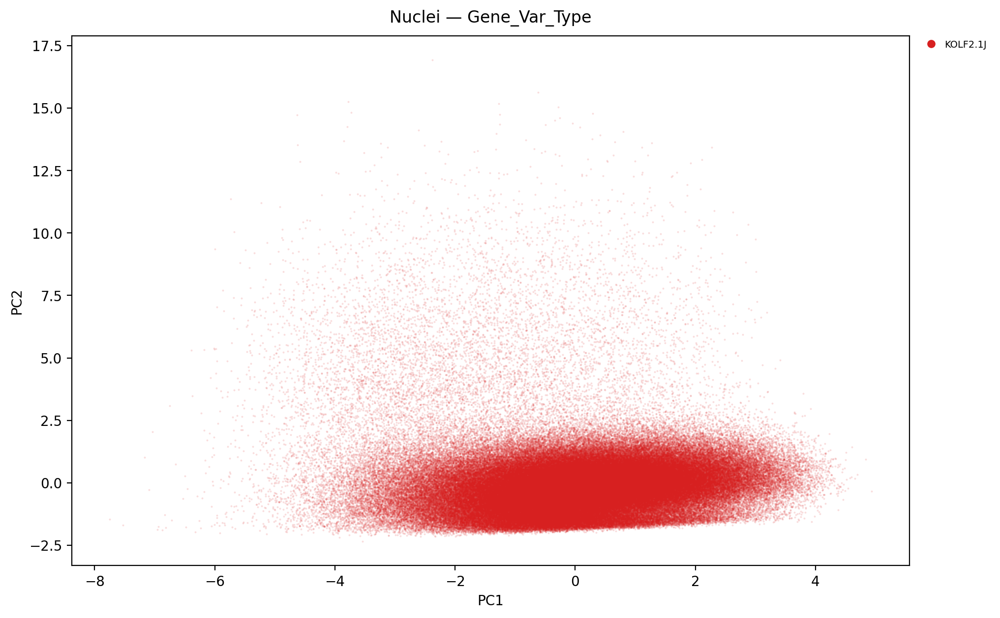

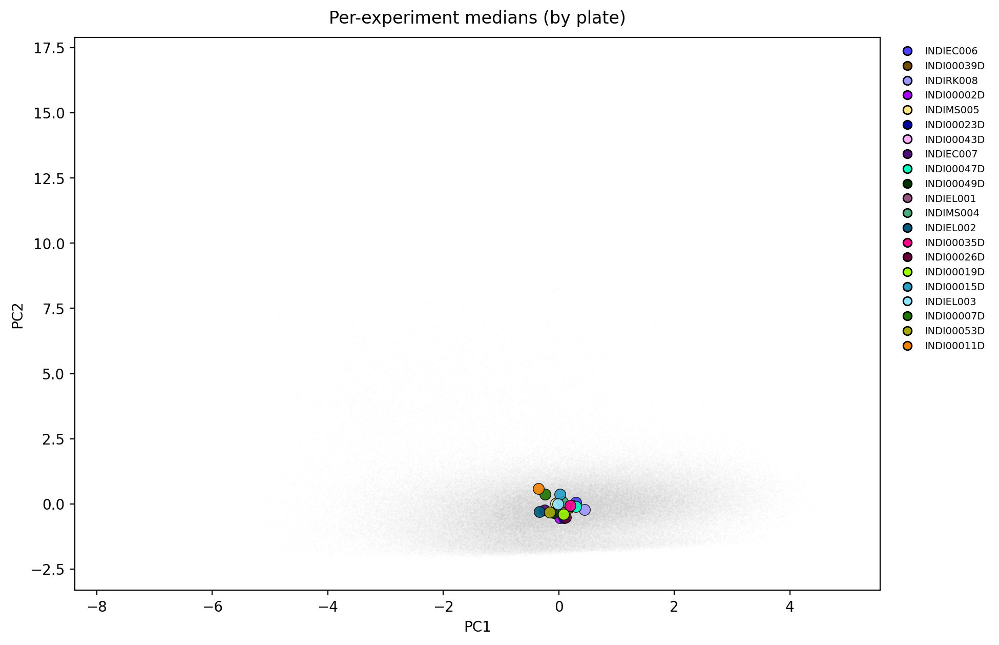

Std of per-experiment centroids (batch magnitude):
PC1    0.212
PC2    0.299
PC3    0.217
dtype: float64


In [24]:
plate_pal = make_palette(parental["iNDI_Plate_ID"])
check_palette_coverage(parental, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID")

pca_scatter(parental, "Source", figsize=(12, 7),title="Nuclei — Source (Autonomous v Manual)")

batch_palette = make_palette(parental["Batch"])
check_palette_coverage(parental, "Batch", batch_palette)
pca_scatter(parental, "Batch", palette=batch_palette, figsize=(12, 7),title="Nuclei — Batch")

pca_scatter(parental, "Asp PosID", figsize=(12, 7),title="Nuclei — Asp Pos ID")

pca_scatter(parental, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Nuclei — Gene_Var_Type")

centroid_overlay(parental, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

#### Automated parentals

All 13 iNDI_Plate_ID values have a color.


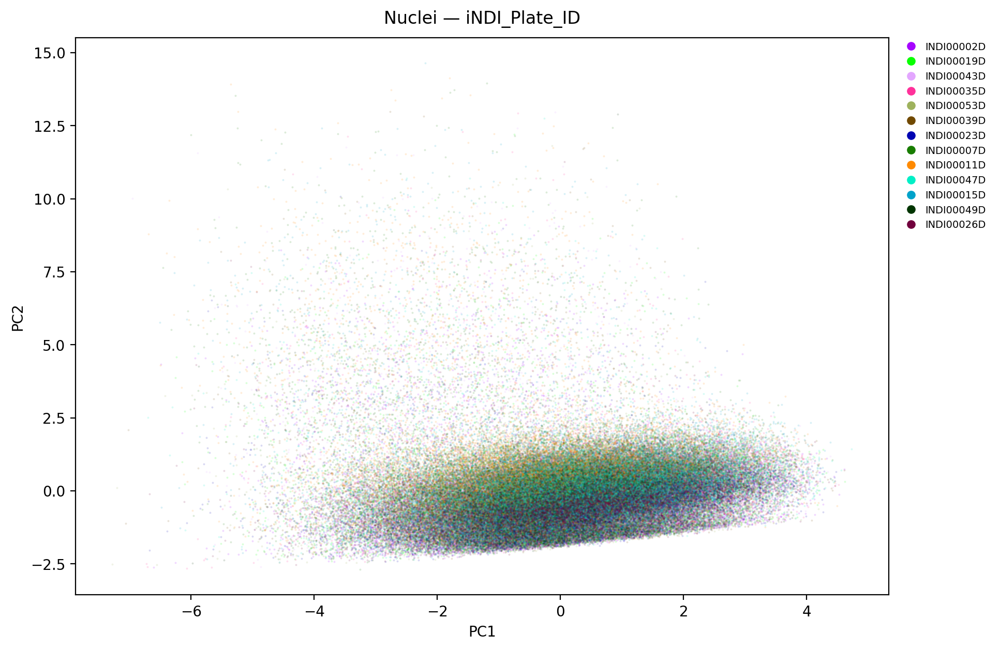

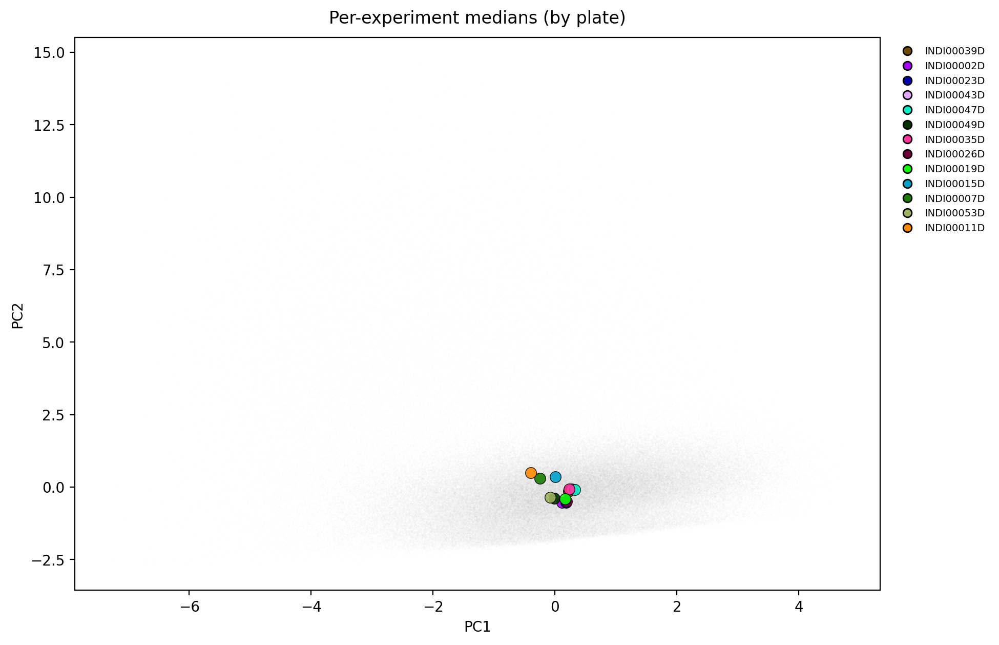

Std of per-experiment centroids (batch magnitude):
PC1    0.214
PC2    0.346
PC3    0.184
dtype: float64
All 4 Batch values have a color.


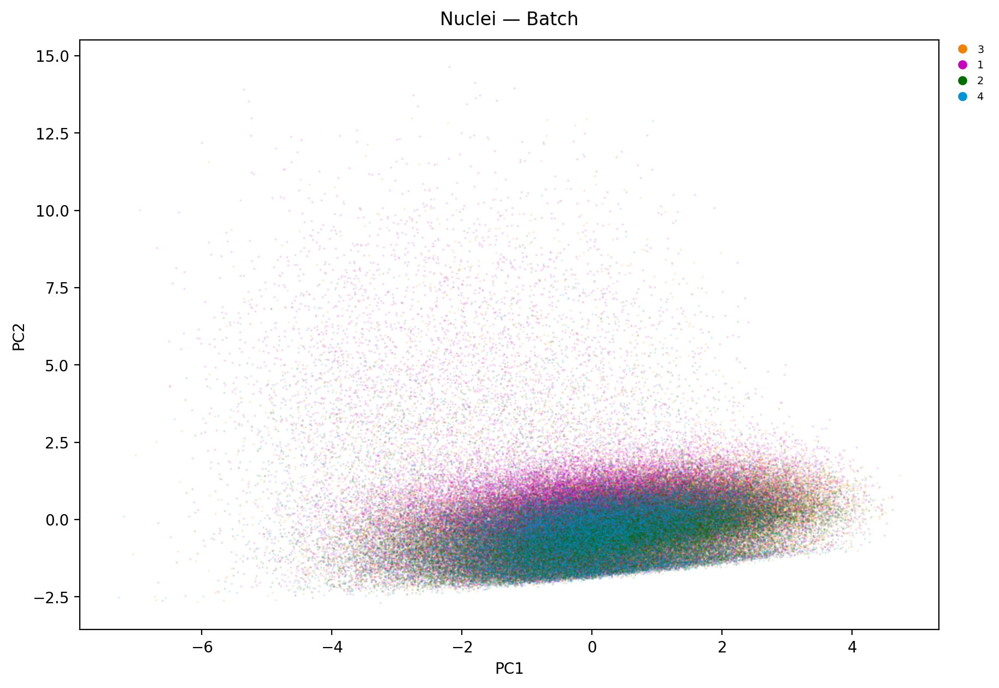

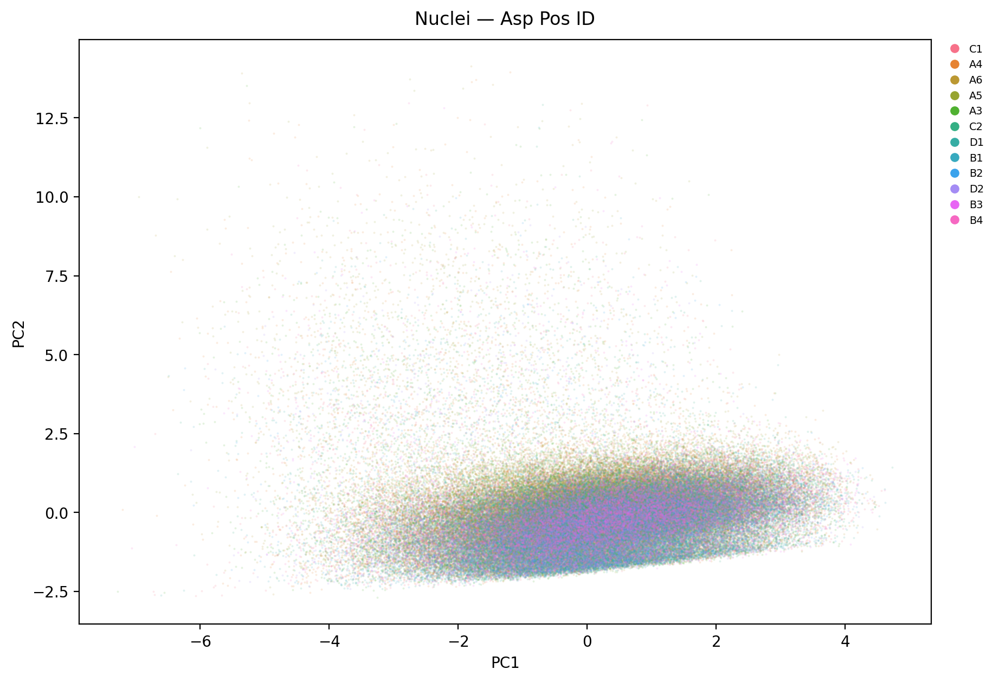

<Axes: title={'center': 'Nuclei — Asp Pos ID'}, xlabel='PC1', ylabel='PC2'>

In [25]:
plate_pal = make_palette(parental_auto["iNDI_Plate_ID"])
check_palette_coverage(parental_auto, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental_auto, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID")
centroid_overlay(parental_auto, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental_auto.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

batch_palette = make_palette(parental_auto["Batch"])
check_palette_coverage(parental_auto, "Batch", batch_palette)
pca_scatter(parental_auto, "Batch", palette=batch_palette, figsize=(12, 7),title="Nuclei — Batch")

pca_scatter(parental_auto, "Asp PosID", figsize=(12, 7),title="Nuclei — Asp Pos ID")

#### Manual parentals

All 8 iNDI_Plate_ID values have a color.


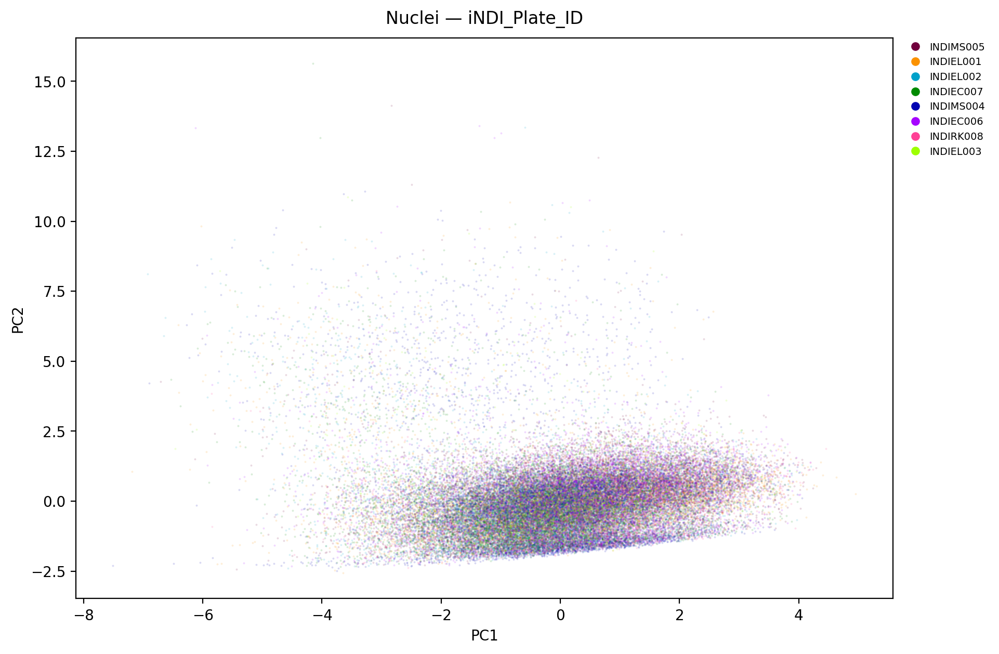

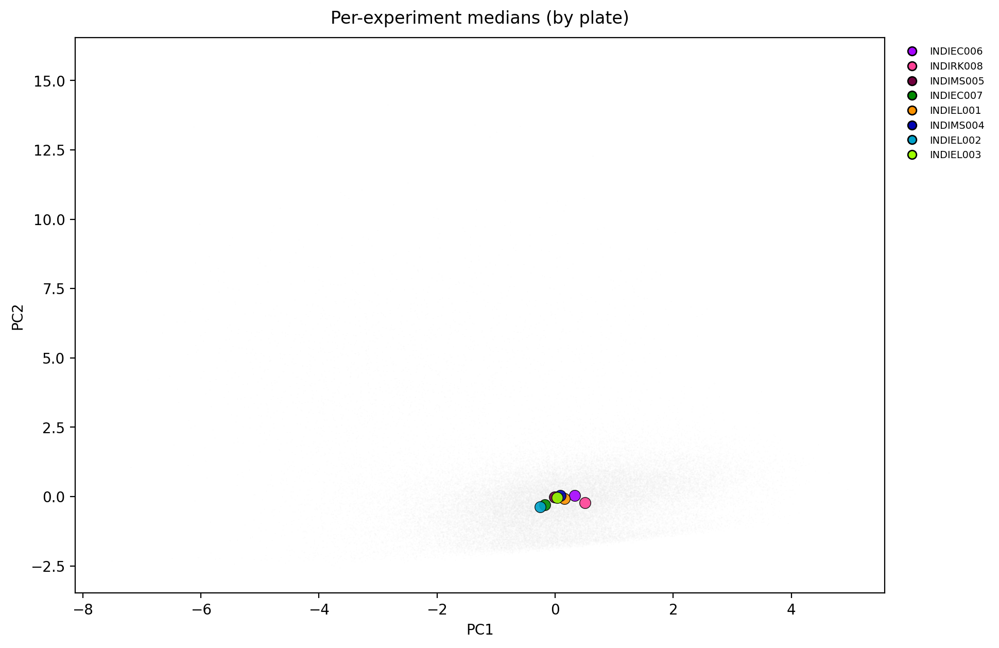

Std of per-experiment centroids (batch magnitude):
PC1    0.248
PC2    0.157
PC3    0.284
dtype: float64
All 1 Batch values have a color.


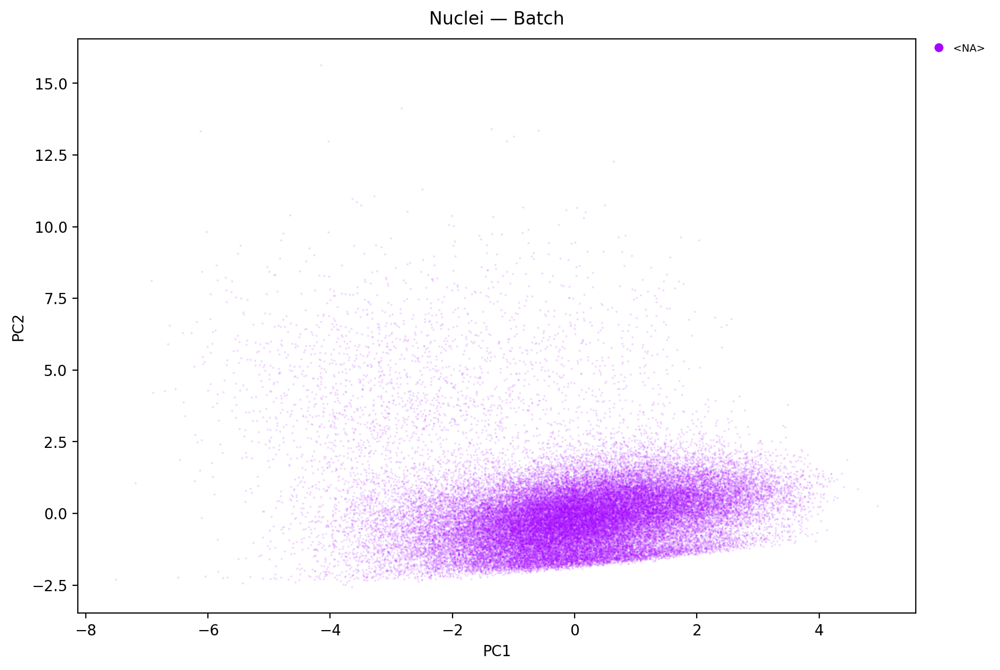

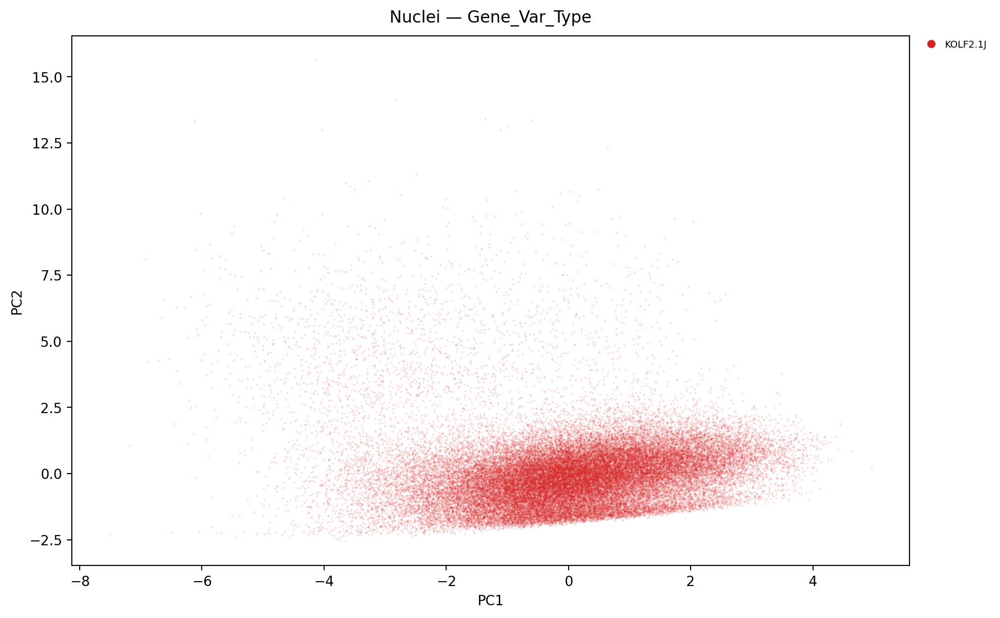

<Axes: title={'center': 'Nuclei — Gene_Var_Type'}, xlabel='PC1', ylabel='PC2'>

In [26]:
plate_pal = make_palette(parental_manual["iNDI_Plate_ID"])
check_palette_coverage(parental_manual, "iNDI_Plate_ID", plate_pal)
pca_scatter(parental_manual, "iNDI_Plate_ID", palette=plate_pal, figsize=(12, 7), title="Nuclei — iNDI_Plate_ID")
centroid_overlay(parental_manual, "iNDI_Plate_ID", ["Measurement_ID"], palette=plate_pal, 
                 figsize=(12, 7), title="Per-experiment medians (by plate)")
cent = parental_manual.groupby("Measurement_ID")[["PC1", "PC2", "PC3"]].median()
print("Std of per-experiment centroids (batch magnitude):")
print(cent.std().round(3))

batch_palette = make_palette(parental_manual["Batch"])
check_palette_coverage(parental_manual, "Batch", batch_palette)
pca_scatter(parental_manual, "Batch", palette=batch_palette, figsize=(12, 7),title="Nuclei — Batch")

pca_scatter(parental_manual, "Gene_Var_Type", figsize=(13, 7), legend_ncol=2, title="Nuclei — Gene_Var_Type")

## Well-level aggregation
### PCA plots

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 47184 rows (13045 images)
[full] well-level: 1449 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 1449 remain
[full well] EVR: [0.444 0.293 0.142 0.088 0.03  0.003]
[full well] cumulative: [0.444 0.737 0.879 0.967 0.997 1.   ]


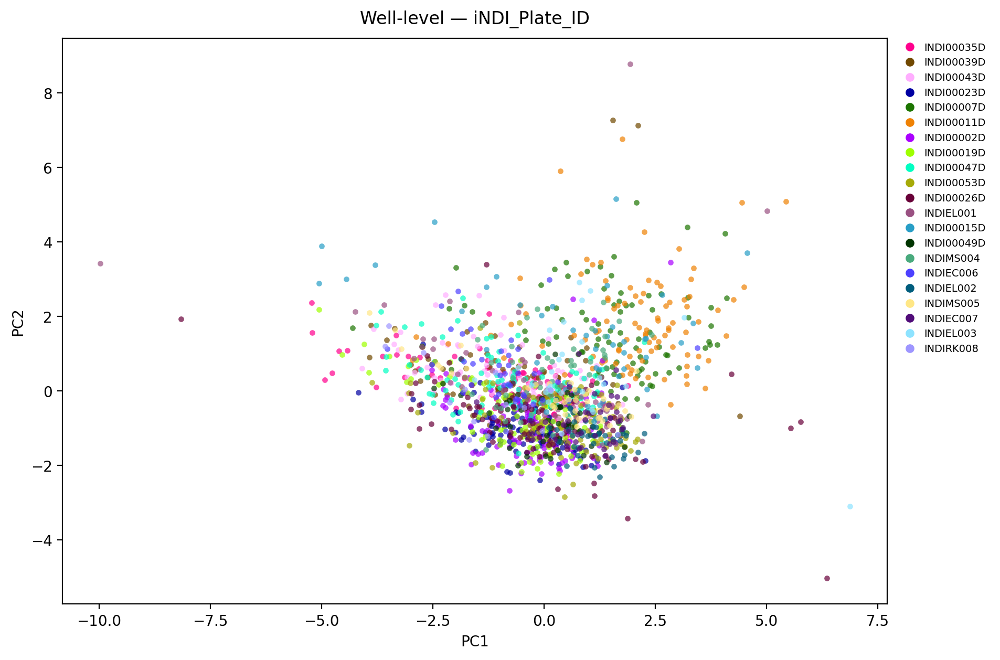

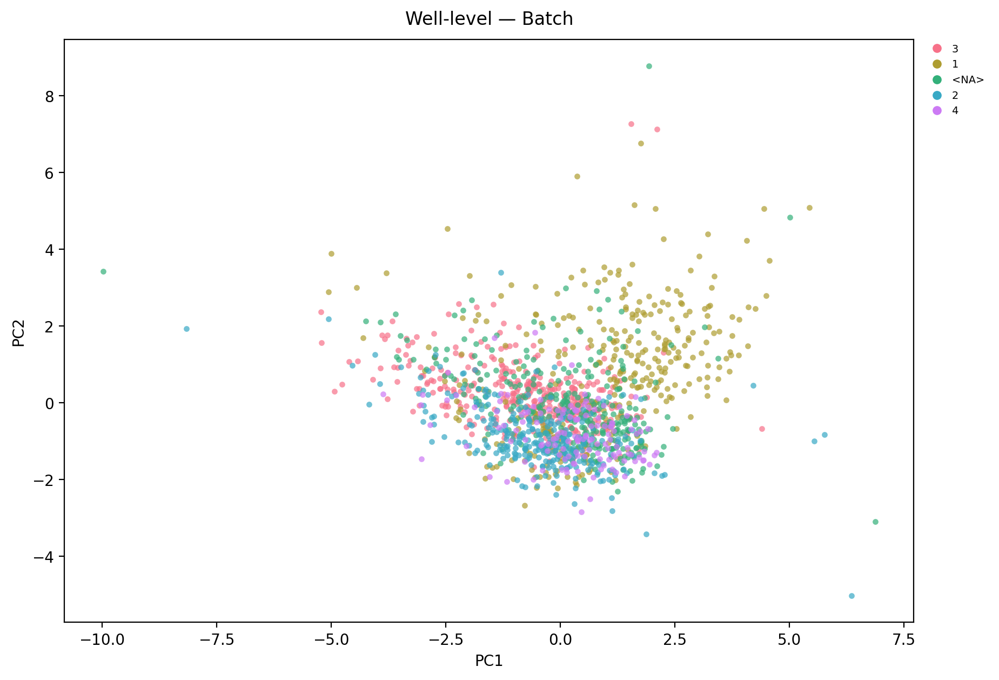

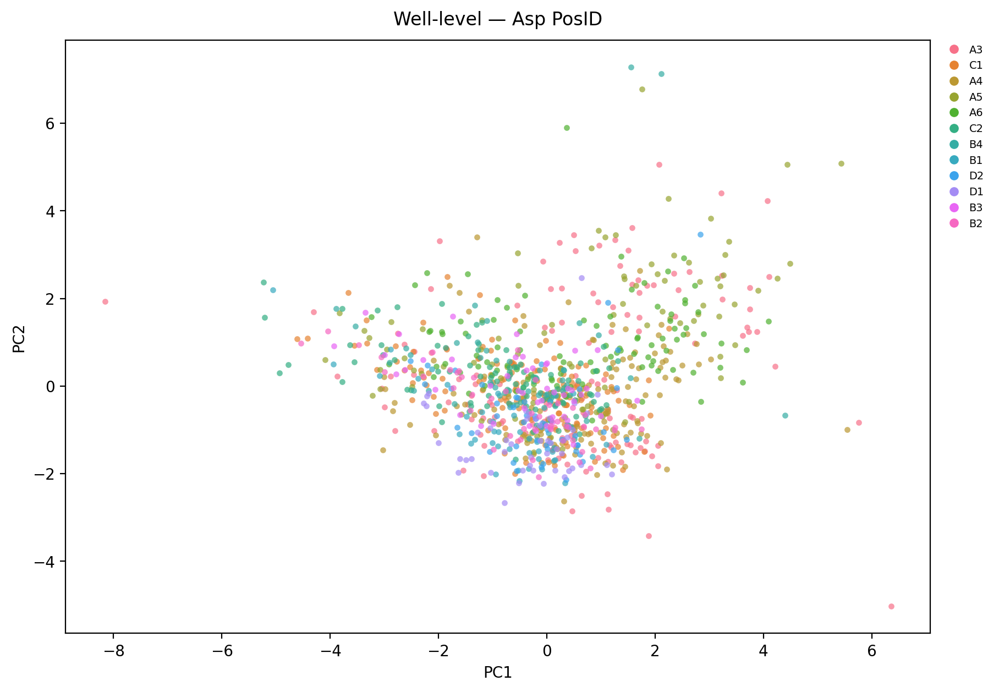

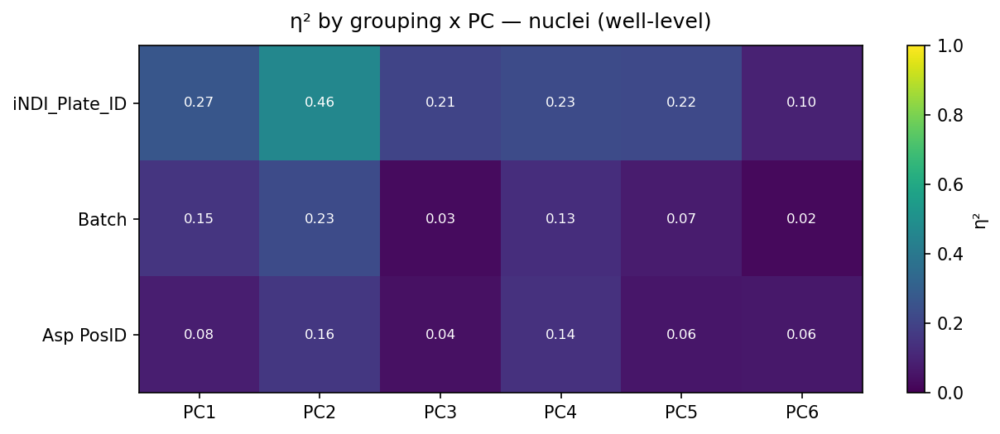

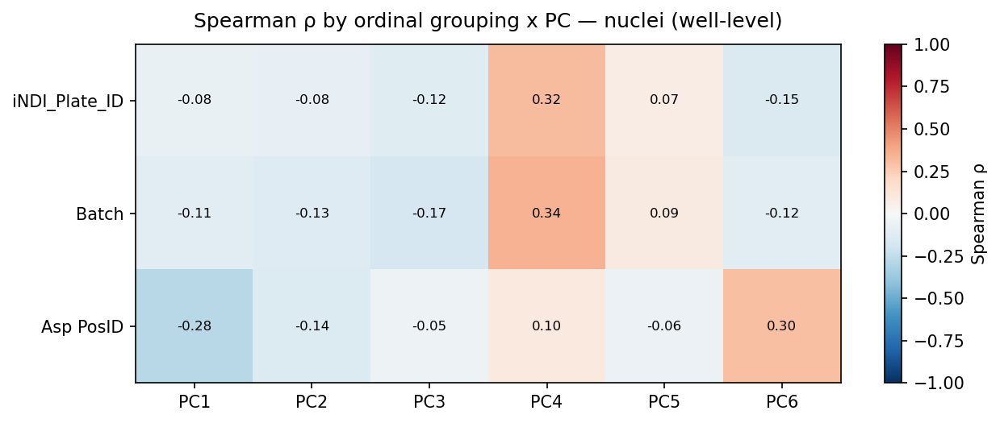

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,-0.077393,-0.083636,-0.120284,0.315973,0.073475,-0.147050
Batch,-0.105226,-0.126278,-0.170593,0.344622,0.091410,-0.115565
Asp PosID,-0.280954,-0.135560,-0.053875,0.097547,-0.057541,0.298961


In [27]:
well_level = aggregate_wells(parental, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 36999 rows (12893 images)
[full] well-level: 1142 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 1142 remain
[full well] EVR: [0.454 0.288 0.157 0.073 0.024 0.003]
[full well] cumulative: [0.454 0.742 0.899 0.973 0.997 1.   ]


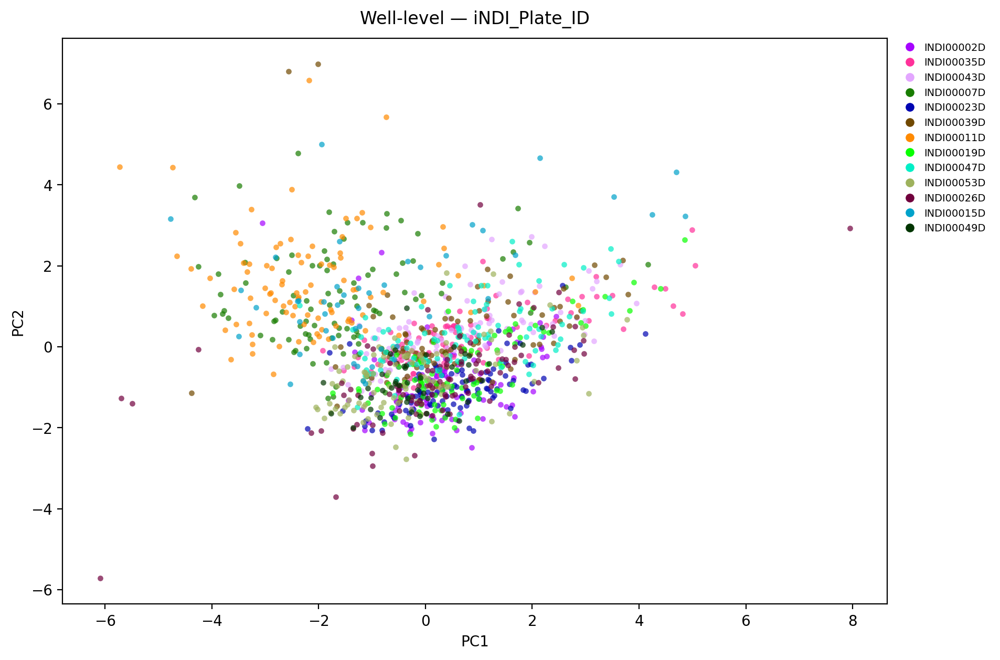

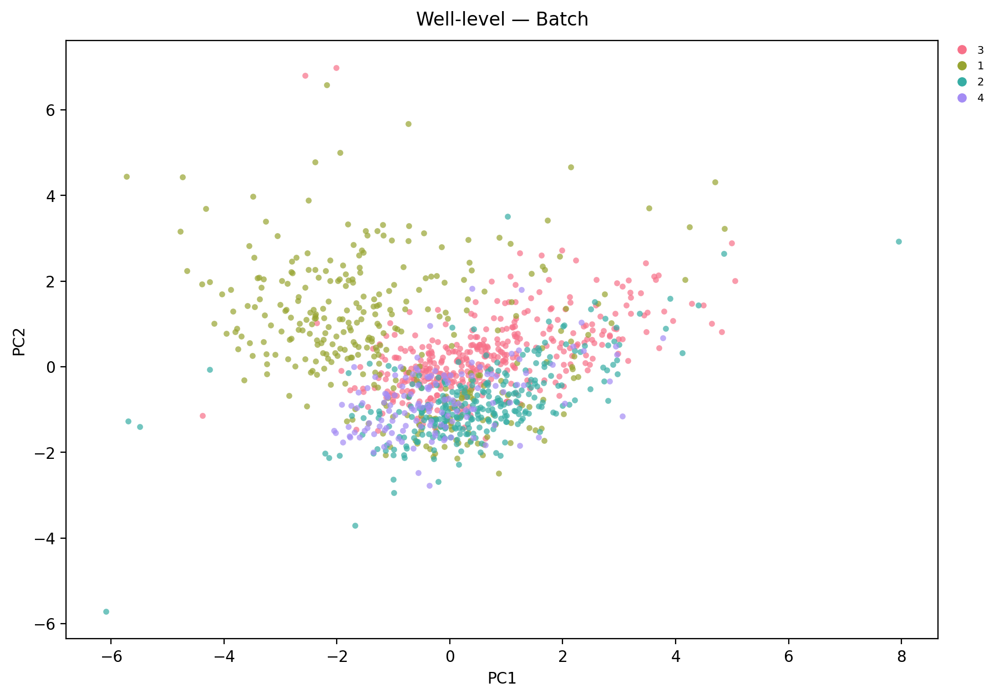

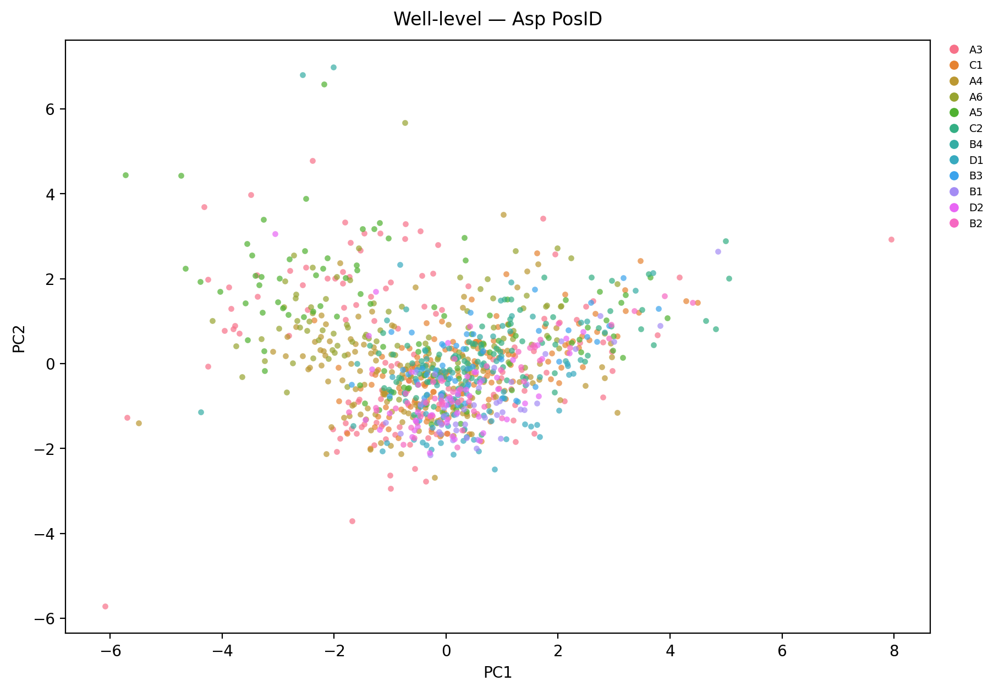

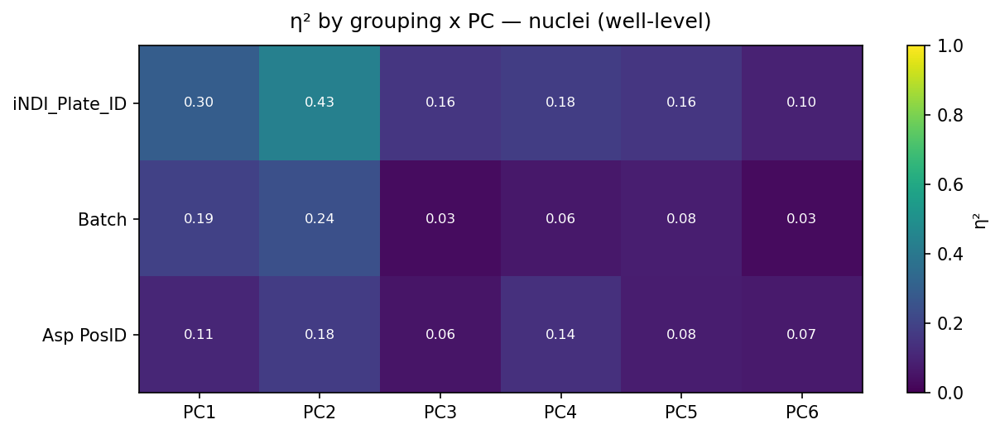

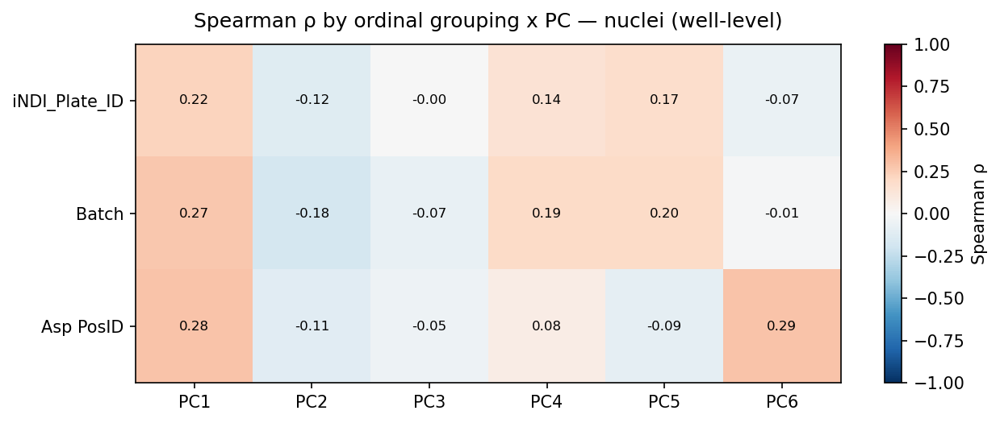

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.224212,-0.117380,-0.001344,0.143008,0.173516,-0.068187
Batch,0.268586,-0.179480,-0.074580,0.188092,0.195271,-0.013464
Asp PosID,0.283075,-0.112942,-0.049120,0.076386,-0.086579,0.288868


In [28]:
well_level = aggregate_wells(parental_auto, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")
pca_scatter(well_shuf, "Batch", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Batch")
pca_scatter(well_shuf, "Asp PosID", s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — Asp PosID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID", "Batch", "Asp PosID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

[full] Genotype_Name: 0 well(s) with >1 value
[full] iNDI_Plate_ID: 0 well(s) with >1 value
[full] image-level: 10185 rows (3748 images)
[full] well-level: 307 rows
[full well] using FEATURES: ['area', 'intensity_mean', 'intensity_std', 'eccentricity', 'solidity', 'aspect_ratio']
[full well] dropped 0 rows with NaN/inf; 307 remain
[full well] EVR: [0.442 0.282 0.139 0.085 0.048 0.003]
[full well] cumulative: [0.442 0.724 0.863 0.948 0.997 1.   ]


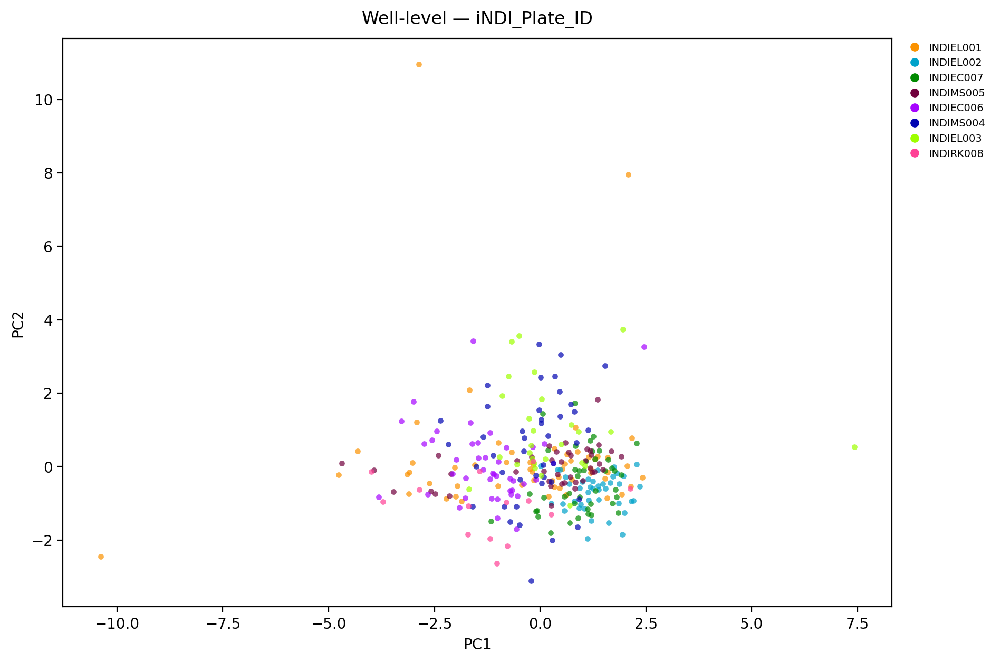

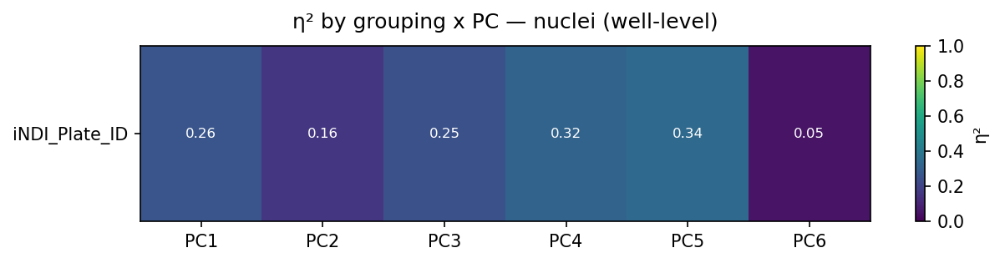

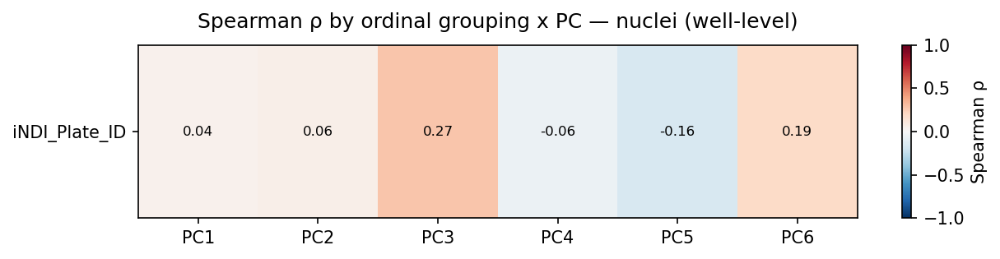

,PC1,PC2,PC3,PC4,PC5,PC6
iNDI_Plate_ID,0.040813,0.058293,0.273825,-0.056848,-0.16126,0.193849


In [29]:
well_level = aggregate_wells(parental_manual, FEATURES, label="full")
well_level, pca_well, _ = fit_pca(
    well_level, features=FEATURES, add_aspect_ratio=False,
    show_scree=False, show_loadings=False, label="full well",
)

well_shuf = well_level.sample(frac=1, random_state=0).reset_index(drop=True)
plate_pal = make_palette(well_shuf["iNDI_Plate_ID"])
pca_scatter(well_shuf, "iNDI_Plate_ID", palette=plate_pal, s=15, alpha=0.7,
            figsize=(12, 7), title="Well-level — iNDI_Plate_ID")

# well-level η² (does plate structure persist after aggregation?)
eta_heatmap(well_level, ["iNDI_Plate_ID"],
            n_pcs=6, title="η² by grouping x PC — nuclei (well-level)")

spearman_heatmap(well_level, ["iNDI_Plate_ID"], 
                 n_pcs=6, title="Spearman ρ by ordinal grouping x PC — nuclei (well-level)")

In [30]:
build_pptx("/data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_nucleus_analysis.pptx")

wrote 179 slides -> /data/kelpschdj/iNDI/Production/notebooks/analysis_uoe5/uoe5_nucleus_analysis.pptx
